# 05 · Proposed model and controlled development

The single primary predictor is the frozen temporal sensor-set backbone with its causal pattern residual head. The later hull and matched-sensor candidates did not meet their prespecified replacement criteria and are reported as negative experiments. Six matched-sensor fits completed; no failed candidate was taken to a new test.

**Ablation evidence.** The full model has lower development MAE and RMSE than all three completed removal or substitution controls: no recent-pattern inputs, frozen backbone alone, and a persistence-residual pipeline. The first two comparisons use the six-contrast Holm family; the last uses its separately prespecified two-contrast family. These exploratory results support the tested component bundles, not the necessity of every internal layer.

The backbone-only control removes longer-history inputs, the residual learner and final nonnegative clipping together. The persistence control matches the residual-head budget, not total pipeline parameters. Separate internal-component and probabilistic ablation benefits remain unproven.

**Initial backbone.** The initial temporal backbone had development MAE 0.120779 kW versus ExtraTrees 0.115849 kW; it was less accurate than ExtraTrees. The original acquisition and covariance results describe that joint-state model, not the later scalar correction.

## Frozen backbone: known Gaussian updates and causal sensor encoding

For measured powers and a latent remainder, the backbone predicts $z\mid x\sim\mathcal N(\mu,\Sigma)$ with positive diagonal plus low-rank covariance. Let $a^Tz=0$ represent aggregate minus monitored loads minus remainder. A noisy balance observation of variance $\tau^2$ gives
$$\mu_b=\mu-\Sigma a(a^T\Sigma a+\tau^2)^{-1}a^T\mu,\qquad
\Sigma_b=\Sigma-\Sigma a(a^T\Sigma a+\tau^2)^{-1}a^T\Sigma.$$
For observed coordinates $O$, exact conditioning uses the Cholesky-solved system $\Sigma_{OO}$:
$$\mu_{\mid O}=\mu+\Sigma_{:O}\Sigma_{OO}^{-1}(y_O-\mu_O),\qquad
\Sigma_{\mid O}=\Sigma-\Sigma_{:O}\Sigma_{OO}^{-1}\Sigma_{O:}.$$
These are established Gaussian identities, not the new contribution. Inactive/missing coordinates are masked; observed values are preserved. Soft balance permits incomplete or inconsistent sensor totals; the remainder is not constrained to be nonnegative. Device transfer and float64 factorization are explicit in the code below.

Shared causal depthwise convolutions encode each channel's permitted history. Sensor semantic embeddings, a permutation-equivariant set encoder and observable-context FiLM supply the joint state. The spectral branch and alternate component controls remain visible in the retained implementation; the selected backbone is temporal. Current auxiliary observations enter conditioning, and hidden current aggregate labels never enter the input path. The later scalar residual head uses nonnegative projection and does not inherit joint-Gaussian acquisition guarantees.


In [1]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"05_complete_components"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"component_auxiliary"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))

import time,math,copy,random,threading,psutil,torch,yaml,ast
import torch.nn as nn
import torch.nn.functional as F
from types import SimpleNamespace
from scipy.special import ndtr
torch.set_num_threads(4)
OLD_RUN="guldana_n3_20261007_v01";RUN=V2_RUN
DEVICE=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
schema=json.loads((ROOT/"Configs/sensor_schema.json").read_text());N_TYPES=len(schema["power_types"])
PREP=ROOT/"Models/preprocessing"/OLD_RUN
CACHE=ROOT/"Data/Processed"/OLD_RUN/"modeling_inputs"
NEURAL_CACHE=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"
REFINED=ROOT/"Data/Interim/development_minutes_refined"
PROPOSED_DIR=ROOT/"Models/proposed"/RUN
PROPOSED_PRED_DIR=ROOT/"Predictions/development_proposed"/RUN
for d in [PROPOSED_DIR,PROPOSED_PRED_DIR]:d.mkdir(parents=True,exist_ok=True)
INPUT_CONTRACT="masked_sensor_v1_exact_fixtures"
compute_protocol=yaml.safe_load((ROOT/"Configs/compute_protocol.yaml").read_text())
NB02_GATE=json.loads((ROOT/"Manifests/nb02_gate.json").read_text())
preprocessors={};duplicate_maps={}
for fold in [1,2,3]:
    state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())
    assert v2_sha(PREP/f"fold_{fold}_preprocessing.json")==V2_OLD_LOCK["files"][str((PREP/f"fold_{fold}_preprocessing.json").relative_to(ROOT))]
    preprocessors[fold]=SimpleNamespace(state=state)
    duplicate_maps[fold]={int(h):m for h,m in state["duplicate_maps"].items()}
PROPOSED_PROTOCOL_HASH=v2_sha(ROOT/"Configs/article_components_20261011.json")
COMPONENT_RETENTION_HASH=v2_sha(ROOT/"Configs/proposed_component_retention.json")
TABLES=V2_TABLES;table=v2_table
COMPONENT_PROTOCOL=json.loads((ROOT/"Configs/article_components_20261011.json").read_text())
def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()


def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.backends.mps.is_available():torch.mps.manual_seed(seed)


def synchronize(device=DEVICE):
    if str(device)=="mps":torch.mps.synchronize()


def masked_mean(values,mask):
    mask=mask.to(values.dtype)
    return (values*mask).sum()/mask.sum().clamp_min(1)


def regression_summary(metadata,prediction):
    error=prediction-metadata.y_kW.to_numpy(dtype=np.float64)
    per_house=pd.DataFrame({"house":metadata.house,"absolute":np.abs(error),"squared":error**2,
                           "bias":error,"negative":prediction<0}).groupby("house").mean()
    return {"House-macro MAE (kW)":float(per_house.absolute.mean()),
        "House-macro RMSE (kW)":float(np.sqrt(per_house.squared).mean()),
        "Bias (kW)":float(per_house.bias.mean()),"Negative prediction (%)":float(per_house.negative.mean()*100)}



In [8]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


In [2]:
VERIFIED_NEURAL_CACHES=set()
class NeuralInputCache:
    def __init__(self,fold,seed):
        self.measurement_contract="Plegma_measured_active_power"
        self.fold=fold;self.seed=seed;self.folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
        self.record=json.loads((self.folder/"manifest.json").read_text())
        assert self.record["input_contract"]==INPUT_CONTRACT
        assert self.record["modeling_id_sha256"]==compute_protocol["modeling_id_sha256"]
        manifest_hash=file_sha256(self.folder/"manifest.json")
        cache_key=(str(self.folder),manifest_hash)
        if cache_key not in VERIFIED_NEURAL_CACHES:
            for item in self.record["arrays"]:
                path=self.folder/item["name"]
                assert path.stat().st_size==item["bytes"] and file_sha256(path)==item["sha256"]
            VERIFIED_NEURAL_CACHES.add(cache_key)
        self.metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        assert self.record["metadata_sha256"]==file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
                     for item in self.record["arrays"]}
    def batch(self,rows,history,device,supervision=False):
        assert history in {60,120,240,360}
        inputs={}
        for key,array in self.arrays.items():
            if key.startswith("label_"):continue
            values=array[rows]
            if key=="history":values=values[:,:,-history:,:]
            inputs[key]=torch.as_tensor(np.array(values,copy=True),device=device)
        labels=None
        if supervision:
            labels={"values":torch.as_tensor(np.array(self.arrays["label_values"][rows],dtype=np.float32),device=device),
                "observed":torch.as_tensor(np.array(self.arrays["label_observed"][rows],copy=True),device=device)}
        return inputs,labels


class KernelMemorySampler:
    def __init__(self,device):
        self.device=device;self.stop_event=threading.Event();self.rows=[]
        self.process=psutil.Process();self.thread=threading.Thread(target=self._sample,daemon=True)
    def _sample(self):
        while not self.stop_event.is_set():
            row={"seconds":time.perf_counter()-self.started,"RSS_bytes":self.process.memory_info().rss}
            if str(self.device)=="mps":
                row.update(MPS_allocated_bytes=torch.mps.current_allocated_memory(),
                           MPS_driver_bytes=torch.mps.driver_allocated_memory())
            self.rows.append(row);self.stop_event.wait(.02)
    def start(self):
        self.started=time.perf_counter();self.baseline=self.process.memory_info().rss;self.thread.start()
    def stop(self):
        self.stop_event.set();self.thread.join()
        return pd.DataFrame(self.rows)


def update_training_phase(handle,phase,step,seen,started):
    handle.update(pd.DataFrame([{"Phase":phase,"Optimizer step":step,"Seen training queries":seen,
        "Elapsed seconds":time.perf_counter()-started}])
        .style.hide(axis="index").format({"Elapsed seconds":"{:.1f}"}))


# Physical sensor order used by the completed acquisition experiments.
def ordered_physical_sensor_names(fold,house):
    mapping=duplicate_maps[int(fold)][int(house)]
    return ["P_agg",*sorted(mapping,key=lambda name:(schema["power_types"].index(mapping[name]["type"]),name))]


In [3]:
def gaussian_balance_update(mean,covariance,balance_vector,tau,eligible,hard=False):
    output_device,output_dtype=mean.device,mean.dtype
    mu=mean.to(device="cpu").to(dtype=torch.float64)
    sigma=covariance.to(device="cpu").to(dtype=torch.float64)
    a=balance_vector.to(device="cpu").to(dtype=torch.float64)
    permitted=eligible.to(device="cpu",dtype=torch.bool)
    a=a*permitted[:,None]
    ca=(sigma@a.unsqueeze(-1)).squeeze(-1)
    variance=(a*ca).sum(-1)
    noise=torch.zeros_like(variance) if hard else tau.to(device="cpu").to(dtype=torch.float64).square()
    denominator=torch.where(permitted,variance+noise,torch.ones_like(variance))
    assert torch.all(denominator>0)
    correction=(a*mu).sum(-1)/denominator
    posterior_mean=mu-ca*correction[:,None]
    posterior_covariance=sigma-ca[:,:,None]*ca[:,None,:]/denominator[:,None,None]
    posterior_covariance=(posterior_covariance+posterior_covariance.transpose(-2,-1))*.5
    return posterior_mean.to(dtype=output_dtype).to(device=output_device),posterior_covariance.to(dtype=output_dtype).to(device=output_device)


def gaussian_condition_exact(mean,covariance,observed_values,observed_mask):
    assert mean.ndim==2 and covariance.shape==(*mean.shape,mean.shape[1])
    assert observed_values.shape==observed_mask.shape==mean.shape and observed_mask.dtype==torch.bool
    destination,dtype=mean.device,mean.dtype
    mu=mean.to("cpu").to(torch.float64); sigma=covariance.to("cpu").to(torch.float64)
    value=observed_values.to("cpu").to(torch.float64); mask=observed_mask.to("cpu")
    assert torch.isfinite(mu).all() and torch.isfinite(sigma).all() and torch.isfinite(value[mask]).all()
    d=mask.to(torch.float64); free=1-d
    cross=sigma*d[:,None,:]
    system=cross*d[:,:,None]+torch.diag_embed(free)
    factor=torch.linalg.cholesky(system)
    error=torch.where(mask,value-mu,torch.zeros_like(mu))
    posterior_mean=mu+(cross@torch.cholesky_solve(error[:,:,None],factor)).squeeze(-1)
    posterior_covariance=sigma-cross@torch.cholesky_solve(cross.transpose(-2,-1),factor)
    posterior_covariance=.5*(posterior_covariance+posterior_covariance.transpose(-2,-1))
    posterior_mean=torch.where(mask,value,posterior_mean)
    posterior_covariance=posterior_covariance*free[:,:,None]*free[:,None,:]
    return posterior_mean.to(dtype).to(destination),posterior_covariance.to(dtype).to(destination)


def measured_gaussian_nll(mean,covariance,target,supervised):
    mu=mean.to("cpu").to(torch.float64);sigma=covariance.to("cpu").to(torch.float64)
    y=target.to("cpu").to(torch.float64);mask=supervised.to("cpu",torch.bool)
    assert mask.any(dim=1).all() and torch.isfinite(y[mask]).all()
    d=mask.to(torch.float64)
    system=sigma*d[:,:,None]*d[:,None,:]+torch.diag_embed(1-d)
    factor=torch.linalg.cholesky(system)
    error=torch.where(mask,y-mu,torch.zeros_like(mu))[:,:,None]
    quadratic=(error*torch.cholesky_solve(error,factor)).sum((-2,-1))
    logdet=2*factor.diagonal(dim1=-2,dim2=-1).log().sum(-1)
    count=d.sum(-1)
    return (.5*(quadratic+logdet+count*np.log(2*np.pi))/count).mean().to(mean.dtype).to(mean.device)



In [4]:
class GatedDepthwiseStage(nn.Module):
    def __init__(self,width,dilation,dropout):
        super().__init__()
        self.left_padding=2*dilation
        self.depthwise=nn.Conv1d(width,width,3,dilation=dilation,groups=width)
        self.pointwise=nn.Conv1d(width,2*width,1)
        self.norm=nn.LayerNorm(width)
        self.dropout=nn.Dropout(dropout)
    def forward(self,x):
        a,b=self.pointwise(self.depthwise(F.pad(x,(self.left_padding,0)))).chunk(2,dim=1)
        update=torch.tanh(a)*torch.sigmoid(b)
        return x+self.dropout(self.norm(update.transpose(1,2))).transpose(1,2)


class SharedMultiscaleHistory(nn.Module):
    def __init__(self,width=64,dropout=.1,branch="fusion",frequency_bins=16):
        super().__init__()
        assert branch in {"fusion","temporal","spectral"}
        self.branch=branch;self.frequency_bins=frequency_bins;self.width=width
        if branch!="spectral":
            self.input=nn.Conv1d(4,width,1)
            self.stages=nn.ModuleList([GatedDepthwiseStage(width,d,dropout)
                for d in [1,2,4,8,16,32] for _ in range(2)])
        if branch!="temporal":
            # Each channel has a past-only spectrum; the power channel is linearly detrended using valid history.
            self.frequency=nn.Sequential(nn.Linear(4*frequency_bins,width),nn.GELU(),
                                         nn.Dropout(dropout),nn.Linear(width,width))
        if branch=="fusion":
            self.gate=nn.Linear(2*width+24,width)
    def past_spectrum(self,history):
        b,n,l,c=history.shape
        value=history[...,0];mask=history[...,1]
        t=torch.linspace(-1.,1.,l,device=history.device,dtype=history.dtype)[None,None]
        count=mask.sum(-1,keepdim=True).clamp_min(1.)
        t_mean=(t*mask).sum(-1,keepdim=True)/count
        p_mean=(value*mask).sum(-1,keepdim=True)/count
        centered_time=t-t_mean
        denominator=(centered_time.square()*mask).sum(-1,keepdim=True).clamp_min(1e-6)
        slope=((value-p_mean)*centered_time*mask).sum(-1,keepdim=True)/denominator
        residual=(value-p_mean-slope*centered_time)*mask
        signal=torch.stack([residual,history[...,1],history[...,2],history[...,3]],-1)
        # MPS has no native complex FFT in this environment; preserve gradients through CPU transfers.
        transform=torch.fft.rfft(signal.to("cpu"),dim=2,norm="forward").abs()
        feature=torch.log1p(transform[:,:,:self.frequency_bins,:])
        if feature.shape[2]<self.frequency_bins:
            feature=F.pad(feature,(0,0,0,self.frequency_bins-feature.shape[2]))
        return feature.flatten(2).to(history.device)
    def forward(self,history,semantics):
        b,n,l,c=history.shape
        assert c==4 and semantics.shape==(b,n,24)
        if self.branch!="spectral":
            h=self.input(history.reshape(b*n,l,c).transpose(1,2))
            for stage in self.stages:h=stage(h)
            temporal=h[:,:,-1].reshape(b,n,self.width)
        if self.branch!="temporal":
            spectral=self.frequency(self.past_spectrum(history))
        if self.branch=="temporal":return temporal
        if self.branch=="spectral":return spectral
        weight=torch.sigmoid(self.gate(torch.cat([temporal,spectral,semantics],-1)))
        return weight*temporal+(1-weight)*spectral


class FixedVectorStateEncoder(nn.Module):
    def __init__(self,d_model,set_layers,dropout,residual,maximum_sensors=16):
        super().__init__()
        self.maximum_sensors=maximum_sensors
        self.special=1+int(residual)
        self.width=d_model
        flattened=(maximum_sensors+self.special)*d_model
        reference=set_layers*(8*d_model*d_model+11*d_model)
        bottleneck=max(1,round((reference-flattened)/(2*flattened+1)))
        self.norm=nn.LayerNorm(d_model)
        self.mlp=nn.Sequential(nn.Linear(flattened,bottleneck),nn.GELU(),nn.Dropout(dropout),
                               nn.Linear(bottleneck,flattened))
    def forward(self,hidden,installed):
        b,n=installed.shape
        assert n<=self.maximum_sensors
        physical=hidden[:,:n]*installed[:,:,None]
        physical=F.pad(physical,(0,0,0,self.maximum_sensors-n))
        fixed=torch.cat([physical,hidden[:,n:]],1)
        mixed=fixed+self.mlp(self.norm(fixed).flatten(1)).reshape_as(fixed)
        return torch.cat([mixed[:,:n],mixed[:,self.maximum_sensors:]],1)


class SensorSetGaussianCandidate(nn.Module):
    def __init__(self,history=240,width=64,d_model=96,set_layers=2,heads=4,covariance_rank=8,
                 dropout=.1,branch="fusion",balance="soft",condition=True,domain=True,
                 diagonal=False,residual=True,set_attention=True,fixed_vector=False,point_only=False,**kwargs):
        super().__init__()
        if point_only:
            assert not condition and balance=="none", "Point-only removes analytic Gaussian updates and retains observed values through the neural path."
        assert not (fixed_vector and not set_attention), "Choose one set-encoder control."
        self.point_only=point_only;self.fixed_vector=fixed_vector
        assert balance in {"soft","hard","none"}
        assert not (balance=="hard" and not residual), "Singular no-residual hard-balance control is not defined."
        self.history=history;self.rank=covariance_rank
        self.use_condition=condition;self.use_domain=domain
        self.balance=balance;self.use_residual=residual;self.diagonal=diagonal
        self.use_set_attention=set_attention
        self.type_embedding=nn.Embedding(N_TYPES,16)
        self.role_embedding=nn.Embedding(2,4)
        self.unit_embedding=nn.Embedding(1,4)
        self.temporal=SharedMultiscaleHistory(width,dropout,branch)
        self.to_set=nn.Sequential(nn.Linear(width+24+4,d_model),nn.LayerNorm(d_model))
        self.global_token=nn.Parameter(torch.zeros(1,1,d_model))
        if residual:self.residual_token=nn.Parameter(torch.zeros(1,1,d_model))
        if fixed_vector:
            self.fixed_encoder=FixedVectorStateEncoder(d_model,set_layers,dropout,residual)
        elif set_attention:
            self.blocks=nn.ModuleList([nn.TransformerEncoderLayer(d_model,heads,2*d_model,dropout,
                activation="gelu",batch_first=True,norm_first=True) for _ in range(set_layers)])
        else:
            # A permutation-equivariant DeepSets control retains a pooled view of all sensors.
            self.blocks=nn.ModuleList([nn.Sequential(nn.LayerNorm(d_model),nn.Linear(d_model,2*d_model),
                nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model)) for _ in range(set_layers)])
            self.pool_mix=nn.Linear(2*d_model,d_model)
        if domain:
            self.domain_encoder=nn.Sequential(nn.Linear(14+5+N_TYPES+2,64),nn.GELU(),nn.Linear(64,2*d_model))
        else:
            # Preserve the same observable context through a global token without feature-wise modulation.
            self.context_token_encoder=nn.Sequential(nn.Linear(14+5+N_TYPES+2,64),nn.GELU(),nn.Linear(64,d_model))
        if not condition:
            # Preserve current observed values in the no-analytic-conditioning control.
            self.observation_encoder=nn.Sequential(nn.Linear(2,d_model),nn.GELU(),nn.Linear(d_model,d_model))
        self.mean_head=nn.Linear(d_model,1)
        if not point_only:
            self.diagonal_head=nn.Linear(d_model,1)
            if not diagonal:self.factor_head=nn.Linear(d_model,covariance_rank)
        if balance=="soft":self.raw_tau=nn.Parameter(torch.tensor(math.log(math.expm1(.1))))
        nn.init.normal_(self.global_token,std=.02)
        if residual:nn.init.normal_(self.residual_token,std=.02)
    def observable_domain(self,inputs):
        history=inputs["history"]
        aggregate=(inputs["role_ids"].eq(0)&inputs["installed"]).to(history.dtype)
        p=(history[...,0]*aggregate[:,:,None]).sum(1)
        m=(history[...,1]*aggregate[:,:,None]).sum(1)
        count=m.sum(1).clamp_min(1.)
        mean=(p*m).sum(1)/count
        deviation=(((p-mean[:,None]).square()*m).sum(1)/count).sqrt()
        index=torch.where(m.bool(),torch.arange(p.shape[1],device=p.device)[None],-1).max(1).values
        last=p.gather(1,index.clamp_min(0)[:,None]).squeeze(1)
        last=torch.where(index>=0,last,torch.zeros_like(last))
        age=(p.shape[1]-index).to(p.dtype)/(p.shape[1]+1)
        summaries=torch.stack([mean,deviation,last,m.mean(1),age],1)
        installed=inputs["installed"].to(p.dtype)
        size=installed.sum(1).clamp_min(1.)
        composition=(F.one_hot(inputs["type_ids"],N_TYPES).to(p.dtype)*installed[:,:,None]).sum(1)/size[:,None]
        availability=inputs["current_mask"].sum(1)/size
        return torch.cat([inputs["context"],summaries,composition,(size/16)[:,None],availability[:,None]],1)
    def forward(self,inputs,balance_eligible):
        history=inputs["history"]
        installed=inputs["installed"]
        assert history.shape[2]==self.history
        assert not inputs["current_mask"][inputs["role_ids"].eq(0)&installed].any()
        b,n,_,_=history.shape
        semantics=torch.cat([self.type_embedding(inputs["type_ids"]),
            self.role_embedding(inputs["role_ids"]),self.unit_embedding(inputs["unit_ids"])],-1)
        h=self.temporal(history,semantics)
        available=inputs["current_mask"].to(h.dtype)
        age=torch.where(available.bool(),0.,(history[:,:,-1,3]+1/361).clamp(max=1))
        # Last historical coverage is allowed; current coverage is absent from the common input contract.
        observable=torch.stack([available,age,history[:,:,-1,2],history[...,1].mean(-1)],-1)
        sensor=self.to_set(torch.cat([h,semantics,observable],-1))*installed[:,:,None]
        if not self.use_condition:
            observed=torch.stack([inputs["current_values"]*available,available],-1)
            sensor=sensor+self.observation_encoder(observed)*installed[:,:,None]
        global_token=self.global_token.expand(b,-1,-1)
        if not self.use_domain:
            global_token=global_token+self.context_token_encoder(self.observable_domain(inputs))[:,None,:]
        tokens=[sensor,global_token]
        if self.use_residual:tokens.append(self.residual_token.expand(b,-1,-1))
        hidden=torch.cat(tokens,1)
        token_mask=torch.cat([installed,torch.ones(b,len(tokens)-1,device=installed.device,dtype=torch.bool)],1)
        if self.fixed_vector:
            hidden=self.fixed_encoder(hidden,installed)
        elif self.use_set_attention:
            for block in self.blocks:hidden=block(hidden,src_key_padding_mask=~token_mask)
        else:
            for block in self.blocks:
                transformed=block(hidden)
                pooled=(transformed*token_mask[:,:,None]).sum(1,keepdim=True)/token_mask.sum(1)[:,None,None]
                hidden=hidden+self.pool_mix(torch.cat([transformed,pooled.expand_as(transformed)],-1))
        if self.use_domain:
            gamma,beta=self.domain_encoder(self.observable_domain(inputs)).chunk(2,1)
            hidden=hidden*(1+gamma[:,None,:])+beta[:,None,:]
        states=torch.cat([hidden[:,:n],hidden[:,-1:]],1) if self.use_residual else hidden[:,:n]
        state_mask=torch.cat([installed,torch.ones(b,1,dtype=torch.bool,device=installed.device)],1) if self.use_residual else installed
        prior_mean=self.mean_head(states).squeeze(-1)*state_mask
        aggregate_mask=(inputs["role_ids"].eq(0)&installed)
        assert aggregate_mask.sum(1).eq(1).all()
        aggregate_index=aggregate_mask.to(torch.int64).argmax(1)
        if self.point_only:
            return {"prediction":prior_mean.gather(1,aggregate_index[:,None]).squeeze(1),
                    "mean":prior_mean,"aggregate_index":aggregate_index,"state_mask":state_mask}
        variance=F.softplus(self.diagonal_head(states).squeeze(-1))+1e-4
        variance=torch.where(state_mask,variance,torch.ones_like(variance))
        prior_covariance=torch.diag_embed(variance)
        if not self.diagonal:
            factor=self.factor_head(states)*state_mask[:,:,None]/math.sqrt(self.rank)
            prior_covariance=prior_covariance+factor@factor.transpose(-2,-1)
        observed_values=F.pad(inputs["current_values"],(0,1)) if self.use_residual else inputs["current_values"]
        observed_mask=F.pad(inputs["current_mask"],(0,1)) if self.use_residual else inputs["current_mask"]
        mean,covariance=prior_mean,prior_covariance
        if self.use_condition:
            mean,covariance=gaussian_condition_exact(mean,covariance,observed_values,observed_mask)
        prebalance_mean=mean
        a=torch.where(inputs["role_ids"].eq(0),1.,-1.)*installed
        if self.use_residual:a=F.pad(a,(0,1),value=-1.)
        tau=F.softplus(self.raw_tau)+1e-4 if self.balance=="soft" else prior_mean.new_tensor(0.)
        if self.balance!="none":
            mean,covariance=gaussian_balance_update(mean,covariance,a,tau,balance_eligible,hard=self.balance=="hard")
        aggregate_mask=(inputs["role_ids"].eq(0)&installed)
        assert aggregate_mask.sum(1).eq(1).all()
        aggregate_index=aggregate_mask.to(torch.int64).argmax(1)
        prediction=mean.gather(1,aggregate_index[:,None]).squeeze(1)
        target_variance=covariance.diagonal(dim1=-2,dim2=-1).gather(1,aggregate_index[:,None]).squeeze(1)
        return {"prediction":prediction,"target_variance":target_variance,"mean":mean,"covariance":covariance,
            "prior_mean":prior_mean,"prior_covariance":prior_covariance,"prebalance_mean":prebalance_mean,
            "balance_vector":a,"tau":tau,"aggregate_index":aggregate_index,"state_mask":state_mask}



In [5]:
def proposed_training_loss(model,result,inputs,labels,balance_eligible,lambda_target=1.,
                           lambda_consistency=.1,lambda_reconstruction=.25):
    values=labels["values"].to(result["mean"].dtype)
    measured=labels["observed"]&inputs["installed"]
    hidden=measured&~inputs["current_mask"]
    aggregate=inputs["role_ids"].eq(0)&inputs["installed"]
    assert measured[aggregate].all()
    power_count=values.shape[1]
    # Derived residual is excluded from the likelihood because it is a linear combination of measured powers.
    supervised=F.pad(hidden,(0,1)) if model.use_residual else hidden
    reference=F.pad(values,(0,1)) if model.use_residual else values
    nll=result["mean"].sum()*0 if model.point_only else measured_gaussian_nll(result["mean"],result["covariance"],reference,supervised)
    target=(values*aggregate).sum(1)
    target_term=F.smooth_l1_loss(result["prediction"],target)
    auxiliary=hidden&~aggregate
    reconstruction=masked_mean(F.smooth_l1_loss(result["mean"][:,:power_count],values,reduction="none"),auxiliary)
    all_power_measured=(measured|~inputs["installed"]).all(1)
    residual_eligible=all_power_measured&balance_eligible
    if model.use_residual:
        signed=torch.where(aggregate,1.,-1.)*inputs["installed"]
        residual_reference=(values*signed).sum(1)
        residual_error=F.smooth_l1_loss(result["mean"][:,-1],residual_reference,reduction="none")
        reconstruction=reconstruction+masked_mean(residual_error,residual_eligible)
    if model.point_only:
        consistency=result["mean"].sum()*0
    else:
        balance_error=(result["prebalance_mean"]*result["balance_vector"]).sum(1)
        consistency=masked_mean(balance_error.square(),balance_eligible)
    total=nll+lambda_target*target_term+lambda_consistency*consistency+lambda_reconstruction*reconstruction
    return total,{"joint_NLL":nll,"target_SmoothL1":target_term,
                  "prebalance_consistency":consistency,"auxiliary_residual_reconstruction":reconstruction}


def proposed_balance_flags(metadata,fold,device,measurement_contract):
    if measurement_contract=="REFIT_current_voltage_proxy":
        return torch.zeros(len(metadata),dtype=torch.bool,device=device)
    assert measurement_contract=="Plegma_measured_active_power", "An explicit audited measurement contract is required."
    flags=[]
    for house in metadata.house.astype(int):
        mapping=duplicate_maps[fold][house]
        flags.append(all(len(item["members"])==1 and item["type"]!="unknown" for item in mapping.values()))
    return torch.tensor(flags,dtype=torch.bool,device=device)



In [6]:
# Retain the existing architecture; no new capacity or search.
revision2_accepted=False
revision2_status="withdrawn_before_execution_by_user_compact_scope"
def component_model(configuration):
    model=SensorSetGaussianCandidate(**configuration)
    model.capacity_record={"matching":"Original pooled control; not parameter matched."}
    return model

def bind_article_source(ids,filename,protocol_hash):
    nb=json.loads((ROOT/"Notebooks/05_proposed_model_development_and_ablations.ipynb").read_text())
    source={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in ids}
    assert set(source)==set(ids),"Save visible notebook source before execution."
    digest=hashlib.sha256(json.dumps(source,sort_keys=True).encode()).hexdigest()
    record={"run_id":RUN,"protocol_sha256":protocol_hash,"implementation_sha256":digest,"source":source}
    path=V2_RECORD/filename
    if path.exists():assert json.loads(path.read_text())==record
    else:path.write_text(json.dumps(record,indent=2)+"\n")
    return digest


In [7]:
@torch.no_grad()
def predict_proposed(model,cache,rows,configuration,device,purpose,show_progress=True):
    model.eval();means=[];covariances=[];predictions=[];variances=[];state_masks=[];aggregate_indices=[]
    progress=display(pd.DataFrame(columns=["Phase","Completed queries","Total queries","Elapsed seconds"]),display_id=True) if show_progress else None
    started=time.perf_counter()
    for offset in range(0,len(rows),32):
        selected=rows[offset:offset+32]
        inputs,_=cache.batch(selected,configuration["history"],device)
        eligible=proposed_balance_flags(cache.metadata.iloc[selected],cache.fold,device,cache.measurement_contract)
        result=model(inputs,eligible)
        assert torch.isfinite(result["mean"]).all()
        predictions.append(result["prediction"].detach().cpu().numpy())
        means.append(result["mean"].detach().cpu().numpy())
        state_masks.append(result["state_mask"].detach().cpu().numpy())
        aggregate_indices.append(result["aggregate_index"].detach().cpu().numpy())
        if not model.point_only:
            assert torch.isfinite(result["covariance"]).all() and result["target_variance"].gt(0).all()
            covariances.append(result["covariance"].detach().cpu().numpy())
            variances.append(result["target_variance"].detach().cpu().numpy())
        if show_progress and (offset==0 or (offset+32)%4096==0 or offset+32>=len(rows)):
            progress.update(pd.DataFrame([{"Phase":purpose,"Completed queries":min(offset+32,len(rows)),
                "Total queries":len(rows),"Elapsed seconds":time.perf_counter()-started}])
                .style.hide(axis="index").format({"Elapsed seconds":"{:.2f}"}))
    scale=preprocessors[cache.fold].state["target_scale"]
    state={"mean_normalized":np.concatenate(means),"state_mask":np.concatenate(state_masks),
        "aggregate_index":np.concatenate(aggregate_indices)}
    prediction=np.concatenate(predictions).astype(np.float64)*scale
    if not model.point_only:
        state["covariance_normalized"]=np.concatenate(covariances)
        variance=np.concatenate(variances).astype(np.float64)*scale**2
    else:variance=np.full(len(rows),np.nan)
    return prediction,variance,state


def fit_proposed(configuration,cache,seed,seconds,search,stem):
    device=DEVICE
    assert cache.measurement_contract=="Plegma_measured_active_power"
    assert not search,"Fixed component controls do not allocate architecture-search trials."
    seed_everything(seed)
    model=component_model(configuration).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=configuration["learning_rate"],
                                weight_decay=configuration["weight_decay"])
    metadata=cache.metadata
    train_rows=np.flatnonzero((metadata.role.eq("train") & (metadata.search_train if search else True)).to_numpy())
    inner_rows=np.flatnonzero(metadata.role.eq("inner_validation").to_numpy())
    assert len(train_rows)==(16380 if search else 65530) and len(inner_rows)==10240
    inner_meta=metadata.iloc[inner_rows].reset_index(drop=True)
    rng=np.random.default_rng(seed);seen=set();examples=0;step=0;last_check=0;stale=0
    best=float("inf");best_state=None;history=[];recent=[];reason="epoch_limit"
    progress=display(pd.DataFrame(columns=["Step","Seen train queries","Elapsed seconds","Inner MAE (kW)"]),display_id=True)
    memory=KernelMemorySampler(device);memory.start();synchronize(device);started=time.perf_counter()
    heartbeat=display(pd.DataFrame(columns=["Phase","Optimizer step","Seen training queries","Elapsed seconds"]),display_id=True)
    last_progress_seconds=0.
    update_training_phase(heartbeat,"Training",0,0,started)
    try:
        stop=False
        for epoch in range(1,101):
            order=rng.permutation(train_rows)
            for offset in range(0,len(order),configuration["batch_size"]):
                rows=order[offset:offset+configuration["batch_size"]]
                inputs,labels=cache.batch(rows,configuration["history"],device,supervision=True)
                eligible=proposed_balance_flags(metadata.iloc[rows],cache.fold,device,cache.measurement_contract)
                model.train();optimizer.zero_grad(set_to_none=True)
                result=model(inputs,eligible)
                loss,terms=proposed_training_loss(model,result,inputs,labels,eligible,
                    configuration["lambda_target"],configuration["lambda_consistency"],
                    configuration["lambda_reconstruction"])
                assert torch.isfinite(loss), "Nonfinite proposed-model objective."
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
                optimizer.step();synchronize(device)
                step+=1;examples+=len(rows);seen.update(rows.tolist())
                recent.append({"total":float(loss.detach().cpu()),**{name:float(value.detach().cpu()) for name,value in terms.items()}})
                elapsed=time.perf_counter()-started
                if elapsed-last_progress_seconds>=10:
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                if step-last_check>=250 or offset+configuration["batch_size"]>=len(order) or elapsed>=seconds:
                    update_training_phase(heartbeat,"Inner validation",step,len(seen),started)
                    prediction,_,_=predict_proposed(model,cache,inner_rows,configuration,device,"Inner checkpoint validation",show_progress=False)
                    score=regression_summary(inner_meta,prediction)["House-macro MAE (kW)"]
                    elapsed=time.perf_counter()-started
                    row={"epoch":epoch,"step":step,"seen_queries":len(seen),"examples_processed":examples,
                        "elapsed_seconds":elapsed,"inner_house_macro_MAE_kW":score,
                        "gradient_norm":float(norm.detach().cpu())}
                    row.update({"training_"+name:float(np.mean([item[name] for item in recent])) for name in recent[0]})
                    history.append(row);recent=[];last_check=step
                    if score<best-1e-5:
                        best=score;best_state={name:value.detach().cpu().clone() for name,value in model.state_dict().items()};stale=0
                    else:stale+=1
                    pd.DataFrame(history).to_csv(PROPOSED_DIR/f"{stem}_history.csv",index=False)
                    progress.update(pd.DataFrame(history)[["step","seen_queries","elapsed_seconds","inner_house_macro_MAE_kW"]]
                        .rename(columns={"step":"Step","seen_queries":"Seen train queries","elapsed_seconds":"Elapsed seconds",
                                         "inner_house_macro_MAE_kW":"Inner MAE (kW)"})
                        .style.hide(axis="index").format(precision=4).set_caption(stem))
                    update_training_phase(heartbeat,"Training",step,len(seen),started)
                    last_progress_seconds=elapsed
                    if elapsed>=seconds:reason="wall_clock_budget";stop=True
                    elif stale>=4:reason="inner_patience";stop=True
                    if stop:break
            if stop:break
        assert best_state is not None
        model.load_state_dict(best_state);model.eval();synchronize(device);duration=time.perf_counter()-started
        update_training_phase(heartbeat,"Fit complete",step,len(seen),started)
    except BaseException as error:
        raise
    finally:
        memory_frame=memory.stop()
        memory_frame.to_csv(PROPOSED_DIR/f"{stem}_memory.csv",index=False)
    resources={"family":"Proposed","fold":cache.fold,"seed":seed,"fit_seconds":duration,"budget_seconds":seconds,
        "budget_censored":reason=="wall_clock_budget","stop_reason":reason,"optimizer_steps":step,
        "training_queries_available":len(train_rows),"unique_training_queries_seen":len(seen),
        "examples_processed":examples,"best_inner_house_macro_MAE_kW":best,"device":str(device),
        "cpu_threads":4,"parameters":sum(p.numel() for p in model.parameters()),
        "device_scope":"neural modules on configured device; spectral FFT and float64 Gaussian algebra on CPU with differentiable transfers",
        "trainable_parameters":sum(p.numel() for p in model.parameters() if p.requires_grad),
        "baseline_kernel_RSS_bytes":memory.baseline,"peak_kernel_RSS_bytes":int(memory_frame.RSS_bytes.max()),
        "peak_MPS_allocated_bytes":int(memory_frame.MPS_allocated_bytes.max()) if "MPS_allocated_bytes" in memory_frame else None,
        "peak_MPS_driver_bytes":int(memory_frame.MPS_driver_bytes.max()) if "MPS_driver_bytes" in memory_frame else None,
        "memory_scope":"whole kernel sampled every 20 ms; includes resident data and allocator cache",
        "original_kernel_pid":os.getpid(),
        "fit_progress_reporting":"live phase row approximately every 10 seconds; included in fit timing"}
    bundle={"state_dict":best_state,"family":"Proposed","parameters":configuration,"fold":cache.fold,"seed":seed,
        "input_contract":INPUT_CONTRACT,"measurement_contract":cache.measurement_contract,"preprocessing_state":str((PREP/f"fold_{cache.fold}_preprocessing.json").relative_to(ROOT)),
        "modeling_id_sha256":compute_protocol["modeling_id_sha256"],"search_protocol_sha256":PROPOSED_PROTOCOL_HASH,"implementation_sha256":PROPOSED_IMPLEMENTATION_HASH,"component_retention_sha256":COMPONENT_RETENTION_HASH,
        "cache_manifest_sha256":file_sha256(cache.folder/"manifest.json"),
        "training_mask_manifest_sha256":getattr(cache,"training_mask_manifest_sha256",None),
        "preprocessing_sha256":file_sha256(PREP/f"fold_{cache.fold}_preprocessing.json"),
        "training_id_sha256":hashlib.sha256("\n".join(metadata.iloc[train_rows].observation_id).encode()).hexdigest()}
    checkpoint=PROPOSED_DIR/f"{stem}.pt";torch.save(bundle,checkpoint)
    resources["checkpoint_sha256"]=file_sha256(checkpoint)
    (PROPOSED_DIR/f"{stem}_resources.json").write_text(json.dumps(resources,indent=2)+"\n")
    return model,pd.DataFrame(history),resources


def restore_proposed_checkpoint(path,configuration):
    bundle=torch.load(path,map_location="cpu",weights_only=True)
    assert bundle["parameters"]==configuration
    assert bundle["search_protocol_sha256"]==PROPOSED_PROTOCOL_HASH
    assert bundle["implementation_sha256"]==PROPOSED_IMPLEMENTATION_HASH
    assert bundle["component_retention_sha256"]==COMPONENT_RETENTION_HASH
    model=component_model(configuration).to(DEVICE)
    model.load_state_dict(bundle["state_dict"]);model.eval()
    return model


def get_or_fit_proposed(configuration,cache,seed,seconds,search,stem):
    checkpoint=PROPOSED_DIR/f"{stem}.pt";resource_path=PROPOSED_DIR/f"{stem}_resources.json"
    if checkpoint.exists() and resource_path.exists():
        resources=json.loads(resource_path.read_text())
        assert file_sha256(checkpoint)==resources["checkpoint_sha256"]
        assert resources["budget_seconds"]==seconds and resources["seed"]==seed and resources["fold"]==cache.fold
        bundle=torch.load(checkpoint,map_location="cpu",weights_only=True)
        assert bundle["cache_manifest_sha256"]==file_sha256(cache.folder/"manifest.json")
        assert bundle["training_mask_manifest_sha256"]==getattr(cache,"training_mask_manifest_sha256",None)
        assert bundle["preprocessing_sha256"]==file_sha256(PREP/f"fold_{cache.fold}_preprocessing.json")
        return restore_proposed_checkpoint(checkpoint,configuration),resources
    # Incomplete writes are retained under a distinct name; they are not accepted as complete fitting.
    for path in [checkpoint,resource_path,PROPOSED_DIR/f"{stem}_history.csv",PROPOSED_DIR/f"{stem}_memory.csv"]:
        if path.exists():
            path.rename(path.with_name(path.name+f".uncommitted_{time.time_ns()}"))
    model,_,resources=fit_proposed(configuration,cache,seed,seconds,search,stem)
    return model,resources



In [8]:
# Complete one fixed component fit, preserving any historical antecedent as read-only.
def component_configuration(variant,fold):
    original=json.loads((ROOT/"Models/proposed"/OLD_RUN/f"selection_Proposed_fold_{fold}.json").read_text())
    changes=next(v["changes"] for v in COMPONENT_PROTOCOL["variants"] if v["name"]==variant)
    return {**original["parameters"],"branch":"temporal",**changes}

def complete_component_fit(variant,fold,seed):
    configuration=component_configuration(variant,fold)
    stem=f"Proposed_{variant}_fold_{fold}_seed_{seed}"
    old_dir=ROOT/"Models/proposed"/OLD_RUN
    old_pred=ROOT/"Predictions/development_proposed"/OLD_RUN
    old_complete=old_dir/f"{stem}_complete.json"
    if old_complete.exists():
        assert variant=="pooled_set"
        resources=json.loads(old_complete.read_text());assert resources["parameters"]==configuration
        paths=[(old_dir/f"{stem}.pt","checkpoint_sha256"),(old_pred/f"{stem}.parquet","prediction_sha256"),(old_pred/f"{stem}_state.npz","state_sha256")]
        for path,key in paths:
            assert file_sha256(path)==resources[key]==V2_OLD_LOCK["files"][str(path.relative_to(ROOT))]
        replay=V2_RECORD/f"antecedent_replay_{stem}.json"
        frame=pd.read_parquet(old_pred/f"{stem}.parquet")
        if not replay.exists():
            cache=NeuralInputCache(fold,seed)
            bundle=torch.load(old_dir/f"{stem}.pt",map_location="cpu",weights_only=True)
            model=SensorSetGaussianCandidate(**configuration).to(DEVICE);model.load_state_dict(bundle["state_dict"]);model.eval()
            outer=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy())
            started=time.perf_counter();prediction,variance,state=predict_proposed(model,cache,outer,configuration,DEVICE,"Historical pooled control: fresh-kernel replay")
            np.testing.assert_array_equal(prediction,frame.prediction_kW.to_numpy());np.testing.assert_array_equal(variance,frame.variance_kW2.to_numpy())
            saved=np.load(old_pred/f"{stem}_state.npz",allow_pickle=False)
            for key in state:np.testing.assert_array_equal(state[key],saved[key])
            replay.write_text(json.dumps({"status":"fresh_kernel_exact_replay","kernel_pid":os.getpid(),"source_kernel_pid":resources["OOF_generation_kernel_pid"],"checkpoint_sha256":resources["checkpoint_sha256"],"prediction_sha256":resources["prediction_sha256"],"state_sha256":resources["state_sha256"],"seconds":time.perf_counter()-started},indent=2)+"\n")
            assert os.getpid()!=resources["OOF_generation_kernel_pid"]
            del cache,model,state,saved
        # The antecedent replay is already independent of its historical fit; do not repeat it later.
        antecedent=json.loads(replay.read_text())
        for key in ["checkpoint_sha256","prediction_sha256","state_sha256"]:assert antecedent[key]==resources[key]
        assert antecedent["kernel_pid"]!=antecedent["source_kernel_pid"]==resources["OOF_generation_kernel_pid"]
        canonical=V2_RECORD/f"fresh_component_replay_{stem}.json"
        proof={"variant":variant,"fold":fold,"seed":seed,"checkpoint_sha256":resources["checkpoint_sha256"],
            "prediction_sha256":resources["prediction_sha256"],"state_sha256":resources["state_sha256"],
            "source_kernel_pid":antecedent["source_kernel_pid"],"replay_kernel_pid":antecedent["kernel_pid"],
            "queries":40960,"maximum_point_difference":0.,"complete_state_exact":True,"seconds":antecedent["seconds"],
            "status":"fresh_kernel_full_replay_passed","evidence_source":str(replay.relative_to(ROOT))}
        if canonical.exists():
            previous=json.loads(canonical.read_text())
            for key in ["checkpoint_sha256","prediction_sha256","state_sha256","queries","maximum_point_difference"]:assert previous[key]==proof[key]
        else:canonical.write_text(json.dumps(proof,indent=2)+"\n")
        resources={**resources,"antecedent":True}
    else:
        complete=PROPOSED_DIR/f"{stem}_complete.json";checkpoint=PROPOSED_DIR/f"{stem}.pt"
        prediction_path=PROPOSED_PRED_DIR/f"{stem}.parquet";state_path=PROPOSED_PRED_DIR/f"{stem}_state.npz"
        if complete.exists():
            resources=json.loads(complete.read_text())
            assert resources["parameters"]==configuration and resources["implementation_sha256"]==PROPOSED_IMPLEMENTATION_HASH
            for path,key in [(checkpoint,"checkpoint_sha256"),(prediction_path,"prediction_sha256"),(state_path,"state_sha256")]:assert file_sha256(path)==resources[key]
            frame=pd.read_parquet(prediction_path)
        else:
            assert variant=="pooled_set"
            cache=NeuralInputCache(fold,seed)
            model,resources=get_or_fit_proposed(configuration,cache,seed,600,False,stem)
            outer=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy());assert len(outer)==40960
            started=time.perf_counter();prediction,variance,state=predict_proposed(model,cache,outer,configuration,DEVICE,"OOF inference")
            resources["OOF_prediction_seconds"]=time.perf_counter()-started
            restored=restore_proposed_checkpoint(checkpoint,configuration)
            started=time.perf_counter();rp,rv,rs=predict_proposed(restored,cache,outer,configuration,DEVICE,"Saved checkpoint replay")
            np.testing.assert_array_equal(prediction,rp);np.testing.assert_array_equal(variance,rv)
            for key in state:np.testing.assert_array_equal(state[key],rs[key])
            resources["checkpoint_load_and_replay_seconds"]=time.perf_counter()-started
            frame=cache.metadata.iloc[outer].reset_index(drop=True).copy();frame["prediction_kW"]=prediction;frame["variance_kW2"]=variance
            frame.to_parquet(prediction_path,index=False)
            np.savez_compressed(state_path,observation_id=frame.observation_id.to_numpy(dtype=str),**state)
            resources.update(variant=variant,parameters=configuration,protocol_sha256=PROPOSED_PROTOCOL_HASH,implementation_sha256=PROPOSED_IMPLEMENTATION_HASH,
                checkpoint_sha256=file_sha256(checkpoint),prediction_sha256=file_sha256(prediction_path),state_sha256=file_sha256(state_path),
                checkpoint_bytes=checkpoint.stat().st_size,capacity_matching=model.capacity_record,OOF_generation_kernel_pid=os.getpid(),same_process_replay_maximum_difference=0.,fresh_kernel_replay="pending",antecedent=False)
            complete.write_text(json.dumps(resources,indent=2)+"\n")
            del cache,model,restored,state,rs
    gc.collect()
    if str(DEVICE)=="mps":torch.mps.empty_cache()
    return {"Variant":variant,"Fold":fold,"Seed":seed,"Historical fit":resources["antecedent"],**regression_summary(frame,frame.prediction_kW.to_numpy()),
        "Fit seconds":resources["fit_seconds"],"Parameters":resources["trainable_parameters"],"Seen train queries":resources["unique_training_queries_seen"],"Stop reason":resources["stop_reason"]}

def run_complete_component(variant):
    records=[]
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            clear_output(wait=True);display(Markdown(f"Fixed component **{variant}**, fold {fold}, seed {seed}."))
            records.append(complete_component_fit(variant,fold,seed))
    clear_output(wait=True)
    frame=pd.DataFrame(records)
    v2_table(frame,f"complete_{variant}","All required fits and complete OOF predictions for this fixed component control. Historical fits are explicitly distinguished.")
    return frame


In [9]:
PROPOSED_IMPLEMENTATION_HASH=bind_article_source(
    [f"article-original-{i}" for i in [73,74,75,76,77,83,87]]+["article-component-construction"],
    "nb05_article_component_prefit_source.json",PROPOSED_PROTOCOL_HASH)


### Pooled-set control

Eight previously completed fits are reused; only fold 3 / seed 101 is newly fitted. The full cohorts are used.

In [10]:
component_pooled_set=run_complete_component('pooled_set')


In [11]:
component_variants=["full","temporal_only","spectral_only","pooled_set"]
assert len(component_variants)==len(set(component_variants))
component_parts=[];component_lineage=[];component_resource_rows=[];component_probability_rows=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        reference_path=ROOT/"Predictions/development_proposed"/OLD_RUN/f"Proposed_temporal_only_fold_{fold}_seed_{seed}.parquet"
        reference=pd.read_parquet(reference_path)
        assert len(reference)==40960 and reference.observation_id.is_unique
        part=reference[["observation_id","house","fold","seed","timestamp","y_kW","gap","retention","mode"]].copy()
        for variant in component_variants:
            stem=f"Proposed_{variant}_fold_{fold}_seed_{seed}"
            old_path=ROOT/"Predictions/development_proposed"/OLD_RUN/f"{stem}.parquet"
            path=old_path if old_path.exists() else PROPOSED_PRED_DIR/f"{stem}.parquet"
            ancestor=path==old_path
            directory=ROOT/"Models/proposed"/OLD_RUN if ancestor else PROPOSED_DIR
            complete=directory/f"{stem}_complete.json";assert complete.is_file(),f"Incomplete control: {stem}"
            resource=json.loads(complete.read_text());assert file_sha256(path)==resource["prediction_sha256"]
            frame=pd.read_parquet(path)
            for column in ["observation_id","house","fold","seed","timestamp","y_kW","gap","retention","mode"]:np.testing.assert_array_equal(frame[column].to_numpy(),part[column].to_numpy())
            assert np.isfinite(frame.prediction_kW).all()
            part[variant]=frame.prediction_kW.to_numpy()
            component_lineage.append({"variant":variant,"fold":fold,"seed":seed,"prediction":str(path.relative_to(ROOT)),"prediction_sha256":file_sha256(path),
                "complete":str(complete.relative_to(ROOT)),"complete_sha256":file_sha256(complete),"historical_antecedent":ancestor})
            component_resource_rows.append({"Variant":variant,"Fold":fold,"Seed":seed,"Historical fit":ancestor,
                "New optimizer fit":(not ancestor) and variant!="posthoc_hard_projection","Fit seconds":resource.get("fit_seconds",resource.get("parent_fit_seconds")),
                "Inference/projection seconds":resource.get("OOF_prediction_seconds",resource.get("projection_and_verification_seconds")),
                "Parameters":resource.get("trainable_parameters"),"Seen train queries":resource.get("unique_training_queries_seen"),
                "Stop reason":resource.get("stop_reason","post-hoc, no fit")})
        component_parts.append(part)
component_oof=pd.concat(component_parts,ignore_index=True);assert len(component_oof)==368640
component_oof.to_parquet(PROPOSED_PRED_DIR/"component_complete_paired_oof.parquet",index=False)
(V2_RECORD/"article_component_prediction_lineage.json").write_text(json.dumps(component_lineage,indent=2)+"\n")
component_seed=[];component_strata=[]
for seed,part in component_oof.groupby("seed"):
    for variant in component_variants:
        component_seed.append({"Variant":variant,"Seed":seed,**regression_summary(part,part[variant].to_numpy())})
    for variable in ["gap","retention","mode"]:
        for value,group in part.groupby(variable):
            for variant in component_variants:
                component_strata.append({"Variant":variant,"Seed":seed,"Stratum":variable,"Value":str(value),"Queries":len(group),**regression_summary(group,group[variant].to_numpy())})
component_seed=pd.DataFrame(component_seed);component_seed.to_csv(V2_TABLES/"component_all_seed_metrics.csv",index=False)
pd.DataFrame(component_strata).to_csv(V2_TABLES/"component_all_stratum_metrics.csv",index=False)
component_summary=component_seed.groupby("Variant",sort=False).agg(MAE_kW=("House-macro MAE (kW)","mean"),
    Seed_min=("House-macro MAE (kW)","min"),Seed_max=("House-macro MAE (kW)","max"),RMSE_kW=("House-macro RMSE (kW)","mean"),
    Bias_kW=("Bias (kW)","mean"),Negative_percent=("Negative prediction (%)","mean")).reset_index()
v2_table(component_summary,"component_complete_metrics","Complete fixed controls: equal-house metrics, mean and range across three seeds. Ranges are descriptive, not confidence intervals.")
component_resources=pd.DataFrame(component_resource_rows);component_resources.to_csv(V2_TABLES/"component_all_fit_resources.csv",index=False)
v2_table(component_resources.groupby("Variant",sort=False,as_index=False).agg(Actual_fit_seconds=("Fit seconds","mean"),
    OOF_or_projection_seconds=("Inference/projection seconds","mean"),Parameters=("Parameters","mean"),
    Mean_seen_queries=("Seen train queries","mean")),"component_resource_summary","Actual per-fit mean resources on this shared workstation. Post-hoc rows report the already-fitted parent cost separately in the full ledger and do not imply an extra fit.")

component_checkpoint_exposure=[]
for entry in component_lineage:
    if entry["variant"]=="posthoc_hard_projection":continue
    path=ROOT/entry["complete"];resource=json.loads(path.read_text())
    history_path=path.with_name(path.name.replace("_complete.json","_history.csv"));history=pd.read_csv(history_path,float_precision="round_trip")
    best=resource["best_inner_house_macro_MAE_kW"]
    row=history.loc[np.isclose(history.inner_house_macro_MAE_kW,best,rtol=0,atol=1e-12)].iloc[0]
    component_checkpoint_exposure.append({"Variant":entry["variant"],"Fold":entry["fold"],"Seed":entry["seed"],
        "Checkpoint step":int(row.step),"Checkpoint seen queries":int(row.seen_queries),"Checkpoint examples":int(row.examples_processed),
        "Total fit seen queries":resource["unique_training_queries_seen"],"Available train queries":resource["training_queries_available"],
        "History SHA256":file_sha256(history_path)})
pd.DataFrame(component_checkpoint_exposure).to_csv(V2_TABLES/"component_selected_checkpoint_exposure.csv",index=False)

from itertools import product
from statsmodels.stats.multitest import multipletests
component_contrasts=[];component_intervals=[]
for family_key in ["original_contrast_family"]:
    for contrast in ["retained_vs_pooled_set"]:
        candidate,control=("full","temporal_only") if contrast=="fusion_vs_temporal" else ("temporal_only",contrast.removeprefix("retained_vs_"))
        ea=component_oof[candidate].to_numpy()-component_oof.y_kW.to_numpy();eb=component_oof[control].to_numpy()-component_oof.y_kW.to_numpy()
        paired=component_oof[["observation_id","house","fold","timestamp"]].copy();paired["difference"]=np.abs(ea)-np.abs(eb)
        paired=paired.groupby(["observation_id","house","fold","timestamp"],as_index=False).difference.mean()
        house=paired.groupby("house").difference.mean().to_numpy();assert len(house)==10
        observed=float(house.mean());signs=np.asarray(list(product([-1.,1.],repeat=10)))
        pvalue=float((np.abs((signs*house).mean(1))>=abs(observed)-1e-15).mean())
        component_contrasts.append({"Family":family_key,"Contrast":contrast,"Candidate":candidate,"Control":control,
            "MAE difference (kW)":observed,"Households improved":int((house<0).sum()),"Exact sign-flip p":pvalue})
        for minutes in [240]:
            blocks=paired.assign(block=paired.timestamp.dt.floor(f"{minutes}min")).groupby(["house","fold","block"]).difference.agg(["sum","count"]).reset_index()
            arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")]
            rng=np.random.default_rng(20261009+minutes);reps=10000;by_house=np.empty((reps,len(arrays)))
            for j,array in enumerate(arrays):
                for start in range(0,reps,250):
                    selected=array[rng.integers(0,len(array),size=(min(250,reps-start),len(array)))]
                    by_house[start:start+len(selected),j]=selected[:,:,0].sum(1)/selected[:,:,1].sum(1)
            selected_houses=rng.integers(0,len(arrays),size=(reps,len(arrays)))
            distribution=by_house[np.arange(reps)[:,None],selected_houses].mean(1)
            lo,hi=np.quantile(distribution,[.025,.975])
            component_intervals.append({"Contrast":contrast,"Block minutes":minutes,"95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
component_contrasts=pd.DataFrame(component_contrasts)
component_contrasts["Holm p"]=multipletests(np.r_[component_contrasts["Exact sign-flip p"].to_numpy(),np.ones(13)],method="holm")[1][:len(component_contrasts)]
component_intervals=pd.DataFrame(component_intervals);component_intervals.to_csv(V2_TABLES/"component_intervals_all_windows.csv",index=False)
component_evidence=component_contrasts.merge(component_intervals.loc[component_intervals["Block minutes"].eq(240)].drop(columns=["Block minutes","Replicates"]),on="Contrast",validate="one_to_one")
component_evidence["Supported benefit"]=component_evidence["MAE difference (kW)"].lt(0)&component_evidence["95% upper"].lt(0)&component_evidence["Holm p"].lt(.05)
v2_table(component_evidence.drop(columns=["Candidate","Control"]),"component_paired_complete_family","Temporal-minus-pooled MAE on complete OOF, with conservative original 14-test-family Holm (13 untested contrasts set to 1 for adjustment only). Different capacities prevent pure attention attribution. No significance is not equivalence.",precision=6)


Variant,MAE_kW,Seed_min,Seed_max,RMSE_kW,Bias_kW,Negative_percent
full,0.1210,0.1203,0.1216,0.3765,−0.0467,0.1595
temporal_only,0.1208,0.1178,0.1230,0.3767,−0.0446,0.1706
spectral_only,0.1343,0.1311,0.1368,0.4212,−0.0402,0.6418
pooled_set,0.1250,0.1226,0.1280,0.3965,−0.0499,0.2759


Variant,Actual_fit_seconds,OOF_or_projection_seconds,Parameters,Mean_seen_queries
full,562.0626,58.8626,297831.0000,65360.0000
temporal_only,543.1326,53.1410,279719.0000,65190.0000
spectral_only,407.6807,30.7997,183271.0000,65530.0000
pooled_set,518.1815,49.6469,223367.0000,65360.0000


## Mathematical development · Nonnegative-power value of information

Gaussian conditioning, attention, rectified-normal moments, Hermite identities and greedy value of information are established ingredients. The contribution under investigation is their integration into a nonnegative-power acquisition decision with paid failures and computable one-step bounds. The following derivation establishes conditional mathematical properties; numerical agreement and recorded-power experiments must establish usefulness.

### Assumptions and optimization problem

Condition on the permitted information $\mathcal F$. The latent aggregate $Z$ and a requestable measurement $Y_j$ are jointly Gaussian, with
$$Z\mid\mathcal F\sim\mathcal N(\mu,\sigma^2),\qquad
\operatorname{Var}(Y_j\mid\mathcal F)=v_j,\qquad
\operatorname{Cov}(Z,Y_j\mid\mathcal F)=c_j.$$
The physical aggregate is the push-forward $P=(Z)_+=\max(0,Z)$, not a Gaussian coordinate. A successful request reveals $Y_j+\varepsilon_j$, where $\varepsilon_j$ is independent Gaussian noise with known variance $\eta_j^2$. Define
$$\rho_j=\frac{c_j^2}{\sigma^2(v_j+\eta_j^2)}\in[0,1].$$
Zero aggregate variance gives zero information value. The implemented recorded-measurement service uses $\eta_j^2=0$: it reveals an existing measured value, not noise-free underlying physical truth.

A request succeeds with conditional probability $p_j$ independently of the latent state; a failure conveys no further state information. Every attempted request costs $d_j>0$, including failures. For a declared preference $\lambda\geq0$, choose a sensor or stop by maximizing
$$s_j=p_j\Delta_j-\lambda d_j,\qquad s_{\mathrm{stop}}=0,$$
where
$$\Delta_j=\operatorname{Var}(P\mid\mathcal F)
-\mathbb E\!\left[\operatorname{Var}(P\mid\mathcal F,Y_j+\varepsilon_j)\mid\mathcal F\right].$$
This is squared-error Bayes risk reduction; its point estimator is the posterior **mean**. The separate MAE benchmark uses the declared median and must not be conflated with acquisition risk. The experimental costs count unit requests, not measured financial or energy expenditures.

### Proposition 1 · Risk series and computable remainder

Let $a=\mu/\sigma$, $h_n=\operatorname{He}_n/\sqrt{n!}$ be normalized probabilists' Hermite polynomials, and expand $f(x)=(\mu+\sigma x)_+$ in $L^2(\mathcal N(0,1))$ as $f=\sum_{n\geq0}a_nh_n$. Then
$$\Delta(\rho)=\sum_{n\geq1}a_n^2\rho^n,\qquad
a_1=\sigma\Phi(a),\qquad
a_n=\frac{\sigma\phi(a)h_{n-2}(-a)}{\sqrt{n(n-1)}}\quad(n\geq2).$$
**Proof.** The Lipschitz function $f$ has finite second moment. Gaussian integration by parts gives $\mathbb E[f(G)\operatorname{He}_1(G)]=\sigma\Phi(a)$. For $n\geq2$, repeated integration by parts, using the distributional second derivative at the threshold, gives $\mathbb E[f(G)\operatorname{He}_n(G)]=\sigma\phi(a)\operatorname{He}_{n-2}(-a)$. Division by $\sqrt{n!}$ yields the coefficients. Conditional expectation of the $n$th Hermite component under a jointly Gaussian observation multiplies it by $\operatorname{Corr}(G,Y_j+\varepsilon_j)^n$. Orthogonality and total variance therefore give the displayed series; its constant term cancels. These are applications of classical Gaussian/Hermite identities.

Write $V=\operatorname{Var}(P\mid\mathcal F)$, $S_K=\sum_{n=1}^Ka_n^2$ and $L_K(\rho)=\sum_{n=1}^Ka_n^2\rho^n$. Parseval and nonnegativity imply
$$L_K(\rho)\leq\Delta(\rho)\leq U_K(\rho)
:=L_K(\rho)+\rho^{K+1}(V-S_K).$$
Indeed, every omitted term has $\rho^n\leq\rho^{K+1}$ and their coefficient energy is $V-S_K$. Useful consequences are
$$\sigma^2\rho\Phi(a)^2\leq\Delta(\rho)\leq\rho V\leq\rho\sigma^2.$$
The last inequality also follows from the Gaussian Poincaré inequality for a 1-Lipschitz function. The exact rectified moments are
$$\mathbb E[P]=\mu\Phi(a)+\sigma\phi(a),\qquad
\mathbb E[P^2]=(\mu^2+\sigma^2)\Phi(a)+\mu\sigma\phi(a).$$

### Proposition 2 · One-step decision certificate

For each candidate define $\ell_j=p_jL_K(\rho_j)-\lambda d_j$ and $u_j=p_jU_K(\rho_j)-\lambda d_j$; include the stop interval $[0,0]$. If $\ell_{j^*}\geq\max_{j\ne j^*}u_j$, then $j^*$ is a one-step optimizer within the stated conditional model. More generally, choosing $j^*\in\arg\max_j\ell_j$ has regret at most
$$\max_j s_j-s_{j^*}\leq\max_j u_j-\max_j\ell_j.$$
Both statements follow directly from $\ell_j\leq s_j\leq u_j$. Nonpositive upper bounds for every request certify one-step stopping. At a preset maximum order, an unresolved interval must remain labelled unresolved.

With equal success probabilities and costs, $\Delta(\rho)$ is monotone in $\rho$, so the request ranking agrees with Gaussian variance reduction. The ranking cannot improve in that setting; stopping and computational cost can still differ. Different modelled success probabilities create nontrivial ranking comparisons here.

### Direct known-moment comparator and numerical scope

A strong comparator follows from known bivariate truncated-normal moments. Put $b=\sqrt{(1-\rho)/(1+\rho)}$ and $Q=\Phi_2(a,a;\rho)=\Phi(a)-2T(a,b)$, where $T$ is Owen's function. Then
$$\Delta(\rho)=\sigma^2\!\left[
(a^2+\rho)Q+2a\phi(a)\Phi(ab)
+\frac{\sqrt{1-\rho^2}}{2\pi}\exp\!\left(-\frac{a^2}{1+\rho}\right)
-(a\Phi(a)+\phi(a))^2\right],$$
with endpoints $\Delta(0)=0$ and $\Delta(1)=V$. Conditional independent copies of the target have correlation $\rho$; integrating their product over the positive quadrant gives this expression. It is a specialization of established truncated-normal machinery, not a new distributional identity.

The code compares the bounded series, the direct expression and independent quadrature on actual saved development posterior states. The normalized recurrence for $\phi(a)h_n(-a)$ avoids raw factorials; float64 sums and high-precision negative-tail moments address cancellation. Direct subtraction can also lose precision at extreme $a$. Exact-arithmetic bounds, empirical roundoff allowances and numerical high-precision agreement are distinct: the implementation is **not formal interval arithmetic**, and no speed advantage over Owen-T evaluation is assumed.

### Conditional model used during requests

The encoder defines an approximate conditional Gaussian state for the initial information and mask, $q_\theta(S\mid\mathcal F_0)$. The implementation evaluates this state once per query. Successful requests then condition that fixed joint state; they do not rerun the temporal encoder, sensor attention or FiLM with a modified mask. Thus the risk identities concern successive conditionals of one declared query-level distribution. Mask-dependent neural states produced for different initial queries are not proved to be conditionals of a single global generative distribution. The formulas do not establish that the fitted distribution equals the true household process; calibration and empirical reconstruction remain separate tests.

### Limits of sequential interpretation

The experiment holds source-fitted success probabilities fixed within each query. Interpreting them as the true probabilities after earlier requests additionally requires that previous outcomes do not update remaining availability probabilities. Conditional independence of all success indicators from each other and from the joint physical state given initial $\mathcal F$ is sufficient. The two marginal failure-moment diagnostics cannot establish this stronger assumption. With correlated or informative failures, the bounds describe the approximate decision model, not necessarily the physical request process.

There is no general submodular or global-greedy guarantee. As an **analytical counterexample, not an energy dataset**, let $X_1=U+\epsilon_1$, $X_2=U+\epsilon_2$ and $Z=\epsilon_1-\epsilon_2$, with independent $U\sim\mathcal N(0,M)$, $\epsilon_i\sim\mathcal N(0,1)$ and $M>0$. For $P=(Z)_+$, $V=1-1/\pi$, and each single sensor has $\rho=1/[2(M+1)]$. The two separate gains sum to at most $V/(M+1)<V$, whereas both sensors reveal $Z=X_1-X_2$ exactly. Marginal value can therefore increase after a request. With unit costs, a penalty between the individual gain and $V/2$ makes the myopic rule stop although the pair has positive total value.

### Related work and empirical scope

[Cho and Saul (2009)](https://proceedings.neurips.cc/paper/2009/hash/5751ec3e9a4feab575962e78e006250d-Abstract.html), [Daniely et al. (2016)](https://arxiv.org/abs/1602.05897), and [Manjunath and Wilhelm (2021)](https://jbds.isdsa.org/public/journals/1/html/v1n1/p2/) establish relevant Gaussian-kernel and moment ingredients. [Li and Oliva (2021)](https://proceedings.mlr.press/v139/li21p.html) and [Andrade and Okajima (2021)](https://link.springer.com/article/10.1007/s10994-021-05958-z) precede cost-aware adaptive acquisition and conditional-risk decisions.

Recent primary work addresses [incomplete-training AFA under MCAR](https://arxiv.org/html/2609.32325v1), [non-myopic Bellman risk learning](https://arxiv.org/html/2608.02305v1), and [retrospective policy identification](https://arxiv.org/abs/2312.01530v4). Natural paid failures need not be MCAR; one-step certificates are not Bellman optimality; recorded-measurement replay is not a causal deployment trial. These additional acquisition methods are not executed competitors. The prespecified controls, proper scores, failure diagnostics and resource measurements below determine practical value.

In [12]:
from scipy.special import ndtr,log_ndtr
from scipy.integrate import quad
import mpmath as mp

def censored_moments(mu,variance):
    """Moments of max(0,Z); physical aggregate only, not a Gaussian coordinate."""
    mu,variance=np.broadcast_arrays(np.asarray(mu,dtype=np.float64),np.asarray(variance,dtype=np.float64))
    assert np.isfinite(mu).all() and np.isfinite(variance).all() and (variance>=0).all()
    sd=np.sqrt(variance);a=np.divide(mu,sd,out=np.zeros_like(mu),where=sd>0)
    cdf=ndtr(a);pdf=np.exp(-.5*a*a)/np.sqrt(2*np.pi)
    mean=np.array(mu*cdf+sd*pdf,copy=True);survival=ndtr(-a)
    # Algebraic variance avoids subtracting two squared large positive means.
    var=np.array(variance*(cdf+a*a*cdf*survival+a*pdf*(2*survival-1)-pdf*pdf),copy=True)
    # High precision is used only where negative-tail cancellation remains material.
    special=(sd>0)&(a < -8)
    for index in zip(*np.nonzero(np.atleast_1d(special))):
        flat=np.ravel_multi_index(index,np.atleast_1d(special).shape)
        aa=float(a.flat[flat]);ss=float(sd.flat[flat])
        with mp.workdps(70):
            z=mp.mpf(aa);s=mp.mpf(ss);c=mp.erfc(-z/mp.sqrt(2))/2;d=mp.exp(-z*z/2)/mp.sqrt(2*mp.pi)
            m=s*(z*c+d);v=s*s*((z*z+1)*c+z*d)-m*m
            mean.flat[flat]=float(m);var.flat[flat]=float(v)
    fixed=sd==0;mean=np.where(fixed,np.maximum(mu,0),mean);var=np.where(fixed,0,var)
    tolerance=128*np.finfo(float).eps*np.maximum(variance,1e-300)
    assert (var>=-tolerance).all(),"Materially negative censored variance"
    return mean,np.maximum(var,0),np.where(fixed,mu<=0,ndtr(-a))

def censored_crps(mu,variance,y):
    mu,variance,y=np.broadcast_arrays(np.asarray(mu,dtype=float),np.asarray(variance,dtype=float),np.asarray(y,dtype=float))
    assert (y>=0).all() and (variance>0).all()
    sd=np.sqrt(variance);z=(y-mu)/sd;a=-mu/sd
    phi=lambda x:np.exp(-.5*x*x)/np.sqrt(2*np.pi)
    gaussian=sd*(z*(2*ndtr(z)-1)+2*phi(z)-1/np.sqrt(np.pi))
    removed=sd*(a*ndtr(a)**2+2*ndtr(a)*phi(a)-ndtr(np.sqrt(2)*a)/np.sqrt(np.pi))
    score=gaussian-removed
    tolerance=128*np.finfo(float).eps*np.maximum(abs(y)+abs(mu)+sd,1.)
    assert (score>=-tolerance).all()
    return np.maximum(score,0)

def positive_risk_series_bounds(mu,variance,rho,order=32):
    """Exact-arithmetic tail theorem with explicitly reported floating-point padding."""
    assert isinstance(order,int) and order>=1
    mu,variance,rho=np.broadcast_arrays(np.asarray(mu,dtype=float),np.asarray(variance,dtype=float),np.asarray(rho,dtype=float))
    assert (variance>0).all() and (rho>=0).all() and (rho<=1).all()
    _,V,_=censored_moments(mu,variance);sd=np.sqrt(variance);a=mu/sd
    energy=variance*ndtr(a)**2
    lower=energy*rho
    total=energy.copy();comp_total=np.zeros_like(total);comp_lower=np.zeros_like(lower)
    q_prev=np.exp(-.5*a*a)/np.sqrt(2*np.pi);q_current=-a*q_prev
    power=rho.copy()
    for number in range(2,order+1):
        if number==2:q=q_prev
        elif number==3:q=q_current
        else:
            k=number-2
            q_next=(-a*q_current-np.sqrt(k-1)*q_prev)/np.sqrt(k)
            q_prev,q_current=q_current,q_next;q=q_current
        coefficient=variance*q*q/(number*(number-1));power=power*rho
        increment=coefficient-comp_total;updated=total+increment;comp_total=(updated-total)-increment;total=updated
        increment=coefficient*power-comp_lower;updated=lower+increment;comp_lower=(updated-lower)-increment;lower=updated
    padding=128*np.finfo(float).eps*(variance+V+total)
    remainder=V-total
    assert (remainder>=-padding).all(),"Hermite energy exceeds the target variance beyond arithmetic tolerance"
    upper=lower+rho**(order+1)*np.maximum(remainder,0)
    upper=np.minimum(upper,np.minimum(V,variance*rho))
    low=np.maximum(0,lower-padding);high=np.minimum(V,upper+padding)
    low=np.where(rho==1,V,np.where(rho==0,0,low));high=np.where(rho==1,V,np.where(rho==0,0,high))
    assert (high+padding>=low).all()
    return low,high,{"order":order,"padding":padding,"variance":V,"remainder":remainder}

def bounded_one_step_acquisition(mu,variance,rho,success,cost,penalty,tolerance=1e-8,maximum_order=512):
    """One posterior, candidate vectors; -1 denotes stop. No target outcome is an input."""
    assert maximum_order in [1,2,4,8,16,32,64,128,256,512]
    rho=np.asarray(rho,dtype=float);success=np.asarray(success,dtype=float);cost=np.asarray(cost,dtype=float)
    assert rho.shape==success.shape==cost.shape and rho.ndim==1
    assert ((success>=0)&(success<=1)).all() and (cost>0).all() and penalty>=0
    if len(rho)==0 or variance<=0:return {"choice":-1,"order":0,"regret_bound":0.,"status":"stop"}
    for order in [v for v in [1,2,4,8,16,32,64,128,256,512] if v<=maximum_order]:
        lo,hi,record=positive_risk_series_bounds(mu,variance,rho,order)
        lo=np.r_[0.,success*lo-penalty*cost];hi=np.r_[0.,success*hi-penalty*cost]
        selected=int(np.argmax(lo));others=np.delete(hi,selected)
        regret=max(0.,float(hi.max()-lo[selected]))
        if lo[selected]>=others.max(initial=-np.inf):status="one_step_bounds_separate";break
        if regret<=tolerance:status="one_step_tolerance";break
    else:status="maximum_order_unresolved"
    return {"choice":selected-1,"order":order,"regret_bound":regret,"status":status,"lower":lo,"upper":hi,
        "floating_point_scope":"analytical bounds with roundoff allowance; numerical verification is not formal interval arithmetic"}

# Known bivariate truncated-Gaussian moments provide a strong direct numerical comparator.
from scipy.special import owens_t
def direct_censored_risk_gain(mu,variance,rho):
    mu,variance,rho=np.broadcast_arrays(np.asarray(mu,float),np.asarray(variance,float),np.asarray(rho,float))
    assert (variance>0).all() and ((rho>=0)&(rho<=1)).all()
    a=mu/np.sqrt(variance);phi=np.exp(-.5*a*a)/np.sqrt(2*np.pi);cdf=ndtr(a)
    b=np.sqrt((1-rho)/(1+rho));joint=cdf-2*owens_t(a,b)
    boundary=np.sqrt(1-rho*rho)*np.exp(-a*a/(1+rho))/(2*np.pi)
    moment=(a*a+rho)*joint+2*a*phi*ndtr(a*b)+boundary
    value=variance*(moment-(a*cdf+phi)**2)
    _,physical_variance,_=censored_moments(mu,variance)
    value=np.where(rho==0,0.,np.where(rho==1,physical_variance,value))
    allowance=128*np.finfo(float).eps*variance*(1+a*a)
    return value,allowance


**Numerical and inferential limits.** The series remainder bound is proved in exact arithmetic. The implementation uses compensated sums and a stated roundoff allowance; it must pass independent quadrature and high-precision checks on learned development posterior states. It is not a formal interval-arithmetic implementation. A maximum-order result remains explicitly unresolved. Success probability is an estimated observation-process quantity; if failures carry state information, the conditional independence assumption and the resulting Bayes-risk interpretation do not hold exactly. Equal costs are measured in paid request units; no monetary or hardware energy cost is assumed.

In [13]:
# Independent quadrature on real learned development posterior states; no generated energy targets.
math_checks=[]
old_predictions=ROOT/"Predictions/development_proposed"/OLD_RUN
for fold in [1,2,3]:
    path=old_predictions/f"Proposed_temporal_only_fold_{fold}_seed_17.parquet"
    frame=pd.read_parquet(path);states=np.load(path.with_name(path.stem+"_state.npz"),allow_pickle=False)
    np.testing.assert_array_equal(frame.observation_id.to_numpy(),states["observation_id"])
    chosen=sorted(range(len(frame)),key=lambda i:hashlib.sha256((frame.observation_id.iloc[i]+"|risk_bound_audit").encode()).digest())[:20]
    scale=preprocessors[fold].state["target_scale"]
    agg_all=states["aggregate_index"].astype(int);rr=np.arange(len(frame))
    ratio=states["mean_normalized"][rr,agg_all]/np.sqrt(states["covariance_normalized"][rr,agg_all,agg_all])
    chosen=sorted(set(chosen+[int(np.argmin(ratio)),int(np.argmax(ratio))]))
    for i in chosen:
        aidx=int(states["aggregate_index"][i]);mu=float(states["mean_normalized"][i,aidx])*scale
        covariance=states["covariance_normalized"][i].astype(float)*scale**2;variance=float(covariance[aidx,aidx]);sd=np.sqrt(variance)
        m,V,_=censored_moments(mu,variance)
        with mp.workdps(80):
            mm=mp.mpf(mu);vv=mp.mpf(variance);ss=mp.sqrt(vv);aa=mm/ss
            cc=mp.erfc(-aa/mp.sqrt(2))/2;pp=mp.exp(-aa*aa/2)/mp.sqrt(2*mp.pi)
            exact_m=mm*cc+ss*pp;exact_v=(mm*mm+vv)*cc+mm*ss*pp-exact_m*exact_m
            np.testing.assert_allclose(float(m),float(exact_m),rtol=1e-10,atol=1e-12)
            np.testing.assert_allclose(float(V),float(exact_v),rtol=1e-9,atol=1e-12)
        candidates=np.flatnonzero((np.diag(covariance)>1e-12)&states["state_mask"][i]);candidates=candidates[(candidates!=aidx)&(candidates<len(covariance)-1)]
        correlations=[float(covariance[aidx,j]**2/(variance*covariance[j,j])) for j in candidates]
        for rho in correlations+[0.,1.]:
            assert -1e-10<=rho<=1+1e-7
            rho=min(1.,max(0.,rho))
            if rho in [0.,1.]:exact=float(V)*rho;quadrature_error=0.
            else:
                conditional_sd=sd*np.sqrt(1-rho)
                def integrand(t):
                    local_mu=mu+sd*np.sqrt(rho)*t
                    a=local_mu/conditional_sd
                    local_mean=local_mu*ndtr(a)+conditional_sd*np.exp(-a*a/2)/np.sqrt(2*np.pi)
                    return (local_mean-float(m))**2*np.exp(-t*t/2)/np.sqrt(2*np.pi)
                exact,quadrature_error=quad(integrand,-np.inf,np.inf,epsabs=1e-11,epsrel=1e-10,limit=200)
            lo,hi,record=positive_risk_series_bounds(mu,variance,rho,128)
            direct,direct_allowance=direct_censored_risk_gain(mu,variance,rho)
            allowance=max(1e-10,10*quadrature_error,float(record["padding"]))
            assert float(lo)-allowance<=exact<=float(hi)+allowance
            assert abs(float(direct)-exact)<=max(allowance,float(direct_allowance)),"Direct-moment identity disagrees with independent quadrature"
            math_checks.append({"Fold":fold,"Observation ID":frame.observation_id.iloc[i],"mu_kW":mu,"variance_kW2":variance,"rho":rho,
                "quadrature_gain_kW2":exact,"direct_gain_kW2":float(direct),"direct_error_kW2":abs(float(direct)-exact),"direct_roundoff_allowance":float(direct_allowance),"lower_kW2":float(lo),"upper_kW2":float(hi),"quadrature_error":quadrature_error,"roundoff_padding":float(record["padding"]),"bound_width_kW2":float(hi-lo),"inside_with_tolerance":True})
    states.close()
math_frame=pd.DataFrame(math_checks);math_frame.to_csv(V2_TABLES/"real_posterior_risk_bound_checks.csv",index=False)
v2_table(math_frame.groupby("Fold",as_index=False).agg(Queries=("Observation ID","nunique"),Comparisons=("rho","size"),Maximum_bound_width=("bound_width_kW2","max"),Maximum_quadrature_error=("quadrature_error","max"),Passed=("inside_with_tolerance","all")).assign(Maximum_bound_width=lambda f:f.Maximum_bound_width.map(lambda x:f"{x:.3e}"),Maximum_quadrature_error=lambda f:f.Maximum_quadrature_error.map(lambda x:f"{x:.3e}")),"risk_bound_numerical_audit","Analytical decision bounds checked against independent scalar quadrature on target-blind selected real development posterior states. This validates arithmetic, not posterior correctness.",precision=10)


# Same real posterior/correlation inputs, repeated CPU timing; no claim before this measurement.
arguments=[math_frame.mu_kW.to_numpy(),math_frame.variance_kW2.to_numpy(),math_frame.rho.to_numpy()]
timing_rows=[]
for name,function in [("Direct Owen-T moments",lambda:direct_censored_risk_gain(*arguments)),("Hermite lower/upper K=1",lambda:positive_risk_series_bounds(*arguments,order=1)),("Hermite lower/upper K=32",lambda:positive_risk_series_bounds(*arguments,order=32)),("Hermite lower/upper K=128",lambda:positive_risk_series_bounds(*arguments,order=128))]:
    function();durations=[]
    for repeat in range(9):
        started=time.perf_counter();function();durations.append(time.perf_counter()-started)
    timing_rows.append({"Calculation":name,"Real input pairs":len(math_frame),"Median seconds":float(np.median(durations)),"Minimum seconds":float(np.min(durations)),"Maximum seconds":float(np.max(durations))})
v2_table(pd.DataFrame(timing_rows),"risk_direct_vs_series_measured_cost","Vectorized moment evaluations on identical real posterior inputs, nine CPU repetitions. The direct formula returns a point value; series calculations additionally provide a tail enclosure. Shared-workstation timing is descriptive.",precision=8)



Fold,Queries,Comparisons,Maximum_bound_width,Maximum_quadrature_error,Passed
1,22,103,1.658e−13,9.423e−12,True
2,22,118,2.546e−13,9.737e−12,True
3,22,81,3.607e−14,9.558e−12,True


Calculation,Real input pairs,Median seconds,Minimum seconds,Maximum seconds
Direct Owen-T moments,302,0.00120450,0.00116525,0.00129313
Hermite lower/upper K=1,302,0.00116371,0.00112200,0.00137646
Hermite lower/upper K=32,302,0.00140792,0.00135233,0.00152383
Hermite lower/upper K=128,302,0.00207396,0.00203679,0.00220733


### Cost-aware acquisition on recorded measurements

Every policy starts from the same fixed posterior. Training rows alone fit request-success probabilities; failures are paid requests. Four prespecified costs describe the frontier. The primary cost is 0.001 kW²/request with a 240-minute block bootstrap. No extra block-length sweep or policy tuning is performed.

The acquisition budget is at most three paid requests per query, identical for every policy; no conclusion is extended beyond this budget.

In [14]:
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss
ACQUISITION_V2=json.loads((ROOT/"Configs/article_acquisition_20261011.json").read_text())
ACQUISITION_V2_PROTOCOL_HASH=file_sha256(ROOT/"Configs/article_acquisition_20261011.json")
ACQUISITION_V2_POLICIES=list(ACQUISITION_V2["policies"])

# These features use only permitted history; current response validity is supervision, not a feature.
def success_feature_arrays(cache,rows):
    history=np.asarray(cache.arrays["history"][rows,:,-60:,1],dtype=bool)
    ages=np.where(history,np.arange(60,0,-1)[None,None,:],61).min(axis=2).astype(float)
    fractions=history.mean(axis=2)
    types=np.asarray(cache.arrays["type_ids"][rows],dtype=int)
    assert ((types>=0)&(types<N_TYPES)).all()
    features=np.concatenate([np.eye(N_TYPES)[types],ages[:,:,None]/61.,fractions[:,:,None]],axis=2)
    pool=np.asarray(cache.arrays["installed"][rows],dtype=bool)&(np.asarray(cache.arrays["role_ids"][rows])==1)&~np.asarray(cache.arrays["current_mask"][rows],dtype=bool)
    return features,pool

def success_probability(model,features):
    shape=features.shape[:-1];flat=features.reshape(-1,features.shape[-1]);probability=model.predict_proba(flat)
    selected=np.flatnonzero(np.asarray(model.classes_)==1)
    result=probability[:,selected[0]] if len(selected) else np.zeros(len(flat))
    assert np.isfinite(result).all() and ((result>=0)&(result<=1)).all()
    return result.reshape(shape)

def fit_success_propensity(fold):
    path=PROPOSED_DIR/f"acquisition_success_fold_{fold}.joblib";record_path=PROPOSED_DIR/f"acquisition_success_fold_{fold}.json"
    cache=NeuralInputCache(fold,17)
    if record_path.exists():
        record=json.loads(record_path.read_text());assert record["protocol_sha256"]==ACQUISITION_V2_PROTOCOL_HASH
        assert record["implementation_sha256"]==ACQUISITION_V2_IMPLEMENTATION_HASH
        assert record["checkpoint_sha256"]==file_sha256(path)
        assert record["cache_manifest_sha256"]==file_sha256(cache.folder/"manifest.json")
        return joblib.load(path),record
    rows=np.flatnonzero(cache.metadata.role.eq("train").to_numpy());assert len(rows)==65530
    feature_parts=[];response_parts=[]
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,pool=success_feature_arrays(cache,selected)
        feature_parts.append(features[pool]);response_parts.append(np.asarray(cache.arrays["label_observed"][selected],dtype=bool)[pool])
    X=np.concatenate(feature_parts);y=np.concatenate(response_parts).astype(int);assert len(y)>0
    cfg=ACQUISITION_V2["training_success_model"]
    model=HistGradientBoostingClassifier(**{k:cfg[k] for k in ["max_iter","max_leaf_nodes","learning_rate","l2_regularization","early_stopping","random_state"]}) if len(np.unique(y))==2 else DummyClassifier(strategy="prior")
    start=time.perf_counter();model.fit(X,y);fit_seconds=time.perf_counter()-start
    joblib.dump(model,path)
    record={"fold":fold,"seed":17,"protocol_sha256":ACQUISITION_V2_PROTOCOL_HASH,"implementation_sha256":ACQUISITION_V2_IMPLEMENTATION_HASH,
        "cache_manifest_sha256":file_sha256(cache.folder/"manifest.json"),"training_id_sha256":hashlib.sha256("\n".join(cache.metadata.iloc[rows].observation_id).encode()).hexdigest(),
        "training_query_count":len(rows),"training_sensor_responses":len(y),"training_success_fraction":float(y.mean()),
        "features":X.shape[1],"fit_seconds":fit_seconds,"checkpoint_sha256":file_sha256(path),"checkpoint_bytes":path.stat().st_size,
        "estimator":type(model).__name__,"validation_used_for_fitting":False}
    record_path.write_text(json.dumps(record,indent=2)+"\n")
    return model,record

def audit_success_on_inner(fold,model,record):
    cache=NeuralInputCache(fold,17);rows=np.flatnonzero(cache.metadata.role.eq("inner_validation").to_numpy());parts=[]
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,pool=success_feature_arrays(cache,selected);probability=success_probability(model,features)
        observed=np.asarray(cache.arrays["label_observed"][selected],dtype=bool)
        house=np.broadcast_to(cache.metadata.iloc[selected].house.to_numpy()[:,None],pool.shape)
        parts.append(pd.DataFrame({"house":house[pool],"p":probability[pool],"success":observed[pool].astype(int)}))
    frame=pd.concat(parts,ignore_index=True);frame["bin"]=np.minimum(9,(frame.p*10).astype(int))
    frame.to_parquet(PROPOSED_PRED_DIR/f"acquisition_success_inner_fold_{fold}.parquet",index=False)
    reliability=frame.groupby("bin",as_index=False).agg(Count=("p","size"),Predicted=("p","mean"),Observed=("success","mean"));reliability.insert(0,"Fold",fold)
    reliability.to_csv(V2_TABLES/f"acquisition_success_reliability_fold_{fold}.csv",index=False)
    rows=[]
    for name,prediction in [("Fitted success",frame.p.to_numpy()),("Training constant",np.full(len(frame),record["training_success_fraction"]))]:
        scored=frame.assign(brier=(prediction-frame.success.to_numpy())**2,
            logloss=-(frame.success.to_numpy()*np.log(np.clip(prediction,np.finfo(float).eps,1-np.finfo(float).eps))+(1-frame.success.to_numpy())*np.log(np.clip(1-prediction,np.finfo(float).eps,1-np.finfo(float).eps))))
        rows.append({"Fold":fold,"Estimator":name,"Responses":len(frame),"Brier":float(scored.groupby("house").brier.mean().mean()),"Log loss":float(scored.groupby("house").logloss.mean().mean()),"Observed success":float(frame.success.mean())})
    return rows


In [15]:


def acquisition_identity_order(observation_ids,sensor_names,seed):
    names=np.asarray(sensor_names,dtype=str);ids=np.asarray(observation_ids,dtype=str)
    assert names.ndim==2 and len(names)==len(ids)
    tie_rank=np.empty(names.shape,dtype=np.int64);random_rank=np.empty_like(tie_rank)
    for row,(identity,row_names) in enumerate(zip(ids,names)):
        assert len(set(row_names))==len(row_names)
        alphabetical=np.argsort(row_names,kind="stable")
        tie_rank[row,alphabetical]=np.arange(len(row_names))
        hashes=np.array([int.from_bytes(hashlib.blake2b(
            f"acquisition_random_v1|{seed}|{identity}|{name}".encode(),digest_size=8).digest(),"little")
            for name in row_names],dtype=np.uint64)
        randomized=np.lexsort((tie_rank[row],hashes))
        random_rank[row,randomized]=np.arange(len(row_names))
    return tie_rank,random_rank


def conditional_measurement_update(mean,covariance,channel,value):
    mean=np.asarray(mean,dtype=np.float64).copy()
    covariance=np.asarray(covariance,dtype=np.float64).copy()
    channel=np.asarray(channel,dtype=np.int64);value=np.asarray(value,dtype=np.float64)
    row=np.arange(len(mean))
    assert mean.ndim==2 and covariance.shape==(len(mean),mean.shape[1],mean.shape[1])
    assert channel.shape==value.shape==(len(mean),)
    diagonal=covariance[row,channel,channel]
    assert np.isfinite(mean).all() and np.isfinite(covariance).all() and np.isfinite(value).all()
    assert (diagonal>0).all(), "Exact conditioning requires positive variance in the new measurement."
    cross=covariance[row,:,channel].copy()
    gain=cross/diagonal[:,None]
    mean+=gain*(value-mean[row,channel])[:,None]
    covariance-=gain[:,:,None]*cross[:,None,:]
    covariance=(covariance+covariance.transpose(0,2,1))/2
    mean[row,channel]=value
    covariance[row,channel,:]=0.;covariance[row,:,channel]=0.
    return mean,covariance


def auxiliary_measurement_service(original_values,original_validity,permitted_auxiliaries):
    values=np.asarray(original_values);validity=np.asarray(original_validity,dtype=bool)
    permitted=np.asarray(permitted_auxiliaries,dtype=bool)
    assert values.shape==validity.shape==permitted.shape
    attempted=np.zeros_like(permitted)
    def query(rows,channels):
        assert permitted[rows,channels].all(), "Aggregate, residual and padding are never requestable."
        assert not attempted[rows,channels].any(), "An unsuccessful request still consumes this channel."
        attempted[rows,channels]=True
        success=validity[rows,channels].copy()
        response=np.full(len(rows),np.nan,dtype=np.float64)
        response[success]=values[rows[success],channels[success]]
        return response,success
    return query


def acquisition_arrays(cache,rows,state_dimension,rankings):
    part=cache.metadata.iloc[rows].reset_index(drop=True)
    width=cache.arrays["installed"].shape[1];assert state_dimension in {width,width+1}
    names=np.empty((len(part),state_dimension),dtype=object)
    fixed=np.zeros((len(part),state_dimension),dtype=float);mi=np.zeros_like(fixed)
    ranking=rankings.set_index("Sensor type")
    for house,local in part.groupby("house",sort=True).groups.items():
        local=np.asarray(local,dtype=int);physical=ordered_physical_sensor_names(cache.fold,int(house))
        padded=physical+[f"padding_{j}" for j in range(len(physical),width)]
        if state_dimension>width:padded+=["latent_residual"]
        names[local]=padded
        for channel,name in enumerate(physical):
            if channel==0:continue
            sensor_type=duplicate_maps[cache.fold][int(house)][name]["type"]
            if sensor_type in ranking.index:
                fixed[local,channel]=ranking.loc[sensor_type,"fixed_variance"]
                mi[local,channel]=ranking.loc[sensor_type,"mutual_information"]
    pool=np.zeros((len(part),state_dimension),dtype=bool)
    pool[:,:width]=np.asarray(cache.arrays["installed"][rows],dtype=bool)&(
        np.asarray(cache.arrays["role_ids"][rows])==1)&~np.asarray(cache.arrays["current_mask"][rows],dtype=bool)
    # Reference values/validity stay inside the simulated service and never enter a policy.
    original_values=np.zeros((len(part),state_dimension),dtype=float)
    original_validity=np.zeros((len(part),state_dimension),dtype=bool)
    original_values[:,:width]=np.asarray(cache.arrays["label_values"][rows])
    original_validity[:,:width]=np.asarray(cache.arrays["label_observed"][rows],dtype=bool)
    return names.astype(str),pool,fixed,mi,original_values,original_validity



In [16]:
def stable_candidate_argmax(scores,permitted,tie_rank):
    masked=np.where(permitted,scores,-np.inf)
    maximum=masked.max(1)
    tied=permitted&(masked==maximum[:,None])
    choice=np.argmin(np.where(tied,tie_rank,np.iinfo(np.int64).max),axis=1)
    return np.where(permitted.any(1),choice,-1)

def bounded_batch_choice(mu,variance,rho,success,permitted,tie_rank,penalty,allow_stop=True):
    mu=np.asarray(mu,float);variance=np.asarray(variance,float);rho=np.asarray(rho,float)
    success=np.asarray(success,float);permitted=np.asarray(permitted,bool)
    count,width=rho.shape;assert mu.shape==variance.shape==(count,)
    assert success.shape==permitted.shape==tie_rank.shape==rho.shape
    choices=np.full(count,-1,dtype=int);orders=np.zeros(count,dtype=np.int16);regrets=np.zeros(count)
    status=np.full(count,"exhausted",dtype='<U30')
    unresolved=np.flatnonzero(permitted.any(1)&(variance>0))
    for order in [1,2,4,8,16,32,64,128,256,512]:
        if len(unresolved)==0:break
        active=unresolved
        lo,hi,_=positive_risk_series_bounds(mu[active,None],variance[active,None],rho[active],order)
        lower=success[active]*lo-penalty;upper=success[active]*hi-penalty
        chosen=stable_candidate_argmax(lower,permitted[active],tie_rank[active]);r=np.arange(len(active))
        best=lower[r,chosen]
        if allow_stop:
            stop=best<=0;chosen=np.where(stop,-1,chosen);best=np.where(stop,0.,best)
        candidate_upper=np.where(permitted[active],upper,-np.inf)
        upper_max=candidate_upper.max(1)
        if allow_stop:upper_max=np.maximum(0,upper_max)
        regret=np.maximum(0,upper_max-best)
        others=candidate_upper.copy();request=chosen>=0;others[r[request],chosen[request]]=-np.inf
        other_max=others.max(1)
        if allow_stop:other_max=np.where(request,np.maximum(0,other_max),other_max)
        separates=best>=other_max;tolerated=regret<=ACQUISITION_V2["bound_tolerance_kW2"]
        done=separates|tolerated|(order==ACQUISITION_V2["maximum_Hermite_order"])
        choices[active]=chosen;orders[active]=order;regrets[active]=regret
        status[active]=np.where(separates,"bounds_separate",np.where(tolerated,"within_tolerance","maximum_order_unresolved"))
        unresolved=active[~done]
    deterministic=permitted.any(1)&(variance<=0)
    status[deterministic]="deterministic_stop"
    if not allow_stop:
        choices[deterministic]=stable_candidate_argmax(np.zeros_like(rho[deterministic]),permitted[deterministic],tie_rank[deterministic])
        status[deterministic]="forced_zero_gain_request"
    return choices,orders,regrets,status

def cost_aware_policy_trace(mean,covariance,aggregate,pool,query_service,policy,tie_rank,success,penalty,fixed,mi,random_rank,max_budget):
    mu=np.asarray(mean,float).copy();cov=np.asarray(covariance,float).copy();remaining=np.asarray(pool,bool).copy()
    row=np.arange(len(mu));aggregate=np.asarray(aggregate,int);n=len(mu);width=mu.shape[1]
    assert policy in ACQUISITION_V2_POLICIES and not remaining[row,aggregate].any()
    assert np.isfinite(mu).all() and np.isfinite(cov).all() and ((success>=0)&(success<=1)).all()
    requests=np.zeros(n,dtype=np.int16);successes=requests.copy();stopped=np.zeros(n,bool);traces=[]
    chosen=np.full(n,-1,int);succeeded=np.zeros(n,bool);order=np.zeros(n,np.int16);regret=np.zeros(n);status=np.full(n,"initial",dtype='<U30')
    policy_seconds=0.;update_seconds=0.
    def record(budget):
        diagonal=cov[row,aggregate,aggregate]
        tolerance=256*np.finfo(float).eps*np.maximum(1.,abs(diagonal))
        assert (diagonal>=-tolerance).all()
        physical_mean,physical_var,zero_mass=censored_moments(mu[row,aggregate],np.maximum(diagonal,0))
        traces.append({"budget":budget,"prediction_kW":physical_mean,"variance_kW2":physical_var,"requests":requests.copy(),"successes":successes.copy(),
            "requested_channel":chosen.copy(),"measurement_succeeded":succeeded.copy(),"stopped":stopped.copy(),"bound_order":order.copy(),"regret_bound_kW2":regret.copy(),"decision_status":status.copy()})
    record(0)
    for budget in range(1,max_budget+1):
        started=time.perf_counter();chosen.fill(-1);succeeded.fill(False);order.fill(0);regret.fill(0);status[:]='inactive'
        active=remaining.any(1)&~stopped;selected_rows=np.flatnonzero(active)
        if len(selected_rows):
            diagonal=np.diagonal(cov,axis1=1,axis2=2);target_variance=cov[row,aggregate,aggregate]
            cross=cov[row,aggregate,:]
            denominator=target_variance[:,None]*diagonal
            rho=np.divide(cross*cross,denominator,out=np.zeros_like(cross),where=denominator>0)
            assert (rho[remaining]>=-1e-12).all() and (rho[remaining]<=1+1e-5).all(),"Materially invalid posterior correlation"
            rho=np.clip(rho,0,1) # Roundoff correction of a correlation, not a forecast adjustment.
            p=success.copy() if policy!="success_one" else np.ones_like(success)
            eligible=remaining.copy();stop_allowed=policy!="no_cost_stopping"
            if policy in ["fixed_variance","mutual_information","random"]:
                ranking=fixed if policy=="fixed_variance" else (mi if policy=="mutual_information" else -random_rank)
                first=stable_candidate_argmax(ranking,eligible,tie_rank);eligible[:]=False
                eligible[selected_rows,first[selected_rows]]=True
            if policy=="gaussian_risk":
                scores=p*target_variance[:,None]*rho-penalty
                local=stable_candidate_argmax(scores[selected_rows],eligible[selected_rows],tie_rank[selected_rows])
                best=scores[selected_rows,local];chosen[selected_rows]=np.where(best>0,local,-1)
                status[selected_rows]="Gaussian_risk_rule"
            else:
                local,o,r,s=bounded_batch_choice(mu[selected_rows,aggregate[selected_rows]],np.maximum(target_variance[selected_rows],0),rho[selected_rows],p[selected_rows],eligible[selected_rows],tie_rank[selected_rows],penalty if stop_allowed else 0.,stop_allowed)
                chosen[selected_rows]=local;order[selected_rows]=o;regret[selected_rows]=r;status[selected_rows]=s
            stopped[selected_rows[chosen[selected_rows]<0]]=True
        policy_seconds+=time.perf_counter()-started
        acquisition_rows=np.flatnonzero(chosen>=0)
        if len(acquisition_rows):
            channels=chosen[acquisition_rows]
            assert remaining[acquisition_rows,channels].all()
            remaining[acquisition_rows,channels]=False;requests[acquisition_rows]+=1
            started=time.perf_counter();response,valid=query_service(acquisition_rows,channels)
            valid=np.asarray(valid,bool);succeeded[acquisition_rows]=valid
            successful_rows=acquisition_rows[valid]
            if len(successful_rows):
                old_variance=cov[successful_rows,aggregate[successful_rows],aggregate[successful_rows]].copy()
                updated_mean,updated_cov=conditional_measurement_update(mu[successful_rows],cov[successful_rows],channels[valid],np.asarray(response)[valid])
                new_variance=updated_cov[np.arange(len(successful_rows)),aggregate[successful_rows],aggregate[successful_rows]]
                tolerance=256*np.finfo(float).eps*np.maximum(1.,abs(old_variance))
                assert (new_variance<=old_variance+tolerance).all() and (new_variance>=-tolerance).all()
                mu[successful_rows]=updated_mean;cov[successful_rows]=updated_cov;successes[successful_rows]+=1
            update_seconds+=time.perf_counter()-started
        record(budget)
    return traces,{"policy_seconds":policy_seconds,"measurement_update_seconds":update_seconds}


In [17]:
def selected_posterior_paths(fold, seed):
    stem = f'Proposed_temporal_only_fold_{fold}_seed_{seed}'
    directory = ROOT / 'Models/proposed' / OLD_RUN
    predictions = ROOT / 'Predictions/development_proposed' / OLD_RUN
    record = json.loads((directory / f'{stem}_complete.json').read_text())
    prediction = predictions / f'{stem}.parquet'
    state = predictions / f'{stem}_state.npz'
    assert file_sha256(prediction) == record['prediction_sha256'] and file_sha256(state) == record['state_sha256']
    return (stem, prediction, state, record)

def read_training_rankings(fold):
    record_path = ROOT / 'Models/proposed' / OLD_RUN / f'acquisition_rankings_fold_{fold}.json'
    record = json.loads(record_path.read_text())
    path = ROOT / 'Tables' / OLD_RUN / '05_proposed_development' / f'acquisition_training_rankings_fold_{fold}.csv'
    assert file_sha256(path) == record['rankings_sha256']
    assert file_sha256(record_path) == V2_OLD_LOCK['files'][str(record_path.relative_to(ROOT))]
    return (pd.read_csv(path, float_precision='round_trip'), record)

def acquisition_v2_inputs(fold, seed, selected_rows=None):
    stem, prediction_path, state_path, record = selected_posterior_paths(fold, seed)
    frame = pd.read_parquet(prediction_path)
    state = np.load(state_path, allow_pickle=False)
    cache = NeuralInputCache(fold, seed)
    outer = np.flatnonzero(cache.metadata.role.eq('outer_validation').to_numpy())
    np.testing.assert_array_equal(frame.observation_id.to_numpy(), state['observation_id'])
    np.testing.assert_array_equal(frame.observation_id.to_numpy(), cache.metadata.iloc[outer].observation_id.to_numpy())
    selected = np.arange(len(frame)) if selected_rows is None else np.asarray(selected_rows, int)
    frame = frame.iloc[selected].reset_index(drop=True)
    rows = outer[selected]
    scale = preprocessors[fold].state['target_scale']
    mean = state['mean_normalized'][selected].astype(float) * scale
    covariance = state['covariance_normalized'][selected].astype(float) * scale ** 2
    aggregate = state['aggregate_index'][selected].astype(int)
    state.close()
    ranking, rank_record = read_training_rankings(fold)
    names, pool, fixed, mi, values, validity = acquisition_arrays(cache, rows, mean.shape[1], ranking)
    values *= scale
    model, success_record = fit_success_propensity(fold)
    success = np.zeros_like(mean)
    for start in range(0, len(rows), 1024):
        subset = rows[start:start + 1024]
        features, _ = success_feature_arrays(cache, subset)
        predicted = success_probability(model, features)
        success[start:start + len(subset), :predicted.shape[1]] = predicted
    tie, random = acquisition_identity_order(frame.observation_id, names, seed)
    hashes = {'posterior_prediction_sha256': file_sha256(prediction_path), 'posterior_state_sha256': file_sha256(state_path), 'training_ranking_sha256': rank_record['rankings_sha256'], 'success_checkpoint_sha256': success_record['checkpoint_sha256'], 'cache_manifest_sha256': file_sha256(cache.folder / 'manifest.json')}
    del cache, model
    gc.collect()
    return {'stem': stem, 'frame': frame, 'mean': mean, 'covariance': covariance, 'aggregate': aggregate, 'names': names, 'pool': pool, 'fixed': fixed, 'mi': mi, 'values': values, 'validity': validity, 'success': success, 'tie': tie, 'random': random, 'hashes': hashes, 'maximum_budget': min(ACQUISITION_V2['maximum_paid_requests'], max((len(duplicate_maps[f][h]) for f in [1, 2, 3] for h in range(1, 11))))}


In [18]:
def evaluate_acquisition_v2(fold,seed):
    data=acquisition_v2_inputs(fold,seed);frame=data["frame"];maximum=data["maximum_budget"]
    results=[]
    for penalty in ACQUISITION_V2["penalties"]:
        cost_key=f"{penalty:.4f}".replace(".","p")
        for policy in ACQUISITION_V2_POLICIES:
            stem=f"acquisition_v2_fold_{fold}_seed_{seed}_{policy}_cost_{cost_key}"
            path=PROPOSED_PRED_DIR/f"{stem}.parquet";complete=PROPOSED_DIR/f"{stem}_complete.json"
            if complete.exists():
                record=json.loads(complete.read_text());assert record["input_hashes"]==data["hashes"]
                assert record["protocol_sha256"]==ACQUISITION_V2_PROTOCOL_HASH and record["implementation_sha256"]==ACQUISITION_V2_IMPLEMENTATION_HASH
                assert file_sha256(path)==record["prediction_sha256"]
            else:
                started=time.perf_counter();service=auxiliary_measurement_service(data["values"],data["validity"],data["pool"])
                traces,timing=cost_aware_policy_trace(data["mean"],data["covariance"],data["aggregate"],data["pool"],service,
                    policy,data["tie"],data["success"],penalty,data["fixed"],data["mi"],data["random"],maximum)
                parts=[];curve=[]
                for trace in traces:
                    part=frame[["observation_id","house","fold","seed","timestamp","y_kW","mode","gap","retention"]].copy()
                    part["policy"]=policy;part["penalty"]=penalty;part["maximum_budget"]=trace["budget"]
                    for key in ["prediction_kW","variance_kW2","requests","successes","requested_channel","measurement_succeeded","stopped","bound_order","regret_bound_kW2","decision_status"]:part[key]=trace[key]
                    part["requested_sensor"]=[data["names"][i,j] if j>=0 else "" for i,j in enumerate(trace["requested_channel"])]
                    part["initial_requestable"]=data["pool"].sum(1)
                    if trace["budget"]==0:
                        expected,expected_variance,_=censored_moments(data["mean"][np.arange(len(frame)),data["aggregate"]],data["covariance"][np.arange(len(frame)),data["aggregate"],data["aggregate"]])
                        np.testing.assert_array_equal(part.prediction_kW.to_numpy(),expected);np.testing.assert_array_equal(part.variance_kW2.to_numpy(),expected_variance)
                    assert (part.requests<=trace["budget"]).all() and (part.successes<=part.requests).all() and (part.requests<=part.initial_requestable).all()
                    scored=part.assign(absolute=(part.prediction_kW-part.y_kW).abs(),squared=(part.prediction_kW-part.y_kW)**2,
                        utility=(part.prediction_kW-part.y_kW)**2+penalty*part.requests)
                    house=scored.groupby("house")[["absolute","squared","utility","requests","successes"]].mean().mean()
                    curve.append({"Fold":fold,"Seed":seed,"Policy":policy,"Penalty":penalty,"Budget":trace["budget"],"Queries":len(part),
                        "MAE (kW)":float(house.absolute),"MSE (kW2)":float(house.squared),"MSE plus cost":float(house.utility),
                        "Requests":float(house.requests),"Successes":float(house.successes),"Unresolved decisions":int(part.decision_status.eq("maximum_order_unresolved").sum()),
                        "Maximum bound order":int(part.bound_order.max()),"Maximum regret bound":float(part.regret_bound_kW2.max())})
                    parts.append(part)
                result=pd.concat(parts,ignore_index=True);assert len(result)==len(frame)*(maximum+1)
                result.to_parquet(path,index=False,compression="zstd")
                curve_path=V2_TABLES/f"{stem}_curve.csv";pd.DataFrame(curve).to_csv(curve_path,index=False)
                record={"fold":fold,"seed":seed,"policy":policy,"penalty":penalty,"posterior":data["stem"],"input_hashes":data["hashes"],
                    "protocol_sha256":ACQUISITION_V2_PROTOCOL_HASH,"implementation_sha256":ACQUISITION_V2_IMPLEMENTATION_HASH,
                    "path":str(path.relative_to(ROOT)),"prediction_sha256":file_sha256(path),"curve":str(curve_path.relative_to(ROOT)),"curve_sha256":file_sha256(curve_path),
                    "queries":len(frame),"rows":len(result),"maximum_budget":maximum,"total_seconds":time.perf_counter()-started,**timing,
                    "maximum_regret_bound_kW2":float(result.regret_bound_kW2.max()),"unresolved_decisions":int(result.decision_status.eq("maximum_order_unresolved").sum()),
                    "scope":"real recorded development OOF; simulated requests; no deployed cost measurement"}
                complete.write_text(json.dumps(record,indent=2)+"\n")
                del traces,result,parts
            results.append(record)
            clear_output(wait=True);display(Markdown(f"Acquisition: fold {fold}, seed {seed}, **{policy}**, cost {penalty:g} kW²/request — complete."))
    del data;gc.collect();return results


In [19]:
ACQUISITION_V2_IMPLEMENTATION_HASH=bind_article_source(
    [f"article-original-{i}" for i in [74,122,144,145,146,147,148]]+["article-component-construction"],
    "article_acquisition_prefit_source.json",ACQUISITION_V2_PROTOCOL_HASH)


In [20]:
success_fit_records=[];success_inner_records=[]
for fold in [1,2,3]:
    model,record=fit_success_propensity(fold);success_fit_records.append(record)
    success_inner_records.extend(audit_success_on_inner(fold,model,record))
v2_table(pd.DataFrame(success_inner_records),"acquisition_success_inner_quality","Untuned training-only propensity versus training constant; validation labels diagnose success prediction and do not select an estimator.",precision=6)
v2_table(pd.DataFrame([{k:v for k,v in row.items() if k in ["fold","training_query_count","training_sensor_responses","training_success_fraction","fit_seconds","checkpoint_bytes","estimator"]} for row in success_fit_records]),"acquisition_success_fit_resources","All three source-only success fits and actual training exposure.")


Fold,Estimator,Responses,Brier,Log loss,Observed success
1,Fitted success,27181,0.153869,0.447687,0.707369
1,Training constant,27181,0.220407,0.633578,0.707369
2,Fitted success,26957,0.149159,0.437016,0.719665
2,Training constant,26957,0.207861,0.607641,0.719665
3,Fitted success,27273,0.143939,0.429030,0.694240
3,Training constant,27273,0.206938,0.605302,0.694240


fold,training_query_count,training_sensor_responses,training_success_fraction,fit_seconds,checkpoint_bytes,estimator
1,65530,186747,0.5726,0.7258,96320,HistGradientBoostingClassifier
2,65530,183593,0.6116,0.7780,96320,HistGradientBoostingClassifier
3,65530,180630,0.6351,0.8820,96320,HistGradientBoostingClassifier


In [21]:
# Real-posterior structural gates: no fabricated energy values and no performance selection.
acquisition_gate=[]
for fold in [1,2,3]:
    _,path,_,_=selected_posterior_paths(fold,17);identities=pd.read_parquet(path,columns=["observation_id"]).observation_id
    selected=sorted(range(len(identities)),key=lambda i:hashlib.sha256((identities.iloc[i]+"|v2_acquisition_gate").encode()).digest())[:32]
    d=acquisition_v2_inputs(fold,17,selected);count,width=d["mean"].shape;r=np.arange(count);a=d["aggregate"]
    v=d["covariance"][r,a,a];diagonal=np.diagonal(d["covariance"],axis1=1,axis2=2);cross=d["covariance"][r,a,:]
    rho=np.divide(cross**2,v[:,None]*diagonal,out=np.zeros_like(cross),where=v[:,None]*diagonal>0);rho=np.clip(rho,0,1)
    # Independent scalar routine agrees with the batch decision within declared tolerance.
    choices,orders,regrets,status=bounded_batch_choice(d["mean"][r,a],v,rho,d["success"],d["pool"],d["tie"],.001)
    for i in range(count):
        candidates=np.flatnonzero(d["pool"][i]);candidates=candidates[np.argsort(d["tie"][i,candidates])]
        scalar=bounded_one_step_acquisition(d["mean"][i,a[i]],v[i],rho[i,candidates],d["success"][i,candidates],np.ones(len(candidates)),.001)
        scalar_choice=int(candidates[scalar["choice"]]) if scalar["choice"]>=0 else -1
        assert int(choices[i])==scalar_choice
    permutation=np.arange(width)[::-1];inverse=np.argsort(permutation)
    for policy in ACQUISITION_V2_POLICIES:
        def run(permuted=False,all_fail=False):
            q=permutation if permuted else np.arange(width)
            service=(lambda rows,channels:(np.full(len(rows),np.nan),np.zeros(len(rows),bool))) if all_fail else auxiliary_measurement_service(d["values"][:,q],d["validity"][:,q],d["pool"][:,q])
            return cost_aware_policy_trace(d["mean"][:,q],d["covariance"][:,q][:,:,q],inverse[a] if permuted else a,d["pool"][:,q],service,
                policy,d["tie"][:,q],d["success"][:,q],.001,d["fixed"][:,q],d["mi"][:,q],d["random"][:,q],d["maximum_budget"])[0]
        primary=run();permuted=run(True);failure=run(all_fail=True)
        np.testing.assert_array_equal(primary[1]["requested_channel"],failure[1]["requested_channel"])
        for t,u,f in zip(primary,permuted,failure):
            pchoice=np.where(u["requested_channel"]>=0,permutation[np.maximum(u["requested_channel"],0)],-1)
            np.testing.assert_array_equal(t["requested_channel"],pchoice)
            np.testing.assert_allclose(t["prediction_kW"],u["prediction_kW"],rtol=1e-12,atol=1e-12)
            np.testing.assert_array_equal(t["requests"],u["requests"])
            assert not f["successes"].any() and (f["requests"]>=f["successes"]).all()
            np.testing.assert_array_equal(f["prediction_kW"],failure[0]["prediction_kW"])
        acquisition_gate.append({"Fold":fold,"Policy":policy,"Real queries":count,"Scalar/batch decisions":True,"Permutation":True,"First request label-isolated":True,"Failed requests charged":True})
    del d;gc.collect()
v2_table(pd.DataFrame(acquisition_gate),"acquisition_v2_structural_gate","Real saved posteriors; failure-only mock service tests the interface without creating energy targets. All policy changes precede scientific acquisition outcomes.",precision=0)


In [24]:
acquisition_v2_fold1=[]
for seed in [17,43,101]:acquisition_v2_fold1.extend(evaluate_acquisition_v2(1,seed))
clear_output(wait=True)
display(Markdown("**Fold 1 complete:** all three seeds, seven policies and four registered costs; full identical OOF cohorts, including failed and zero-candidate queries."))
acquisition_v2_fold2=[]
for seed in [17,43,101]:acquisition_v2_fold2.extend(evaluate_acquisition_v2(2,seed))
clear_output(wait=True)
display(Markdown("**Fold 2 complete:** all three seeds, seven policies and four registered costs; full identical OOF cohorts, including failed and zero-candidate queries."))
acquisition_v2_fold3=[]
for seed in [17,43,101]:acquisition_v2_fold3.extend(evaluate_acquisition_v2(3,seed))
clear_output(wait=True)
display(Markdown("**Fold 3 complete:** all three seeds, seven policies and four registered costs; full identical OOF cohorts, including failed and zero-candidate queries."))


In [25]:
# Reconstruct every declared cost/policy curve; no favorable frontier point is selected.
acquisition_v2_records=acquisition_v2_fold1+acquisition_v2_fold2+acquisition_v2_fold3
assert len(acquisition_v2_records)==3*3*7*4
acquisition_curve_parts=[]
for record in acquisition_v2_records:
    assert file_sha256(ROOT/record["path"])==record["prediction_sha256"]
    assert file_sha256(ROOT/record["curve"])==record["curve_sha256"]
    acquisition_curve_parts.append(pd.read_csv(ROOT/record["curve"],float_precision="round_trip"))
acquisition_v2_curves=pd.concat(acquisition_curve_parts,ignore_index=True)
acquisition_v2_curves.to_csv(V2_TABLES/"acquisition_all_cost_seed_budget_curves.csv",index=False)
acquisition_v2_summary=acquisition_v2_curves.groupby(["Policy","Penalty","Budget"],sort=False,as_index=False).agg(
    MAE_kW=("MAE (kW)","mean"),MSE_kW2=("MSE (kW2)","mean"),MSE_plus_cost=("MSE plus cost","mean"),Requests=("Requests","mean"),Successes=("Successes","mean"),Unresolved_decisions=("Unresolved decisions","sum"),Maximum_bound_order=("Maximum bound order","max"),Maximum_regret_bound=("Maximum regret bound","max"))
acquisition_v2_summary.to_csv(V2_TABLES/"acquisition_complete_frontier.csv",index=False)
maximum=int(acquisition_v2_summary.Budget.max())
v2_table(acquisition_v2_summary.loc[acquisition_v2_summary.Budget.eq(maximum)].drop(columns="Budget"),"acquisition_all_cost_endpoints","All four registered penalties and seven policies. Lower squared error plus paid request cost is the primary decision endpoint; failed queries count as paid requests.",precision=6)
acquisition_resources=pd.DataFrame(acquisition_v2_records)
v2_table(acquisition_resources.groupby("policy",sort=False,as_index=False).agg(Mean_policy_seconds=("policy_seconds","mean"),Mean_update_seconds=("measurement_update_seconds","mean"),Mean_total_seconds=("total_seconds","mean"),Unresolved_decisions=("unresolved_decisions","sum")),"acquisition_measured_resources","Per complete fold/seed/cost run on a shared CPU. Total includes output scoring and serialization; policy time excludes the measurement-update service and input/model preparation.",precision=4)


Policy,Penalty,MAE_kW,MSE_kW2,MSE_plus_cost,Requests,Successes
bounded_censored,0.000000,0.112483,0.124063,0.124063,2.103331,1.438194
gaussian_risk,0.000000,0.112467,0.123959,0.123959,2.103451,1.438376
success_one,0.000000,0.112332,0.123963,0.123963,2.103326,1.397209
no_cost_stopping,0.000000,0.112467,0.123960,0.123960,2.103451,1.438262
fixed_variance,0.000000,0.113145,0.122668,0.122668,2.103347,1.373744
mutual_information,0.000000,0.112212,0.122438,0.122438,2.103339,1.378966
random,0.000000,0.114074,0.127627,0.127627,2.103356,1.427395
bounded_censored,0.000100,0.113032,0.125489,0.125597,1.084006,0.748598
gaussian_risk,0.000100,0.112932,0.125042,0.125154,1.123619,0.776421
success_one,0.000100,0.112619,0.124665,0.124788,1.229359,0.786301


policy,Mean_policy_seconds,Mean_update_seconds,Mean_total_seconds,Unresolved_decisions
bounded_censored,0.1087,0.0197,0.3672,0
gaussian_risk,0.0318,0.0205,0.2839,0
success_one,0.1128,0.0191,0.3649,0
no_cost_stopping,0.1374,0.0396,0.4369,0
fixed_variance,0.0998,0.0159,0.3465,0
mutual_information,0.1061,0.0167,0.3542,0
random,0.1040,0.0173,0.3483,0


In [26]:
# Primary cost: paired complete-cohort inference, average seed errors before resampling.
primary=ACQUISITION_V2["primary_penalty"];acquisition_primary_parts=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        base=None
        for policy in ACQUISITION_V2_POLICIES:
            record=next(r for r in acquisition_v2_records if r["fold"]==fold and r["seed"]==seed and r["policy"]==policy and r["penalty"]==primary)
            frame=pd.read_parquet(ROOT/record["path"],columns=["observation_id","house","fold","seed","timestamp","y_kW","maximum_budget","prediction_kW","requests"])
            maximum=record["maximum_budget"]
            final=frame.loc[frame.maximum_budget.eq(maximum)].reset_index(drop=True)
            assert len(final)==40960 and final.observation_id.is_unique
            keys=["observation_id","house","fold","seed","timestamp","y_kW"]
            if base is None:base=final[keys].copy()
            else:
                for column in keys:np.testing.assert_array_equal(base[column].to_numpy(),final[column].to_numpy())
            base[policy+"__utility"]=(final.prediction_kW-final.y_kW)**2+primary*final.requests
            base[policy+"__absolute"]=(final.prediction_kW-final.y_kW).abs()
            base[policy+"__requests"]=final.requests
            # Trapezoidal area on a common maximum-budget grid, carrying stopped/exhausted states.
            frame["absolute"]=(frame.prediction_kW-frame.y_kW).abs()
            wide=frame.pivot(index="observation_id",columns="maximum_budget",values="absolute").loc[base.observation_id]
            assert list(wide.columns)==list(range(maximum+1))
            base[policy+"__MAE_area"]=np.trapezoid(wide.to_numpy(),dx=1,axis=1)/maximum if maximum else wide[0].to_numpy()
        acquisition_primary_parts.append(base)
acquisition_primary=pd.concat(acquisition_primary_parts,ignore_index=True);assert len(acquisition_primary)==368640
acquisition_primary.to_parquet(PROPOSED_PRED_DIR/"acquisition_v2_primary_paired_outcomes.parquet",index=False)
acquisition_tests=[];acquisition_intervals=[]
for control in [p for p in ACQUISITION_V2_POLICIES if p!="bounded_censored"]:
    paired=acquisition_primary[["observation_id","house","fold","timestamp"]].copy()
    paired["difference"]=acquisition_primary["bounded_censored__utility"]-acquisition_primary[control+"__utility"]
    paired=paired.groupby(["observation_id","house","fold","timestamp"],as_index=False).difference.mean()
    household=paired.groupby("house").difference.mean().to_numpy();assert len(household)==10
    observed=float(household.mean());null=(np.asarray(list(product([-1.,1.],repeat=10)))*household).mean(1)
    pvalue=float((np.abs(null)>=abs(observed)-1e-15).mean())
    acquisition_tests.append({"Control":control,"Utility difference (kW2)":observed,"Households improved":int((household<0).sum()),"Exact p":pvalue})
    for minutes in [240]:
        blocks=paired.assign(block=paired.timestamp.dt.floor(f"{minutes}min")).groupby(["house","fold","block"]).difference.agg(["sum","count"]).reset_index()
        arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")];rng=np.random.default_rng(20261009+minutes);reps=10000;by_house=np.empty((reps,len(arrays)))
        for j,array in enumerate(arrays):
            for start in range(0,reps,250):
                selected=array[rng.integers(0,len(array),size=(min(250,reps-start),len(array)))]
                by_house[start:start+len(selected),j]=selected[:,:,0].sum(1)/selected[:,:,1].sum(1)
        sampled=rng.integers(0,len(arrays),size=(reps,len(arrays)))
        distribution=by_house[np.arange(reps)[:,None],sampled].mean(1);lo,hi=np.quantile(distribution,[.025,.975])
        acquisition_intervals.append({"Control":control,"Block minutes":minutes,"95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
acquisition_tests=pd.DataFrame(acquisition_tests);acquisition_tests["Holm p"]=multipletests(acquisition_tests["Exact p"],method="holm")[1]
acquisition_intervals=pd.DataFrame(acquisition_intervals);acquisition_intervals.to_csv(V2_TABLES/"acquisition_primary_intervals_all_windows.csv",index=False)
acquisition_evidence=acquisition_tests.merge(acquisition_intervals.loc[acquisition_intervals["Block minutes"].eq(240)].drop(columns=["Block minutes","Replicates"]),on="Control",validate="one_to_one")
acquisition_evidence["Supported benefit"]=acquisition_evidence["Utility difference (kW2)"].lt(0)&acquisition_evidence["95% upper"].lt(0)&acquisition_evidence["Holm p"].lt(.05)
v2_table(acquisition_evidence,"acquisition_primary_paired_statistics","Bounded censored-risk minus each declared control; full six-contrast Holm family at the prospective penalty 0.001 kW²/request. Exploratory development inference, not global sequential optimality.",precision=8)


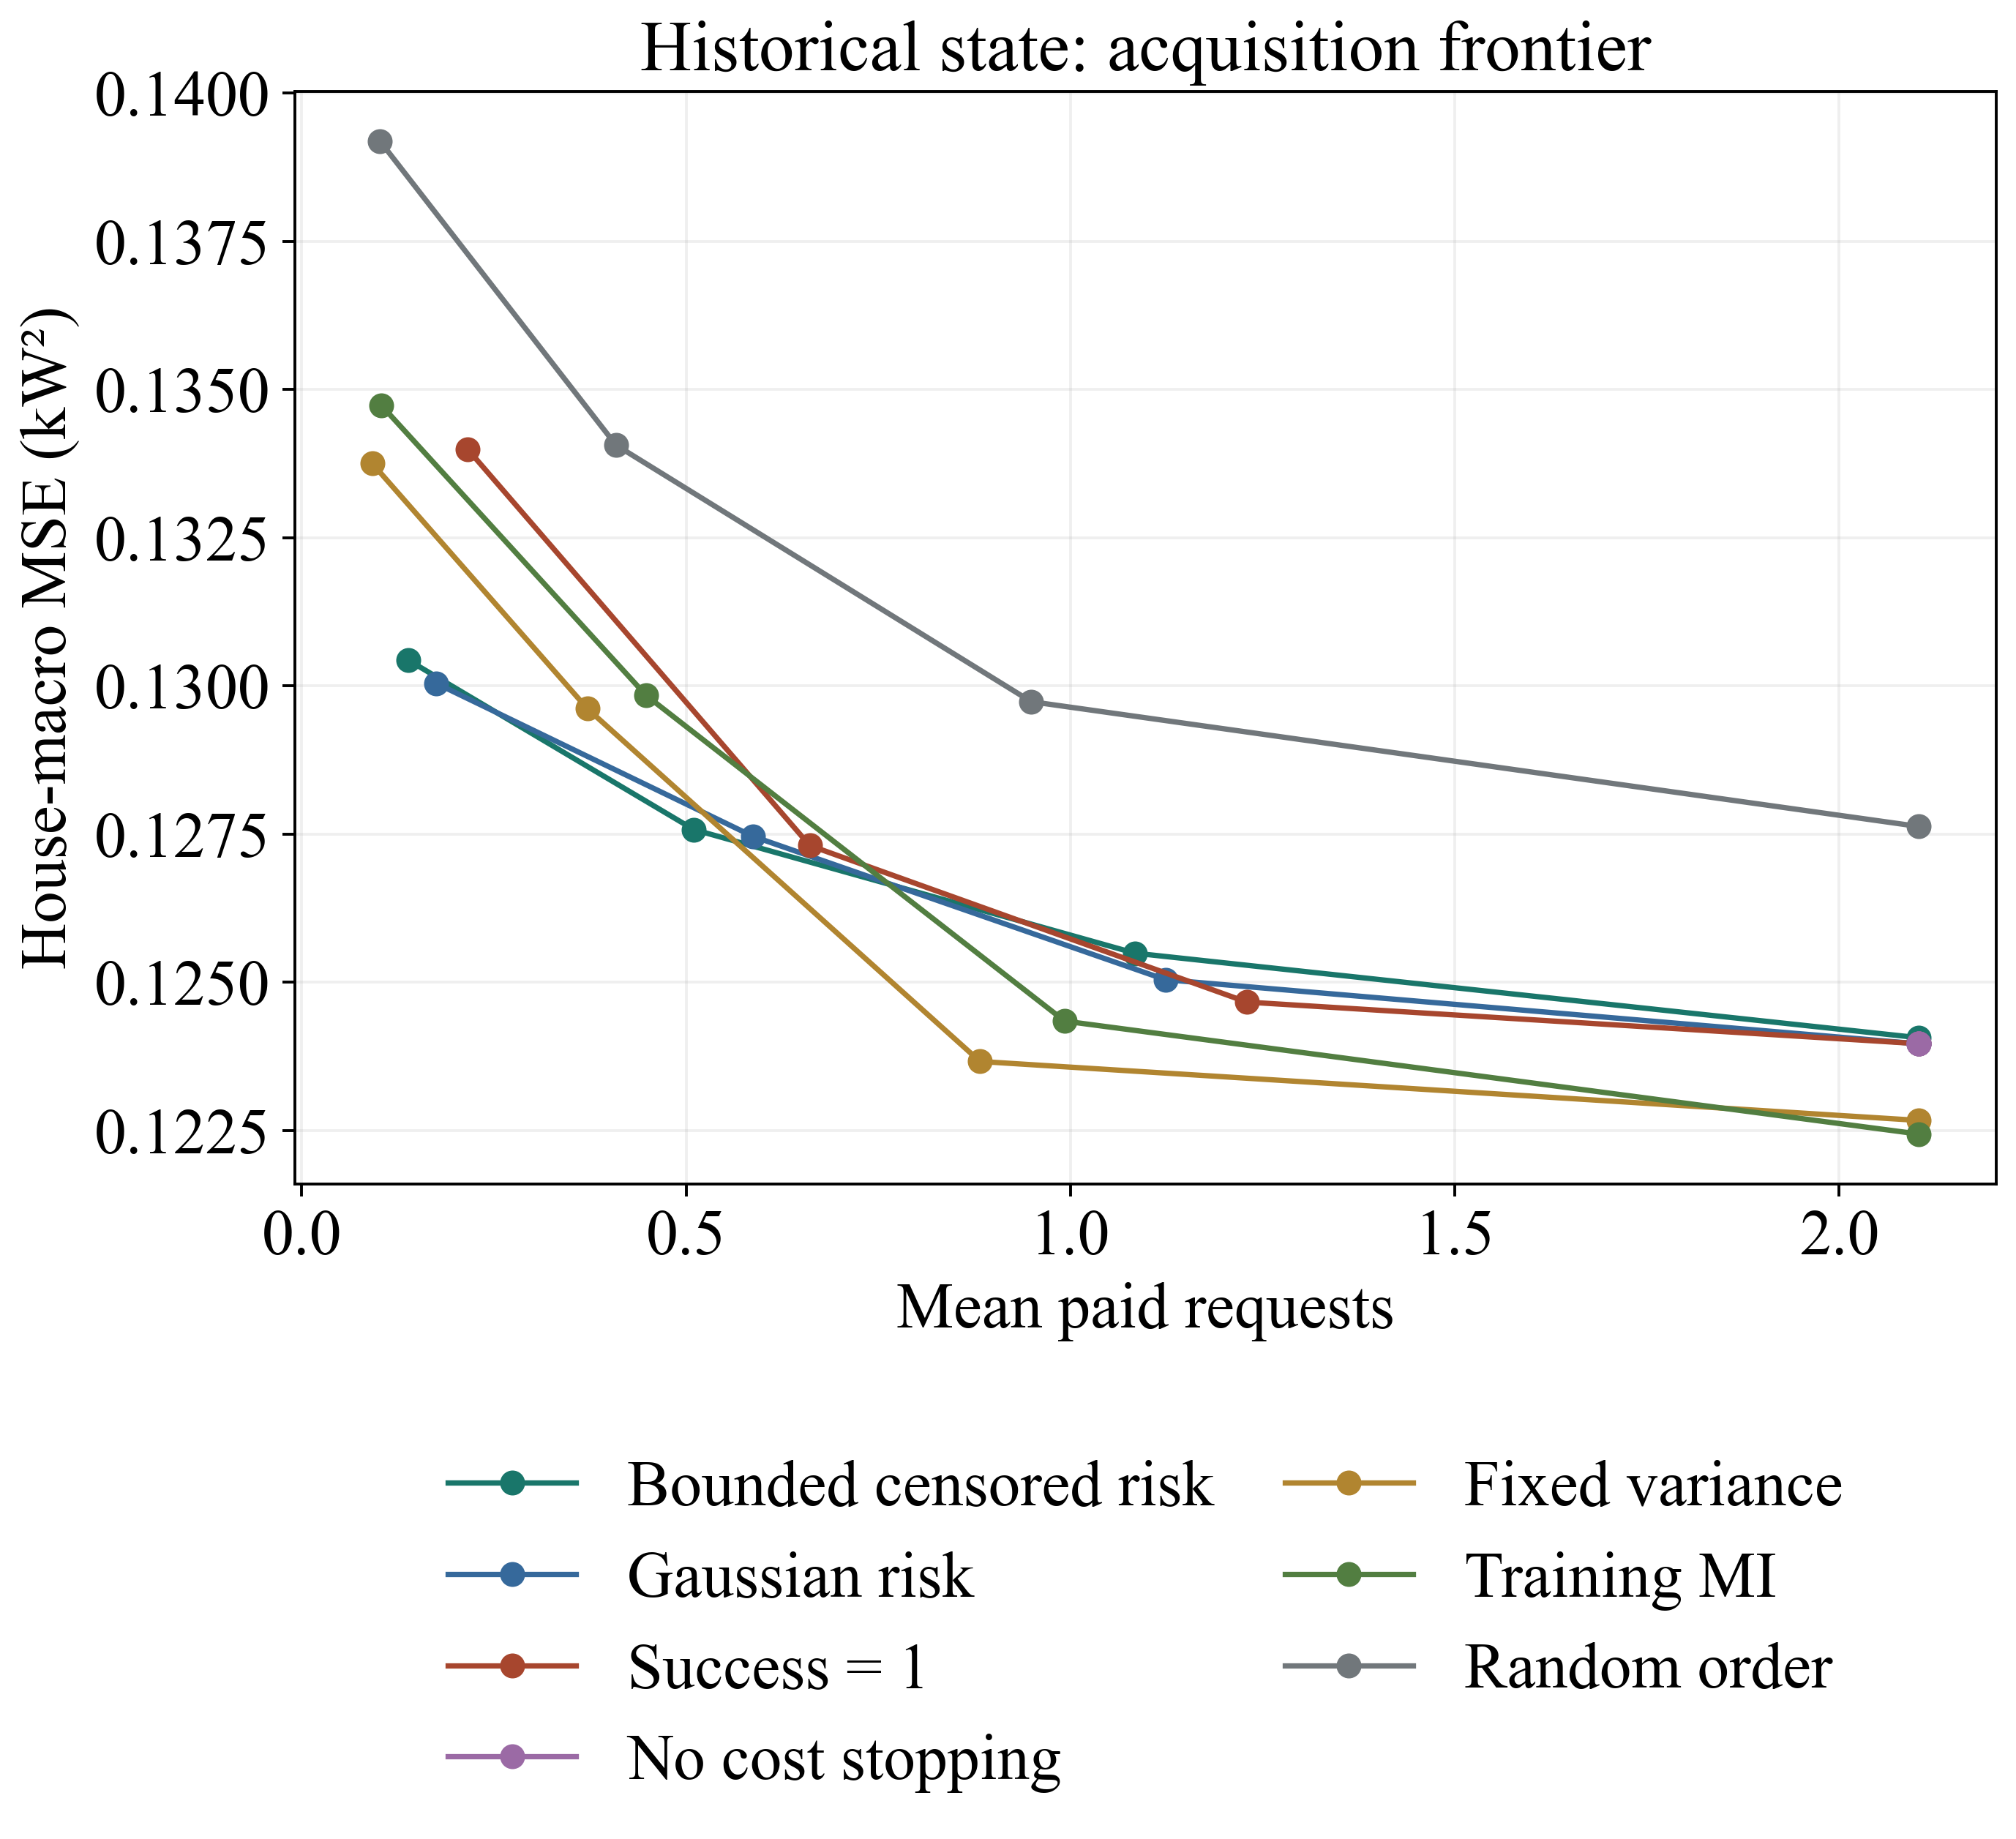

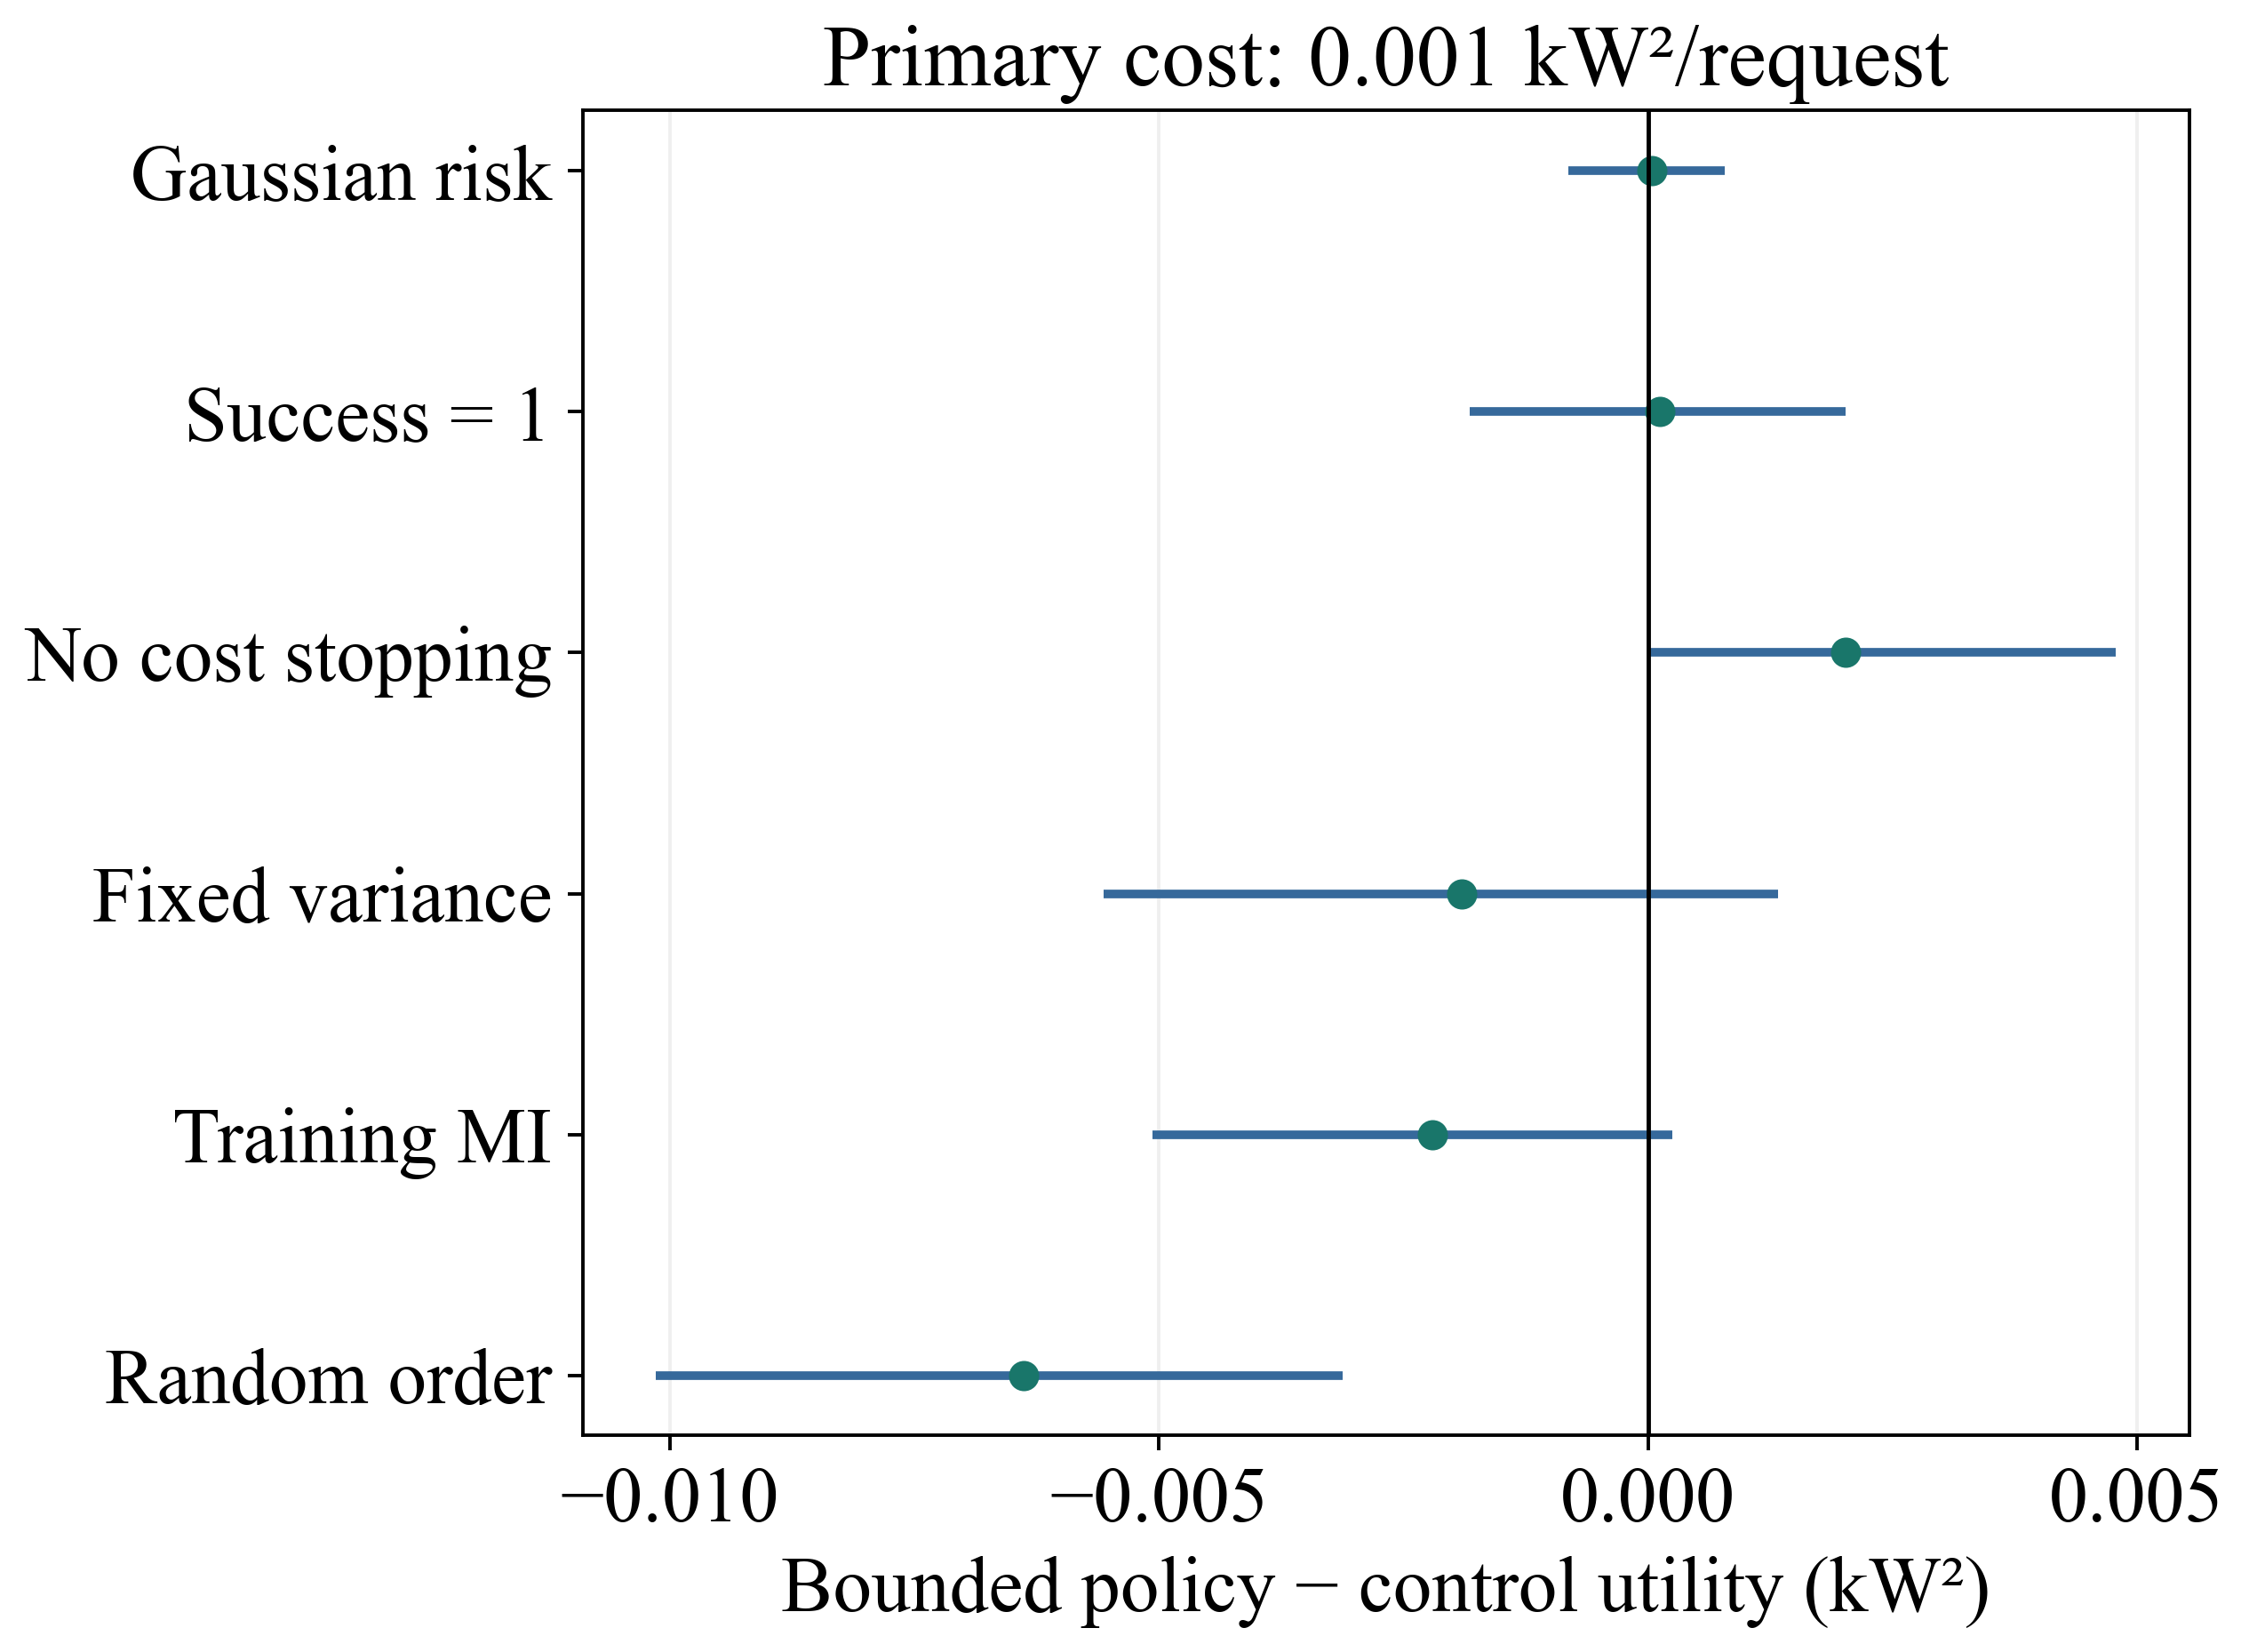

In [1]:
def render_presentation_nb05_acquisition():
    # Presentation only: exact saved summaries; no fitting or per-query metric calculation.
    from pathlib import Path
    import hashlib
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown, HTML
    from PIL import Image as PILImage
    ROOT = Path.cwd()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    PRESENTATION_RUN = "guldana_n3_20261011_presentation"
    _font = font_manager.findfont("Times New Roman", fallback_to_default=False)
    assert Path(_font).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42})
    def read_presentation_csv(relative):
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == INPUT_SHA256[relative], relative
        return pd.read_csv(path)
    def save_presentation(fig, name):
        fig.canvas.draw()
        for item in fig.findobj(Text):
            if item.get_visible() and item.get_text().strip():
                assert 18 <= item.get_fontsize() <= 20
                actual = font_manager.FontProperties(fname=font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)).get_name()
                assert actual == "Times New Roman"
        for kind in ["PNG", "PDF"]:
            directory = ROOT / "Figures" / kind / PRESENTATION_RUN
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (name + "." + kind.lower()), dpi=350, bbox_inches="tight", pad_inches=.08)
        png = ROOT / "Figures/PNG" / PRESENTATION_RUN / (name + ".png")
        with PILImage.open(png) as raster:
            assert all(abs(value - 350) < .02 for value in raster.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    INPUT_SHA256 = {'Tables/guldana_n3_20261009_v02/05_complete_components/acquisition_all_cost_endpoints.csv': 'c2d9e2bec13204c1eebdfb94bf5e6763e210d3647341d2720737183d925aa9ce', 'Tables/guldana_n3_20261009_v02/05_complete_components/acquisition_primary_paired_statistics.csv': 'a81752e3798f3ed918887dd9eecea825392c33ef56a6c1bbbe905c410b9757ba'}

    frontier = read_presentation_csv("Tables/guldana_n3_20261009_v02/05_complete_components/acquisition_all_cost_endpoints.csv")
    effects = read_presentation_csv("Tables/guldana_n3_20261009_v02/05_complete_components/acquisition_primary_paired_statistics.csv")
    labels = {"bounded_censored": "Bounded censored risk", "gaussian_risk": "Gaussian risk", "success_one": "Success = 1", "no_cost_stopping": "No cost stopping", "fixed_variance": "Fixed variance", "mutual_information": "Training MI", "random": "Random order"}
    assert set(frontier.Policy) == set(labels) and len(frontier) == 28 and len(effects) == 6
    colors = ["#19766A", "#36699B", "#A7462E", "#9B6AA5", "#B18530", "#527E41", "#71777B"]
    fig, ax = plt.subplots(figsize=(8.2, 8.2))
    for (policy, label), color in zip(labels.items(), colors):
        part = frontier.loc[frontier.Policy.eq(policy)].sort_values("Penalty")
        ax.plot(part.Requests, part.MSE_kW2, marker="o", label=label, color=color)
    ax.set(xlabel="Mean paid requests", ylabel="House-macro MSE (kW²)", title="Historical state: acquisition frontier")
    ax.grid(alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), ncol=2, frameon=False, columnspacing=1.1)
    fig.subplots_adjust(left=.16, right=.97, top=.91, bottom=.39)
    save_presentation(fig, "NB05_acquisition_frontier")
    fig, ax = plt.subplots(figsize=(8.2, 6.0))
    position = np.arange(len(effects))
    ax.hlines(position, effects["95% lower"], effects["95% upper"], linewidth=2, color="#36699B")
    ax.plot(effects["Utility difference (kW2)"], position, "o", color="#19766A")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(position, [labels[value] for value in effects.Control]); ax.invert_yaxis()
    ax.set(xlabel="Bounded policy − control utility (kW²)", title="Primary cost: 0.001 kW²/request")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 3)); ax.grid(axis="x", alpha=.2)
    fig.subplots_adjust(left=.34, right=.97, top=.90, bottom=.19)
    save_presentation(fig, "NB05_acquisition_paired_effects")

render_presentation_nb05_acquisition()


In [28]:
supported=acquisition_evidence.loc[acquisition_evidence["Supported benefit"],"Control"].tolist()
component_supported=component_evidence.loc[component_evidence["Supported benefit"],"Contrast"].tolist()
display(Markdown("**Executed development findings.** Supported temporal-versus-pooled contrasts under the compact exploratory criterion: "+(", ".join(component_supported) if component_supported else "none")+". Supported acquisition utility improvements at the primary cost: "+(", ".join(supported) if supported else "none")+". All other contrasts remain unconfirmed; a non-significant result does not establish equivalence. The complete tables retain effects favoring controls. These findings remain development evidence, and no independent external advantage follows from them."))
display(Markdown("**Mathematical scope.** The bounded rule concerns one-step model-based squared-risk reduction under a censored Gaussian target, independent Gaussian observation noise and conditionally uninformative failures. Gaussian conditioning, attention, censored moments and Hermite expansions are known ingredients. The present integration and stopping/error bound are a candidate methodological contribution; empirical benefit and literature priority require separate evidence. Equal success probabilities and equal costs give the same acquisition ordering as Gaussian variance reduction. The algorithm does not prove globally optimal multi-step acquisition or physical energy savings."))


**Executed development findings.** Supported temporal-versus-pooled contrasts under the compact exploratory criterion: none. Supported acquisition utility improvements at the primary cost: random. All other contrasts remain unconfirmed; a non-significant result does not establish equivalence. The complete tables retain effects favoring controls. These findings remain development evidence, and no independent external advantage follows from them.

**Mathematical scope.** The bounded rule concerns one-step model-based squared-risk reduction under a censored Gaussian target, independent Gaussian observation noise and conditionally uninformative failures. Gaussian conditioning, attention, censored moments and Hermite expansions are known ingredients. The present integration and stopping/error bound are a candidate methodological contribution; empirical benefit requires separate evidence. Equal success probabilities and equal costs give the same acquisition ordering as Gaussian variance reduction. The algorithm does not prove globally optimal multi-step acquisition or physical energy savings.

In [29]:
# Check implications of the acquisition assumptions on unseen development rows.
failure_diagnostic=json.loads((ROOT/"Configs/acquisition_failure_diagnostic_v2.json").read_text())
failure_moments=[];failure_reliability=[];failure_no_candidate=0
for fold in [1,2,3]:
    for seed in [17,43,101]:
        data=acquisition_v2_inputs(fold,seed);frame=data["frame"];i=np.arange(len(frame));agg=data["aggregate"]
        mean=data["mean"][i,agg];variance=data["covariance"][i,agg,agg]
        physical_mean,physical_variance,_=censored_moments(mean,variance)
        residual=frame.y_kW.to_numpy()-physical_mean
        pool=data["pool"].astype(bool);count=pool.sum(1);keep=count>0;failure_no_candidate+=int((~keep).sum())
        observed=data["validity"].astype(float);p=data["success"]
        innovation=np.where(pool,observed-p,0).sum(1)/np.maximum(count,1)
        part=frame.loc[keep,["observation_id","house","fold","seed","timestamp"]].copy()
        part["Mean moment"]=innovation[keep]*residual[keep]
        part["Variance moment"]=innovation[keep]*(residual[keep]**2-physical_variance[keep])
        failure_moments.append(part)
        for house in sorted(frame.house.unique()):
            eligible=pool&frame.house.eq(house).to_numpy()[:,None]
            probabilities=p[eligible];outcomes=observed[eligible]
            for b in range(10):
                chosen=(probabilities>=b/10)&((probabilities<(b+1)/10) if b<9 else probabilities<=1)
                if chosen.any():failure_reliability.append({"Fold":fold,"Seed":seed,"House":house,"Bin":b,
                    "Requests":int(chosen.sum()),"Mean fitted success":float(probabilities[chosen].mean()),
                    "Observed success":float(outcomes[chosen].mean()),"Brier":float(np.mean((probabilities[chosen]-outcomes[chosen])**2))})
        del data;gc.collect()
failure_moments=pd.concat(failure_moments,ignore_index=True)
failure_moments.to_parquet(PROPOSED_PRED_DIR/"acquisition_failure_OOF_moments.parquet",index=False)
reliability=pd.DataFrame(failure_reliability);reliability.to_csv(V2_TABLES/"acquisition_success_OOF_house_reliability.csv",index=False)
rows=[]
for endpoint in ["Mean moment","Variance moment"]:
    paired=failure_moments.groupby(["observation_id","house","fold","timestamp"])[endpoint].mean().reset_index()
    household=paired.groupby("house")[endpoint].mean().to_numpy();observed=float(household.mean())
    signs=np.asarray(list(product([-1.,1.],repeat=len(household))));null=(signs*household).mean(1)
    rows.append({"Moment":endpoint,"Unit":"kW" if endpoint=="Mean moment" else "kW squared","Equal-house moment":observed,"Households":len(household),
        "Exact sign-flip p":float(np.mean(np.abs(null)>=abs(observed)-1e-15))})
assumption_evidence=pd.DataFrame(rows);assumption_evidence["Holm p"]=multipletests(assumption_evidence["Exact sign-flip p"],method="holm")[1]
v2_table(assumption_evidence,"acquisition_failure_moment_diagnostic","Exploratory implications of the joint success-propensity/posterior model, Holm over two moments. Nonzero moments can reflect posterior bias, propensity misspecification or informative failures; zero moments do not prove conditional independence.",precision=6)
display(Markdown(f"**Assumption boundary.** {int((assumption_evidence['Holm p']<.05).sum())}/2 moment diagnostics have Holm p < 0.05; "
    f"{failure_no_candidate} seed-specific queries contain no initially hidden auxiliary and contribute no success diagnostic. "
    "They remain in the complete reconstruction and acquisition cohorts. The one-step certificate applies to the stated model-based objective; it is not a guarantee of Bayes optimality under the unknown real failure mechanism."))


Moment,Unit,Equal-house moment,Households,Exact sign-flip p,Holm p
Mean moment,kW,0.002155,10,0.281250,0.562500
Variance moment,kW squared,0.003209,10,0.478516,0.562500


**Assumption boundary.** 0/2 moment diagnostics have Holm p < 0.05; 47794 seed-specific queries contain no initially hidden auxiliary and contribute no success diagnostic. They remain in the complete reconstruction and acquisition cohorts. The one-step certificate applies to the stated model-based objective; it is not a guarantee of Bayes optimality under the unknown real failure mechanism.

### Probability calibration and selective reconstruction

Compare the unchanged temporal posterior and two ExtraTrees uncertainty baselines as Gaussian and fixed censored laws, before and after inner-only CRPS scaling. Scaling changes uncertainty, not architecture. These inner rows also selected model weights: held-out scores remain essential. Four non-self contrasts retain the original six-test multiplicity adjustment conservatively. No redundant self-comparison is computed.

In [30]:
import joblib
from threadpoolctl import threadpool_limits
from scipy.optimize import minimize_scalar
from scipy.special import ndtri
VARIANCE_FLOOR_KW2 = 1e-08

def stable_tree_population_variance(model, x):
    mean = np.zeros(len(x), dtype=np.float64)
    m2 = np.zeros(len(x), dtype=np.float64)
    assert len(model.estimators_) > 1
    with threadpool_limits(limits=4):
        for count, tree in enumerate(model.estimators_, 1):
            value = tree.predict(x).astype(np.float64)
            difference = value - mean
            mean += difference / count
            m2 += difference * (value - mean)
    variance = m2 / len(model.estimators_)
    assert np.isfinite(variance).all() and (variance >= 0).all()
    return variance

def equal_house_second_moment(metadata, residual, denominator=None):
    values = np.asarray(residual, dtype=np.float64) ** 2
    if denominator is not None:
        values = values / np.maximum(np.asarray(denominator, dtype=np.float64), VARIANCE_FLOOR_KW2)
    value = float(pd.DataFrame({'house': metadata.house.to_numpy(), 'squared': values}).groupby('house').squared.mean().mean())
    assert np.isfinite(value) and value > 0
    return value
UNCERTAINTY_V2 = json.loads((ROOT / 'Configs/article_uncertainty_20261011.json').read_text())
UNCERTAINTY_V2_HASH = file_sha256(ROOT / 'Configs/article_uncertainty_20261011.json')
UNCERTAINTY_DIR = PROPOSED_PRED_DIR / 'uncertainty_v2'
UNCERTAINTY_DIR.mkdir(exist_ok=True)

def uncertainty_law_scores(mean, variance, y, censored):
    mean, variance, y = np.broadcast_arrays(np.asarray(mean, float), np.asarray(variance, float), np.asarray(y, float))
    assert np.isfinite(mean).all() and np.isfinite(variance).all() and np.isfinite(y).all() and (y >= 0).all()
    guarded = variance < VARIANCE_FLOOR_KW2
    variance = np.maximum(variance, VARIANCE_FLOOR_KW2)
    sd = np.sqrt(variance)
    z = (y - mean) / sd
    crps = censored_crps(mean, variance, y) if censored else sd * (z * (2 * ndtr(z) - 1) + 2 * np.exp(-z * z / 2) / np.sqrt(2 * np.pi) - 1 / np.sqrt(np.pi))
    if censored:
        expectation, predictive_variance, atom = censored_moments(mean, variance)
        median = np.maximum(mean, 0.0)
    else:
        expectation = mean
        predictive_variance = variance
        atom = np.zeros_like(mean)
        median = mean
    output = {'CRPS_kW': crps, 'median_kW': median, 'mean_kW': expectation, 'variance_kW2': predictive_variance, 'zero_mass': atom, 'guarded': guarded, 'median_absolute_error_kW': abs(y - median), 'mean_squared_error_kW2': (y - expectation) ** 2}
    for level in UNCERTAINTY_V2['interval_levels']:
        low = mean + sd * ndtri((1 - level) / 2)
        high = mean + sd * ndtri((1 + level) / 2)
        if censored:
            low = np.maximum(low, 0)
            high = np.maximum(high, 0)
        tag = str(int(round(level * 100)))
        output[f'coverage_{tag}'] = (y >= low) & (y <= high)
        output[f'width_{tag}_kW'] = high - low
    return output

def fit_inner_crps_multiplier(metadata, mean, variance, censored):
    counts = metadata.house.value_counts()
    weights = metadata.house.map(lambda h: 1 / (len(counts) * counts[h])).to_numpy()
    y = metadata.y_kW.to_numpy()
    variance = np.maximum(variance, VARIANCE_FLOOR_KW2)

    def objective(log_alpha):
        scaled = np.maximum(variance * np.exp(log_alpha), VARIANCE_FLOOR_KW2)
        if censored:
            score = censored_crps(mean, scaled, y)
        else:
            sd = np.sqrt(scaled)
            z = (y - mean) / sd
            score = sd * (z * (2 * ndtr(z) - 1) + 2 * np.exp(-z * z / 2) / np.sqrt(2 * np.pi) - 1 / np.sqrt(np.pi))
        return float(np.dot(weights, score))
    low, high = UNCERTAINTY_V2['scale_fit']['log_bounds']
    result = minimize_scalar(objective, bounds=(low, high), method='bounded', options={'xatol': 1e-05})
    assert result.success and np.isfinite(result.fun)
    return {'variance_multiplier': float(np.exp(result.x)), 'inner_house_CRPS_kW': float(result.fun), 'objective_calls': int(result.nfev), 'near_bound': bool(min(result.x - low, high - result.x) < 0.01), 'optimizer_success': bool(result.success)}

def uncertainty_v2_inputs(fold, seed):
    cache = NeuralInputCache(fold, seed)
    inner = np.flatnonzero(cache.metadata.role.eq('inner_validation').to_numpy())
    outer = np.flatnonzero(cache.metadata.role.eq('outer_validation').to_numpy())
    imeta = cache.metadata.iloc[inner].reset_index(drop=True)
    ometa = cache.metadata.iloc[outer].reset_index(drop=True)
    assert len(inner) == 10240 and len(outer) == 40960
    sources = {}
    families = {}

    def bind(path):
        digest = file_sha256(path)
        relative = str(path.relative_to(ROOT))
        if relative in V2_OLD_LOCK['files']:
            assert digest == V2_OLD_LOCK['files'][relative]
        sources[relative] = digest
        return digest
    old_dir = ROOT / 'Models/proposed' / OLD_RUN
    old_pred = ROOT / 'Predictions/development_proposed' / OLD_RUN
    stem = f'Proposed_temporal_only_fold_{fold}_seed_{seed}'
    record = json.loads((old_dir / f'{stem}_complete.json').read_text())
    bind(old_dir / f'{stem}_complete.json')
    checkpoint = old_dir / f'{stem}.pt'
    path = old_pred / f'{stem}.parquet'
    assert bind(checkpoint) == record['checkpoint_sha256'] and bind(path) == record['prediction_sha256']
    bundle = torch.load(checkpoint, map_location='cpu', weights_only=True)
    reference = SensorSetGaussianCandidate(**record['parameters']).to(DEVICE)
    reference.load_state_dict(bundle['state_dict'])
    reference.eval()
    ip, iv, state = predict_proposed(reference, cache, inner, record['parameters'], DEVICE, 'Reference inner probability')
    original = pd.read_parquet(path).set_index('observation_id').loc[ometa.observation_id].reset_index()
    pd.testing.assert_frame_equal(original[['observation_id', 'y_kW', 'house', 'seed']], ometa[['observation_id', 'y_kW', 'house', 'seed']])
    families['reference'] = (ip, iv, original.prediction_kW.to_numpy(), original.variance_kW2.to_numpy())
    del reference, state, bundle
    gc.collect()
    directory = ROOT / 'Models/baselines' / OLD_RUN
    stem = f'ExtraTrees_fold_{fold}_seed_{seed}'
    checkpoint = directory / f'{stem}.joblib'
    record = json.loads((directory / f'{stem}_resources.json').read_text())
    assert bind(checkpoint) == record['model_sha256']
    modeling_path = CACHE / f'fold_{fold}_seed_{seed}.json'
    bind(modeling_path)
    modeling = json.loads(modeling_path.read_text())
    assert bind(ROOT / modeling['array_file']) == modeling['array_sha256']
    with np.load(ROOT / modeling['array_file'], allow_pickle=False) as arrays:
        x = arrays['x'][np.r_[inner, outer]].copy()
        columns = arrays['transformed_columns'].tolist()
    bundle = joblib.load(checkpoint)
    model = bundle['model']
    x = x[:, [columns.index(c) for c in bundle['feature_columns']]]
    with threadpool_limits(limits=4):
        prediction = model.predict(x)
    variance = stable_tree_population_variance(model, x)
    tree_path = ROOT / 'Predictions/development' / OLD_RUN / f'{stem}.parquet'
    assert bind(tree_path) == record['prediction_sha256']
    old_tree = pd.read_parquet(tree_path).set_index('observation_id').loc[ometa.observation_id]
    np.testing.assert_array_equal(prediction[len(inner):], old_tree.prediction_kW.to_numpy())
    families['tree spread'] = (prediction[:len(inner)], variance[:len(inner)], prediction[len(inner):], variance[len(inner):])
    constant = equal_house_second_moment(imeta, imeta.y_kW.to_numpy() - prediction[:len(inner)])
    families['tree constant'] = (prediction[:len(inner)], np.full(len(inner), constant), prediction[len(inner):], np.full(len(outer), constant))
    del model, bundle, x, cache
    gc.collect()
    if str(DEVICE) == 'mps':
        torch.mps.empty_cache()
    return (imeta, ometa, families, sources)


In [31]:
# Fit calibration on inner rows, then save every OOF score and interval without filtering failures.
def build_uncertainty_v2(fold,seed):
    destination=UNCERTAINTY_DIR/f"fold_{fold}_seed_{seed}.parquet";proof_path=destination.with_suffix(".json")
    if proof_path.exists():
        proof=json.loads(proof_path.read_text())
        assert proof["protocol_sha256"]==UNCERTAINTY_V2_HASH and proof["implementation_sha256"]==UNCERTAINTY_IMPLEMENTATION_HASH
        assert proof["prediction_sha256"]==file_sha256(destination)
        for relative,digest in proof["sources"].items():assert file_sha256(ROOT/relative)==digest
        return proof
    started=time.perf_counter();imeta,ometa,families,sources=uncertainty_v2_inputs(fold,seed)
    parts=[];calibration=[]
    pit_random=np.array([int.from_bytes(hashlib.blake2b(f"pit_v2|{seed}|{identity}".encode(),digest_size=8).digest(),"little")/2**64
                         for identity in ometa.observation_id])
    ties=[hashlib.sha256(identity.encode()).hexdigest() for identity in ometa.observation_id]
    for family,(im,iv,om,ov) in families.items():
        for censored in ([True] if family=="selected" else [False,True]):
            law="censor" if censored else "Gaussian"
            fitted=fit_inner_crps_multiplier(imeta,im,iv,censored)
            calibration.append({"Family":family,"Law":law,"Fold":fold,"Seed":seed,**fitted})
            for mode,alpha in [("unscaled",1.),("inner-CRPS",fitted["variance_multiplier"])]:
                frame=ometa[["observation_id","house","fold","seed","timestamp","y_kW","gap","retention"]].copy()
                scaled_variance=np.maximum(ov,VARIANCE_FLOOR_KW2)*alpha
                scores=uncertainty_law_scores(om,scaled_variance,frame.y_kW.to_numpy(),censored)
                for key,value in scores.items():frame[key]=value
                frame["Variant"]=f"{family} {law} {mode}";frame["latent_mean_kW"]=om
                frame["latent_variance_kW2"]=np.maximum(scaled_variance,VARIANCE_FLOOR_KW2);frame["variance_multiplier"]=alpha
                frame["base_variance_guarded"]=ov<VARIANCE_FLOOR_KW2
                z=(frame.y_kW.to_numpy()-om)/np.sqrt(frame.latent_variance_kW2.to_numpy())
                pit=ndtr(z)
                if censored:pit=np.where(frame.y_kW.to_numpy()==0,pit_random*frame.zero_mass.to_numpy(),pit)
                frame["PIT"]=pit;frame["tie_hash"]=ties
                assert np.isfinite(frame.select_dtypes(include="number").to_numpy()).all()
                assert frame.PIT.between(0,1).all() and frame.CRPS_kW.ge(-1e-10).all()
                parts.append(frame)
    result=pd.concat(parts,ignore_index=True)
    assert not result.duplicated(["observation_id","Variant"]).any()
    result.to_parquet(destination,index=False)
    calibration=pd.DataFrame(calibration);calibration_path=UNCERTAINTY_DIR/f"fold_{fold}_seed_{seed}_calibration.csv"
    calibration.to_csv(calibration_path,index=False)
    proof={"fold":fold,"seed":seed,"run_id":V2_RUN,"protocol_sha256":UNCERTAINTY_V2_HASH,
        "implementation_sha256":UNCERTAINTY_IMPLEMENTATION_HASH,"sources":sources,"prediction_sha256":file_sha256(destination),
        "calibration_sha256":file_sha256(calibration_path),"variants":sorted(result.Variant.unique().tolist()),
        "OOF_queries_per_variant":40960,"inner_queries":10240,"elapsed_seconds":time.perf_counter()-started,
        "revision2_accepted":bool(revision2_accepted),"calibration_near_boundary_count":int(calibration.near_bound.sum()),
        "model_refits":0,"global_reserved_calibration_accessed":False}
    proof_path.write_text(json.dumps(proof,indent=2)+"\n")
    return proof

# Bind scoring and calibration source before any outcomes.
UNCERTAINTY_IMPLEMENTATION_HASH=bind_article_source(
    [f"article-original-{i}" for i in [122,147,165,166]]+["article-component-construction"],
    "article_uncertainty_prefit_source.json",UNCERTAINTY_V2_HASH)


In [34]:
uncertainty_v2_fold1=[build_uncertainty_v2(1,seed) for seed in [17,43,101]]
v2_table(pd.DataFrame([{"Fold":r["fold"],"Seed":r["seed"],"OOF queries per law":r["OOF_queries_per_variant"],"Distribution variants":len(r["variants"]),"Seconds":r["elapsed_seconds"],"Scale fits near boundary":r["calibration_near_boundary_count"]} for r in uncertainty_v2_fold1]),"uncertainty_v2_fold1_execution","Complete inner-calibration and OOF scoring; no model refit or reserved calibration access.")
uncertainty_v2_fold2=[build_uncertainty_v2(2,seed) for seed in [17,43,101]]
v2_table(pd.DataFrame([{"Fold":r["fold"],"Seed":r["seed"],"OOF queries per law":r["OOF_queries_per_variant"],"Distribution variants":len(r["variants"]),"Seconds":r["elapsed_seconds"],"Scale fits near boundary":r["calibration_near_boundary_count"]} for r in uncertainty_v2_fold2]),"uncertainty_v2_fold2_execution","Complete inner-calibration and OOF scoring; no model refit or reserved calibration access.")
uncertainty_v2_fold3=[build_uncertainty_v2(3,seed) for seed in [17,43,101]]
v2_table(pd.DataFrame([{"Fold":r["fold"],"Seed":r["seed"],"OOF queries per law":r["OOF_queries_per_variant"],"Distribution variants":len(r["variants"]),"Seconds":r["elapsed_seconds"],"Scale fits near boundary":r["calibration_near_boundary_count"]} for r in uncertainty_v2_fold3]),"uncertainty_v2_fold3_execution","Complete inner-calibration and OOF scoring; no model refit or reserved calibration access.")


Fold,Seed,OOF queries per law,Distribution variants,Seconds,Scale fits near boundary
1,17,40960,12,19.9681,0
1,43,40960,12,14.7270,0
1,101,40960,12,14.6871,0


Fold,Seed,OOF queries per law,Distribution variants,Seconds,Scale fits near boundary
2,17,40960,12,14.9412,0
2,43,40960,12,14.8510,0
2,101,40960,12,14.6889,0


Fold,Seed,OOF queries per law,Distribution variants,Seconds,Scale fits near boundary
3,17,40960,12,15.5731,0
3,43,40960,12,15.6795,0
3,101,40960,12,14.9969,0


In [35]:
# Complete probability summary with memory bounded to one distribution variant.
uncertainty_proofs=[json.loads((UNCERTAINTY_DIR/f"fold_{fold}_seed_{seed}.json").read_text()) for fold in [1,2,3] for seed in [17,43,101]]
uncertainty_variants=uncertainty_proofs[0]["variants"]
assert all(proof["variants"]==uncertainty_variants for proof in uncertainty_proofs)
for proof in uncertainty_proofs:
    path=UNCERTAINTY_DIR/f"fold_{proof['fold']}_seed_{proof['seed']}.parquet"
    assert file_sha256(path)==proof["prediction_sha256"]
def read_uncertainty_variant(variant):
    parts=[pd.read_parquet(UNCERTAINTY_DIR/f"fold_{fold}_seed_{seed}.parquet",filters=[("Variant","==",variant)])
           for fold in [1,2,3] for seed in [17,43,101]]
    frame=pd.concat(parts,ignore_index=True)
    assert len(frame)==368640 and frame.Variant.eq(variant).all() and not frame.duplicated(["observation_id","seed"]).any()
    return frame
uncertainty_rows=[];uncertainty_intervals=[];uncertainty_pit=[];uncertainty_selective=[];uncertainty_crps_columns={};uncertainty_key=None
for variant in uncertainty_variants:
    frame=read_uncertainty_variant(variant)
    frame=frame.sort_values(["seed","observation_id"]).reset_index(drop=True)
    key=frame[["observation_id","seed","house","fold","timestamp","y_kW"]]
    if uncertainty_key is None:uncertainty_key=key.copy()
    else:pd.testing.assert_frame_equal(uncertainty_key,key)
    uncertainty_crps_columns[variant]=frame.CRPS_kW.to_numpy()
    metric_cols=["CRPS_kW","median_absolute_error_kW","mean_squared_error_kW2","variance_kW2","zero_mass","guarded","base_variance_guarded"]
    houses=frame.groupby(["seed","house"])[metric_cols].mean().reset_index()
    for seed,group in houses.groupby("seed"):
        uncertainty_rows.append({"Variant":variant,"Seed":seed,"CRPS (kW)":group.CRPS_kW.mean(),
            "Median MAE (kW)":group.median_absolute_error_kW.mean(),"Mean RMSE (kW)":np.sqrt(group.mean_squared_error_kW2).mean(),
            "Mean predictive variance (kW squared)":group.variance_kW2.mean(),"Mean zero mass":group.zero_mass.mean(),
            "Numerical floor (%)":100*group.guarded.mean(),"Base variance floor (%)":100*group.base_variance_guarded.mean()})
    for level in UNCERTAINTY_V2["interval_levels"]:
        tag=str(int(round(level*100)))
        intervals=frame.groupby(["seed","house"])[[f"coverage_{tag}",f"width_{tag}_kW"]].mean().groupby("seed").mean()
        for seed,row in intervals.iterrows():uncertainty_intervals.append({"Variant":variant,"Seed":seed,"Nominal coverage (%)":100*level,
            "Empirical coverage (%)":100*row[f"coverage_{tag}"],"Mean width (kW)":row[f"width_{tag}_kW"]})
    for (seed,house),group in frame.groupby(["seed","house"]):
        frequencies=np.histogram(group.PIT,bins=np.linspace(0,1,11))[0]/len(group)
        for j,frequency in enumerate(frequencies):uncertainty_pit.append({"Variant":variant,"Seed":seed,"House":house,
            "PIT lower":j/10,"PIT upper":(j+1)/10,"Frequency":frequency,"Queries":len(group)})
        ordered=group.sort_values(["variance_kW2","tie_hash"],kind="stable")
        for fraction in UNCERTAINTY_V2["selective_retained_fractions"]:
            count=max(1,int(np.ceil(len(ordered)*fraction)));selected=ordered.iloc[:count]
            uncertainty_selective.append({"Variant":variant,"Seed":seed,"House":house,"Requested fraction":fraction,
                "Actual fraction":count/len(group),"Retained queries":count,"Available queries":len(group),
                "Median MAE (kW)":selected.median_absolute_error_kW.mean(),"Mean MSE (kW squared)":selected.mean_squared_error_kW2.mean(),
                "CRPS (kW)":selected.CRPS_kW.mean()})
    del frame,houses;gc.collect()
uncertainty_seed_scores=pd.DataFrame(uncertainty_rows);uncertainty_interval_scores=pd.DataFrame(uncertainty_intervals)
uncertainty_pit=pd.DataFrame(uncertainty_pit);uncertainty_selective=pd.DataFrame(uncertainty_selective)
for name,frame in [("seed_scores",uncertainty_seed_scores),("intervals",uncertainty_interval_scores),
                   ("PIT_house_bins",uncertainty_pit),("selective_house_curves",uncertainty_selective)]:
    frame.to_csv(V2_TABLES/f"uncertainty_v2_{name}.csv",index=False)
uncertainty_summary=uncertainty_seed_scores.groupby("Variant",sort=False).agg(CRPS_kW=("CRPS (kW)","mean"),
    CRPS_seed_min=("CRPS (kW)","min"),CRPS_seed_max=("CRPS (kW)","max"),Median_MAE_kW=("Median MAE (kW)","mean"),
    Mean_RMSE_kW=("Mean RMSE (kW)","mean"),Mean_zero_mass=("Mean zero mass","mean"),
    Base_variance_floor_percent=("Base variance floor (%)","mean")).reset_index()
coverage95=uncertainty_interval_scores.loc[uncertainty_interval_scores["Nominal coverage (%)"].eq(95)].groupby("Variant",as_index=False).agg(
    Coverage95_percent=("Empirical coverage (%)","mean"),Width95_kW=("Mean width (kW)","mean"))
uncertainty_summary=uncertainty_summary.merge(coverage95,on="Variant",validate="one_to_one")
v2_table(uncertainty_summary,"uncertainty_v2_complete_summary","Complete OOF probabilistic controls. Median MAE and conditional-mean RMSE are distinct decision rules. Inner-CRPS scaling uses checkpoint-selection development rows and is not independent calibration evidence.")
calibration=pd.concat([pd.read_csv(UNCERTAINTY_DIR/f"fold_{fold}_seed_{seed}_calibration.csv") for fold in [1,2,3] for seed in [17,43,101]],ignore_index=True)
v2_table(calibration.groupby(["Family","Law"],as_index=False).agg(Multiplier_min=("variance_multiplier","min"),
    Multiplier_max=("variance_multiplier","max"),Fits_near_bounds=("near_bound","sum"),Fits=("Seed","size")),
    "uncertainty_v2_scale_range","All nine fold/seed scale fits per distribution law. A near-boundary optimum is disclosed rather than silently extending its registered search range.")


Variant,CRPS_kW,CRPS_seed_min,CRPS_seed_max,Median_MAE_kW,Mean_RMSE_kW
reference Gaussian inner-CRPS,0.0994,0.0974,0.1009,0.1208,0.3767
reference Gaussian unscaled,0.1018,0.0994,0.1036,0.1208,0.3767
reference censor inner-CRPS,0.0986,0.0965,0.1002,0.1207,0.3733
reference censor unscaled,0.0997,0.0972,0.1015,0.1207,0.3702
tree constant Gaussian inner-CRPS,0.1057,0.1049,0.1062,0.1158,0.3357
tree constant Gaussian unscaled,0.1421,0.1406,0.1442,0.1158,0.3357
tree constant censor inner-CRPS,0.1053,0.1046,0.1058,0.1158,0.3358
tree constant censor unscaled,0.1263,0.1253,0.1275,0.1158,0.3489
tree spread Gaussian inner-CRPS,0.0914,0.0910,0.0919,0.1158,0.3357
tree spread Gaussian unscaled,0.0914,0.0910,0.0918,0.1158,0.3357


Family,Law,Multiplier_min,Multiplier_max,Fits_near_bounds,Fits
reference,Gaussian,0.2556,0.4826,0,9
reference,censor,0.2901,0.5491,0,9
tree constant,Gaussian,0.0218,0.0355,0,9
tree constant,censor,0.0268,0.0416,0,9
tree spread,Gaussian,0.9573,1.0902,0,9
tree spread,censor,1.0181,1.1989,0,9


In [36]:
# Four non-self CRPS contrasts under the compact scope.
from itertools import product
from statsmodels.stats.multitest import multipletests
def actual_uncertainty_variant(name):
    return name if revision2_accepted or not name.startswith("selected ") else name.replace("selected ","reference ",1)
probability_contrasts=[];probability_intervals=[]
for selected,control in UNCERTAINTY_V2["primary_contrasts"]:
    a,b=actual_uncertainty_variant(selected),actual_uncertainty_variant(control)
    frame=uncertainty_key.copy();frame["difference"]=uncertainty_crps_columns[a]-uncertainty_crps_columns[b]
    paired=frame.groupby(["observation_id","house","fold","timestamp"],as_index=False).difference.mean()
    household=paired.groupby("house").difference.mean().to_numpy();observed=float(household.mean());assert len(household)==10
    signs=np.asarray(list(product([-1.,1.],repeat=10)));null=(signs*household).mean(1)
    pvalue=float(np.mean(np.abs(null)>=abs(observed)-1e-15))
    probability_contrasts.append({"Selected distribution":selected,"Control":control,"Actual selected distribution":a,
        "CRPS difference (kW)":observed,"Households improved":int((household<0).sum()),"Exact sign-flip p":pvalue})
    for minutes in [240]:
        blocks=paired.assign(block=paired.timestamp.dt.floor(f"{minutes}min")).groupby(["house","fold","block"]).difference.agg(["sum","count"]).reset_index()
        arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")]
        rng=np.random.default_rng(20261009+minutes);reps=10000;by_house=np.empty((reps,10))
        for j,array in enumerate(arrays):
            for start in range(0,reps,250):
                sampled=rng.integers(0,len(array),size=(min(250,reps-start),len(array)));chosen=array[sampled]
                by_house[start:start+len(sampled),j]=chosen[:,:,0].sum(1)/chosen[:,:,1].sum(1)
        sampled_houses=rng.integers(0,10,size=(reps,10));distribution=by_house[np.arange(reps)[:,None],sampled_houses].mean(1)
        lo,hi=np.quantile(distribution,[.025,.975]);probability_intervals.append({"Selected distribution":selected,"Control":control,
            "Block minutes":minutes,"95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
probability_contrasts=pd.DataFrame(probability_contrasts);probability_contrasts["Holm p"]=multipletests(np.r_[probability_contrasts["Exact sign-flip p"].to_numpy(),np.ones(2)],method="holm")[1][:len(probability_contrasts)]
probability_intervals=pd.DataFrame(probability_intervals);probability_intervals.to_csv(V2_TABLES/"uncertainty_v2_all_block_intervals.csv",index=False)
probability_statistics=probability_contrasts.merge(probability_intervals.loc[probability_intervals["Block minutes"].eq(240)],
    on=["Selected distribution","Control"],validate="one_to_one")
v2_table(probability_statistics.drop(columns=["Block minutes","Replicates"]),"uncertainty_v2_paired_CRPS_statistics",
    "Exploratory paired CRPS: selected model minus the same-support controls, Conservative original-family Holm with two untested revision contrasts assigned p=1 for adjustment only. Seed-averaged errors precede household/time inference. The withdrawn revision is not scored.",precision=6)


Selected distribution,Control,Actual selected distribution,CRPS difference (kW),95% lower,95% upper
selected censor unscaled,tree spread censor unscaled,reference censor unscaled,0.008545,0.005168,0.011711
selected censor unscaled,tree spread censor inner-CRPS,reference censor unscaled,0.008553,0.005164,0.011764
selected censor inner-CRPS,tree spread censor inner-CRPS,reference censor inner-CRPS,0.007453,0.003568,0.011219
selected censor inner-CRPS,tree constant censor inner-CRPS,reference censor inner-CRPS,−0.006733,−0.012365,−0.002013
Selected distribution,Control,Actual selected distribution,Households improved,Exact sign-flip p,Holm p
selected censor unscaled,tree spread censor unscaled,reference censor unscaled,1,0.003906,0.023438
selected censor unscaled,tree spread censor inner-CRPS,reference censor unscaled,1,0.003906,0.023438
selected censor inner-CRPS,tree spread censor inner-CRPS,reference censor inner-CRPS,1,0.007812,0.031250
selected censor inner-CRPS,tree constant censor inner-CRPS,reference censor inner-CRPS,8,0.027344,0.082031


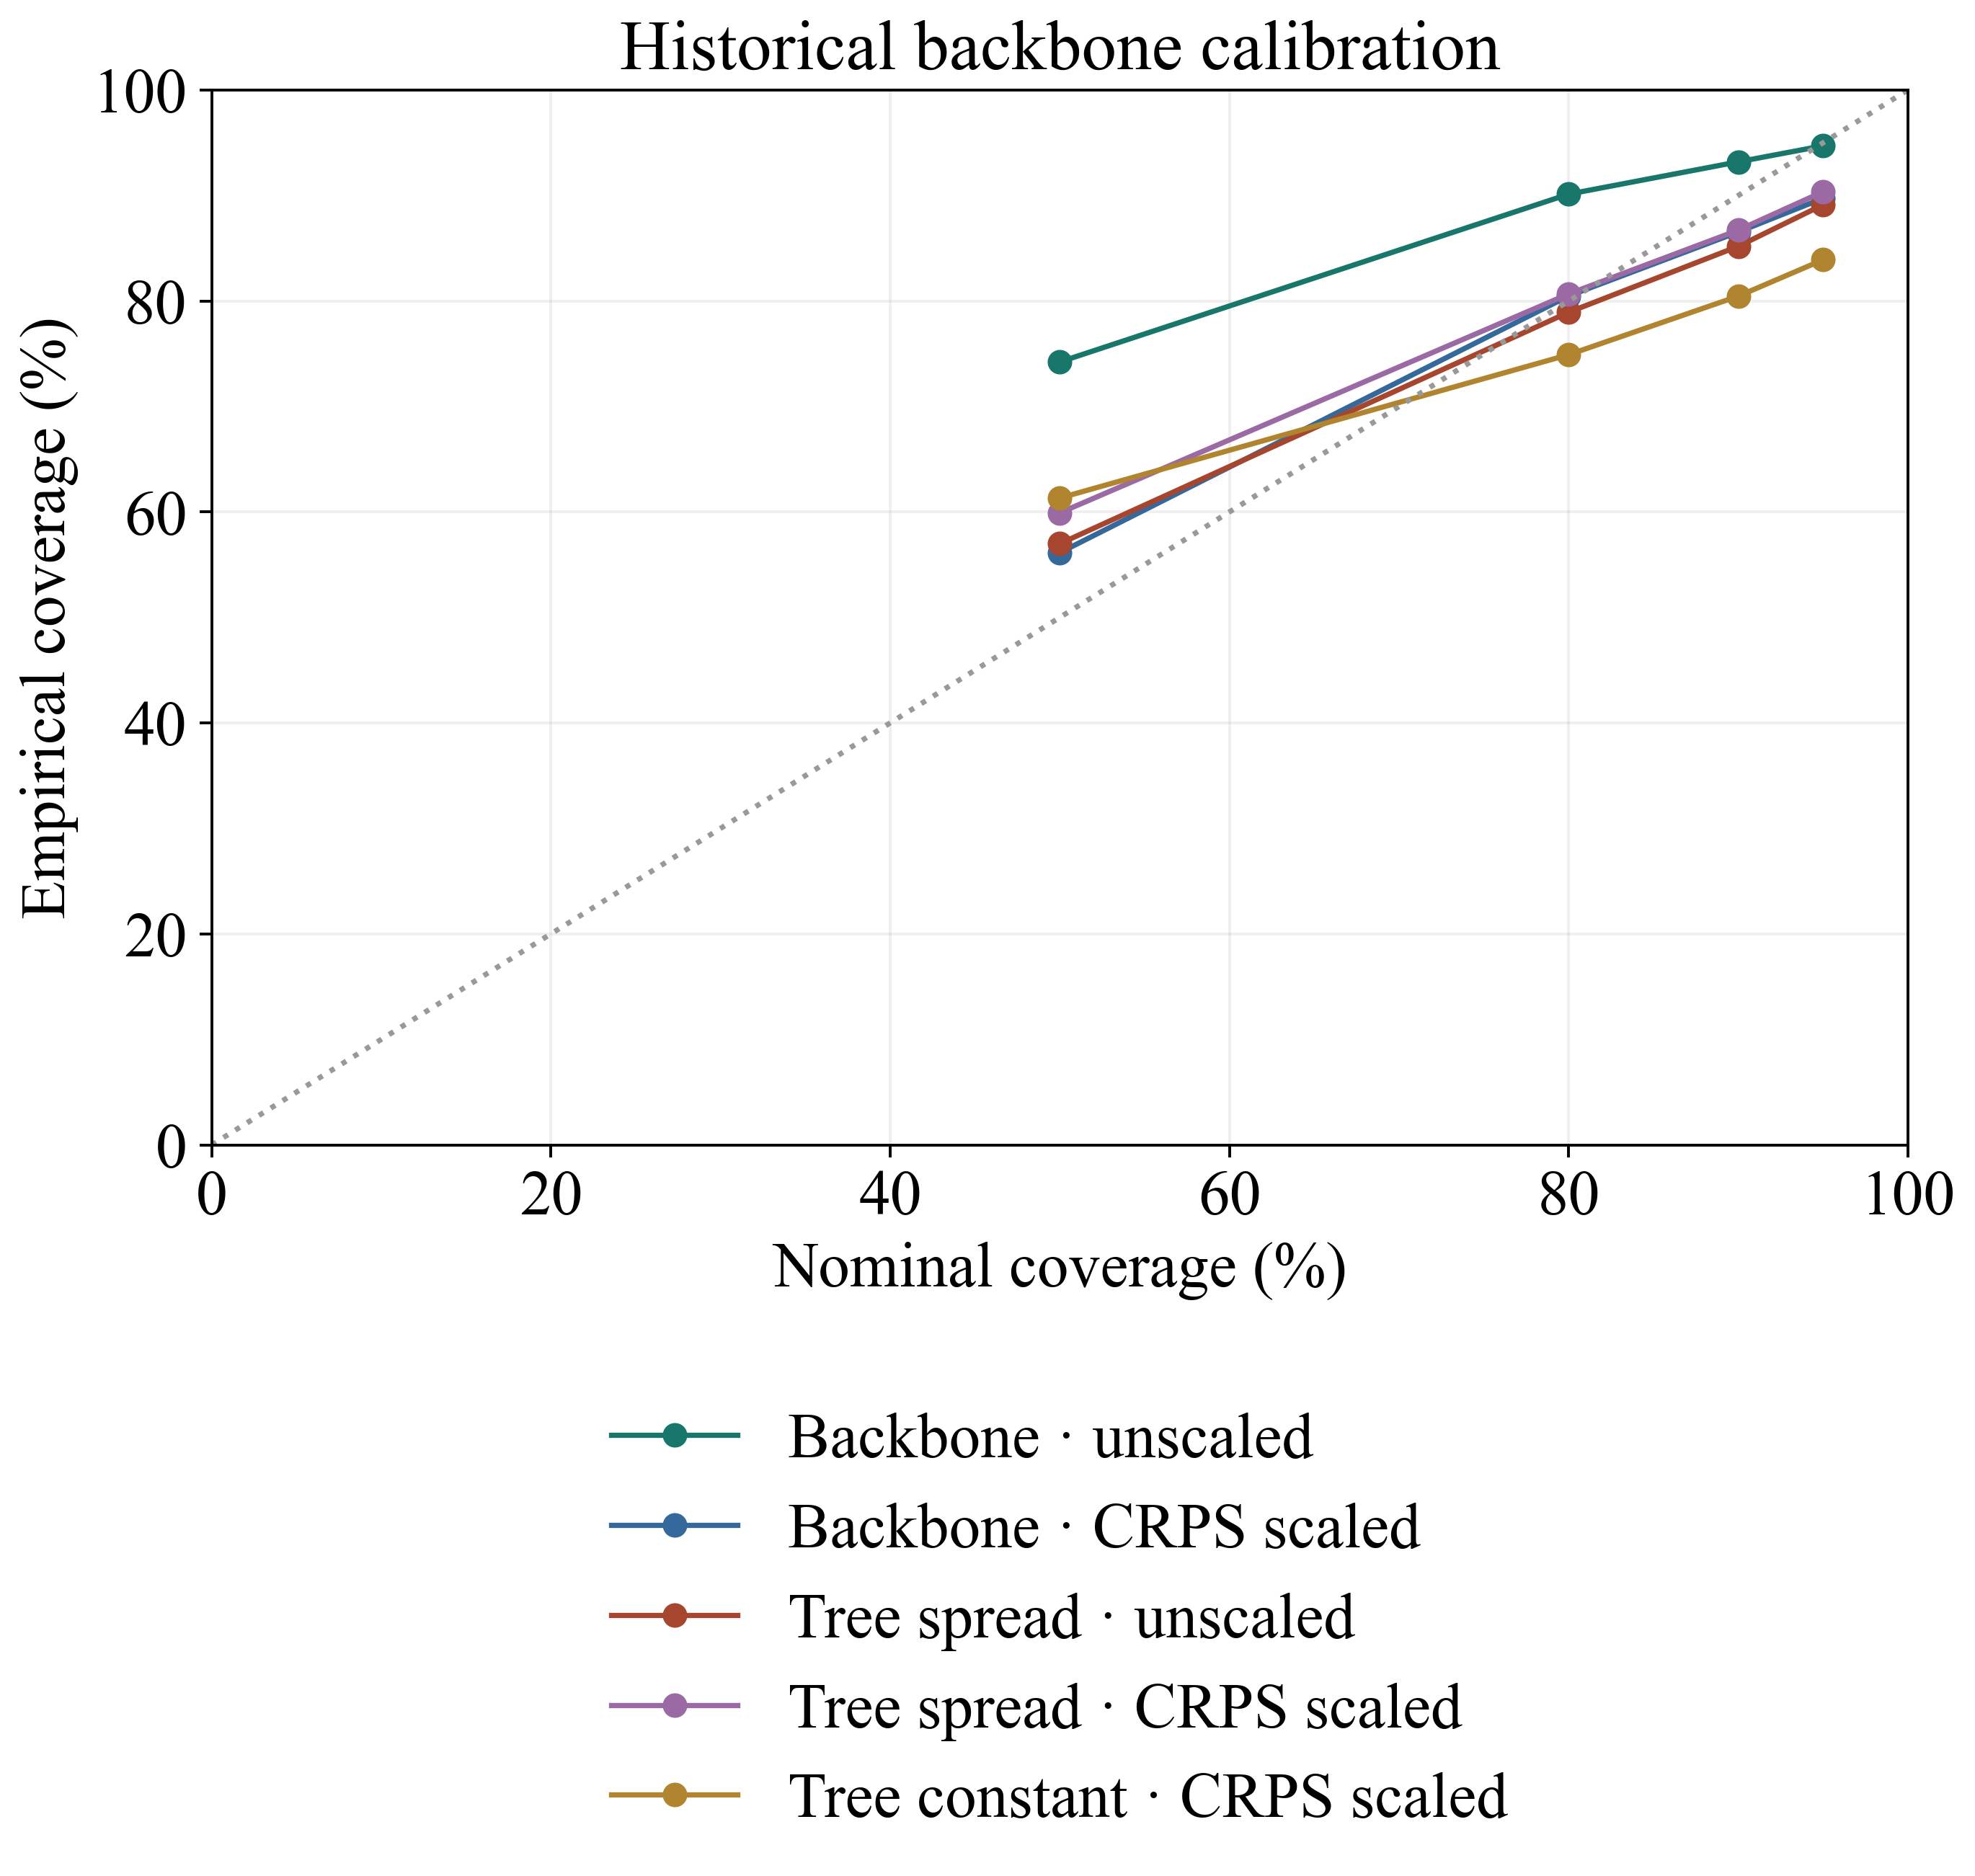

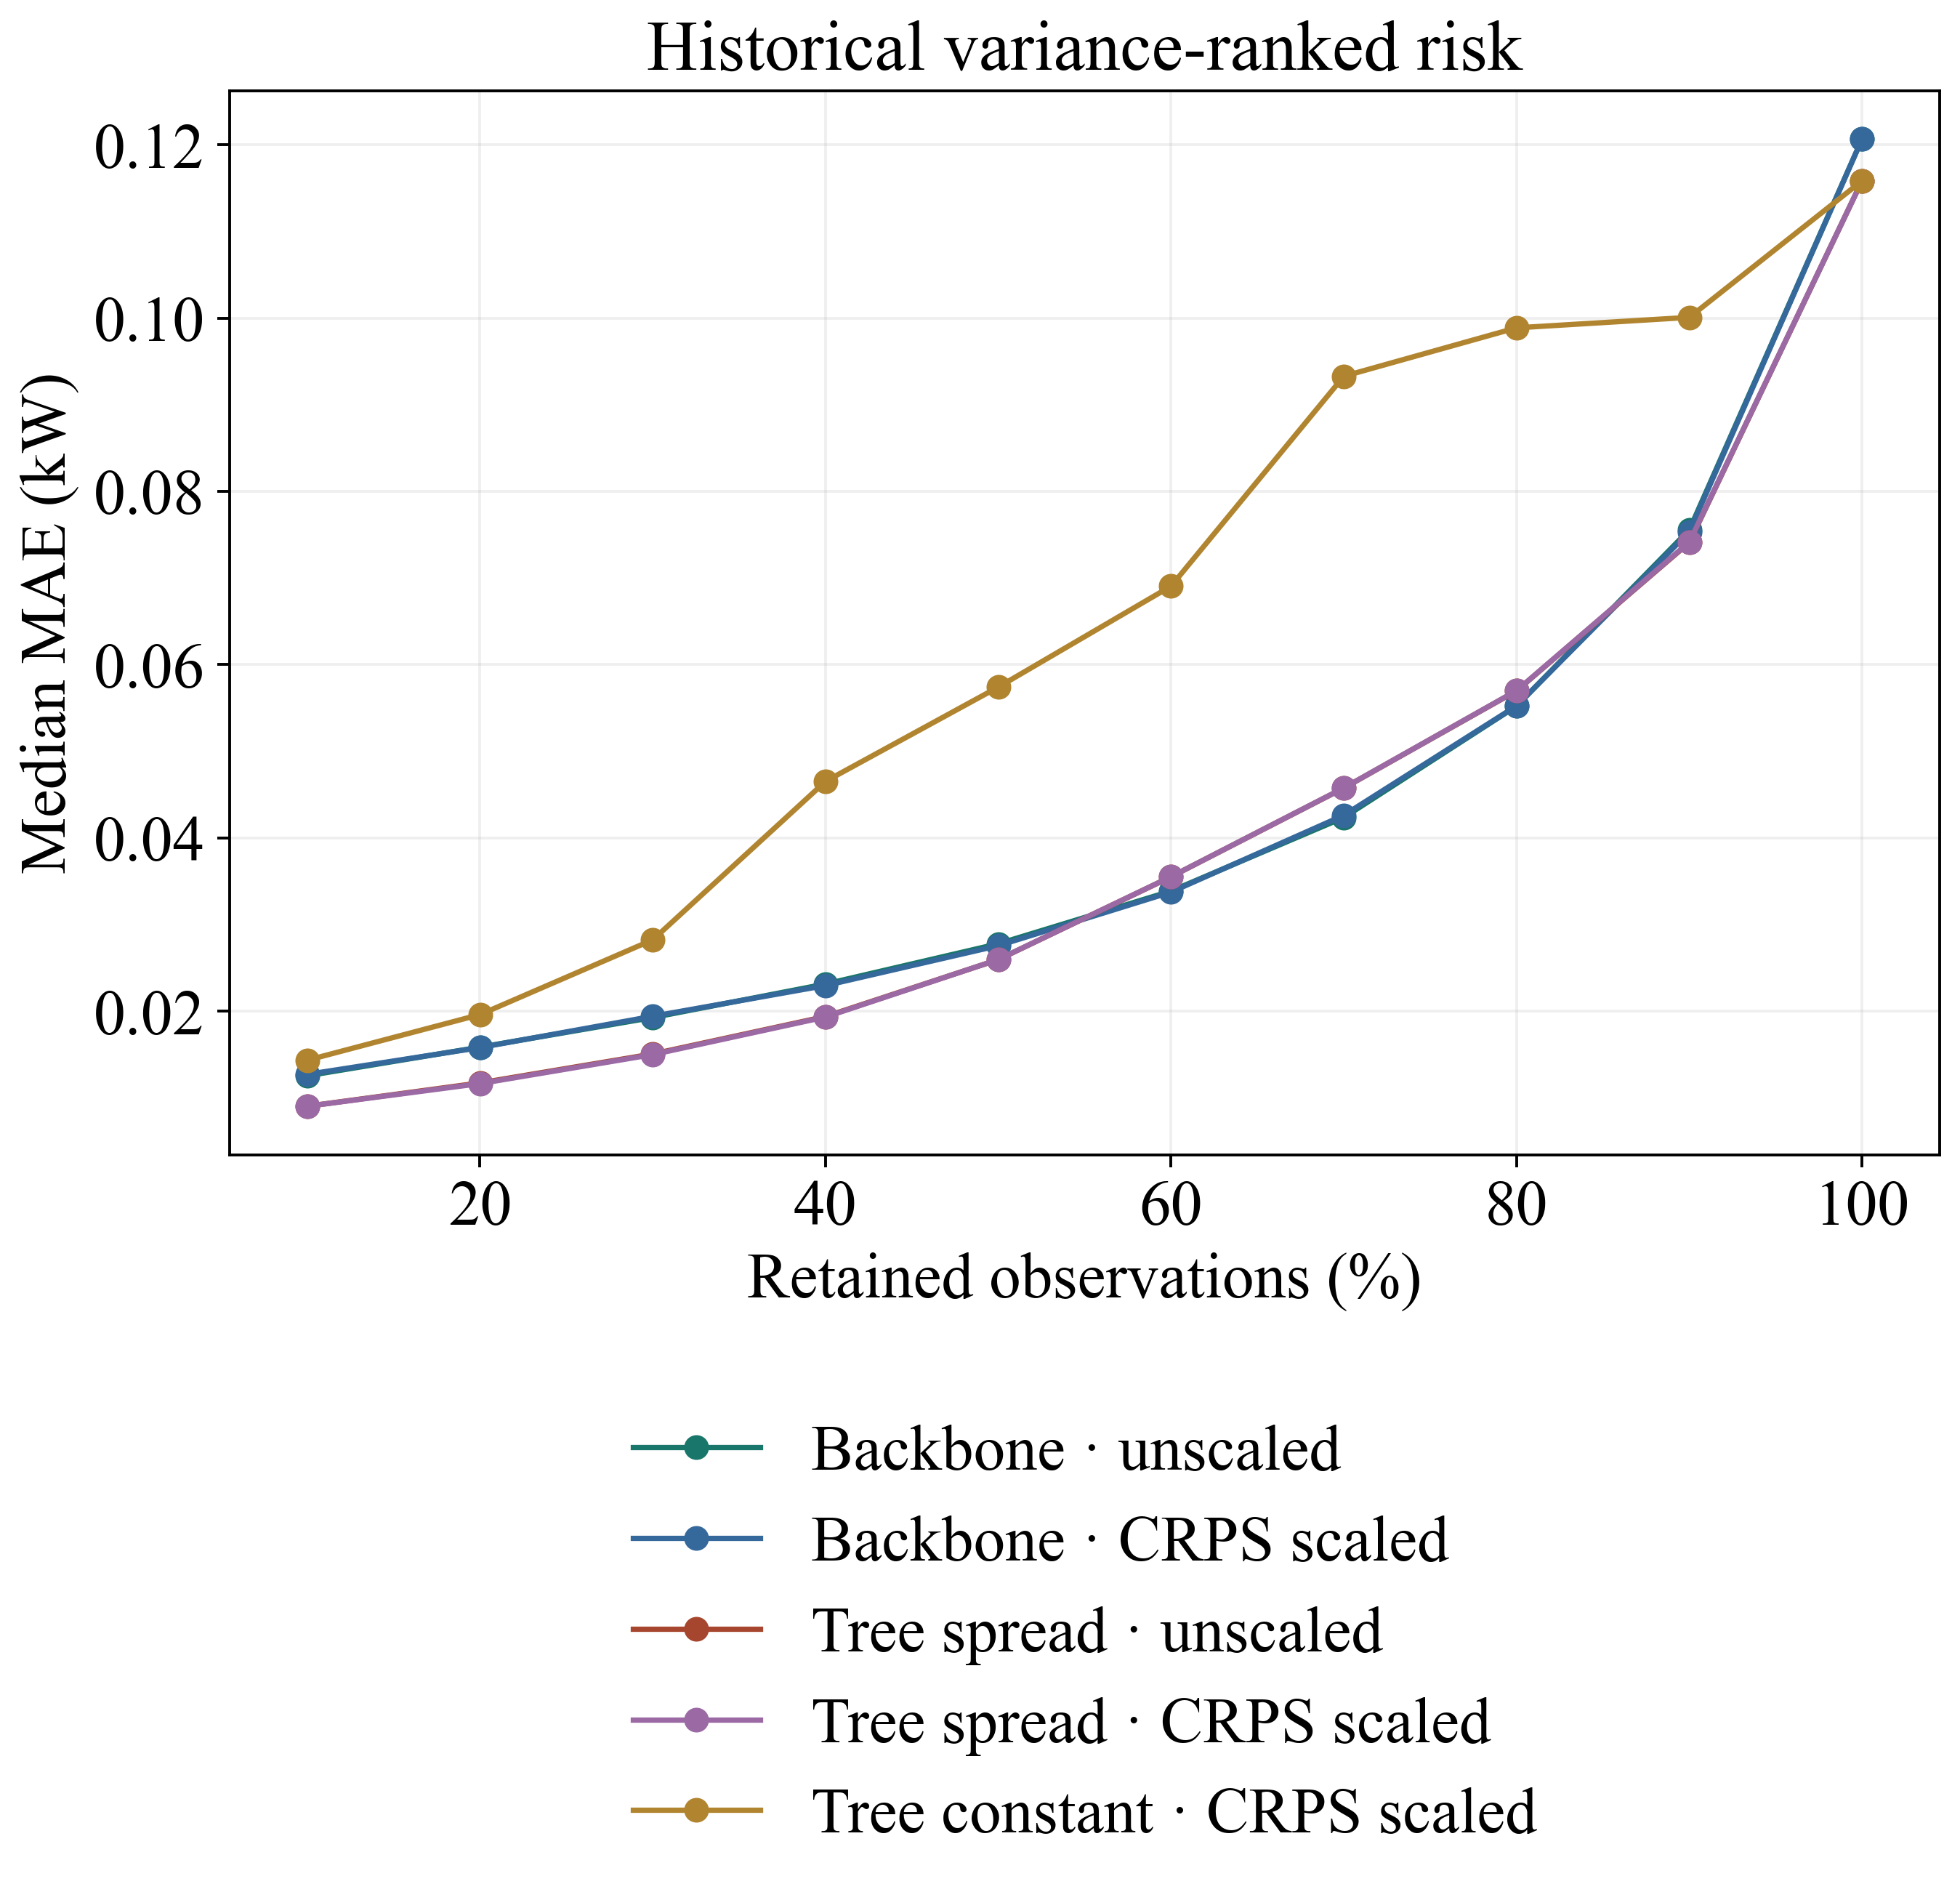

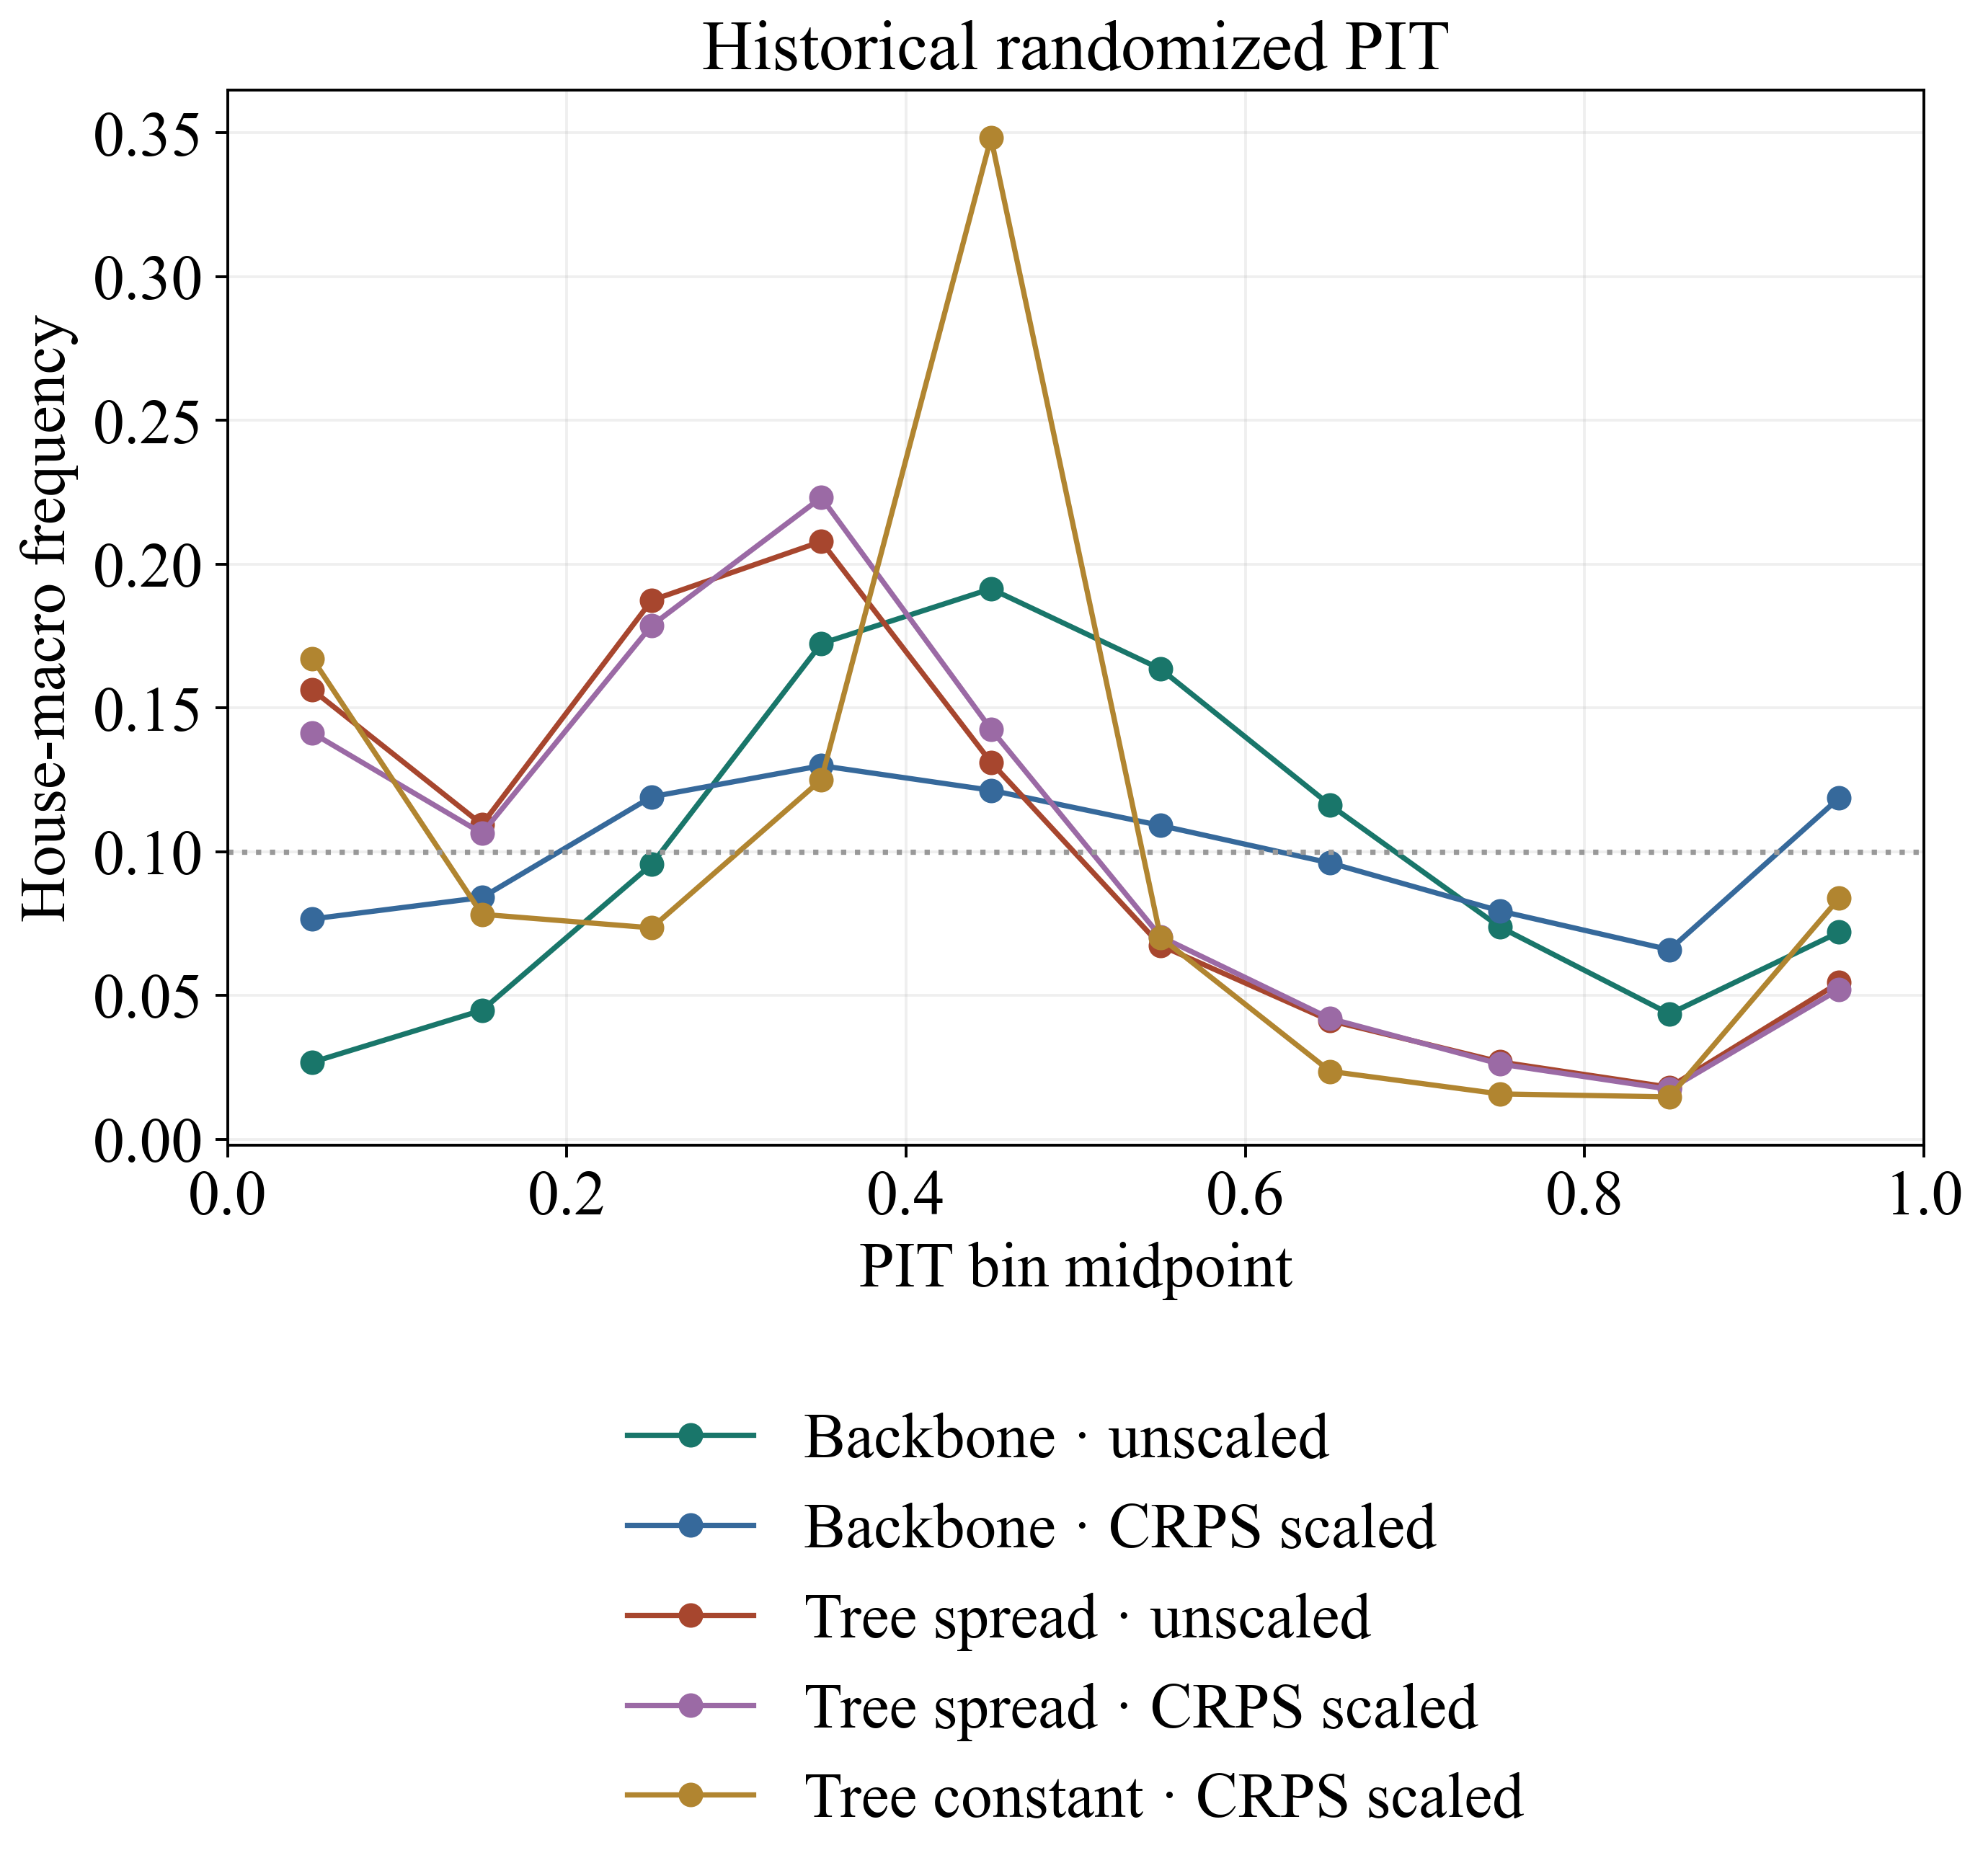

In [2]:
def render_presentation_nb05_probability():
    # Presentation only: exact saved summaries; no fitting or per-query metric calculation.
    from pathlib import Path
    import hashlib
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown, HTML
    from PIL import Image as PILImage
    ROOT = Path.cwd()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    PRESENTATION_RUN = "guldana_n3_20261011_presentation"
    _font = font_manager.findfont("Times New Roman", fallback_to_default=False)
    assert Path(_font).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42})
    def read_presentation_csv(relative):
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == INPUT_SHA256[relative], relative
        return pd.read_csv(path)
    def save_presentation(fig, name):
        fig.canvas.draw()
        for item in fig.findobj(Text):
            if item.get_visible() and item.get_text().strip():
                assert 18 <= item.get_fontsize() <= 20
                actual = font_manager.FontProperties(fname=font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)).get_name()
                assert actual == "Times New Roman"
        for kind in ["PNG", "PDF"]:
            directory = ROOT / "Figures" / kind / PRESENTATION_RUN
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (name + "." + kind.lower()), dpi=350, bbox_inches="tight", pad_inches=.08)
        png = ROOT / "Figures/PNG" / PRESENTATION_RUN / (name + ".png")
        with PILImage.open(png) as raster:
            assert all(abs(value - 350) < .02 for value in raster.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    INPUT_SHA256 = {'Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_intervals.csv': '92fe54d483a170e8b9e5318082b88049d3abc3b27a2f4f688bc25af1cef58973', 'Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_selective_house_curves.csv': 'bab825cf6654c03f1ae059b539ce9f66f2289120419d7c0d1e055d7eb99e74e9', 'Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_PIT_house_bins.csv': 'b3ab08cc17316431ca51abb10896d241efd5598aa94a0c124ea091a378e79f09'}

    intervals_saved = read_presentation_csv("Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_intervals.csv")
    selective_saved = read_presentation_csv("Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_selective_house_curves.csv")
    pit_saved = read_presentation_csv("Tables/guldana_n3_20261009_v02/05_complete_components/uncertainty_v2_PIT_house_bins.csv")
    # Exactly the five distinct distributions plotted previously: the withdrawn second revision maps selected to reference.
    variants = [("reference censor unscaled", "Backbone · unscaled"),
        ("reference censor inner-CRPS", "Backbone · CRPS scaled"),
        ("tree spread censor unscaled", "Tree spread · unscaled"),
        ("tree spread censor inner-CRPS", "Tree spread · CRPS scaled"),
        ("tree constant censor inner-CRPS", "Tree constant · CRPS scaled")]
    assert set(value for value, _ in variants).issubset(set(intervals_saved.Variant))
    colors = ["#19766A", "#36699B", "#A7462E", "#9B6AA5", "#B18530"]
    for kind, name, title, xlabel, ylabel in [
        ("calibration", "NB05_historical_calibration", "Historical backbone calibration", "Nominal coverage (%)", "Empirical coverage (%)"),
        ("selective", "NB05_historical_selective_risk", "Historical variance-ranked risk", "Retained observations (%)", "Median MAE (kW)"),
        ("pit", "NB05_historical_PIT", "Historical randomized PIT", "PIT bin midpoint", "House-macro frequency")]:
        fig, ax = plt.subplots(figsize=(8.2, 8.2))
        for (variant, label), color in zip(variants, colors):
            if kind == "calibration":
                values = intervals_saved.loc[intervals_saved.Variant.eq(variant)].groupby("Nominal coverage (%)")[["Empirical coverage (%)", "Mean width (kW)"]].mean()
                x, y = values.index, values["Empirical coverage (%)"]
            elif kind == "selective":
                values = selective_saved.loc[selective_saved.Variant.eq(variant)].groupby("Requested fraction")[["Actual fraction", "Median MAE (kW)"]].mean()
                x, y = 100 * values["Actual fraction"], values["Median MAE (kW)"]
            else:
                values = pit_saved.loc[pit_saved.Variant.eq(variant)].groupby("PIT lower").Frequency.mean()
                x, y = values.index + .05, values.values
            assert len(x) > 0
            ax.plot(x, y, marker="o", color=color, label=label)
        if kind == "calibration":
            ax.plot([0, 100], [0, 100], color=".6", ls=":"); ax.set(xlim=(0, 100), ylim=(0, 100))
        elif kind == "pit":
            ax.axhline(.1, color=".6", ls=":"); ax.set(xlim=(0, 1))
        ax.set(title=title, xlabel=xlabel, ylabel=ylabel); ax.grid(alpha=.2)
        ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), ncol=1, frameon=False)
        fig.subplots_adjust(left=.15, right=.97, top=.91, bottom=.40)
        save_presentation(fig, name)

render_presentation_nb05_probability()


In [38]:
selected_law=actual_uncertainty_variant("selected censor unscaled")
selected_score=uncertainty_summary.set_index("Variant").loc[selected_law]
calibrated_score=uncertainty_summary.set_index("Variant").loc[actual_uncertainty_variant("selected censor inner-CRPS")]
supported=probability_statistics.loc[(probability_statistics["CRPS difference (kW)"]<0)&(probability_statistics["Holm p"]<.05)]
adverse=probability_statistics.loc[(probability_statistics["CRPS difference (kW)"]>0)&(probability_statistics["Holm p"]<.05)]
probability_text=("### Probability interpretation\n\n"
    +("The registered second revision was accepted on its matched inner criterion. " if revision2_accepted else "The second revision was withdrawn before execution; the selected model remains the original temporal reference. ")
    +f"Its unscaled censored distribution has mean OOF CRPS **{selected_score.CRPS_kW:.6f} kW**, 95% interval coverage **{selected_score.Coverage95_percent:.2f}%**, "
     f"and mean width **{selected_score.Width95_kW:.6f} kW**. Inner-CRPS scaling changes these to CRPS **{calibrated_score.CRPS_kW:.6f} kW**, "
     f"coverage **{calibrated_score.Coverage95_percent:.2f}%**, width **{calibrated_score.Width95_kW:.6f} kW**. "
     f"Among four non-self contrasts, {len(supported)} favor the selected law and {len(adverse)} favor its control with Holm p < 0.05. "
     "Every compact-scope contrast, including adverse results, is retained; the original six-test Holm family is conservatively preserved.\n\n"
     "A censor-only gain is not an architectural gain. CRPS, interval coverage and width must be considered jointly; high coverage alone can result from excessively wide intervals. "
     "Gaussian constant-scale controls tie in variance; censoring can introduce mean-dependent physical-variance ranking, not learned heteroscedastic uncertainty. Identity hashes break remaining ties. PIT and selective-risk curves are descriptive under serial dependence. Variance-ranked subsets differ between models but their complete available cohorts and retention fractions match. "
     "These are development diagnostics using inner data that also selected checkpoints. They do not establish independent calibration or external superiority.")
display(Markdown(probability_text));(V2_TABLES/"uncertainty_v2_interpretation.md").write_text(probability_text+"\n");



### Probability interpretation

The selected model is the original temporal reference. Its unscaled censored distribution has mean OOF CRPS **0.099700 kW**, 95% interval coverage **94.71%**, and mean width **0.530239 kW**. Inner-CRPS scaling changes these to CRPS **0.098600 kW**, coverage **89.73%**, width **0.362724 kW**. Among four non-self contrasts, 0 favor the selected law and 3 favor its control with Holm p < 0.05. Every contrast, including adverse results, is reported; the original six-test Holm family is conservatively retained.

A censor-only gain is not an architectural gain. CRPS, interval coverage and width must be considered jointly; high coverage alone can result from excessively wide intervals. Gaussian constant-scale controls tie in variance; censoring can introduce mean-dependent physical-variance ranking, not learned heteroscedastic uncertainty. Identity hashes break remaining ties. PIT and selective-risk curves are descriptive under serial dependence. Variance-ranked subsets differ between models but their complete available cohorts and retention fractions match. These are development diagnostics using inner data that also selected checkpoints. They do not establish independent calibration or an external advantage.

In [39]:
def replay_complete_component_states():
    evidence = []
    variants = ['temporal_only', 'pooled_set']
    for fold in [1, 2, 3]:
        for seed in [17, 43, 101]:
            cache = NeuralInputCache(fold, seed)
            outer = np.flatnonzero(cache.metadata.role.eq('outer_validation').to_numpy())
            assert len(outer) == 40960
            for variant in variants:
                stem = f'Proposed_{variant}_fold_{fold}_seed_{seed}'
                old_dir = ROOT / 'Models/proposed' / OLD_RUN
                historical = (old_dir / f'{stem}_complete.json').exists()
                directory = old_dir if historical else PROPOSED_DIR
                predictions = ROOT / 'Predictions/development_proposed' / OLD_RUN if historical else PROPOSED_PRED_DIR
                record_path = directory / f'{stem}_complete.json'
                record = json.loads(record_path.read_text())
                checkpoint = directory / f'{stem}.pt'
                prediction_path = predictions / f'{stem}.parquet'
                assert file_sha256(checkpoint) == record['checkpoint_sha256'] and file_sha256(prediction_path) == record['prediction_sha256']
                source_pid = record.get('OOF_generation_kernel_pid', record.get('original_kernel_pid'))
                assert source_pid is not None and source_pid != os.getpid(), 'Restart the kernel and replay definitions before this verification cell; do not refit.'
                proof_path = V2_RECORD / f'fresh_component_replay_{stem}.json'
                if proof_path.exists():
                    proof = json.loads(proof_path.read_text())
                    assert proof['checkpoint_sha256'] == record['checkpoint_sha256'] and proof['prediction_sha256'] == record['prediction_sha256']
                    assert proof['state_sha256'] == record['state_sha256'] == file_sha256(predictions / f'{stem}_state.npz')
                    assert proof['replay_kernel_pid'] != proof['source_kernel_pid'] and proof['maximum_point_difference'] == 0
                    evidence.append(proof)
                    continue
                configuration = record['parameters']
                started = time.perf_counter()
                if historical:
                    bundle = torch.load(checkpoint, map_location='cpu', weights_only=True)
                    model = SensorSetGaussianCandidate(**configuration).to(DEVICE)
                    model.load_state_dict(bundle['state_dict'])
                    model.eval()
                else:
                    model = restore_proposed_checkpoint(checkpoint, configuration)
                saved = pd.read_parquet(prediction_path)
                np.testing.assert_array_equal(cache.metadata.iloc[outer].observation_id, saved.observation_id)
                prediction, variance, state = predict_proposed(model, cache, outer, configuration, DEVICE, 'Independent full posterior replay')
                np.testing.assert_array_equal(prediction, saved.prediction_kW.to_numpy())
                variance_column = 'variance_kW2'
                np.testing.assert_array_equal(variance, saved[variance_column].to_numpy())
                state_path = predictions / f'{stem}_state.npz'
                state_digest = file_sha256(state_path)
                assert state_digest == record['state_sha256']
                with np.load(state_path, allow_pickle=False) as original:
                    for key in state:
                        np.testing.assert_array_equal(state[key], original[key])
                del state
                proof = {'variant': variant, 'fold': fold, 'seed': seed, 'checkpoint_sha256': record['checkpoint_sha256'], 'prediction_sha256': record['prediction_sha256'], 'state_sha256': state_digest, 'source_kernel_pid': source_pid, 'replay_kernel_pid': os.getpid(), 'queries': 40960, 'maximum_point_difference': 0.0, 'complete_state_exact': variant != 'TCN_capacity_context', 'seconds': time.perf_counter() - started, 'status': 'fresh_kernel_full_replay_passed'}
                proof_path.write_text(json.dumps(proof, indent=2) + '\n')
                evidence.append(proof)
                del model, saved
                gc.collect()
                if str(DEVICE) == 'mps':
                    torch.mps.empty_cache()
            del cache
            gc.collect()
    frame = pd.DataFrame(evidence)
    assert len(frame) == len(variants) * 9
    v2_table(frame.groupby('variant', sort=False, as_index=False).agg(Fits=('seed', 'size'), Queries=('queries', 'sum'), Maximum_point_difference=('maximum_point_difference', 'max'), Replay_seconds=('seconds', 'sum')), 'component_fresh_kernel_replay_summary', 'Independent-kernel full OOF replay of every fitted component, including complete Gaussian joint states where defined. No optimizer runs in this verification.', precision=6)
    return evidence


## Causal pattern residual adapter

**Scope.** All previously viewed test sets, including UK-DALE, are retrospective for this model. The locked splits are unchanged.

**Hypothesis.** The development model has negative bias and excessive short-gap error. A small supervised correction head can make recent level, freshness and changes of load directly available to an absolute-error objective. It learns which patterns matter; no prediction weights or offsets are adjusted by hand. The original network and Gaussian state are frozen. This is a different hypothesis from the rejected fixed prior-mean anchor.

Let $\mathcal F_t$ contain only the permitted masked observations, $m_0(\mathcal F_t)$ be the frozen reconstruction, and $z_t$ its raw features plus $m_0$, its standard deviation, and innovations such as $P_{last}-m_0$ and $\bar P_{15}-\bar P_{60}$. Fit
$$\hat h=\operatorname{HGB}_{\mathcal H}\left[\min_h\sum_{i\in T}w_i\left|(y_i-m_0(z_i))-h(z_i)\right|\right],\qquad \hat y_i=\max(0,m_0(z_i)+\hat h(z_i)).$$
Here $w_i=|T|/(Hn_{h(i)})$ gives equal total training weight to each house. HGB is a finite greedy approximation, not a global optimizer. Learning rate and tree limits are fixed before fitting. For any nonnegative target, projection onto $[0,\infty)$ cannot increase absolute or squared point error: if the unprojected value is negative, its distance to $y\ge0$ is reduced by replacing it with zero. This does not establish lower expected error versus another model. All input transformations are measurable with respect to $\mathcal F_t$; the head introduces no new observations.

**Attribution.** The no-pattern control zeros the recent-aggregate and innovation slots, with identical nominal tree limits, rows and objective. Actual leaves and time are reported. This controls the added pattern pathway, not exact effective capacity or the necessity of every neural component. Residual learning, boosting and physical projection are known techniques. The corrected scalar estimate is not automatically a coherent replacement of the old joint Gaussian state, and old probability/acquisition gains cannot be transferred to it.

In [4]:
# Registered, bounded experiment. All scientific fit/predict operations run in this notebook.
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
R3="guldana_n3_20261011_v03"
R3_RECORD=ROOT/"Manifests/Runs"/R3
R3_MODEL=ROOT/"Models/proposed"/R3
R3_PRED=ROOT/"Predictions/development_proposed"/R3
R3_TABLE=ROOT/"Tables"/R3/"05_pattern_adapter"
for folder in [R3_MODEL,R3_PRED,R3_TABLE]:folder.mkdir(parents=True,exist_ok=True)
R3_PROTOCOL=json.loads((ROOT/"Configs/proposed_revision_03.json").read_text())
R3_PROTOCOL_SHA=file_sha256(ROOT/"Configs/proposed_revision_03.json")
assert R3_PROTOCOL["revision_number"]==3 and R3_PROTOCOL["search_attempts"]+18==24
assert R3_PROTOCOL["parameters"]["early_stopping"] is False
R3_OLD_LOCK=json.loads((ROOT/"Manifests/Runs"/OLD_RUN/"proposed_trial_ledger.json").read_text())
assert len(R3_OLD_LOCK["attempts"])==18
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6

def r3_table(frame,name,caption):
    frame.to_csv(R3_TABLE/f"{name}.csv",index=False)
    frame.to_latex(R3_TABLE/f"{name}.tex",index=False,caption=caption,float_format=lambda v:f"{v:.6f}")
    display(frame.style.format(precision=6,na_rep="Unavailable").hide(axis="index").set_caption(caption))

def r3_metrics(meta,pred):
    e=np.asarray(pred)-meta.y_kW.to_numpy(float)
    a=pd.DataFrame({"house":meta.house.to_numpy(),"abs":abs(e),"sq":e**2,"bias":e}).groupby("house").mean()
    return {"MAE_kW":float(a["abs"].mean()),"RMSE_kW":float(np.sqrt(a.sq).mean()),"Bias_kW":float(a.bias.mean())}

def r3_features(raw,mu,variance,patterns=True):
    # Only frozen audited input columns; metadata and labels never enter this function.
    z=raw.reset_index(drop=True).copy()
    assert not set(z).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    z["frozen_mean"]=mu;z["frozen_sigma"]=np.sqrt(variance)
    z["innovation_last"]=z.aggregate_last-mu
    z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240
    z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    if not patterns:
        removed=[c for c in z if (c.startswith("aggregate_") and c not in {"aggregate_lag_1440","aggregate_lag_10080"}) or c.startswith("innovation_")]
        z.loc[:,removed]=0.
    a=z.to_numpy(dtype=np.float64)
    assert not np.isinf(a).any() and np.isfinite(mu).all() and (np.asarray(variance)>0).all()
    return z

# Recover absent lossless history caches from original measured development rows.
# A complete original-file SHA-256 match is mandatory before any model fitting.
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def prepare_sensor_store(info,mapping,target_scale,fold):
    sensors=["P_agg",*sorted(mapping)]
    environment={}
    for sensor in ["temperature (C)","humidity (%)"]:
        environment[sensor]=(info["values"][sensor].to_numpy(dtype=np.float64,copy=True),
            info["available"][sensor].to_numpy(dtype=bool,copy=True)) if sensor in info["available"] else (
            np.zeros(len(info["values"])),np.zeros(len(info["values"]),dtype=bool))
    store={"raw":info["values"][sensors].to_numpy(dtype=np.float64,copy=True),
        "available":info["available"][sensors].to_numpy(dtype=bool,copy=True),
        "coverage":info["coverage"][sensors].to_numpy(dtype=np.float64,copy=True),
        "observation_ids":info["ids"].observation_id.to_numpy(copy=True),
        "roles":info["ids"][f"fold_{fold}"].to_numpy(copy=True),"timestamps":info["values"].index,
        "environment":environment,"sensors":sensors,"mapping":mapping,"target_scale":float(target_scale),"fold":fold}
    for key in ["raw","available","coverage","observation_ids","roles"]:store[key].flags.writeable=False
    for arrays in environment.values():
        for array in arrays:array.flags.writeable=False
    return store

def vector_sensor_batch(store,queries,aggregate_gaps,auxiliary_retentions,modes,seed=17):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    history_minutes=360; sensor_order=None
    aggregate_gaps=np.asarray(aggregate_gaps,dtype=int)
    auxiliary_retentions=np.asarray(auxiliary_retentions,dtype=float)
    modes=np.asarray(modes,dtype=str)
    assert len(queries)==len(aggregate_gaps)==len(auxiliary_retentions)==len(modes)
    assert set(modes)<= {"point","block","sensor_dropout","mixed"}
    assert ((aggregate_gaps>=1)&(aggregate_gaps<=360)).all()
    assert ((auxiliary_retentions>=0)&(auxiliary_retentions<=1)).all()
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        gap=int(aggregate_gaps[b]);mode=str(modes[b]);auxiliary_retention=float(auxiliary_retentions[b])
        if gap>1:hmask[b,aggregate_index,-(gap-1):]=False
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


R3_SOURCE_STORE={}
def sensor_store(fold,house):
    key=(int(fold),int(house))
    if key not in R3_SOURCE_STORE:
        R3_SOURCE_STORE.clear();gc.collect()
        path=REFINED/f"plegma_house_{house:02d}.parquet"
        gate=json.loads((ROOT/"Manifests/nb01_gate.json").read_text())
        assert file_sha256(path)==gate["refined_files"][str(path.relative_to(ROOT))]
        data=pd.read_parquet(path)
        ids=pd.read_parquet(ROOT/f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
        ids=ids.loc[ids.split.eq("development")].set_index("timestamp")
        info={"ids":ids,"values":data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index),
            "available":data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool),
            "coverage":data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)}
        R3_SOURCE_STORE[key]=prepare_sensor_store(info,duplicate_maps[fold][house],preprocessors[fold].state["target_scale"],fold)
    return R3_SOURCE_STORE[key]

def neural_observation_batch(metadata,fold,history_minutes=360,include_targets=False):
    assert 1<=history_minutes<=360 and len(metadata)>0
    frame=metadata.reset_index(drop=True)
    if "fold" in frame:assert frame.fold.eq(fold).all()
    max_sensors=max(1+len(duplicate_maps[fold][int(h)]) for h in frame.house.unique())
    size=len(frame)
    inputs={"history":np.zeros((size,max_sensors,history_minutes,4),dtype=np.float32),
        "current_values":np.zeros((size,max_sensors),dtype=np.float32),
        "current_mask":np.zeros((size,max_sensors),dtype=bool),
        "installed":np.zeros((size,max_sensors),dtype=bool),
        "type_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "role_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "unit_ids":np.zeros((size,max_sensors),dtype=np.int64),
        "context":np.zeros((size,14),dtype=np.float32)}
    inputs["history"][:,:,:,3]=1.
    labels={"values":np.zeros((size,max_sensors),dtype=np.float64),
            "observed":np.zeros((size,max_sensors),dtype=bool)} if include_targets else None
    names=[None]*size
    for house,positions in frame.groupby("house",sort=True).groups.items():
        positions=np.asarray(positions,dtype=int);part=frame.iloc[positions]
        source=sensor_store(fold,int(house));queries=part.row_position.to_numpy(dtype=int)
        assert np.array_equal(source["observation_ids"][queries],part.observation_id.to_numpy())
        assert part.seed.nunique()==1
        observed=vector_sensor_batch(source,queries,part.gap.to_numpy(dtype=int),
            part.retention.to_numpy(dtype=float),part["mode"].to_numpy(),seed=int(part.seed.iloc[0]))
        seen=set(preprocessors[fold].state["seen_power_types"])
        # Metadata-only ordering provides a reproducible dense view; no load values determine position.
        ordering=sorted(range(len(observed["sensor_names"])),key=lambda j:(
            int(observed["role_ids"][j]),int(observed["type_ids"][j]),observed["sensor_names"][j]))
        count=len(ordering)
        mapped_types=np.array([int(observed["type_ids"][j]) if schema["power_types"][int(observed["type_ids"][j])] in seen
            else schema["power_types"].index("unknown") for j in ordering],dtype=np.int64)
        inputs["history"][positions,:count]=observed["history"][:,ordering,-history_minutes:,:]
        for field in ["current_values","current_mask"]:
            inputs[field][positions,:count]=observed[field][:,ordering]
        inputs["installed"][positions,:count]=True
        inputs["type_ids"][positions,:count]=mapped_types
        inputs["role_ids"][positions,:count]=observed["role_ids"][ordering]
        inputs["unit_ids"][positions,:count]=observed["unit_ids"][ordering]
        inputs["context"][positions]=observed["context"]
        ordered_names=[observed["sensor_names"][j] for j in ordering]
        for position in positions:names[position]=ordered_names
        if include_targets:
            # Only this branch reads the current reference targets, after observed inputs are constructed.
            original=source["raw"][queries][:,ordering]/source["target_scale"]
            mask=source["available"][queries][:,ordering]
            labels["values"][positions,:count]=np.where(mask,original,0.)
            labels["observed"][positions,:count]=mask
    assert (inputs["role_ids"][:,0]==0).all() and inputs["installed"][:,0].all()
    assert not inputs["current_mask"][:,0].any() and not inputs["current_values"][:,0].any()
    assert np.isfinite(inputs["history"]).all() and np.isfinite(inputs["current_values"]).all()
    assert np.isfinite(inputs["context"]).all()
    assert not inputs["current_mask"][~inputs["installed"]].any()
    return inputs,labels,names


def r3_restore_history(fold,seed):
    folder=NEURAL_CACHE/f"fold_{fold}_seed_{seed}"
    record=json.loads((folder/"manifest.json").read_text())
    expected=next(a for a in record["arrays"] if a["name"]=="history.npy")
    path=folder/"history.npy"
    if path.exists():
        assert path.stat().st_size==expected["bytes"] and file_sha256(path)==expected["sha256"]
        return
    metadata=pd.read_parquet(CACHE/f"fold_{fold}_seed_{seed}.parquet")
    assert file_sha256(CACHE/f"fold_{fold}_seed_{seed}.parquet")==record["metadata_sha256"]
    size=len(metadata);shape=(size,record["maximum_sensors"],360,4)
    temporary=folder/"history.rebuilding.npy"
    assert not temporary.exists(),"Retain incomplete reconstruction for inspection before restart."
    array=np.lib.format.open_memmap(temporary,mode="w+",dtype=np.float32,shape=shape)
    live=display(Markdown(f"Recovering original history · fold {fold}, seed {seed}"),display_id=True)
    started=time.perf_counter()
    for offset in range(0,size,256):
        stop=min(size,offset+256)
        inputs,_,_=neural_observation_batch(metadata.iloc[offset:stop],fold,include_targets=False)
        width=inputs["history"].shape[1]
        array[offset:stop]=0;array[offset:stop,:,:,3]=1;array[offset:stop,:width]=inputs["history"]
        if offset%16384==0 or stop==size:live.update(Markdown(f"Recovering original history · fold {fold}, seed {seed}: {stop:,} / {size:,}"))
    array.flush();del array;R3_SOURCE_STORE.clear();gc.collect()
    assert temporary.stat().st_size==expected["bytes"]
    digest=file_sha256(temporary)
    assert digest==expected["sha256"],"Historical cache parity failed; no fitting allowed."
    temporary.rename(path)
    (R3_RECORD/f"history_recovery_fold_{fold}_seed_{seed}.json").write_text(json.dumps({"path":str(path.relative_to(ROOT)),
        "sha256":digest,"matched_original_manifest":True,"rows":size,"seconds":time.perf_counter()-started},indent=2)+"\n")
    live.update(Markdown(f"History restored · fold {fold}, seed {seed}: **complete original SHA-256 match**."))

@torch.no_grad()
def r3_base_predictions(fold,seed):
    path=R3_PRED/f"frozen_base_fold_{fold}_seed_{seed}.parquet"
    proof=path.with_suffix(".json")
    checkpoint=ROOT/"Models/proposed"/OLD_RUN/f"Proposed_temporal_only_fold_{fold}_seed_{seed}.pt"
    complete=json.loads(checkpoint.with_name(checkpoint.stem+"_complete.json").read_text())
    assert file_sha256(checkpoint)==complete["checkpoint_sha256"]
    if proof.exists():
        record=json.loads(proof.read_text());assert record["checkpoint_sha256"]==complete["checkpoint_sha256"]
        assert file_sha256(path)==record["prediction_sha256"]
        return pd.read_parquet(path)
    r3_restore_history(fold,seed)
    cache=NeuralInputCache(fold,seed)
    bundle=torch.load(checkpoint,map_location="cpu",weights_only=True)
    config=bundle["parameters"]
    model=SensorSetGaussianCandidate(**config).to(DEVICE);model.load_state_dict(bundle["state_dict"]);model.eval()
    rows=np.flatnonzero(cache.metadata.role.ne("outer_validation").to_numpy())
    mu=np.empty(len(cache.metadata));var=np.empty_like(mu)
    started=time.perf_counter()
    progress=display(Markdown(f"Frozen encoder · fold {fold}, seed {seed}: 0 / {len(rows)}"),display_id=True)
    for offset in range(0,len(rows),32):
        chosen=rows[offset:offset+32];inp,_=cache.batch(chosen,config["history"],DEVICE)
        flags=proposed_balance_flags(cache.metadata.iloc[chosen],fold,DEVICE,cache.measurement_contract)
        out=model(inp,flags);scale=preprocessors[fold].state["target_scale"]
        mu[chosen]=out["prediction"].cpu().numpy().astype(float)*scale
        var[chosen]=out["target_variance"].cpu().numpy().astype(float)*scale**2
        if offset%8192==0 or offset+32>=len(rows):progress.update(Markdown(f"Frozen encoder · fold {fold}, seed {seed}: {min(offset+32,len(rows)):,} / {len(rows):,}"))
    historical=ROOT/"Predictions/development_proposed"/OLD_RUN/f"Proposed_temporal_only_fold_{fold}_seed_{seed}.parquet"
    assert file_sha256(historical)==complete["prediction_sha256"]
    old=pd.read_parquet(historical);outer=np.flatnonzero(cache.metadata.role.eq("outer_validation").to_numpy())
    np.testing.assert_array_equal(old.observation_id,cache.metadata.iloc[outer].observation_id)
    mu[outer]=old.prediction_kW;var[outer]=old.variance_kW2
    frame=cache.metadata.copy();frame["base_mean"]=mu;frame["base_variance"]=var
    assert np.isfinite(mu).all() and (var>0).all()
    frame.to_parquet(path,index=False)
    proof.write_text(json.dumps({"checkpoint_sha256":file_sha256(checkpoint),"prediction_sha256":file_sha256(path),
        "cache_manifest_sha256":file_sha256(cache.folder/"manifest.json"),"forward_queries":len(rows),"outer_reused":len(outer),
        "forward_seconds":time.perf_counter()-started,"neural_fit_performed":False},indent=2)+"\n")
    del model,cache;gc.collect();torch.mps.empty_cache()
    return frame

def r3_fit_fold(fold,seed):
    meta=r3_base_predictions(fold,seed)
    record=json.loads((CACHE/f"fold_{fold}_seed_{seed}.json").read_text())
    source=ROOT/record["array_file"];assert file_sha256(source)==record["array_sha256"]
    with np.load(source,allow_pickle=False) as a:raw=pd.DataFrame(a["raw"],columns=a["input_columns"])
    train=meta.role.eq("train").to_numpy();inner=meta.role.eq("inner_validation").to_numpy()
    assert train.sum()==65530 and inner.sum()==10240
    mu=meta.base_mean.to_numpy();variance=meta.base_variance.to_numpy();target=meta.y_kW.to_numpy()-mu
    houses=meta.loc[train,"house"];weight=(len(houses)/(houses.nunique()*houses.map(houses.value_counts()))).to_numpy()
    rows=[]
    for name,patterns in [("Pattern adapter",True),("No-pattern control",False)]:
        tag="pattern" if patterns else "no_pattern";stem=f"{tag}_fold_{fold}_seed_{seed}"
        path=R3_MODEL/f"{stem}.joblib";proof=R3_MODEL/f"{stem}.json"
        z=r3_features(raw,mu,variance,patterns)
        if proof.exists():
            evidence=json.loads(proof.read_text());assert file_sha256(path)==evidence["checkpoint_sha256"]
            assert evidence["protocol_sha256"]==R3_PROTOCOL_SHA and evidence["implementation_sha256"]==R3_IMPL_SHA
            model=joblib.load(path)["model"]
        else:
            started=time.perf_counter();model=HistGradientBoostingRegressor(**R3_PROTOCOL["parameters"],random_state=seed)
            with threadpool_limits(limits=4):model.fit(z.loc[train],target[train],sample_weight=weight)
            fit_seconds=time.perf_counter()-started
            leaves=sum(int(tree.nodes["is_leaf"].sum()) for stage in model._predictors for tree in stage)
            bundle={"model":model,"feature_columns":list(z),"pattern_features":patterns,"base_checkpoint_sha256":json.loads((R3_PRED/f"frozen_base_fold_{fold}_seed_{seed}.json").read_text())["checkpoint_sha256"],"protocol_sha256":R3_PROTOCOL_SHA}
            joblib.dump(bundle,path)
            evidence={"fold":fold,"seed":seed,"variant":name,"fit_seconds":fit_seconds,"actual_leaves":leaves,"maximum_leaves":300*31,
                "fit_rows":int(train.sum()),"inner_rows":int(inner.sum()),"checkpoint_sha256":file_sha256(path),"protocol_sha256":R3_PROTOCOL_SHA,
                "implementation_sha256":R3_IMPL_SHA,"training_ids_sha256":hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest(),"kernel_pid":os.getpid()}
            proof.write_text(json.dumps(evidence,indent=2)+"\n")
        started=time.perf_counter()
        with threadpool_limits(limits=4):correction=model.predict(z)
        p=np.maximum(0,mu+correction)
        with threadpool_limits(limits=4):replay=joblib.load(path)["model"].predict(z.iloc[:128])
        np.testing.assert_array_equal(replay,correction[:128])
        out=meta.loc[:,[c for c in meta if c not in {"base_mean","base_variance"}]].copy()
        out["prediction_kW"]=p;out["uncensored_location_kW"]=mu+correction;out["base_mean_kW"]=mu
        out.to_parquet(R3_PRED/f"{stem}.parquet",index=False)
        evidence.update(prediction_sha256=file_sha256(R3_PRED/f"{stem}.parquet"),prediction_seconds=time.perf_counter()-started,replay_max_difference=0.)
        proof.write_text(json.dumps(evidence,indent=2)+"\n")
        rows.append({"Fold":fold,"Seed":seed,"Model":name,**r3_metrics(meta.loc[inner],p[inner]),"Fit seconds":evidence["fit_seconds"],"Leaves":evidence["actual_leaves"]})
    rows.append({"Fold":fold,"Seed":seed,"Model":"Frozen proposal",**r3_metrics(meta.loc[inner],mu[inner]),"Fit seconds":0.,"Leaves":0})
    result=pd.DataFrame(rows);result.to_csv(R3_TABLE/f"inner_fold_{fold}_seed_{seed}.csv",index=False)
    return result


In [5]:
# Bind the exact visible implementation before the first fit; registration is immutable.
saved=json.loads((ROOT/"Notebooks/05_proposed_model_development_and_ablations.ipynb").read_text())
source={c["id"]:"".join(c["source"]) for c in saved["cells"] if c.get("id") in {"revision3-implementation"}}
assert len(source)==1
R3_IMPL_SHA=hashlib.sha256(json.dumps(source,sort_keys=True).encode()).hexdigest()
path=R3_RECORD/"prefit_implementation.json"
record={"source":source,"implementation_sha256":R3_IMPL_SHA,"protocol_sha256":R3_PROTOCOL_SHA}
if path.exists():assert json.loads(path.read_text())==record
else:path.write_text(json.dumps(record,indent=2)+"\n")
display(Markdown("**Registered:** one residual-pattern hypothesis; 3 folds × 2 heads; 6 search fits, completing the 24-attempt lifetime cap. All head fitting uses training rows only."))


In [10]:
r3_fold_1=r3_fit_fold(1,17)
r3_table(r3_fold_1,"inner_search_fold_1","Complete registered fold 1: train-only correction and matched nominal-capacity control.")
r3_fold_2=r3_fit_fold(2,17)
r3_table(r3_fold_2,"inner_search_fold_2","Complete registered fold 2: train-only correction and matched nominal-capacity control.")
r3_fold_3=r3_fit_fold(3,17)
r3_table(r3_fold_3,"inner_search_fold_3","Complete registered fold 3: train-only correction and matched nominal-capacity control.")


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
1,17,Pattern adapter,0.089393,0.354417,−0.037368,14.364464,9300
1,17,No-pattern control,0.103588,0.362680,−0.040696,9.712301,9300
1,17,Frozen proposal,0.112578,0.375025,−0.038613,0.000000,0


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
2,17,Pattern adapter,0.100872,0.357909,−0.035363,11.596544,9300
2,17,No-pattern control,0.118308,0.360015,−0.042678,10.556140,9300
2,17,Frozen proposal,0.133319,0.382759,−0.040605,0.000000,0


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
3,17,Pattern adapter,0.081149,0.301278,−0.026217,11.610421,9300
3,17,No-pattern control,0.093408,0.312101,−0.029866,10.417089,9300
3,17,Frozen proposal,0.105313,0.321224,−0.027251,0.000000,0


In [11]:
r3_inner=pd.concat([pd.read_csv(R3_TABLE/f"inner_fold_{f}_seed_17.csv") for f in [1,2,3]],ignore_index=True)
r3_means=r3_inner.groupby("Model",sort=False)[["MAE_kW","RMSE_kW","Bias_kW","Fit seconds","Leaves"]].mean()
full=r3_means.loc["Pattern adapter"];base=r3_means.loc["Frozen proposal"];control=r3_means.loc["No-pattern control"]
r3_accepted=bool(full.MAE_kW<=.95*base.MAE_kW and full.MAE_kW<=.99*control.MAE_kW and full.RMSE_kW<=1.05*base.RMSE_kW)
decision={"run_id":R3,"accepted":r3_accepted,"inner_MAE_reduction_vs_base_percent":float(100*(1-full.MAE_kW/base.MAE_kW)),
    "inner_MAE_reduction_vs_control_percent":float(100*(1-full.MAE_kW/control.MAE_kW)),"inner_RMSE_change_vs_base_percent":float(100*(full.RMSE_kW/base.RMSE_kW-1)),
    "completed_search_fits":6,"lifetime_search_fits":24,"protocol_sha256":R3_PROTOCOL_SHA,"implementation_sha256":R3_IMPL_SHA,
    "decision_data":"inner_validation only; no outer/test selection","status":"retained_for_complete_OOF" if r3_accepted else "rejected_no_further_fitting"}
(R3_RECORD/"development_decision.json").write_text(json.dumps(decision,indent=2)+"\n")
r3_table(r3_means.reset_index(),"inner_selection_summary","Registered inner selection, equal weighting of all three folds. Frozen backbone training cost is historical and additional to head cost.")
display(Markdown(f"**Decision: {'retain for complete OOF' if r3_accepted else 'reject; do not promote to final model'}.** MAE reduction versus frozen proposal: {decision['inner_MAE_reduction_vs_base_percent']:.2f}%; versus no-pattern control: {decision['inner_MAE_reduction_vs_control_percent']:.2f}%. This is exploratory development evidence, not test superiority or mathematical novelty."))


Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
Pattern adapter,0.090471,0.337868,−0.032983,12.523810,9300.000000
No-pattern control,0.105101,0.344932,−0.037747,10.228510,9300.000000
Frozen proposal,0.117070,0.359670,−0.035490,0.000000,0.000000


**Decision: retain for complete OOF.** MAE reduction versus frozen proposal: 22.72%; versus no-pattern control: 13.92%. This is exploratory development evidence, not a test-set result.

### Complete OOF evaluation of the retained module

The prespecified inner selection criterion was met. The same two fixed heads now use seeds 43 and 101; there is no new search or configuration choice. Together with seed 17 this gives all three folds and all three seeds. The scalar adapter uses native history summaries (up to the shared permitted causal boundary), while the frozen neural encoder retains its original selected history length. Therefore this is not a same-effective-history attribution experiment. All baseline forecasts are reused.

Gradient-boosted absolute-error regression is an established method; see the [official estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html). The question assessed here is the incremental value of the explicit pattern pathway for this reconstruction problem.

In [14]:
assert r3_accepted
r3_retained_1=[]
for seed in [43,101]:
    r3_retained_1.append(r3_fit_fold(1,seed))
r3_table(pd.concat(r3_retained_1,ignore_index=True),"retained_inner_fold_1","Fixed repeats only; no re-selection from seed-specific outcomes.")
assert r3_accepted
r3_retained_2=[]
for seed in [43,101]:
    r3_retained_2.append(r3_fit_fold(2,seed))
r3_table(pd.concat(r3_retained_2,ignore_index=True),"retained_inner_fold_2","Fixed repeats only; no re-selection from seed-specific outcomes.")
assert r3_accepted
r3_retained_3=[]
for seed in [43,101]:
    r3_retained_3.append(r3_fit_fold(3,seed))
r3_table(pd.concat(r3_retained_3,ignore_index=True),"retained_inner_fold_3","Fixed repeats only; no re-selection from seed-specific outcomes.")


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
1,43,Pattern adapter,0.081460,0.308276,−0.033908,10.706538,9300
1,43,No-pattern control,0.093794,0.333078,−0.038898,9.677281,9300
1,43,Frozen proposal,0.103061,0.344845,−0.026770,0.000000,0
1,101,Pattern adapter,0.088025,0.329142,−0.035838,11.382072,9300
1,101,No-pattern control,0.100512,0.337548,−0.035925,9.825635,9300
1,101,Frozen proposal,0.113247,0.360133,−0.024260,0.000000,0


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
2,43,Pattern adapter,0.098543,0.348337,−0.033740,11.543095,9300
2,43,No-pattern control,0.112376,0.369111,−0.044907,10.306119,9300
2,43,Frozen proposal,0.122100,0.386524,−0.048332,0.000000,0
2,101,Pattern adapter,0.095403,0.338410,−0.032074,11.671491,9300
2,101,No-pattern control,0.110692,0.351033,−0.041716,10.555889,9300
2,101,Frozen proposal,0.121243,0.368842,−0.045556,0.000000,0


Fold,Seed,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Leaves
3,43,Pattern adapter,0.083629,0.293314,−0.025532,11.559599,9300
3,43,No-pattern control,0.095633,0.296811,−0.027324,10.303422,9300
3,43,Frozen proposal,0.106016,0.313557,−0.034128,0.000000,0
3,101,Pattern adapter,0.078510,0.277785,−0.027222,11.666479,9300
3,101,No-pattern control,0.095654,0.289989,−0.031402,10.697735,9300
3,101,Frozen proposal,0.108394,0.302616,−0.020285,0.000000,0


Model,MAE_kW,RMSE_kW,Bias_kW,MAE_seed_min,MAE_seed_max
Pattern adapter,0.095146,0.349555,−0.038628,0.094473,0.095503
CostSensitiveClassifier,0.099434,0.345869,−0.020158,0.099062,0.100123
ExpectedErrorDifference,0.099781,0.346588,−0.020957,0.099601,0.100133
Observable age selector,0.109292,0.340521,−0.006957,0.108344,0.109991
No-pattern control,0.110392,0.363287,−0.046649,0.108718,0.111992
ExtraTrees,0.115849,0.335719,−0.006719,0.115006,0.116513
Causal-Transformer,0.116963,0.366718,−0.054192,0.114355,0.118650
Causal-TCN,0.117765,0.370751,−0.056133,0.114604,0.122787
ImputeFormer-semantic,0.120001,0.382983,−0.038064,0.119088,0.120798
SAITS-prefix,0.120126,0.377130,−0.058005,0.114757,0.128319


Control,Metric,Difference_kW,Households,Exact p,Holm p
Frozen proposal,MAE,−0.025632,10,0.001953,0.011719
Frozen proposal,RMSE,−0.027176,10,0.001953,0.011719
No-pattern control,MAE,−0.015246,10,0.001953,0.011719
No-pattern control,RMSE,−0.013732,10,0.001953,0.011719
CostSensitiveClassifier,MAE,−0.004288,10,0.039062,0.078125
CostSensitiveClassifier,RMSE,0.003685,10,0.208984,0.208984


**Complete development result.** Pattern-adapter MAE is 0.095146 kW; reduction versus frozen proposal: 21.22%. The strongest completed baseline is CostSensitiveClassifier (0.099434 kW); adapter MAE reduction versus it: 4.31% (negative means worse). The prespecified 10% improvement target over the strongest baseline is not met. These are exploratory development results after prior model diagnostics. The no-pattern comparison supports only the tested pathway, not the necessity of the neural backbone.

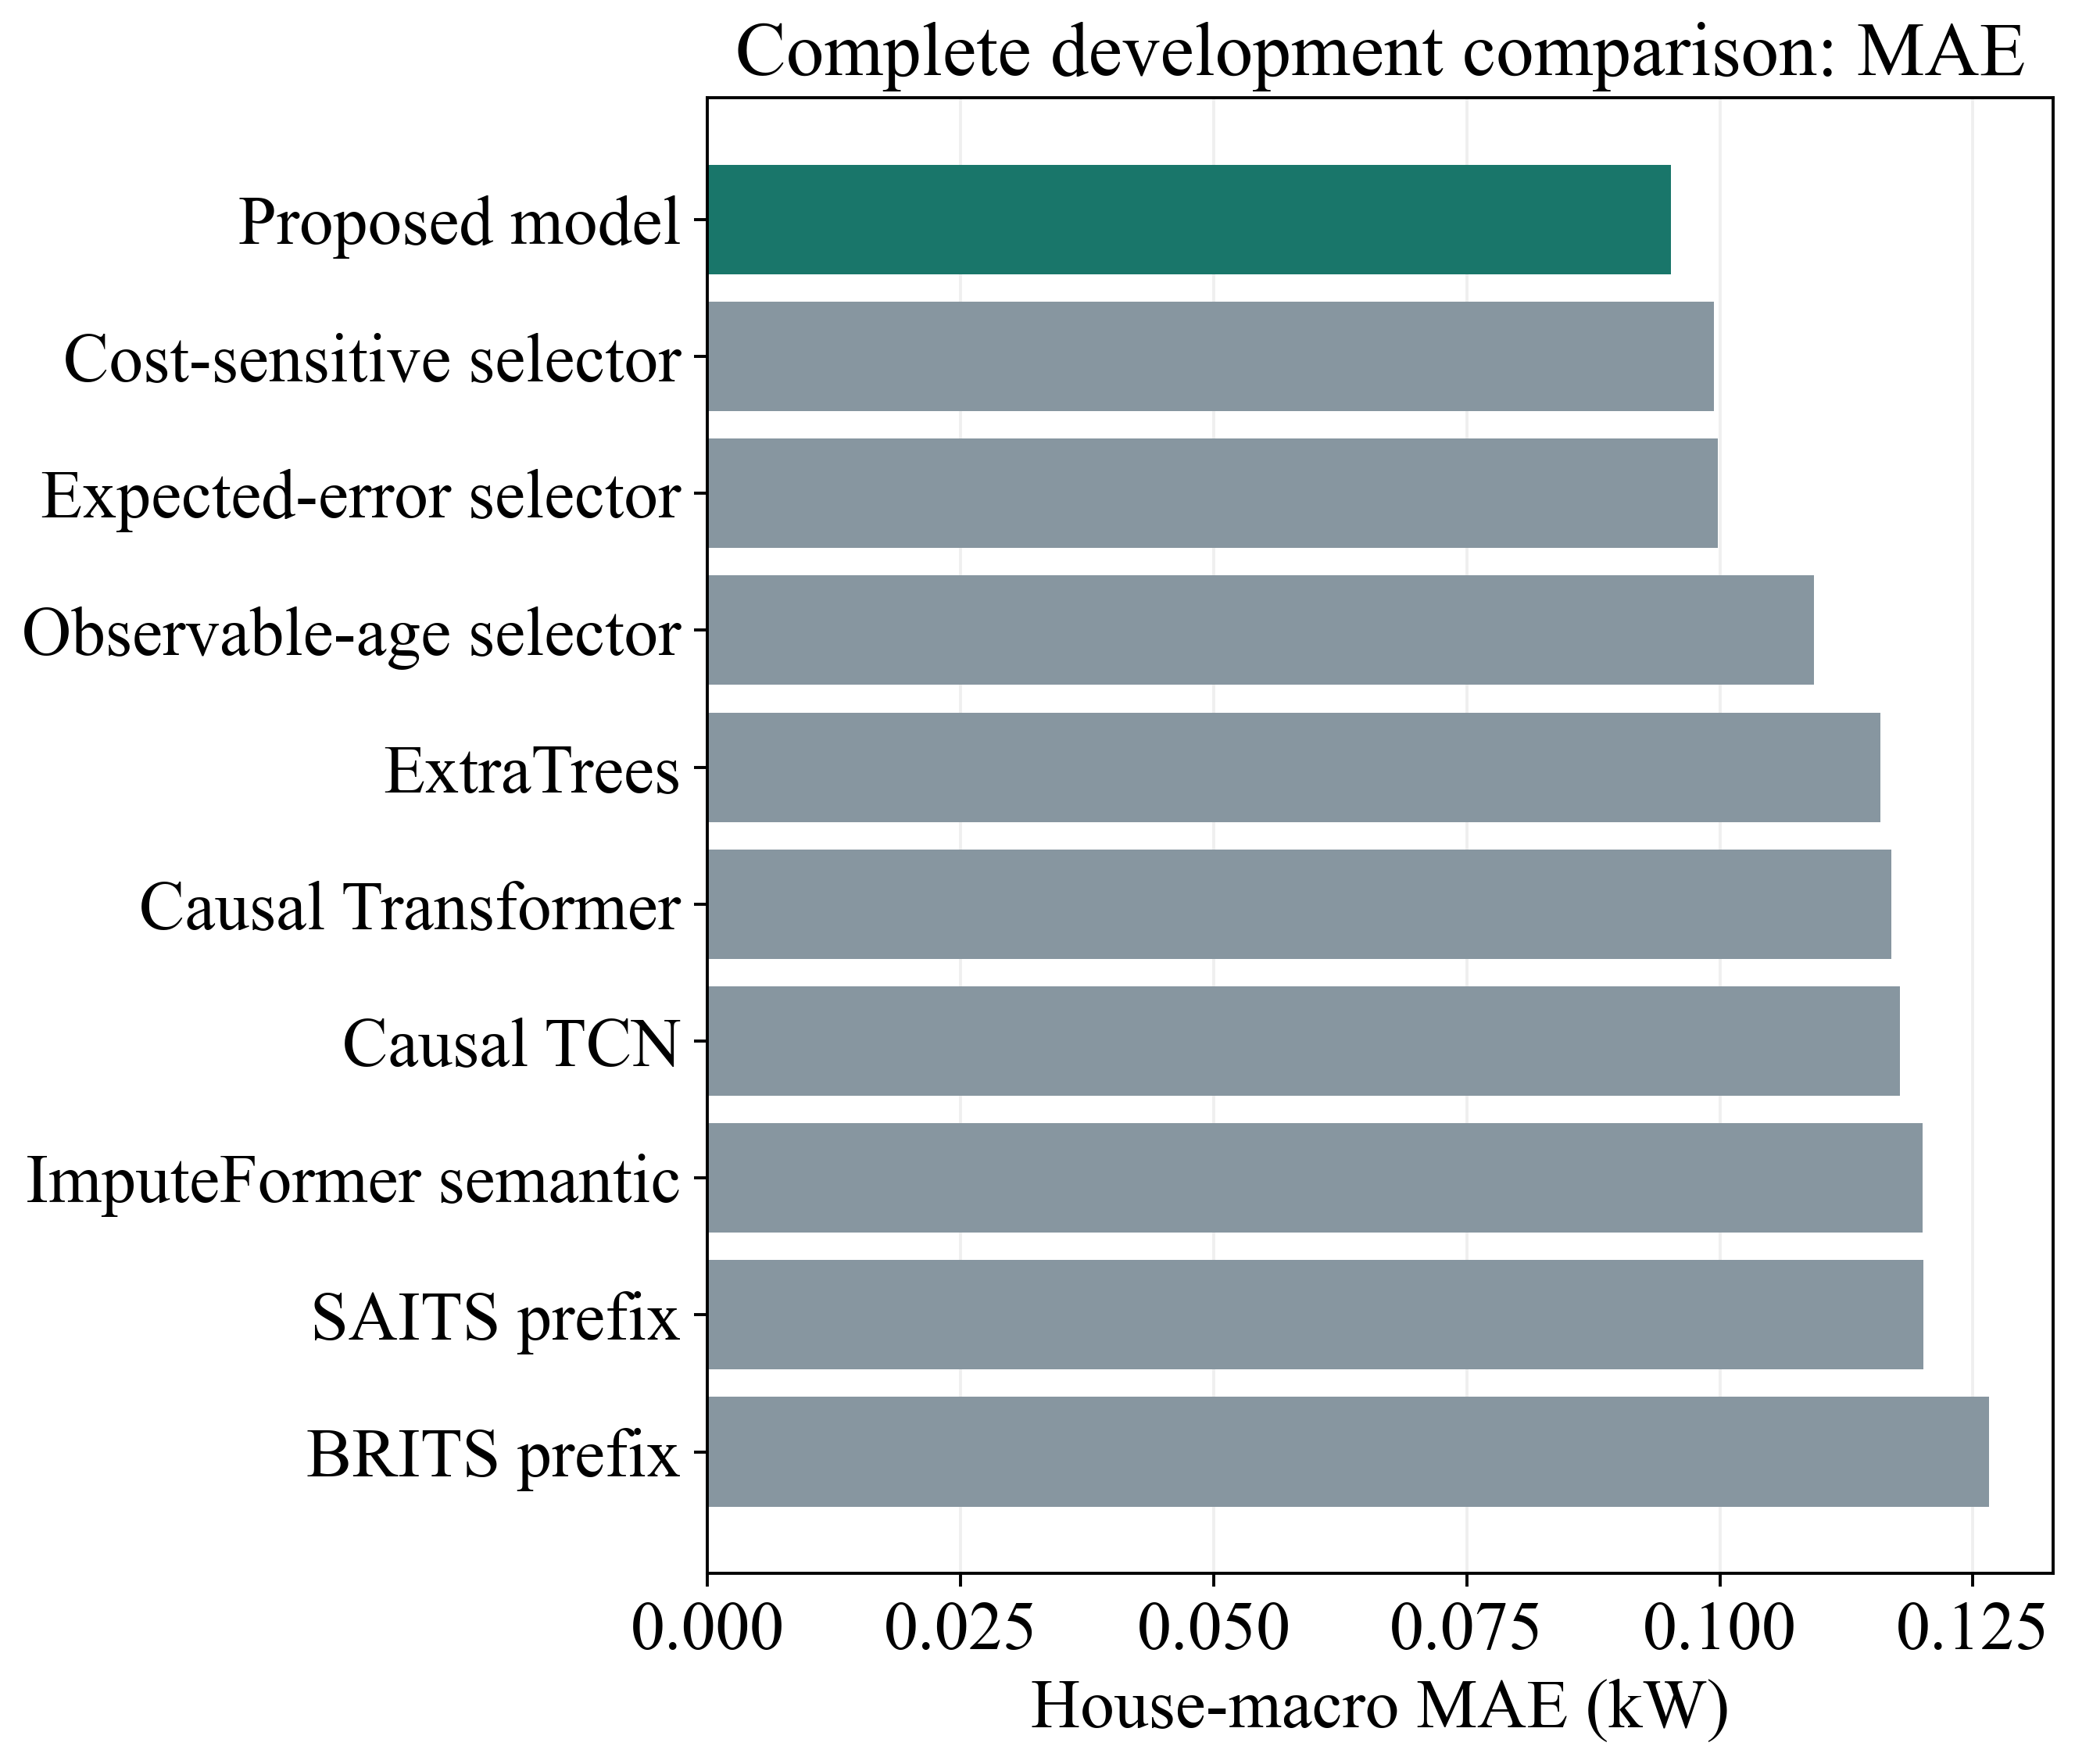

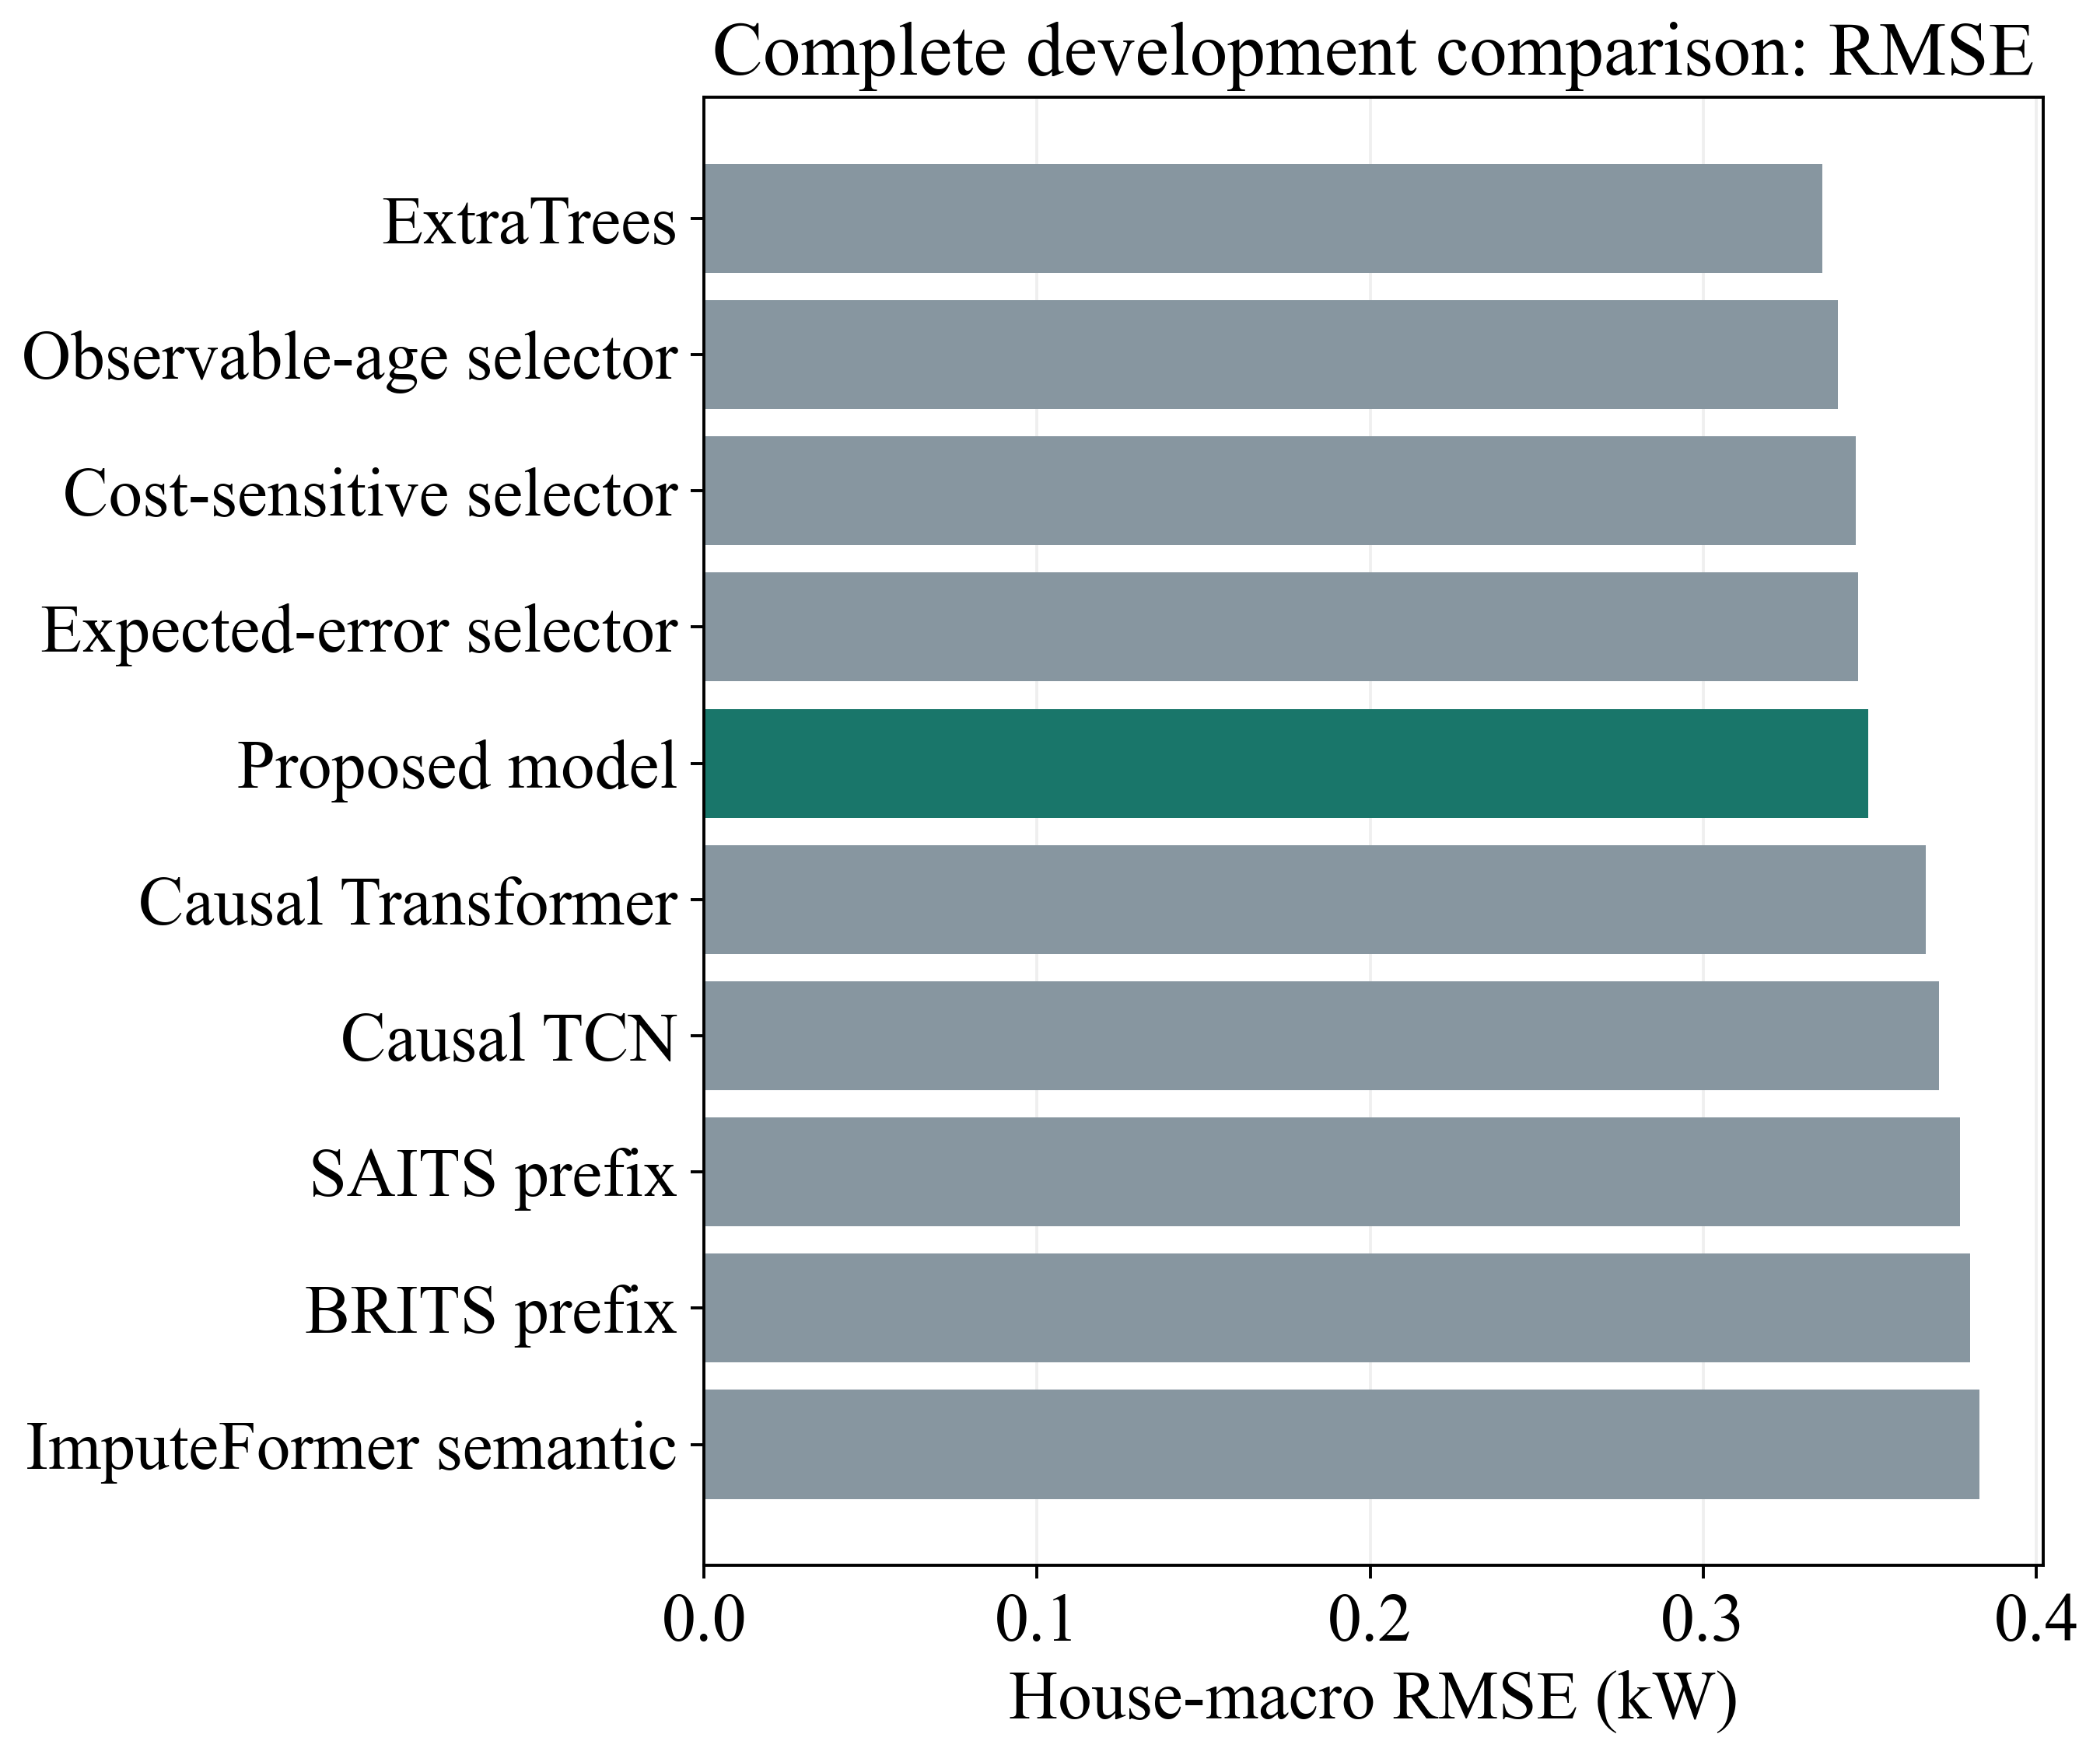

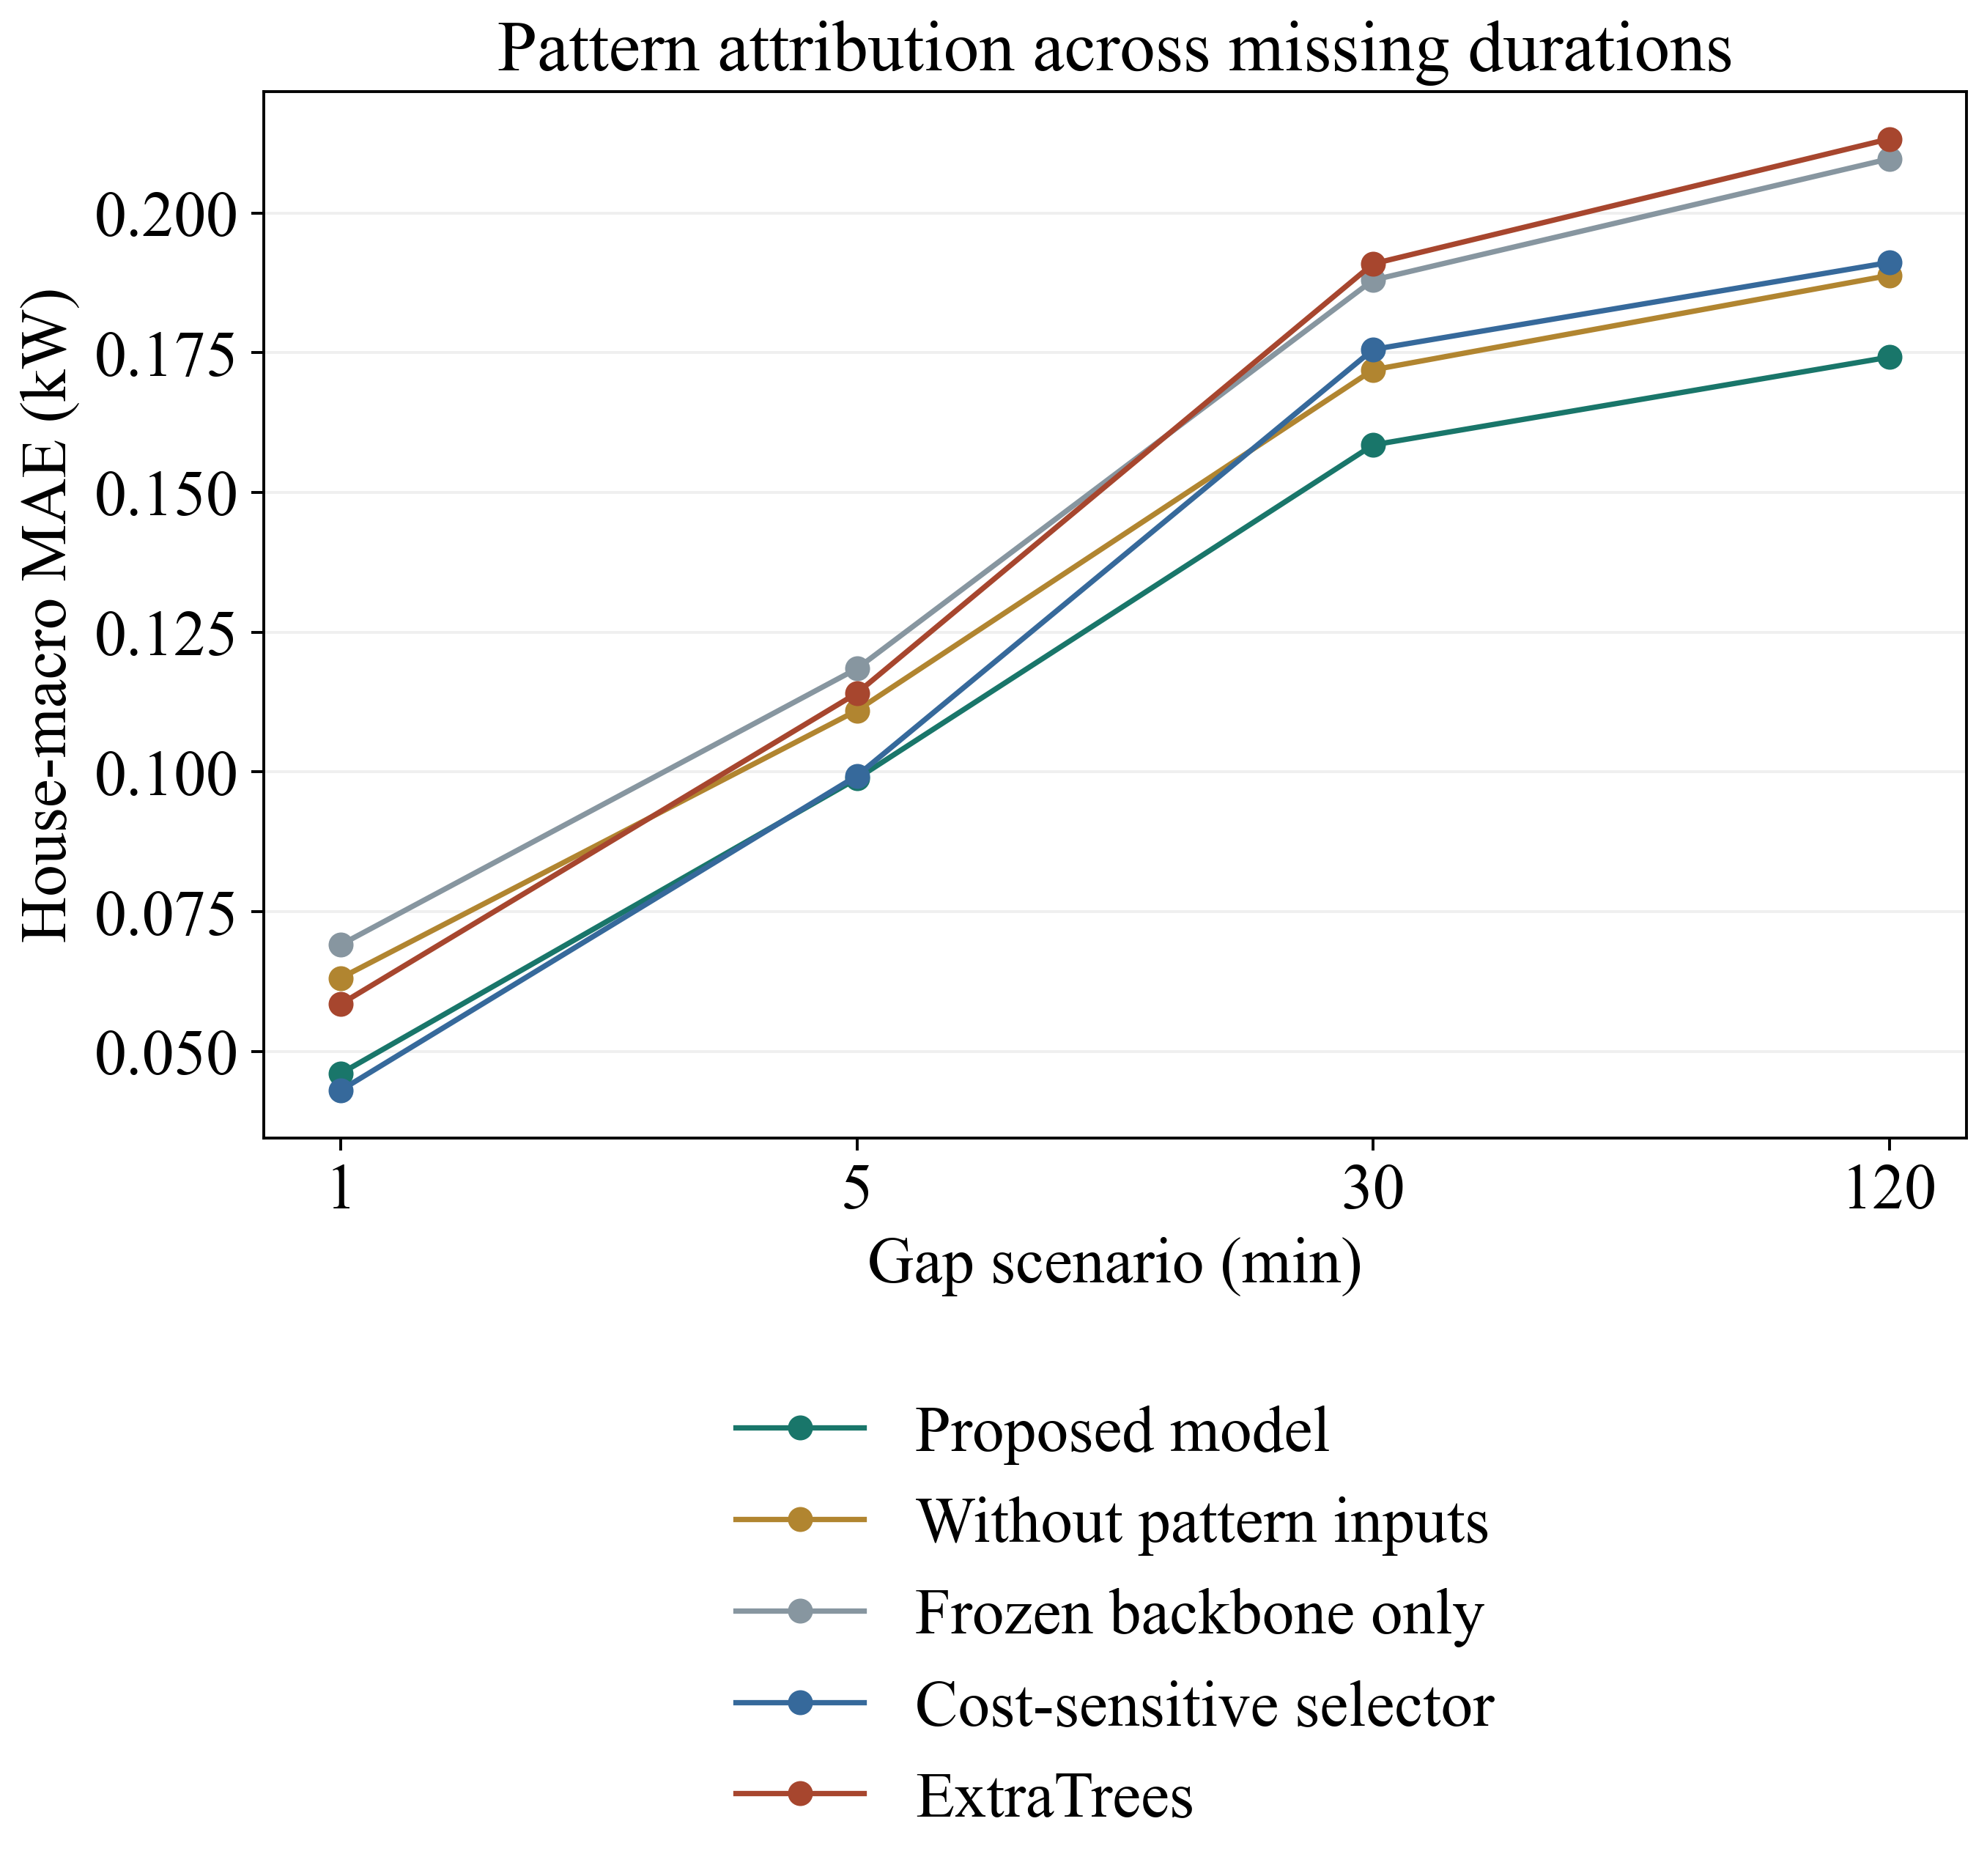

In [6]:
# Compare complete identical OOF rows; no partially completed candidate is ranked.
from itertools import product
r3_oof=[];r3_artifacts={}
for fold in [1,2,3]:
    for seed in [17,43,101]:
        path=R3_PRED/f"pattern_fold_{fold}_seed_{seed}.parquet"
        full=pd.read_parquet(path);full=full.loc[full.role.eq("outer_validation")].reset_index(drop=True)
        assert len(full)==40960 and full.observation_id.is_unique
        control=pd.read_parquet(R3_PRED/f"no_pattern_fold_{fold}_seed_{seed}.parquet")
        control=control.loc[control.role.eq("outer_validation")].reset_index(drop=True)
        np.testing.assert_array_equal(full.observation_id,control.observation_id)
        controls=pd.read_parquet(ROOT/"Predictions/development"/V2_RUN/f"learned_selectors_fold_{fold}_seed_{seed}.parquet")
        np.testing.assert_array_equal(full.observation_id,controls.observation_id)
        wide=full.copy();wide["Pattern adapter"]=full.prediction_kW;wide["No-pattern control"]=control.prediction_kW
        wide["Frozen proposal"]=full.base_mean_kW
        for name in ["ExtraTrees","Observable age selector","CostSensitiveClassifier","ExpectedErrorDifference"]:wide[name]=controls[name].to_numpy()
        r3_oof.append(wide)
        for tag in ["pattern","no_pattern"]:
            proof=R3_MODEL/f"{tag}_fold_{fold}_seed_{seed}.json";record=json.loads(proof.read_text())
            assert record["protocol_sha256"]==R3_PROTOCOL_SHA and record["implementation_sha256"]==R3_IMPL_SHA
            for candidate,key in [(proof.with_suffix(".joblib"),"checkpoint_sha256"),(R3_PRED/f"{tag}_fold_{fold}_seed_{seed}.parquet","prediction_sha256")]:
                assert file_sha256(candidate)==record[key];r3_artifacts[str(candidate.relative_to(ROOT))]=record[key]
            r3_artifacts[str(proof.relative_to(ROOT))]=file_sha256(proof)
r3_oof=pd.concat(r3_oof,ignore_index=True)
assert len(r3_oof)==368640 and not r3_oof.duplicated(["observation_id","seed"]).any()
models=["Pattern adapter","No-pattern control","Frozen proposal","ExtraTrees","Observable age selector","CostSensitiveClassifier","ExpectedErrorDifference"]
seed_scores=pd.DataFrame([{"Model":model,"Seed":seed,**r3_metrics(part,part[model])} for seed,part in r3_oof.groupby("seed") for model in models])
seed_scores.to_csv(R3_TABLE/"OOF_seed_scores.csv",index=False)
summary=seed_scores.groupby("Model",sort=False).agg(MAE_kW=("MAE_kW","mean"),RMSE_kW=("RMSE_kW","mean"),Bias_kW=("Bias_kW","mean"),MAE_seed_min=("MAE_kW","min"),MAE_seed_max=("MAE_kW","max")).reset_index()
modern=pd.read_csv(ROOT/"Tables"/V2_RUN/"04_complete_comparisons/article_modern_comparison.csv")
modern=modern.loc[~modern.Model.isin(models),summary.columns]
summary=pd.concat([summary,modern],ignore_index=True).sort_values("MAE_kW")
r3_table(summary,"complete_OOF_comparison","Three complete folds and seeds for every model. CSDI remains incomplete and unranked. Ranges describe seeds, not independent uncertainty intervals.")
strata=[]
for (seed,gap),part in r3_oof.groupby(["seed","gap"]):
    for model in models:strata.append({"Model":model,"Seed":seed,"Gap_min":gap,**r3_metrics(part,part[model])})
strata=pd.DataFrame(strata);strata.to_csv(R3_TABLE/"OOF_gap_scores.csv",index=False)
# House-level paired signs: average seeds before inferential units are counted.
contrasts=[]
for control in ["Frozen proposal","No-pattern control","CostSensitiveClassifier"]:
    for metric in ["MAE","RMSE"]:
        records=[]
        for (seed,house),part in r3_oof.groupby(["seed","house"]):
            y=part.y_kW.to_numpy();a=part["Pattern adapter"].to_numpy()-y;b=part[control].to_numpy()-y
            difference=np.mean(abs(a))-np.mean(abs(b)) if metric=="MAE" else np.sqrt(np.mean(a*a))-np.sqrt(np.mean(b*b))
            records.append({"House":house,"Seed":seed,"Difference":difference})
        values=pd.DataFrame(records).groupby("House").Difference.mean().to_numpy();effect=float(values.mean())
        signs=np.array(list(product([-1.,1.],repeat=len(values))))
        pvalue=float(np.mean(abs(signs@values/len(values))>=abs(effect)-1e-15))
        contrasts.append({"Control":control,"Metric":metric,"Difference_kW":effect,"Households":len(values),"Exact p":pvalue})
contrasts=pd.DataFrame(contrasts);order=np.argsort(contrasts["Exact p"].to_numpy());adjusted=np.maximum.accumulate((len(order)-np.arange(len(order)))*contrasts["Exact p"].to_numpy()[order]);contrasts["Holm p"]=np.nan
contrasts.loc[order,"Holm p"]=np.minimum(1,adjusted)
r3_table(contrasts,"development_paired_statistics","Exploratory two-sided house sign-flip tests, Holm across all six contrasts. Joint sign invariance is assumed; seed repetitions are not independent houses.")
indexed=summary.set_index("Model");new=float(indexed.loc["Pattern adapter","MAE_kW"]);old=float(indexed.loc["Frozen proposal","MAE_kW"])
baseline=summary.loc[~summary.Model.isin(["Pattern adapter","No-pattern control","Frozen proposal"])].iloc[0]
gain_old=100*(1-new/old);gain_best=100*(1-new/baseline.MAE_kW)
text=(f"**Complete development result.** Pattern-adapter MAE is {new:.6f} kW; reduction versus frozen proposal: {gain_old:.2f}%. "
      f"The strongest completed baseline is {baseline.Model} ({baseline.MAE_kW:.6f} kW); adapter MAE reduction versus it: {gain_best:.2f}% (negative means worse). "
      f"The registered 10% baseline-superiority target is {'met descriptively' if gain_best>=10 else 'not met'}. "
      "These are exploratory development results after prior model diagnostics. The no-pattern comparison supports only the tested pathway, not unique mathematical novelty or the necessity of the neural backbone.")
display(Markdown(text));(R3_TABLE/"development_interpretation.md").write_text(text+"\n")
def render_presentation_nb05_primary_development():
    # Presentation only: exact saved summaries; no fitting or per-query metric calculation.
    from pathlib import Path
    import hashlib
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown, HTML
    from PIL import Image as PILImage
    ROOT = Path.cwd()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    PRESENTATION_RUN = "guldana_n3_20261011_presentation"
    _font = font_manager.findfont("Times New Roman", fallback_to_default=False)
    assert Path(_font).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42})
    def read_presentation_csv(relative):
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == INPUT_SHA256[relative], relative
        return pd.read_csv(path)
    def save_presentation(fig, name):
        fig.canvas.draw()
        for item in fig.findobj(Text):
            if item.get_visible() and item.get_text().strip():
                assert 18 <= item.get_fontsize() <= 20
                actual = font_manager.FontProperties(fname=font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)).get_name()
                assert actual == "Times New Roman"
        for kind in ["PNG", "PDF"]:
            directory = ROOT / "Figures" / kind / PRESENTATION_RUN
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (name + "." + kind.lower()), dpi=350, bbox_inches="tight", pad_inches=.08)
        png = ROOT / "Figures/PNG" / PRESENTATION_RUN / (name + ".png")
        with PILImage.open(png) as raster:
            assert all(abs(value - 350) < .02 for value in raster.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    INPUT_SHA256 = {'Tables/guldana_n3_20261011_v03/05_pattern_adapter/complete_OOF_comparison.csv': '1a0dc4a7df9a820233d0e0867fd517378a25bd9ce9035a1653ef7860935ab81a', 'Tables/guldana_n3_20261011_v03/05_pattern_adapter/OOF_gap_scores.csv': '997bb5afde339ae7ca396e7635207abaa1c4115d7973097fe30bbd66ba72719c'}

    comparison = read_presentation_csv("Tables/guldana_n3_20261011_v03/05_pattern_adapter/complete_OOF_comparison.csv")
    gaps_saved = read_presentation_csv("Tables/guldana_n3_20261011_v03/05_pattern_adapter/OOF_gap_scores.csv")
    primary = comparison.loc[~comparison.Model.isin(["Frozen proposal", "No-pattern control"])].copy()
    assert len(primary) == 10 and primary.Model.eq("Pattern adapter").sum() == 1
    labels = {"Pattern adapter": "Proposed model", "CostSensitiveClassifier": "Cost-sensitive selector", "ExpectedErrorDifference": "Expected-error selector", "Observable age selector": "Observable-age selector", "Causal-Transformer": "Causal Transformer", "Causal-TCN": "Causal TCN", "ImputeFormer-semantic": "ImputeFormer semantic", "SAITS-prefix": "SAITS prefix", "BRITS-prefix": "BRITS prefix", "ExtraTrees": "ExtraTrees"}
    assert set(primary.Model) == set(labels)
    for endpoint, stem, title in [("MAE_kW", "NB05_primary_development_MAE", "Complete development comparison: MAE"), ("RMSE_kW", "NB05_primary_development_RMSE", "Complete development comparison: RMSE")]:
        plot = primary.sort_values(endpoint).reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(8.2, 7.1))
        y = np.arange(len(plot))
        ax.barh(y, plot[endpoint], color=["#19766A" if model == "Pattern adapter" else "#8796A0" for model in plot.Model])
        ax.set_yticks(y, [labels[model] for model in plot.Model]); ax.invert_yaxis()
        ax.set(xlabel="House-macro " + endpoint.split("_")[0] + " (kW)", title=title)
        ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
        fig.subplots_adjust(left=.38, right=.98, top=.89, bottom=.13)
        save_presentation(fig, stem)
    # The two construction controls remain explicitly labelled ablations, not additional proposed models.
    series = [("Pattern adapter", "Proposed model", "#19766A"), ("No-pattern control", "Without pattern inputs", "#B18530"),
        ("Frozen proposal", "Frozen backbone only", "#8796A0"), ("CostSensitiveClassifier", "Cost-sensitive selector", "#36699B"), ("ExtraTrees", "ExtraTrees", "#A7462E")]
    fig, ax = plt.subplots(figsize=(8.2, 8.0))
    for model, label, color in series:
        values = gaps_saved.loc[gaps_saved.Model.eq(model)].groupby("Gap_min").MAE_kW.mean().sort_index()
        assert len(values) == 4
        ax.plot(np.arange(len(values)), values.values, marker="o", color=color, label=label)
    ax.set_xticks(np.arange(4), [str(int(value)) for value in values.index])
    ax.set(title="Pattern attribution across missing durations", xlabel="Gap scenario (min)", ylabel="House-macro MAE (kW)")
    ax.grid(axis="y", alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), ncol=1, frameon=False)
    fig.subplots_adjust(left=.16, right=.97, top=.91, bottom=.40)
    save_presentation(fig, "NB05_pattern_gap_attribution")

render_presentation_nb05_primary_development()
record={"run_id":R3,"complete_fold_seed_heads":18,"search_fits":6,"fixed_repeat_fits":12,"OOF_rows_per_model":368640,"seeds":[17,43,101],"folds":[1,2,3],
    "OOF_MAE_gain_vs_frozen_percent":gain_old,"OOF_MAE_gain_vs_best_baseline_percent":gain_best,"best_baseline":str(baseline.Model),"substantial_baseline_target_met":bool(gain_best>=10),
    "protocol_sha256":R3_PROTOCOL_SHA,"implementation_sha256":R3_IMPL_SHA,"artifacts":r3_artifacts,"independent_confirmation":False,"mathematical_priority_established":False}
(R3_RECORD/"development_complete.json").write_text(json.dumps(record,indent=2)+"\n")


## Development attribution: frozen neural state versus a causal persistence anchor

The existing no-pattern ablation retained the neural mean and variance, so it did not isolate their added value. This **single fixed control** replaces the learned neural state by the last observed aggregate value, with the saved fold/seed training-global median as the missing-history fallback. The sigma feature is zero; all other raw features and causal innovations remain. The head fits $y-a(x)$ and predicts $\max\{0,a(x)+h(x)\}$. Thus both pipelines retain residual learning and the same nominal HGB budget. This matches the residual learner budget, not total pipeline parameters or effective capacity: the control deliberately removes the neural backbone. Historical backbone costs remain in the saved component-resource table; new measurements report only the control head. This is not a direct-target search.

Exactly three development folds and seeds 17, 43, 101 are executed, with no tuning. The primary model and the independent ECO evaluation protocol are unchanged. No ECO, locked-test or final-domain data are read. Compare paired house-macro MAE and RMSE on existing outer-development IDs; average seeds within each of the ten houses. The two two-sided house sign-flip comparisons form one Holm family; fixed 20,000 paired household bootstrap resamples give descriptive intervals. These are exploratory development tests under household independence/sign-symmetry assumptions, not an independent evaluation. Nonsignificance does not establish equivalence. The estimand is the joint contribution of the learned neural mean/scale and its anchor relative to this specific persistence-residual control, not the necessity of each neural component.

In [4]:
# Self-contained, development-only attribution. No neural fit/inference or test access.
from pathlib import Path
import json, hashlib, time, gc, platform
from datetime import datetime as BA_DATETIME, timezone as BA_TIMEZONE
from itertools import product as ba_product
import numpy as np
import pandas as pd
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
BA_ROOT=Path.cwd()
if BA_ROOT.name=="Notebooks":BA_ROOT=BA_ROOT.parent
assert BA_ROOT.is_dir()
BA_RUN="guldana_n3_20261011_v05_backbone_attribution"
BA_RECORD=BA_ROOT/"Manifests/Runs/guldana_n3_20261011_v05/backbone_attribution"
BA_MODELS=BA_ROOT/"Models/proposed/guldana_n3_20261011_v05/backbone_attribution"
BA_PRED=BA_ROOT/"Predictions/development_proposed/guldana_n3_20261011_v05/backbone_attribution"
BA_TABLE=BA_ROOT/"Tables/guldana_n3_20261011_v05/05_backbone_attribution"
BA_PARAMETERS={"loss":"absolute_error","max_iter":300,"max_leaf_nodes":31,
    "min_samples_leaf":30,"learning_rate":.05,"l2_regularization":1.,"early_stopping":False}
BA_CELL_IDS=("backbone-attribution-implementation","backbone-attribution-fit","backbone-attribution-summary")

def ba_sha(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda:stream.read(2**20),b""):h.update(chunk)
    return h.hexdigest()

def ba_new_json(path,record):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    assert not path.exists(),"Preserve existing attribution evidence."
    path.write_text(json.dumps(record,indent=2,allow_nan=False)+"\n")

def ba_sources():
    nb=json.loads((BA_ROOT/"Notebooks/05_proposed_model_development_and_ablations.ipynb").read_text())
    cells={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in BA_CELL_IDS}
    assert set(cells)==set(BA_CELL_IDS)
    return {key:hashlib.sha256(cells[key].encode()).hexdigest() for key in BA_CELL_IDS}

def ba_paths(fold,seed):
    stem=f"fold_{fold}_seed_{seed}"
    cache=BA_ROOT/"Data/Processed/guldana_n3_20261007_v01/modeling_inputs"
    primary=BA_ROOT/"Models/proposed/guldana_n3_20261011_v03"/f"pattern_{stem}"
    return {"cache_record":cache/(stem+".json"),"metadata":cache/(stem+".parquet"),"raw":cache/(stem+".npz"),
        "naive":BA_ROOT/"Models/baselines/guldana_n3_20261007_v01"/f"naive_{stem}.json",
        "primary_checkpoint":primary.with_suffix(".joblib"),"primary_proof":primary.with_suffix(".json"),
        "primary_predictions":BA_ROOT/"Predictions/development_proposed/guldana_n3_20261011_v03"/f"pattern_{stem}.parquet"}

def ba_register():
    protocol={"run_id":BA_RUN,"purpose":"Fixed development-only attribution, not candidate selection",
        "control":"Last-observed aggregate residual HGB; source-global-median fallback; no neural fields",
        "parameters":BA_PARAMETERS,"folds":[1,2,3],"seeds":[17,43,101],"new_fits":9,"search_fits":0,
        "feature_slots":178,"head_capacity":"same nominal tree limits; actual leaves reported, not effective-capacity equality",
        "primary_unchanged":"guldana_n3_20261011_v03","promotion_allowed":False,"ECO_access_allowed":False,
        "locked_or_final_domain_access_allowed":False,"outcomes":["MAE_kW","RMSE_kW"],
        "statistical_family":"Both two-sided household sign-flip contrasts, one Holm family of size2",
        "aggregation":"Pool three outer development folds within house/seed; average seeds within house; equal-house mean",
        "bootstrap":{"replicates":20000,"seed":20261011,"unit":"paired house effects","interpretation":"descriptive"},
        "assumptions":"Independent household effect vectors and joint sign invariance under the tested null; no row/seed pseudoreplication",
        "claim_boundary":"Exploratory learned-state-versus-persistence attribution. No equivalence or universal neural-necessity claim."}
    original=BA_ROOT/"Configs/proposed_revision_03.json"
    assert json.loads(original.read_text())["parameters"]==BA_PARAMETERS
    resource_path=BA_ROOT/"Tables/guldana_n3_20261009_v02/05_complete_components/component_resource_summary.csv"
    resource_frame=pd.read_csv(resource_path)
    old_backbone=resource_frame.loc[resource_frame.Variant.eq("temporal_only")]
    assert len(old_backbone)==1
    protocol["omitted_backbone_historical_reference"]={"source":str(resource_path.relative_to(BA_ROOT)),
        "parameters":int(old_backbone.Parameters.iloc[0]),
        "mean_training_seconds_per_fit":float(old_backbone.Actual_fit_seconds.iloc[0]),
        "mean_OOF_prediction_seconds_per_fit":float(old_backbone.OOF_or_projection_seconds.iloc[0]),
        "interpretation":"Historical shared-workstation measurements, not new attribution timings or isolated hardware benchmarks"}
    files={str(original.relative_to(BA_ROOT)):ba_sha(original),str(resource_path.relative_to(BA_ROOT)):ba_sha(resource_path)}
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            paths=ba_paths(fold,seed)
            for path in paths.values():
                assert path.is_file() and not path.is_symlink()
                files[str(path.relative_to(BA_ROOT))]=ba_sha(path)
            cached=json.loads(paths["cache_record"].read_text());proof=json.loads(paths["primary_proof"].read_text())
            assert cached["fold"]==fold and cached["seed"]==seed and cached["rows"]==116730
            assert files[str(paths["raw"].relative_to(BA_ROOT))]==cached["array_sha256"]
            assert files[str(paths["metadata"].relative_to(BA_ROOT))]==cached["metadata_sha256"]
            assert files[str(paths["primary_checkpoint"].relative_to(BA_ROOT))]==proof["checkpoint_sha256"]
            assert files[str(paths["primary_predictions"].relative_to(BA_ROOT))]==proof["prediction_sha256"]
            naive_record=json.loads(paths["naive"].read_text())
            assert naive_record["fold"]==fold and naive_record["seed"]==seed
            assert naive_record["training_id_sha256"]==proof["training_ids_sha256"]
    record={"protocol":protocol,"source_cells":ba_sources(),"files":files,
        "registered_utc":BA_DATETIME.now(BA_TIMEZONE.utc).isoformat(),"status":"registered_before_control_fit"}
    path=BA_RECORD/"registration.json"
    if path.exists():
        existing=json.loads(path.read_text())
        for key in ["protocol","source_cells","files"]:assert existing[key]==record[key]
        return existing
    ba_new_json(path,record);return record

def ba_check_registration():
    path=BA_RECORD/"registration.json";record=json.loads(path.read_text())
    assert record["source_cells"]==ba_sources()
    return record,ba_sha(path)

def ba_check_source(path,record):
    key=str(Path(path).relative_to(BA_ROOT))
    assert key in record["files"] and ba_sha(path)==record["files"][key]

def ba_features(raw,anchor):
    # Preserve raw masked inputs. No Gaussian mean/variance or target enters this builder.
    z=raw.reset_index(drop=True).copy()
    forbidden={"y_kW","house","timestamp","role","gap","mode","retention","observation_id","base_mean","base_variance"}
    assert not set(z).intersection(forbidden) and len(z.columns)==172
    z["frozen_mean"]=anchor  # Original feature slot; now the declared non-neural anchor.
    z["frozen_sigma"]=0.    # Removed neural scale; not an uncertainty estimate.
    z["innovation_last"]=z.aggregate_last-anchor
    z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240
    z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    assert len(z.columns)==178 and np.isfinite(anchor).all() and not np.isinf(z.to_numpy(float)).any()
    pd.testing.assert_frame_equal(z.loc[:,raw.columns],raw.reset_index(drop=True),check_exact=True)
    return z

def ba_fit_one(fold,seed):
    registration,registration_sha=ba_check_registration();paths=ba_paths(fold,seed)
    for path in paths.values():ba_check_source(path,registration)
    stem=f"anchor_residual_fold_{fold}_seed_{seed}"
    model_path=BA_MODELS/(stem+".joblib");pred_path=BA_PRED/(stem+".parquet");proof_path=BA_RECORD/(stem+".json")
    if proof_path.exists():
        result=json.loads(proof_path.read_text());assert result["registration_sha256"]==registration_sha
        assert ba_sha(model_path)==result["checkpoint_sha256"] and ba_sha(pred_path)==result["prediction_sha256"]
        return result
    assert not model_path.exists() and not pred_path.exists(),"Partial fit preserved; no silent overwrite."
    meta=pd.read_parquet(paths["metadata"])
    assert len(meta)==116730 and meta.observation_id.is_unique and meta.fold.eq(fold).all() and meta.seed.eq(seed).all()
    assert meta.role.value_counts().to_dict()=={"train":65530,"outer_validation":40960,"inner_validation":10240}
    with np.load(paths["raw"],allow_pickle=False) as data:raw=pd.DataFrame(data["raw"],columns=data["input_columns"])
    assert len(raw)==len(meta)
    train=meta.role.eq("train").to_numpy();outer=meta.role.eq("outer_validation").to_numpy()
    assert not np.any(train&outer) and set(meta.loc[train,"observation_id"]).isdisjoint(meta.loc[outer,"observation_id"])
    y=meta.y_kW.to_numpy(float);assert np.isfinite(y).all() and (y>=0).all()
    fallback=float(json.loads(paths["naive"].read_text())["global_median"])
    assert np.isfinite(fallback) and fallback==float(np.median(y[train])),"Fallback must match training rows only."
    last=raw.aggregate_last.to_numpy(float);anchor=np.where(np.isfinite(last),last,fallback)
    z=ba_features(raw,anchor)
    primary_bundle=joblib.load(paths["primary_checkpoint"])
    assert list(z.columns)==primary_bundle["feature_columns"]
    reference_params=primary_bundle["model"].get_params()
    assert all(reference_params[key]==value for key,value in BA_PARAMETERS.items()) and reference_params["random_state"]==seed
    del primary_bundle
    train_ids_sha=hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()
    reference_proof=json.loads(paths["primary_proof"].read_text())
    assert reference_proof["training_ids_sha256"]==train_ids_sha and reference_proof["fit_rows"]==65530
    houses=meta.loc[train,"house"];weight=(len(houses)/(houses.nunique()*houses.map(houses.value_counts()))).to_numpy()
    assert houses.nunique()==10 and np.isfinite(weight).all() and (weight>0).all()
    target=y[train]-anchor[train]
    model=HistGradientBoostingRegressor(**BA_PARAMETERS,random_state=seed)
    started=time.perf_counter()
    with threadpool_limits(limits=4):model.fit(z.loc[train],target,sample_weight=weight)
    fit_seconds=time.perf_counter()-started
    started=time.perf_counter()
    with threadpool_limits(limits=4):correction=model.predict(z.loc[outer])
    prediction=np.maximum(0,anchor[outer]+correction)
    assert np.isfinite(prediction).all()
    for directory in [BA_MODELS,BA_PRED]:directory.mkdir(parents=True,exist_ok=True)
    joblib.dump({"model":model,"feature_columns":list(z.columns),"registration_sha256":registration_sha,
        "anchor":"last observed, otherwise training global median","global_median":fallback,
        "neural_fields_used":False},model_path)
    with threadpool_limits(limits=4):replay=joblib.load(model_path)["model"].predict(z.loc[outer].iloc[:128])
    np.testing.assert_array_equal(replay,correction[:128])
    output=meta.loc[outer].reset_index(drop=True).copy();output["anchor_kW"]=anchor[outer]
    output["uncensored_location_kW"]=anchor[outer]+correction;output["prediction_kW"]=prediction
    output.to_parquet(pred_path,index=False)
    leaves=sum(int(tree.nodes["is_leaf"].sum()) for stage in model._predictors for tree in stage)
    assert model.n_iter_==300 and leaves<=9300
    result={"fold":fold,"seed":seed,"run_id":BA_RUN,"registration_sha256":registration_sha,
        "train_rows":int(train.sum()),"outer_rows":int(outer.sum()),"training_ids_sha256":train_ids_sha,
        "outer_ids_sha256":hashlib.sha256("\n".join(output.observation_id).encode()).hexdigest(),
        "feature_columns":list(z.columns),"actual_leaves":leaves,"nominal_maximum_leaves":9300,
        "fit_seconds":fit_seconds,"predict_save_replay_seconds":time.perf_counter()-started,
        "fallback_training_global_median":fallback,"training_weights_sha256":hashlib.sha256(weight.tobytes()).hexdigest(),
        "training_residual_sha256":hashlib.sha256(target.tobytes()).hexdigest(),
        "checkpoint_sha256":ba_sha(model_path),"prediction_sha256":ba_sha(pred_path),
        "replay_max_difference":0.,"fit_role":"train","tuning":False,"promotion_allowed":False,
        "neural_inputs_used":False,"new_neural_inference_calls":0,"cost_scope":"control residual head only; backbone omitted",
        "ECO_or_locked_target_access":False,"python":platform.python_version()}
    ba_new_json(proof_path,result)
    del meta,raw,z,model,output;gc.collect()
    return result

def ba_complete_summary():
    registration,registration_sha=ba_check_registration()
    pairs=[];resources=[];outputs={}
    for fold in [1,2,3]:
        for seed in [17,43,101]:
            stem=f"anchor_residual_fold_{fold}_seed_{seed}"
            proof_path=BA_RECORD/(stem+".json");result=json.loads(proof_path.read_text())
            assert result["registration_sha256"]==registration_sha
            pred_path=BA_PRED/(stem+".parquet");assert ba_sha(pred_path)==result["prediction_sha256"]
            assert ba_sha(BA_MODELS/(stem+".joblib"))==result["checkpoint_sha256"]
            paths=ba_paths(fold,seed);ba_check_source(paths["primary_predictions"],registration)
            control=pd.read_parquet(pred_path)
            original=pd.read_parquet(paths["primary_predictions"])
            original=original.loc[original.role.eq("outer_validation")].reset_index(drop=True)
            for column in ["observation_id","house","fold","seed","timestamp","y_kW","gap","retention","mode"]:
                np.testing.assert_array_equal(original[column].to_numpy(),control[column].to_numpy())
            part=control[["observation_id","house","fold","seed","timestamp","y_kW"]].copy()
            part["Proposed model"]=original.prediction_kW.to_numpy()
            part["Persistence-residual control"]=control.prediction_kW.to_numpy();pairs.append(part)
            resources.append({key:result[key] for key in ["fold","seed","train_rows","outer_rows","actual_leaves","fit_seconds","predict_save_replay_seconds"]})
            outputs[str(proof_path.relative_to(BA_ROOT))]=ba_sha(proof_path)
    paired=pd.concat(pairs,ignore_index=True);assert len(paired)==368640
    rows=[]
    for (seed,house),part in paired.groupby(["seed","house"],sort=True):
        for model in ["Proposed model","Persistence-residual control"]:
            e=part[model].to_numpy()-part.y_kW.to_numpy()
            rows.append({"Model":model,"Seed":int(seed),"House":int(house),"Queries":len(part),
                "MAE_kW":float(np.mean(abs(e))),"RMSE_kW":float(np.sqrt(np.mean(e*e)))})
    scores=pd.DataFrame(rows);assert len(scores)==60
    house=scores.groupby(["Model","House"],sort=False)[["MAE_kW","RMSE_kW"]].mean().reset_index()
    comparison=house.groupby("Model",sort=False)[["MAE_kW","RMSE_kW"]].mean().reset_index()
    statistics=[];house_effects=[]
    rng=np.random.default_rng(20261011);resamples=rng.integers(0,10,size=(20000,10))
    signs=np.asarray(list(ba_product([-1.,1.],repeat=10)),dtype=np.longdouble)
    for metric in ["MAE_kW","RMSE_kW"]:
        wide=house.pivot(index="House",columns="Model",values=metric).sort_index()
        assert wide.shape==(10,2) and set(wide.index)==set(range(1,11))
        ours=wide["Proposed model"].to_numpy();other=wide["Persistence-residual control"].to_numpy();d=ours-other
        effects=d.astype(np.longdouble);observed=effects.mean();flipped=(signs*effects).mean(axis=1)
        tolerance=64*np.finfo(np.longdouble).eps*max(np.mean(abs(effects)),np.longdouble(1e-300))
        p=float(np.mean(abs(flipped)>=abs(observed)-tolerance))
        lo,hi=np.quantile(d[resamples].mean(axis=1),[.025,.975])
        statistics.append({"Metric":metric,"Proposed_kW":float(ours.mean()),"Control_kW":float(other.mean()),
            "Difference_kW":float(d.mean()),"Reduction_pct":float(100*(1-ours.mean()/other.mean())) if other.mean()>0 else np.nan,
            "CI95_lower_kW":float(lo),"CI95_upper_kW":float(hi),"Households_improved":int((d<0).sum()),
            "Households":10,"Exact_p":p})
        for h,value in zip(wide.index,d):house_effects.append({"House":int(h),"Metric":metric,"Difference_kW":float(value)})
    statistics=pd.DataFrame(statistics);p=statistics.Exact_p.to_numpy();order=np.argsort(p,kind="stable")
    adjusted=np.minimum(1,np.maximum.accumulate((2-np.arange(2))*p[order]));holm=np.empty(2);holm[order]=adjusted
    statistics["Holm_p"]=holm
    tables={"model_comparison":comparison,"paired_statistics":statistics,"house_seed_metrics":scores,
        "house_metrics":house,"paired_house_effects":pd.DataFrame(house_effects),"fit_resources":pd.DataFrame(resources)}
    BA_TABLE.mkdir(parents=True,exist_ok=True)
    for name,frame in tables.items():
        path=BA_TABLE/(name+".csv");payload=frame.to_csv(index=False)
        if path.exists():assert path.read_text()==payload
        else:path.write_text(payload)
        outputs[str(path.relative_to(BA_ROOT))]=ba_sha(path)
    final={"run_id":BA_RUN,"status":"nine_fixed_control_fits_and_development_attribution_complete",
        "registration_sha256":registration_sha,"files":outputs,"new_fits":9,"search_fits":0,"new_neural_fits":0,
        "primary_model_unchanged":"guldana_n3_20261011_v03","promotion_allowed":False,
        "independent_confirmation":False,"ECO_or_locked_target_access":False,
        "claim":"Only the tested learned-state-versus-persistence control is assessed; no equivalence or universal necessity conclusion."}
    completed=BA_RECORD/"completion.json"
    if completed.exists():assert json.loads(completed.read_text())==final
    else:ba_new_json(completed,final)
    view=statistics[["Metric","Proposed_kW","Control_kW","Difference_kW","Reduction_pct","Holm_p","Households_improved"]].copy()
    view["95% descriptive CI (kW)"]=[f"[{lo:.6f}, {hi:.6f}]".replace("-","−") for lo,hi in zip(statistics.CI95_lower_kW,statistics.CI95_upper_kW)]
    display(view.style.hide(axis="index").format(precision=6))
    adverse=statistics.loc[statistics.Difference_kW.ge(0),"Metric"].tolist()
    supported=statistics.loc[statistics.Difference_kW.lt(0)&statistics.Holm_p.lt(.05),"Metric"].tolist()
    display(Markdown("**Fixed development attribution.** Supported favorable contrasts under the stated sign-flip assumptions: "+
        (", ".join(supported) if supported else "none")+". Non-favorable point differences: "+
        (", ".join(adverse) if adverse else "none")+". The result is exploratory; absence of significance is not equivalence. "
        "The frozen primary model and ECO protocol are unchanged."))
    resource_frame=pd.DataFrame(resources)
    omitted=registration["protocol"]["omitted_backbone_historical_reference"]
    display(Markdown(f"**Resources.** Both residual learners use 300 trees with at most 31 leaves per tree. "
        f"Control heads have {int(resource_frame.actual_leaves.min()):,}–{int(resource_frame.actual_leaves.max()):,} actual leaves; "
        f"their nine fits took {resource_frame.fit_seconds.sum():.2f} s in total. "
        f"The control omits the {omitted['parameters']:,}-parameter neural backbone. "
        f"Its historical mean training and OOF prediction costs were {omitted['mean_training_seconds_per_fit']:.2f} s "
        f"and {omitted['mean_OOF_prediction_seconds_per_fit']:.2f} s per fold/seed, respectively; "
        "these historical shared-workstation measurements are not new control timings. No neural fit or inference was rerun. "
        "Only residual learner budgets are matched, not total pipeline parameter counts."))
    return final

# Registration freezes all source inputs and this exact inline implementation before the first fit.
BA_REGISTRATION=ba_register()


In [5]:
# Exactly one control across the already fixed three folds and three seeds; no selection.
BA_COMPLETIONS=[]
ba_progress=display(Markdown("Fixed development control: 0 / 9 fits complete."),display_id=True)
for ba_fold in [1,2,3]:
    for ba_seed in [17,43,101]:
        BA_COMPLETIONS.append(ba_fit_one(ba_fold,ba_seed))
        ba_progress.update(Markdown(f"Fixed development control: {len(BA_COMPLETIONS)} / 9 fits complete."))
assert len(BA_COMPLETIONS)==9
ba_progress.update(Markdown(""))


In [6]:
BA_COMPLETION=ba_complete_summary()


Metric,Proposed_kW,Control_kW,Difference_kW,Reduction_pct,Holm_p,Households_improved,95% descriptive CI (kW)
MAE_kW,0.095146,0.100417,−0.005270,5.248522,0.003906,9,"[−0.008211, −0.002690]"
RMSE_kW,0.349555,0.373651,−0.024096,6.448819,0.003906,10,"[−0.031706, −0.016405]"


**Fixed development attribution.** Supported favorable contrasts under the stated sign-flip assumptions: MAE_kW, RMSE_kW. Non-favorable point differences: none. The result is exploratory; absence of significance is not equivalence. The frozen primary model and ECO protocol are unchanged.

**Resources.** Both residual learners use 300 trees with at most 31 leaves per tree. Control heads have 9,300–9,300 actual leaves; their nine fits took 100.53 s in total. The control omits the 279,719-parameter neural backbone. Its historical mean training and OOF prediction costs were 543.13 s and 53.14 s per fold/seed, respectively; these historical shared-workstation measurements are not new control timings. No neural fit or inference was rerun. Only residual learner budgets are matched, not total pipeline parameter counts.

## Causal hull risk adapter

**Evidence and scope.** NB01 rejects automatic hard power balance under asynchronous, incomplete and ambiguous channels. NB02 verifies the allowed causal inputs and availability masks. NB03 finds strong recent-value reconstruction but large tail errors, with ExtraTrees offering a smaller squared error. NB04 finds neural benefits at longer gaps and no universal SOTA dominance. These motivate one learned, observable-state aggregation module.

**One proposed predictor.** Its fixed constituents are the trained pattern reconstruction, ExtraTrees and last-valid power. They are components of one fitted pipeline, not multiple proposed models. For their nonnegative predictions let $L(x)=\min_j p_j(x)$, $U(x)=\max_j p_j(x)$ and $d(x)=U(x)-L(x)$. An observable-state gate returns
$$\widehat y(x)=L(x)+d(x)\,\Pi_{[0,1]}(g_\theta(x)).$$
No outcome, house identity or scenario label enters the gate's feature vector. Availability, recent causal load and expert disagreement are observed features. Missing aggregate history uses the original training-fitted fallback. Locked splits, masked observations and source measurement rules remain unchanged.

**Risk reduction identity.** For $d>0$, define $u=\Pi_{[0,1]}((y-L)/d)$. For any $g\in[0,1]$ and pinball loss $\rho_\tau$, 
$$\rho_\tau(y-L-dg)=d\,\rho_\tau(u-g)+C(y,L,U),$$
where $C$ is independent of $g$: it is zero for $L\le y\le U$, $\tau(y-U)$ above $U$, and $(1-\tau)(L-y)$ below $L$. Thus training a coordinate gate with weights $w_i d_i$ minimizes the original house-weighted pinball loss within the observable convex interval, up to a constant. This follows by splitting the three target-position cases and using positive homogeneity. For $d=0$ the prediction is fixed; numerically $d\le10^{-12}$ is treated as zero, with a maximum absolute-loss perturbation at most $10^{-12}$ kW per row. Nonnegativity and boundedness follow immediately. They do **not** imply lower error than other methods; if every constituent misses a load excursion in the same direction, the interval can exclude the truth.

**Bounded selection and controls.** Quantiles 0.5 and 0.6 test the observed median-versus-tail/bias trade-off; leaf limits 7 and 15 test only gate complexity. All four choices are selected within development, with an RMSE guard and a chronological 360-minute purge between gate fitting and selection. Each fold selects its own configuration at seed 17, fixed for seeds 43 and 101. The constant-coordinate control has identical experts and a fitted weighted median, testing adaptation without manual weights; it is not parameter matched. Existing experts were historically selected using inner data, so this additional meta split does not create an independent validation. Every final evaluation is retrospective.

Convex aggregation and [histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) are established methods. The component examined here is a risk-aligned causal gate for this task. The scalar gate does not inherit old joint-state acquisition guarantees.

In [7]:
from pathlib import Path
import json, hashlib, os, time, gc, itertools, joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, Image
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if ROOT.name=="Notebooks": ROOT=ROOT.parent
assert ROOT.is_dir()
R4="guldana_n3_20261011_v04";R3="guldana_n3_20261011_v03";V1="guldana_n3_20261007_v01";V2="guldana_n3_20261009_v02"
REC=ROOT/"Manifests/Runs"/R4;MOD=ROOT/"Models/proposed"/R4;PRED=ROOT/"Predictions/development_proposed"/R4;TAB=ROOT/"Tables"/R4/"05_causal_hull"
for d in [MOD,PRED,TAB,ROOT/"Figures/PNG"/R4,ROOT/"Figures/PDF"/R4]:d.mkdir(parents=True,exist_ok=True)
def sha(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(8*1024*1024),b""):h.update(b)
    return h.hexdigest()
PROTOCOL=json.loads((ROOT/"Configs/proposed_revision_04.json").read_text());PROTOCOL_SHA=sha(ROOT/"Configs/proposed_revision_04.json")
OLD_LOCK=json.loads((ROOT/"Manifests/Runs"/V2/"historical_artifact_lock.json").read_text())["files"]
V3_LOCK=json.loads((ROOT/"Manifests/Runs"/R3/"scientific_completion.json").read_text())["artifacts"]
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False);assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,"axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def table(frame,name,caption):
    frame.to_csv(TAB/f"{name}.csv",index=False);frame.to_latex(TAB/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.6f}")
    display(frame.style.format(precision=6,na_rep="Unavailable").hide(axis="index").set_caption(caption))
def metrics(meta,p):
    e=np.asarray(p)-meta.y_kW.to_numpy(float)
    h=pd.DataFrame({"house":meta.house.to_numpy(),"ae":abs(e),"se":e*e,"bias":e}).groupby("house").mean()
    return {"MAE_kW":float(h.ae.mean()),"RMSE_kW":float(np.sqrt(h.se).mean()),"Bias_kW":float(h.bias.mean())}
def house_weights(meta):
    return (len(meta)/meta.house.map(meta.house.value_counts())/meta.house.nunique()).to_numpy(float)
def r3_features(raw,mu,variance,patterns=True):
    # Only frozen audited input columns; metadata and labels never enter this function.
    z=raw.reset_index(drop=True).copy()
    assert not set(z).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    z["frozen_mean"]=mu;z["frozen_sigma"]=np.sqrt(variance)
    z["innovation_last"]=z.aggregate_last-mu
    z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240
    z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    if not patterns:
        removed=[c for c in z if (c.startswith("aggregate_") and c not in {"aggregate_lag_1440","aggregate_lag_10080"}) or c.startswith("innovation_")]
        z.loc[:,removed]=0.
    a=z.to_numpy(dtype=np.float64)
    assert not np.isinf(a).any() and np.isfinite(mu).all() and (np.asarray(variance)>0).all()
    return z


In [8]:
def hull_features(raw,experts):
    z=raw.reset_index(drop=True).copy()
    assert not set(z).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    assert experts.shape==(len(raw),3) and np.isfinite(experts).all() and (experts>=0).all()
    low=experts.min(1);width=experts.max(1)-low
    for j,name in enumerate(["persistence","tree","pattern"]):
        z[f"expert_{name}"]=experts[:,j]
        z[f"position_{name}"]=np.divide(experts[:,j]-low,width,out=np.zeros(len(low)),where=width>0)
    z["hull_width"]=width
    z["pattern_minus_last"]=experts[:,2]-experts[:,0];z["tree_minus_pattern"]=experts[:,1]-experts[:,2]
    assert not np.isinf(z.to_numpy(float)).any()
    return z,low,width

def weighted_quantile(values,weights,q=.5):
    order=np.argsort(values,kind="stable");v=np.asarray(values)[order];w=np.asarray(weights)[order]
    assert w.sum()>0
    return float(v[min(np.searchsorted(np.cumsum(w),q*w.sum()),len(v)-1)])

def meta_roles(meta):
    fit=np.zeros(len(meta),bool);validation=fit.copy();records=[]
    for house,part in meta.loc[meta.role.eq("inner_validation")].groupby("house"):
        times=np.sort(part.timestamp.unique());cut=times[max(0,int(len(times)*.6)-1)]
        a=part.index[part.timestamp<=cut];b=part.index[part.timestamp>pd.Timestamp(cut)+pd.Timedelta(minutes=360)]
        assert len(a)>=64 and len(b)>=32,(house,len(a),len(b))
        fit[a]=True;validation[b]=True
        assert meta.loc[a,"timestamp"].max()+pd.Timedelta(minutes=360)<meta.loc[b,"timestamp"].min()
        records.append({"House":house,"Gate train":len(a),"Gate validation":len(b),"Cutoff":str(cut)})
    assert not (fit&validation).any()
    return fit,validation,pd.DataFrame(records)

def development_inputs(fold,seed):
    record=json.loads((ROOT/"Data/Processed"/V1/"modeling_inputs"/f"fold_{fold}_seed_{seed}.json").read_text())
    lineage={}
    for kind in ["array","metadata"]:
        path=ROOT/record[f"{kind}_file"];assert sha(path)==record[f"{kind}_sha256"];lineage[str(path.relative_to(ROOT))]=sha(path)
    meta=pd.read_parquet(ROOT/record["metadata_file"]).reset_index(drop=True)
    with np.load(ROOT/record["array_file"],allow_pickle=False) as a:raw=pd.DataFrame(a["raw"],columns=a["input_columns"]);x=a["x"].copy()
    basepath=ROOT/"Predictions/development_proposed"/R3/f"frozen_base_fold_{fold}_seed_{seed}.parquet"
    assert sha(basepath)==V3_LOCK[str(basepath.relative_to(ROOT))]
    base=pd.read_parquet(basepath);np.testing.assert_array_equal(base.observation_id,meta.observation_id)
    residual_path=ROOT/"Models/proposed"/R3/f"pattern_fold_{fold}_seed_{seed}.joblib"
    tree_path=ROOT/"Models/baselines"/V1/f"ExtraTrees_fold_{fold}_seed_{seed}.joblib"
    for path,lock in [(residual_path,V3_LOCK),(tree_path,OLD_LOCK)]:assert sha(path)==lock[str(path.relative_to(ROOT))];lineage[str(path.relative_to(ROOT))]=sha(path)
    start=time.perf_counter();residual=joblib.load(residual_path);tree=joblib.load(tree_path)["model"];tree.set_params(n_jobs=1)
    with threadpool_limits(limits=4):
        p_pattern=np.maximum(0,base.base_mean.to_numpy()+residual["model"].predict(r3_features(raw,base.base_mean.to_numpy(),base.base_variance.to_numpy())))
        p_tree=tree.predict(x)
    original=ROOT/"Predictions/development_proposed"/R3/f"pattern_fold_{fold}_seed_{seed}.parquet"
    assert sha(original)==V3_LOCK[str(original.relative_to(ROOT))]
    np.testing.assert_array_equal(p_pattern,pd.read_parquet(original).prediction_kW)
    statepath=ROOT/"Models/baselines"/V1/f"naive_fold_{fold}_seed_{seed}.json";assert sha(statepath)==OLD_LOCK[str(statepath.relative_to(ROOT))]
    state=json.loads(statepath.read_text());fallback=meta.house.map(lambda h:state["house_medians"].get(str(h),state["global_median"])).to_numpy()
    last=raw.aggregate_last.to_numpy();p_last=np.where(np.isfinite(last),last,fallback)
    experts=np.maximum(0,np.column_stack([p_last,p_tree,p_pattern]));z,low,width=hull_features(raw,experts)
    outer=meta.role.eq("outer_validation").to_numpy()
    oldtree=pd.read_parquet(ROOT/"Predictions/development"/V1/f"ExtraTrees_fold_{fold}_seed_{seed}.parquet")
    np.testing.assert_array_equal(meta.loc[outer,"observation_id"],oldtree.observation_id)
    np.testing.assert_array_equal(p_tree[outer],oldtree.prediction_kW)
    lineage[str(basepath.relative_to(ROOT))]=sha(basepath);lineage[str(statepath.relative_to(ROOT))]=sha(statepath)
    (REC/f"inputs_fold_{fold}_seed_{seed}.json").write_text(json.dumps({"lineage":lineage,"expert_predict_seconds":time.perf_counter()-start,"rows":len(meta),"new_expert_fits":0},indent=2)+"\n")
    del x,tree,residual,raw,base;gc.collect()
    return meta,z,experts,low,width

def fit_hull(meta,z,low,width,mask,config,seed):
    active=mask&(width>1e-12)
    u=np.clip((meta.loc[active,"y_kW"].to_numpy()-low[active])/width[active],0,1)
    w=house_weights(meta.loc[mask]);full=np.zeros(len(meta));full[mask]=w
    weighted=full[active]*width[active];weighted/=weighted.mean()
    model=HistGradientBoostingRegressor(**PROTOCOL["fixed_parameters"],quantile=config["quantile"],max_leaf_nodes=config["max_leaf_nodes"],random_state=seed)
    t=time.perf_counter()
    with threadpool_limits(limits=4):model.fit(z.loc[active],u,sample_weight=weighted)
    return model,weighted_quantile(u,weighted),time.perf_counter()-t,int(active.sum())

def hull_predict(model,z,low,width):
    with threadpool_limits(limits=4):g=np.clip(model.predict(z),0,1)
    p=low+width*g
    assert np.isfinite(p).all() and (p>=0).all() and (p>=low-1e-12).all() and (p<=low+width+1e-12).all()
    return p,g

def search_fold(fold):
    seed=17;meta,z,experts,low,width=development_inputs(fold,seed);fit,val,splits=meta_roles(meta)
    splits.to_csv(TAB/f"meta_split_fold_{fold}.csv",index=False)
    rows=[];proofs=[]
    for config in PROTOCOL["candidate_grid"]:
        model,constant,seconds,nfit=fit_hull(meta,z,low,width,fit,config,seed)
        p,_=hull_predict(model,z.loc[val],low[val],width[val])
        row={"Fold":fold,"Configuration":config["id"],**metrics(meta.loc[val],p),"Fit seconds":seconds,"Fit rows":nfit};rows.append(row)
        path=MOD/f"search_fold_{fold}_{config['id']}.joblib";joblib.dump({"model":model,"config":config,"columns":list(z)},path)
        pred=meta.loc[val].copy();pred["prediction_kW"]=p;out=PRED/f"search_fold_{fold}_{config['id']}.parquet";pred.to_parquet(out,index=False)
        replay,_=hull_predict(joblib.load(path)["model"],z.loc[val],low[val],width[val]);np.testing.assert_array_equal(p,replay)
        proofs.append({"checkpoint":str(path.relative_to(ROOT)),"checkpoint_sha256":sha(path),"prediction":str(out.relative_to(ROOT)),"prediction_sha256":sha(out),"config":config,"fit_seconds":seconds,"fit_rows":nfit})
    a=fit&(width>1e-12);u=np.clip((meta.loc[a,"y_kW"].to_numpy()-low[a])/width[a],0,1)
    w=np.zeros(len(meta));w[fit]=house_weights(meta.loc[fit]);constant=weighted_quantile(u,w[a]*width[a])
    for name,p in [("Residual expert",experts[val,2]),("ExtraTrees",experts[val,1]),("Persistence",experts[val,0]),("Constant hull control",low[val]+width[val]*constant)]:rows.append({"Fold":fold,"Configuration":name,**metrics(meta.loc[val],p),"Fit seconds":0.,"Fit rows":int(fit.sum())})
    result=pd.DataFrame(rows);table(result,f"search_fold_{fold}",f"Fold {fold}: chronological inner meta-validation only; historical checkpoint-selection reuse is explicitly exploratory.")
    (REC/f"search_fold_{fold}.json").write_text(json.dumps({"protocol_sha256":PROTOCOL_SHA,"implementation_sha256":IMPL_SHA,"runs":proofs,"kernel_pid":os.getpid()},indent=2)+"\n")
    return result

def select_hulls():
    full=pd.concat([pd.read_csv(TAB/f"search_fold_{f}.csv") for f in [1,2,3]],ignore_index=True);selections={};rows=[]
    for fold,part in full.groupby("Fold"):
        reference=part.set_index("Configuration").loc["Residual expert"];control=part.set_index("Configuration").loc["Constant hull control"]
        candidates=part[part.Configuration.isin([c["id"] for c in PROTOCOL["candidate_grid"]])]
        eligible=candidates[candidates.RMSE_kW<=reference.RMSE_kW];chosen=(eligible if len(eligible) else candidates).sort_values(["MAE_kW","Configuration"]).iloc[0]
        selections[str(fold)]=chosen.Configuration
        rows.append({"Fold":fold,"Selected":chosen.Configuration,"MAE_kW":chosen.MAE_kW,"RMSE_kW":chosen.RMSE_kW,"Reference MAE":reference.MAE_kW,"Reference RMSE":reference.RMSE_kW,"Constant MAE":control.MAE_kW,"RMSE guard":len(eligible)>0})
    out=pd.DataFrame(rows);accepted=bool(out.MAE_kW.mean()<=.98*out["Reference MAE"].mean() and out.MAE_kW.mean()<=.99*out["Constant MAE"].mean() and out.RMSE_kW.mean()<=out["Reference RMSE"].mean())
    average=full.groupby("Configuration")[["MAE_kW","RMSE_kW"]].mean();candidates=average.loc[[c["id"] for c in PROTOCOL["candidate_grid"]]].reset_index()
    eligible=candidates[candidates.RMSE_kW<=average.loc["Residual expert","RMSE_kW"]]
    final=(eligible if len(eligible) else candidates).sort_values(["MAE_kW","Configuration"]).iloc[0].Configuration
    decision={"run_id":R4,"accepted":accepted,"per_fold":selections,"final_config":final,"protocol_sha256":PROTOCOL_SHA,"search_fits":12,"outer_or_test_used":False,"new_independent_validation":False}
    (REC/"development_decision.json").write_text(json.dumps(decision,indent=2)+"\n");table(out,"inner_selection","One deterministic selection per fold; parameters are never selected by outer or test scores.")
    display(Markdown(f"**Registered promotion gate: {'passed' if accepted else 'failed'}.** All retained OOF diagnostic runs will be completed; a failed gate cannot be relabelled as a successful proposed model."))
    return decision

def retain_fold(fold):
    decision=json.loads((REC/"development_decision.json").read_text());config=next(c for c in PROTOCOL["candidate_grid"] if c["id"]==decision["per_fold"][str(fold)])
    rows=[]
    for seed in [17,43,101]:
        meta,z,experts,low,width=development_inputs(fold,seed);fit=meta.role.eq("inner_validation").to_numpy();outer=meta.role.eq("outer_validation").to_numpy()
        model,constant,seconds,nfit=fit_hull(meta,z,low,width,fit,config,seed)
        path=MOD/f"hull_fold_{fold}_seed_{seed}.joblib";joblib.dump({"model":model,"config":config,"columns":list(z),"constant":constant,"protocol_sha256":PROTOCOL_SHA,"implementation_sha256":IMPL_SHA},path)
        t=time.perf_counter();prediction,gate=hull_predict(model,z.loc[outer],low[outer],width[outer]);predict_seconds=time.perf_counter()-t
        replay,_=hull_predict(joblib.load(path)["model"],z.loc[outer],low[outer],width[outer]);np.testing.assert_array_equal(prediction,replay)
        out=meta.loc[outer].copy();out["prediction_kW"]=prediction;out["gate"]=gate;out["hull_lower"]=low[outer];out["hull_upper"]=low[outer]+width[outer];out["constant_prediction_kW"]=low[outer]+width[outer]*constant;out["residual_expert_kW"]=experts[outer,2]
        dest=PRED/f"hull_fold_{fold}_seed_{seed}.parquet";out.to_parquet(dest,index=False)
        proof={"fold":fold,"seed":seed,"config":config,"fit_seconds":seconds,"predict_seconds":predict_seconds,"fit_rows":nfit,"OOF_rows":len(out),"checkpoint_sha256":sha(path),"prediction_sha256":sha(dest),"protocol_sha256":PROTOCOL_SHA,"implementation_sha256":IMPL_SHA,"actual_leaves":sum(int(t.nodes["is_leaf"].sum()) for stage in model._predictors for t in stage),"kernel_pid":os.getpid(),"replay_max_difference":0.,"constant":constant}
        path.with_suffix(".json").write_text(json.dumps(proof,indent=2)+"\n")
        rows.append({"Fold":fold,"Seed":seed,**metrics(out,prediction),"Fit seconds":seconds,"Gate train rows":nfit})
        display(Markdown(f"Fold {fold}, seed {seed}: retained fit and complete OOF replay finished."))
        del z,meta,experts,model;gc.collect()
    table(pd.DataFrame(rows),f"retained_fold_{fold}","Fixed selected configuration; complete held-out OOF predictions, no new search.")

# Bind the complete new notebook source before fitting any gate.
notebook=json.loads((ROOT/"Notebooks/05_proposed_model_development_and_ablations.ipynb").read_text())
binding={c["id"]:"".join(c["source"]) for c in notebook["cells"] if c.get("id","").startswith("r4-")}
bound=REC/"nb05_prefit_source.json"
if bound.exists():
    assert sha(bound) == "ba17c65849028d8d1c730dd847959adbcff2133a1b49f6c42bc502b012adabc0"
    frozen=json.loads(bound.read_text())
    presentation=REC/"nb05_postfit_presentation_source.json"
    assert presentation.is_file() and sha(presentation) == "ef1a4630d530d107bdf7a38d087ffe96f359b88a9dc06b316c6262e969b1cbc1"
    prior_presentation=json.loads(presentation.read_text())
    if binding != frozen and binding != prior_presentation:
        amendment=json.loads((ROOT/"Manifests/Runs/guldana_n3_20261011_presentation/nb05_r4_source_presentation_amendment.prepared.json").read_text())
        assert amendment["before_source"] == prior_presentation
        assert amendment["changed_cell_ids"] == ["r4-implementation", "r4-development-summary"]
        assert set(amendment["after_source"]) == set(prior_presentation)
        assert all(amendment["after_source"][key] == prior_presentation[key]
                   for key in prior_presentation if key not in amendment["changed_cell_ids"])
        assert binding == amendment["after_source"]
else:bound.write_text(json.dumps(binding,indent=2)+"\n")
IMPL_SHA=sha(bound)


In [3]:
search_fold(1);


Fold,Configuration,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Fit rows
1,q0.5_leaves7,0.088333,0.333516,−0.039458,0.875990,6140
1,q0.5_leaves15,0.090842,0.336044,−0.037245,1.420317,6140
1,q0.6_leaves7,0.090845,0.336359,−0.025671,0.860991,6140
1,q0.6_leaves15,0.090924,0.332776,−0.026242,1.323650,6140
1,Residual expert,0.088585,0.343376,−0.039797,0.000000,6140
1,ExtraTrees,0.110975,0.325348,−0.009196,0.000000,6140
1,Persistence,0.153761,0.524939,−0.007193,0.000000,6140
1,Constant hull control,0.112696,0.395561,−0.063363,0.000000,6140


In [4]:
search_fold(2);


Fold,Configuration,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Fit rows
2,q0.5_leaves7,0.090400,0.318344,−0.025666,0.822295,6140
2,q0.5_leaves15,0.091683,0.320499,−0.022795,1.322069,6140
2,q0.6_leaves7,0.093603,0.328004,−0.013015,0.822603,6140
2,q0.6_leaves15,0.093538,0.327529,−0.013668,1.327177,6140
2,Residual expert,0.092179,0.336425,−0.030809,0.000000,6140
2,ExtraTrees,0.112845,0.326405,0.001936,0.000000,6140
2,Persistence,0.166542,0.585301,−0.002880,0.000000,6140
2,Constant hull control,0.122205,0.397129,−0.037197,0.000000,6140


In [5]:
search_fold(3);


Fold,Configuration,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Fit rows
3,q0.5_leaves7,0.095900,0.327571,−0.040713,0.807785,6140
3,q0.5_leaves15,0.095427,0.326790,−0.040170,1.265928,6140
3,q0.6_leaves7,0.096319,0.324021,−0.029516,0.819797,6140
3,q0.6_leaves15,0.096283,0.319625,−0.028464,1.287599,6140
3,Residual expert,0.095724,0.324715,−0.039698,0.000000,6140
3,ExtraTrees,0.118365,0.320602,−0.010657,0.000000,6140
3,Persistence,0.150352,0.498391,0.005017,0.000000,6140
3,Constant hull control,0.118906,0.393684,−0.073900,0.000000,6140


In [6]:
select_hulls();


Fold,Selected,MAE_kW,RMSE_kW,Reference MAE,Reference RMSE,Constant MAE,RMSE guard
1,q0.5_leaves7,0.088333,0.333516,0.088585,0.343376,0.112696,True
2,q0.5_leaves7,0.090400,0.318344,0.092179,0.336425,0.122205,True
3,q0.6_leaves15,0.096283,0.319625,0.095724,0.324715,0.118906,True


**Prespecified selection criterion: not met.** The OOF diagnostic runs are completed for reporting; the candidate does not replace the primary model.

In [7]:
retain_fold(1);


Fold,Seed,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Gate train rows
1,17,0.098656,0.362589,−0.038115,1.105976,10240
1,43,0.095761,0.347067,−0.035970,1.064678,10240
1,101,0.098354,0.352529,−0.038335,1.024374,10240


In [8]:
retain_fold(2);


Fold,Seed,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Gate train rows
2,17,0.089810,0.313564,−0.033917,1.117569,10240
2,43,0.091325,0.322228,−0.036114,1.064258,10240
2,101,0.089257,0.315870,−0.033150,1.087436,10240


In [9]:
retain_fold(3);


Fold,Seed,MAE_kW,RMSE_kW,Bias_kW,Fit seconds,Gate train rows
3,17,0.092244,0.290508,−0.027166,1.673757,10240
3,43,0.091268,0.291910,−0.023734,1.576320,10240
3,101,0.092379,0.296663,−0.022227,1.648683,10240


Model,MAE_kW,RMSE_kW,Bias_kW
Candidate hull,0.093228,0.338325,−0.032081
CostSensitiveClassifier,0.099434,0.345869,−0.020158
ExpectedErrorDifference,0.099781,0.346588,−0.020957
Observable age selector,0.109292,0.340521,−0.006957
ExtraTrees,0.115849,0.335719,−0.006719
Causal-Transformer,0.116963,0.366718,−0.054192
Causal-TCN,0.117765,0.370751,−0.056133
ImputeFormer-semantic,0.120001,0.382983,−0.038064
SAITS-prefix,0.120126,0.377130,−0.058005
BRITS-prefix,0.126614,0.380028,−0.064381


Model,MAE_kW,RMSE_kW,Bias_kW
Candidate hull,0.093228,0.338325,−0.032081
Constant hull control,0.119568,0.424085,−0.068010
Residual expert,0.095146,0.349555,−0.038628


Endpoint,Control,Difference_kW,Exact p,Holm p
MAE_kW,Constant hull control,−0.026340,0.001953,0.007812
MAE_kW,Residual expert,−0.001918,0.023438,0.023438
RMSE_kW,Constant hull control,−0.085760,0.001953,0.007812
RMSE_kW,Residual expert,−0.011230,0.001953,0.007812


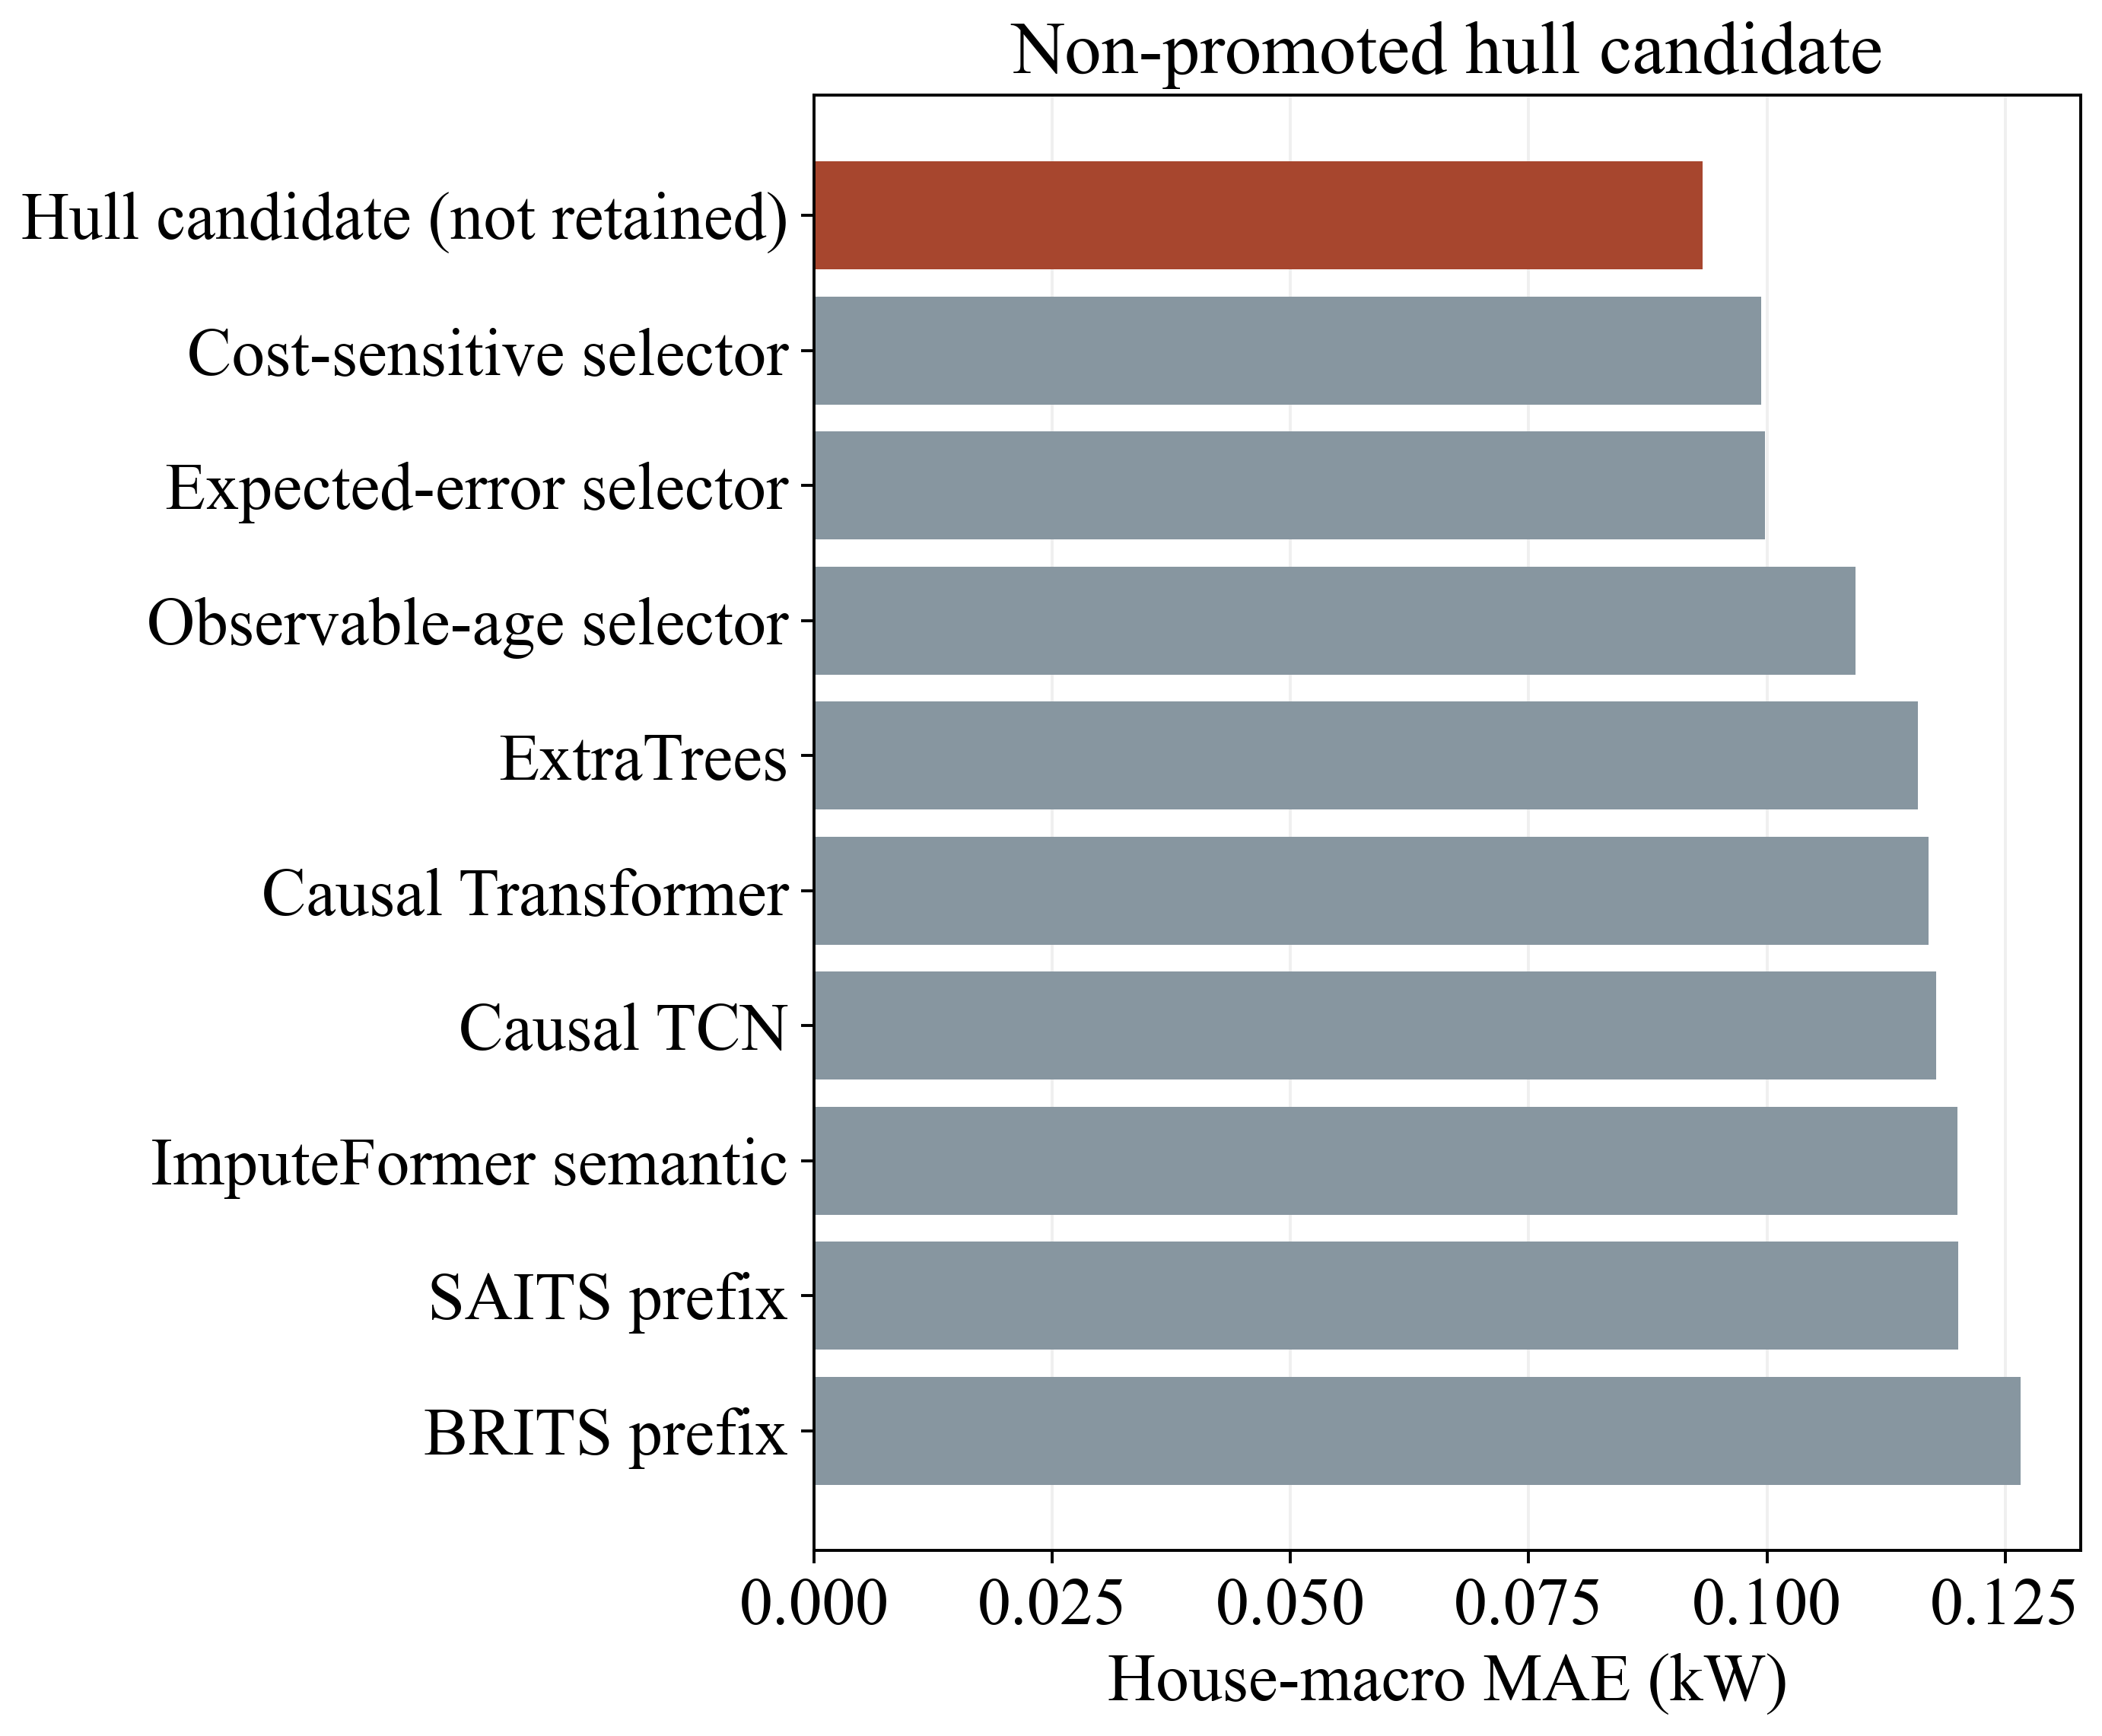

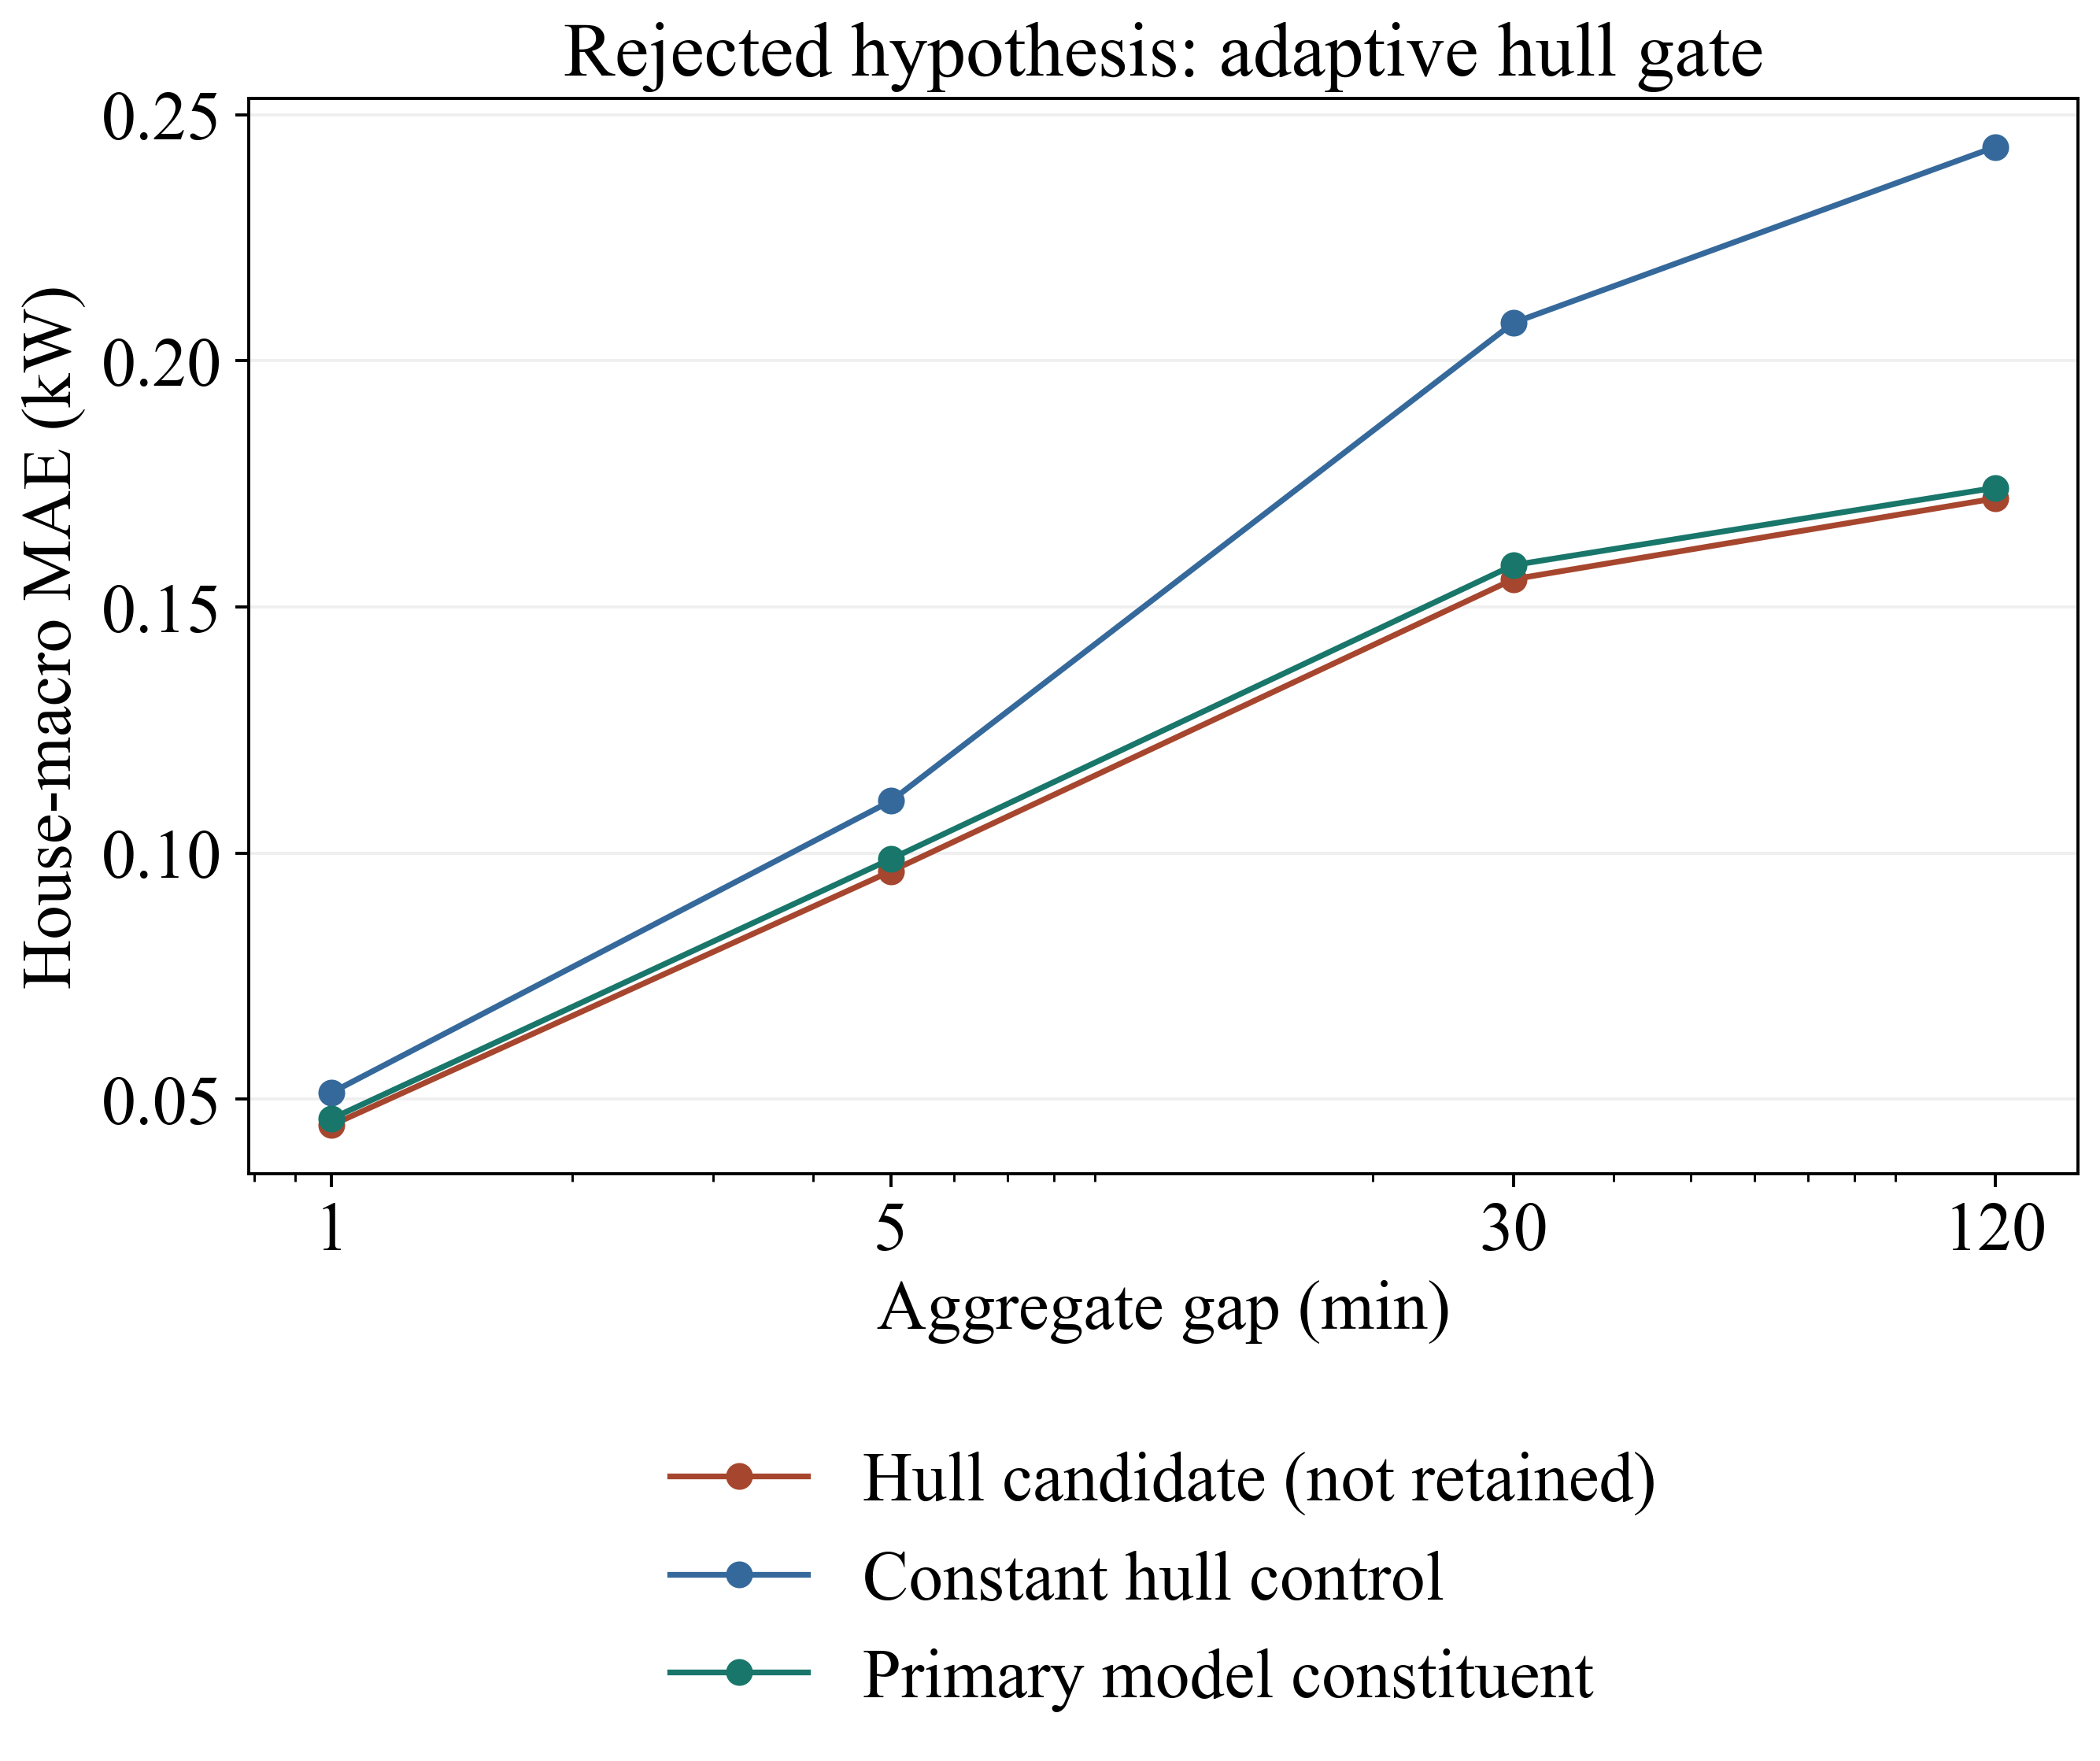

**Development outcome.** Candidate MAE 0.093228 kW, RMSE 0.338325 kW. MAE difference versus strongest baseline CostSensitiveClassifier: 6.24% reduction (negative means worse). Prespecified inner selection criterion met: False. The 10% improvement target is not met. No outer outcome changes the selected gate.

In [9]:
decision=json.loads((REC/"development_decision.json").read_text())
frames=[];resources=[]
for fold in [1,2,3]:
    for seed in [17,43,101]:
        path=PRED/f"hull_fold_{fold}_seed_{seed}.parquet";proof=json.loads((MOD/f"hull_fold_{fold}_seed_{seed}.json").read_text());assert sha(path)==proof["prediction_sha256"]
        frames.append(pd.read_parquet(path));resources.append(proof)
ours=pd.concat(frames,ignore_index=True);assert len(ours)==368640
rows=[];house_rows=[]
for name,col in [("Candidate hull","prediction_kW"),("Constant hull control","constant_prediction_kW"),("Residual expert","residual_expert_kW")]:
    seed_results=[]
    for seed,part in ours.groupby("seed"):
        seed_results.append(metrics(part,part[col]))
        for house,g in part.groupby("house"):house_rows.append({"Model":name,"Seed":seed,"House":house,**metrics(g,g[col])})
    rows.append({"Model":name,**pd.DataFrame(seed_results).mean().to_dict()})
proposed=pd.DataFrame(rows)
old=pd.read_csv(ROOT/"Tables"/R3/"05_pattern_adapter/complete_OOF_comparison.csv")
comparators=old[~old.Model.isin(["Pattern adapter","Frozen proposal","No-pattern control"])][["Model","MAE_kW","RMSE_kW","Bias_kW"]]
comparison=pd.concat([proposed.iloc[:1],comparators],ignore_index=True).sort_values("MAE_kW")
table(comparison,"intermodel_OOF_comparison","Registered non-promoted candidate against all completed baselines and causal modern adaptations; 3 folds × 3 seeds; development remains exploratory.")
table(proposed,"module_ablation","Same immutable constituent experts. Constant hull tests the added adaptive gate; capacity is not matched.")
gaps=[]
for name,col in [("Candidate hull","prediction_kW"),("Constant hull control","constant_prediction_kW"),("Residual expert","residual_expert_kW")]:
    for (seed,gap),g in ours.groupby(["seed","gap"]):gaps.append({"Model":name,"Seed":seed,"Gap_min":gap,**metrics(g,g[col])})
gaps=pd.DataFrame(gaps);gaps.to_csv(TAB/"gap_scores.csv",index=False)
# Paired house-level ablation statistics, seeds averaged before inference.
house=pd.DataFrame(house_rows);house.to_csv(TAB/"house_seed_scores.csv",index=False);stats=[]
for endpoint in ["MAE_kW","RMSE_kW"]:
    wide=house.pivot_table(index=["House","Seed"],columns="Model",values=endpoint)
    for control in ["Constant hull control","Residual expert"]:
        d=(wide["Candidate hull"]-wide[control]).groupby("House").mean().to_numpy();signs=np.array(list(itertools.product([-1.,1.],repeat=len(d))))
        stats.append({"Endpoint":endpoint,"Control":control,"Difference_kW":float(d.mean()),"Exact p":float((abs(signs@d/len(d))>=abs(d.mean())-1e-15).mean())})
stats=pd.DataFrame(stats);pvalues=stats["Exact p"].to_numpy();order=np.argsort(pvalues);adjust=np.minimum(1,np.maximum.accumulate((len(order)-np.arange(len(order)))*pvalues[order]));pout=np.empty(len(order));pout[order]=adjust;stats["Holm p"]=pout
table(stats,"ablation_statistics","Two-sided exact house sign-flip; Holm across both endpoints and both controls. Exploratory development inference.")
def render_presentation_nb05_hull_ablation():
    # Presentation only: exact saved summaries; no fitting or per-query metric calculation.
    from pathlib import Path
    import hashlib
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown, HTML
    from PIL import Image as PILImage
    ROOT = Path.cwd()
    if ROOT.name == "Notebooks":
        ROOT = ROOT.parent
    assert ROOT.is_dir()
    PRESENTATION_RUN = "guldana_n3_20261011_presentation"
    _font = font_manager.findfont("Times New Roman", fallback_to_default=False)
    assert Path(_font).is_file()
    mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
        "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 18,
        "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
        "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42})
    def read_presentation_csv(relative):
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == INPUT_SHA256[relative], relative
        return pd.read_csv(path)
    def save_presentation(fig, name):
        fig.canvas.draw()
        for item in fig.findobj(Text):
            if item.get_visible() and item.get_text().strip():
                assert 18 <= item.get_fontsize() <= 20
                actual = font_manager.FontProperties(fname=font_manager.findfont(item.get_fontproperties(), fallback_to_default=False)).get_name()
                assert actual == "Times New Roman"
        for kind in ["PNG", "PDF"]:
            directory = ROOT / "Figures" / kind / PRESENTATION_RUN
            directory.mkdir(parents=True, exist_ok=True)
            fig.savefig(directory / (name + "." + kind.lower()), dpi=350, bbox_inches="tight", pad_inches=.08)
        png = ROOT / "Figures/PNG" / PRESENTATION_RUN / (name + ".png")
        with PILImage.open(png) as raster:
            assert all(abs(value - 350) < .02 for value in raster.info["dpi"])
        plt.close(fig)
        display(Image(filename=str(png)))

    INPUT_SHA256 = {'Tables/guldana_n3_20261011_v04/05_causal_hull/intermodel_OOF_comparison.csv': 'a80cc37d0b9452ddd37d47804d1ffe26e3becf5fe4c939faa1ae931d47a40f75', 'Tables/guldana_n3_20261011_v04/05_causal_hull/gap_scores.csv': '42efb34fc0bb773778c9d22bab0b11433aa666de3ae0ad07a282be2806b7caba', 'Tables/guldana_n3_20261011_v04/05_causal_hull/module_ablation.csv': '2f904610a0c4a94ccc50048f16102387251d2385df6bcab48e4dadaa016e513e'}

    comparison = read_presentation_csv("Tables/guldana_n3_20261011_v04/05_causal_hull/intermodel_OOF_comparison.csv")
    gaps_saved = read_presentation_csv("Tables/guldana_n3_20261011_v04/05_causal_hull/gap_scores.csv")
    ablations = read_presentation_csv("Tables/guldana_n3_20261011_v04/05_causal_hull/module_ablation.csv")
    assert len(comparison) == 10 and len(ablations) == 3
    labels = {"Candidate hull": "Hull candidate (not retained)", "CostSensitiveClassifier": "Cost-sensitive selector", "ExpectedErrorDifference": "Expected-error selector", "Observable age selector": "Observable-age selector", "Causal-Transformer": "Causal Transformer", "Causal-TCN": "Causal TCN", "ImputeFormer-semantic": "ImputeFormer semantic", "SAITS-prefix": "SAITS prefix", "BRITS-prefix": "BRITS prefix", "ExtraTrees": "ExtraTrees"}
    assert set(comparison.Model) == set(labels)
    fig, ax = plt.subplots(figsize=(8.2, 7.1))
    plot = comparison.sort_values("MAE_kW").reset_index(drop=True)
    y = np.arange(len(plot)); ax.barh(y, plot.MAE_kW, color=["#A7462E" if model == "Candidate hull" else "#8796A0" for model in plot.Model])
    ax.set_yticks(y, [labels[model] for model in plot.Model]); ax.invert_yaxis()
    ax.set(xlabel="House-macro MAE (kW)", title="Non-promoted hull candidate")
    ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
    fig.subplots_adjust(left=.40, right=.98, top=.90, bottom=.13)
    save_presentation(fig, "NB05_hull_candidate_comparison")
    fig, ax = plt.subplots(figsize=(8.2, 7.1))
    for model, label, color in [("Candidate hull", "Hull candidate (not retained)", "#A7462E"), ("Constant hull control", "Constant hull control", "#36699B"), ("Residual expert", "Primary model constituent", "#19766A")]:
        values = gaps_saved.loc[gaps_saved.Model.eq(model)].groupby("Gap_min").MAE_kW.mean().sort_index()
        assert len(values) == 4
        ax.plot(values.index, values.values, marker="o", label=label, color=color)
    ax.set_xscale("log")
    ax.set_xticks(values.index, [str(int(value)) for value in values.index])
    ax.set(xlabel="Aggregate gap (min)", ylabel="House-macro MAE (kW)", title="Rejected hypothesis: adaptive hull gate")
    ax.grid(axis="y", alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), ncol=1, frameon=False)
    fig.subplots_adjust(left=.16, right=.97, top=.90, bottom=.35)
    save_presentation(fig, "NB05_hull_gap_attribution")

render_presentation_nb05_hull_ablation()
best=comparators.loc[comparators.MAE_kW.idxmin()];own=proposed.iloc[0];gain=100*(1-own.MAE_kW/best.MAE_kW)
statement=f"**Development outcome.** Candidate MAE {own.MAE_kW:.6f} kW, RMSE {own.RMSE_kW:.6f} kW. MAE difference versus strongest baseline {best.Model}: {gain:.2f}% reduction (negative means worse). Registered inner promotion: {decision['accepted']}. The 10% superiority target is {('met descriptively' if gain>=10 else 'not met')}. No outer outcome changes the selected gate. Known convex aggregation and boosting do not establish mathematical priority."
display(Markdown(statement));(TAB/"interpretation.md").write_text(statement+"\n")
artifacts={}
for base in [MOD,PRED,TAB,ROOT/"Figures/PNG"/R4,ROOT/"Figures/PDF"/R4]:
    for path in base.rglob("*"):
        if path.is_file():artifacts[str(path.relative_to(ROOT))]=sha(path)
(REC/"development_complete.json").write_text(json.dumps({"run_id":R4,"accepted":decision["accepted"],"search_fits":12,"retained_fits":9,"OOF_rows":len(ours),"MAE_gain_vs_best_percent":gain,"artifacts":artifacts},indent=2)+"\n")


## Matched-sensor changes: one bounded development experiment

**Question.** Can measured appliance changes improve both absolute and squared error when the current aggregate is hidden? Earlier summaries compare unmatched sensor sums, and the rejected convex gate cannot leave its constituent interval. Here $t_0<t$ is the last **observed** aggregate minute and $S_t$ contains only physical auxiliary channels observed at both $t_0$ and $t$. Define
$$a_t=P_{\mathrm{agg}}(t_0)+\sum_{j\in S_t}\{P_j(t)-P_j(t_0)\},\qquad \widehat P_t=\max(0,a_t+h_\theta(z_t)).$$
The residual head learns $P_{\mathrm{agg}}(t)-a_t$ from original training rows. No manual mixing weights are used. Sensor counts, paired coverage, change magnitudes and semantic change sums distinguish missing telemetry from real load changes. The unprojected anchor is retained until the final nonnegative prediction; missing aggregate history has an explicit flag and uses the existing source-trained neural mean.

**Known physical prior and precise scope.** Write $R_S(u)=P_{\mathrm{agg}}(u)-\sum_{j\in S}P_j(u)$. Then $P_{\mathrm{agg}}(t)-a_t=R_{S_t}(t)-R_{S_t}(t_0)$ exactly, without assuming complete metering or a nonnegative residual. This follows by subtraction. The anchor is exact if the unobserved remainder is unchanged and readings are exact. With aggregate-anchor error $\epsilon_0$ and paired sensor errors $\epsilon_{j,t},\epsilon_{j,0}$, its additional error is bounded by $|\epsilon_0|+\sum_j(|\epsilon_{j,t}|+|\epsilon_{j,0}|)$. Simultaneous permutation of physical channels leaves all sums unchanged. Asynchronous windows, duplicate channels and hidden-load changes can invalidate the constant-remainder approximation. The identity is established energy additivity, related to [Deltaflow, equations 10–11](https://www.cs.virginia.edu/~bjc8c/papers/clark14deltaflow.pdf); it is not new mathematics. The empirical hypothesis is the causal matched-change pathway with a learned residual under incomplete telemetry.

**Prespecified budget.** Six search fits only: two losses (absolute and squared error) at the existing 300-tree/31-leaf capacity, three folds, seed 17. Inner MAE selects among candidates meeting the ExtraTrees RMSE guard. If the joint criterion is not met, no further fits are made; if it is met, the one matched-capacity no-pair control and the fixed seeds follow. Prior tests remain retrospective.

In [1]:
from pathlib import Path
import json,hashlib,time,os,gc,joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
R5="guldana_n3_20261011_v05";R3="guldana_n3_20261011_v03";V1="guldana_n3_20261007_v01";V2="guldana_n3_20261009_v02"
REC5=ROOT/"Manifests/Runs"/R5;MOD5=ROOT/"Models/proposed"/R5;PRED5=ROOT/"Predictions/development_proposed"/R5;TAB5=ROOT/"Tables"/R5/"05_matched_changes"
for folder in [MOD5,PRED5,TAB5]:folder.mkdir(parents=True,exist_ok=True)
def sha5(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(8*1024*1024),b""):h.update(b)
    return h.hexdigest()
CFG5=json.loads((ROOT/"Configs/proposed_revision_05.json").read_text());CFG5_SHA=sha5(ROOT/"Configs/proposed_revision_05.json")
LOCK3=json.loads((ROOT/"Manifests/Runs"/R3/"scientific_completion.json").read_text())["artifacts"]
LOCK1=json.loads((ROOT/"Manifests/Runs"/V2/"historical_artifact_lock.json").read_text())["files"]
for relative,digest in json.loads((ROOT/"Manifests/split_freeze.json").read_text())["files"].items():assert sha5(ROOT/relative)==digest
schema5=json.loads((ROOT/"Configs/sensor_schema.json").read_text())
def table5(frame,name,caption):
    frame.to_csv(TAB5/f"{name}.csv",index=False)
    frame.to_latex(TAB5/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.6f}")
    display(frame.style.format(precision=6,na_rep="Unavailable").hide(axis="index").set_caption(caption))
def metrics5(meta,p):
    e=np.asarray(p)-meta.y_kW.to_numpy(float)
    h=pd.DataFrame({"house":meta.house.to_numpy(),"ae":abs(e),"se":e**2,"bias":e}).groupby("house").mean()
    return {"MAE_kW":float(h.ae.mean()),"RMSE_kW":float(np.sqrt(h.se).mean()),"Bias_kW":float(h.bias.mean())}
def weights5(meta):return (len(meta)/meta.house.map(meta.house.value_counts())/meta.house.nunique()).to_numpy(float)


In [2]:
def matched_changes5(history,current,mask,roles,types,scale,base_mean):
    # Private labels, scenario labels and house identifiers are not arguments.
    n,s,l,_=history.shape
    assert l==360 and np.all(roles[:,0]==0) and not mask[:,0].any()
    assert np.isfinite(history).all() and np.isfinite(current).all()
    observed=history[:,0,:,1].astype(bool)
    t0=np.where(observed,np.arange(l),-1).max(1);valid=t0>=0
    row=np.arange(n)[:,None];sensor=np.arange(s)[None,:];ix=t0.clip(0)[:,None]
    past=history[row,sensor,ix,0];past_mask=history[row,sensor,ix,1].astype(bool)
    pairs=mask&past_mask&(roles==1)&valid[:,None]
    delta=np.where(pairs,current-past,0.)*scale
    last=np.where(valid,history[np.arange(n),0,t0.clip(0),0]*scale,base_mean)
    count=pairs.sum(1);coverage=np.where(pairs,history[row,sensor,ix,2],0.)
    features={"match_has_anchor":valid.astype(float),"match_age":np.where(valid,l-t0,l+1),
        "match_delta":delta.sum(1),"match_abs_delta":abs(delta).sum(1),
        "match_positive_delta":np.maximum(delta,0).sum(1),"match_negative_delta":np.minimum(delta,0).sum(1),
        "match_count":count,"match_current_count":(mask&(roles==1)).sum(1),
        "match_past_sum":np.where(pairs,past,0.).sum(1)*scale,
        "match_current_sum":np.where(pairs,current,0.).sum(1)*scale,
        "match_mean_past_coverage":coverage.sum(1)/np.maximum(count,1)}
    for j,name in enumerate(schema5["power_types"]):
        if name!="aggregate":
            features[f"match_type_{j}_delta"]=(delta*(types==j)).sum(1)
            features[f"match_type_{j}_count"]=(pairs&(types==j)).sum(1)
    return pd.DataFrame(features),last+delta.sum(1),last

def input5(fold,seed):
    record_path=ROOT/"Data/Processed"/V1/"modeling_inputs"/f"fold_{fold}_seed_{seed}.json"
    record=json.loads(record_path.read_text());lineage={str(record_path.relative_to(ROOT)):sha5(record_path)}
    for kind in ["array","metadata"]:
        path=ROOT/record[f"{kind}_file"];assert sha5(path)==record[f"{kind}_sha256"];lineage[str(path.relative_to(ROOT))]=sha5(path)
    meta=pd.read_parquet(ROOT/record["metadata_file"]).reset_index(drop=True)
    with np.load(ROOT/record["array_file"],allow_pickle=False) as f:raw=pd.DataFrame(f["raw"],columns=f["input_columns"]);x=f["x"].copy()
    assert not set(raw).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    base_path=ROOT/"Predictions/development_proposed"/R3/f"frozen_base_fold_{fold}_seed_{seed}.parquet"
    previous_path=ROOT/"Predictions/development_proposed"/R3/f"pattern_fold_{fold}_seed_{seed}.parquet"
    for path in [base_path,previous_path]:assert sha5(path)==LOCK3[str(path.relative_to(ROOT))];lineage[str(path.relative_to(ROOT))]=sha5(path)
    base=pd.read_parquet(base_path);previous=pd.read_parquet(previous_path)
    np.testing.assert_array_equal(meta.observation_id,base.observation_id);np.testing.assert_array_equal(meta.observation_id,previous.observation_id)
    mu=base.base_mean.to_numpy(float);variance=base.base_variance.to_numpy(float)
    folder=ROOT/"Data/Processed"/V1/"neural_inputs_v1"/f"fold_{fold}_seed_{seed}"
    manifest_path=folder/"manifest.json";manifest=json.loads(manifest_path.read_text())
    assert manifest["metadata_sha256"]==record["metadata_sha256"]
    arrays={};needed={"history","current_values","current_mask","role_ids","type_ids"}
    for item in manifest["arrays"]:
        name=item["name"][:-4]
        if name in needed:
            path=folder/item["name"];assert sha5(path)==item["sha256"],name
            arrays[name]=np.load(path,mmap_mode="r",allow_pickle=False);lineage[str(path.relative_to(ROOT))]=item["sha256"]
    pp=ROOT/"Models/preprocessing"/V1/f"fold_{fold}_preprocessing.json";assert sha5(pp)==LOCK1[str(pp.relative_to(ROOT))]
    scale=json.loads(pp.read_text())["target_scale"];lineage[str(pp.relative_to(ROOT))]=sha5(pp)
    fs=[];anchors=[];lasts=[];started=time.perf_counter()
    for lo in range(0,len(meta),2048):
        sl=slice(lo,lo+2048)
        feat,anchor,last=matched_changes5(arrays["history"][sl],arrays["current_values"][sl],arrays["current_mask"][sl],arrays["role_ids"][sl],arrays["type_ids"][sl],scale,mu[sl])
        fs.append(feat);anchors.append(anchor);lasts.append(last)
    matched=pd.concat(fs,ignore_index=True);anchor=np.concatenate(anchors);last=np.concatenate(lasts)
    z=raw.copy();z["frozen_mean"]=mu;z["frozen_sigma"]=np.sqrt(variance)
    z["innovation_last"]=z.aggregate_last-mu;z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240;z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    z=pd.concat([z,matched],axis=1);z["match_anchor"]=anchor
    assert not np.isinf(z.to_numpy(float)).any() and np.isfinite(anchor).all()
    # Permuting physical sensors jointly must not change any matched feature or anchor.
    count=min(32,len(meta));perm=np.r_[0,np.arange(arrays["history"].shape[1]-1,0,-1)]
    a,b,c=matched_changes5(arrays["history"][:count][:,perm],arrays["current_values"][:count][:,perm],arrays["current_mask"][:count][:,perm],arrays["role_ids"][:count][:,perm],arrays["type_ids"][:count][:,perm],scale,mu[:count])
    np.testing.assert_allclose(a,matched.iloc[:count],rtol=1e-6,atol=1e-6);np.testing.assert_allclose(b,anchor[:count],rtol=1e-6,atol=1e-6)
    # Unavailable current values cannot affect the observable path.
    changed=np.array(arrays["current_values"][:count],copy=True);changed[~arrays["current_mask"][:count]]=999.
    a,b,c=matched_changes5(arrays["history"][:count],changed,arrays["current_mask"][:count],arrays["role_ids"][:count],arrays["type_ids"][:count],scale,mu[:count])
    np.testing.assert_array_equal(a,matched.iloc[:count]);np.testing.assert_array_equal(b,anchor[:count])
    tree_path=ROOT/"Models/baselines"/V1/f"ExtraTrees_fold_{fold}_seed_{seed}.joblib";assert sha5(tree_path)==LOCK1[str(tree_path.relative_to(ROOT))]
    tree=joblib.load(tree_path)["model"];tree.set_params(n_jobs=1)
    with threadpool_limits(limits=4):tree_pred=tree.predict(x)
    lineage[str(tree_path.relative_to(ROOT))]=sha5(tree_path)
    (REC5/f"inputs_fold_{fold}_seed_{seed}.json").write_text(json.dumps({"lineage":lineage,"feature_seconds":time.perf_counter()-started,"rows":len(meta),"paired_fraction":float(matched.match_count.gt(0).mean()),"sensor_permutation_pass":True,"unobserved_current_values_pass":True},indent=2)+"\n")
    del arrays,x,tree;gc.collect()
    return meta,z,anchor,last,previous.prediction_kW.to_numpy(float),tree_pred


In [3]:
def fit5(meta,z,anchor,loss,fold,seed,control=False):
    train=meta.role.eq("train").to_numpy();assert train.any() and not meta.loc[train,"role"].eq("outer_validation").any()
    model=HistGradientBoostingRegressor(loss=loss,random_state=seed,**CFG5["fixed_parameters"])
    stem=f"{'no_pair' if control else 'paired'}_{loss}_fold_{fold}_seed_{seed}"
    path=MOD5/f"{stem}.joblib";proofpath=path.with_suffix(".json")
    if path.exists():
        proof=json.loads(proofpath.read_text());assert proof["protocol_sha256"]==CFG5_SHA and proof["implementation_sha256"]==IMPL5_SHA and sha5(path)==proof["checkpoint_sha256"]
        return joblib.load(path)["model"],proof
    started=time.perf_counter()
    with threadpool_limits(limits=4):model.fit(z.loc[train],meta.loc[train,"y_kW"].to_numpy()-anchor[train],sample_weight=weights5(meta.loc[train]))
    seconds=time.perf_counter()-started
    joblib.dump({"model":model,"columns":list(z),"loss":loss,"fold":fold,"seed":seed,"no_pair":control,"protocol_sha256":CFG5_SHA,"implementation_sha256":IMPL5_SHA},path)
    proof={"fold":fold,"seed":seed,"loss":loss,"control":control,"fit_rows":int(train.sum()),"fit_seconds":seconds,"actual_leaves":sum(int(t.nodes["is_leaf"].sum()) for stage in model._predictors for t in stage),"protocol_sha256":CFG5_SHA,"implementation_sha256":IMPL5_SHA,"checkpoint_sha256":sha5(path),"kernel_pid":os.getpid()}
    proofpath.write_text(json.dumps(proof,indent=2)+"\n")
    return model,proof

def predict5(model,z,anchor):
    with threadpool_limits(limits=4):p=np.maximum(0,anchor+model.predict(z))
    assert np.isfinite(p).all() and (p>=0).all()
    return p

def search5(fold):
    meta,z,anchor,last,reference,trees=input5(fold,17);inner=meta.role.eq("inner_validation").to_numpy();rows=[]
    for loss in CFG5["losses"]:
        model,proof=fit5(meta,z,anchor,loss,fold,17)
        p=predict5(model,z.loc[inner],anchor[inner]);saved=meta.loc[inner].copy();saved["prediction_kW"]=p
        dest=PRED5/f"inner_{loss}_fold_{fold}_seed_17.parquet";saved.to_parquet(dest,index=False)
        check=joblib.load(MOD5/f"paired_{loss}_fold_{fold}_seed_17.joblib")["model"]
        np.testing.assert_array_equal(p,predict5(check,z.loc[inner],anchor[inner]))
        rows.append({"Fold":fold,"Model":loss,**metrics5(saved,p),"Fit seconds":proof["fit_seconds"]})
        proof.update(prediction_sha256=sha5(dest),prediction=str(dest.relative_to(ROOT)),replay_max_difference=0.)
        (MOD5/f"paired_{loss}_fold_{fold}_seed_17.json").write_text(json.dumps(proof,indent=2)+"\n")
    for name,p in [("Primary reference",reference[inner]),("ExtraTrees",trees[inner]),("Untrained matched anchor",np.maximum(0,anchor[inner]))]:
        rows.append({"Fold":fold,"Model":name,**metrics5(meta.loc[inner],p),"Fit seconds":0.})
    result=pd.DataFrame(rows);table5(result,f"inner_fold_{fold}",f"Fold {fold}: complete inner comparison; matched telemetry only, no test-based selection.")
    return result

bound={c["id"]:"".join(c["source"]) for c in json.loads((ROOT/"Notebooks/05_proposed_model_development_and_ablations.ipynb").read_text())["cells"] if c.get("id","") in {"r5-setup","r5-observable-features","r5-fit-definitions"}}
path=REC5/"prefit_source.json"
if path.exists():assert json.loads(path.read_text())==bound
else:path.write_text(json.dumps(bound,indent=2)+"\n")
IMPL5_SHA=sha5(path)


In [4]:
inner5_1=search5(1)


Fold,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds
1,absolute_error,0.088150,0.356817,−0.034779,11.982215
1,squared_error,0.110577,0.331431,−0.002830,7.865925
1,Primary reference,0.089393,0.354417,−0.037368,0.000000
1,ExtraTrees,0.109795,0.336812,−0.007201,0.000000
1,Untrained matched anchor,0.130693,0.510212,−0.008883,0.000000


In [5]:
inner5_2=search5(2)


Fold,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds
2,absolute_error,0.099164,0.365406,−0.026840,12.007949
2,squared_error,0.118959,0.348279,−0.003600,8.185906
2,Primary reference,0.100872,0.357909,−0.035363,0.000000
2,ExtraTrees,0.120137,0.340465,−0.001786,0.000000
2,Untrained matched anchor,0.139480,0.510678,0.002429,0.000000


In [6]:
inner5_3=search5(3)


Fold,Model,MAE_kW,RMSE_kW,Bias_kW,Fit seconds
3,absolute_error,0.079224,0.298357,−0.020153,12.005918
3,squared_error,0.099689,0.285627,0.009813,8.297874
3,Primary reference,0.081149,0.301278,−0.026217,0.000000
3,ExtraTrees,0.103966,0.298699,0.002434,0.000000
3,Untrained matched anchor,0.115152,0.437243,0.008975,0.000000


In [7]:
results5=pd.concat([pd.read_csv(TAB5/f"inner_fold_{f}.csv") for f in [1,2,3]],ignore_index=True)
selected5=[]
for fold,g in results5.groupby("Fold"):
    ref=g.set_index("Model").loc["Primary reference"];tree=g.set_index("Model").loc["ExtraTrees"]
    candidates=g[g.Model.isin(CFG5["losses"])];eligible=candidates[candidates.RMSE_kW<=tree.RMSE_kW]
    chosen=(eligible if len(eligible) else candidates).sort_values(["MAE_kW","Model"]).iloc[0]
    selected5.append({"Fold":int(fold),"Loss":chosen.Model,"MAE_kW":chosen.MAE_kW,"RMSE_kW":chosen.RMSE_kW,"Reference MAE_kW":ref.MAE_kW,"ExtraTrees RMSE_kW":tree.RMSE_kW,"RMSE guard":bool(len(eligible))})
selection5=pd.DataFrame(selected5);gain5=100*(1-selection5.MAE_kW.mean()/selection5["Reference MAE_kW"].mean())
accepted5=bool(selection5["RMSE guard"].all() and gain5>=2 and selection5.RMSE_kW.mean()<=selection5["ExtraTrees RMSE_kW"].mean())
artifacts5={str(p.relative_to(ROOT)):sha5(p) for folder in [MOD5,PRED5,TAB5] for p in folder.glob('*') if p.is_file()}
decision5={"run_id":R5,"accepted":accepted5,"MAE_gain_pct":gain5,"selections":selected5,"search_fits":6,"outer_predictions_computed":False,"new_independent_validation":False,"protocol_sha256":CFG5_SHA,"artifacts":artifacts5}
(REC5/"development_decision.json").write_text(json.dumps(decision5,indent=2)+"\n")
table5(selection5,"inner_selection","Prespecified joint gate: MAE gain against current primary and RMSE guard against ExtraTrees.")
display(Markdown(f"**Inner-development gate: {'passed' if accepted5 else 'failed'}.** MAE reduction against the current primary: {gain5:.2f}%. Only a passed gate permits the registered control and fixed-seed OOF completion. No test outcome decides this gate."))


Fold,Loss,MAE_kW,RMSE_kW,Reference MAE_kW,ExtraTrees RMSE_kW,RMSE guard
1,squared_error,0.110577,0.331431,0.089393,0.336812,True
2,absolute_error,0.099164,0.365406,0.100872,0.340465,False
3,absolute_error,0.079224,0.298357,0.081149,0.298699,True


**Inner-development criterion: not met.** MAE reduction against the current primary: −6.47%. The control and the fixed-seed OOF fits are run only if the criterion is met. No test outcome enters this decision.

### Decision

The paired-change pathway does not meet the prespecified joint criterion. Absolute-error heads reduce mean inner MAE slightly but worsen RMSE on folds 1–2; squared-error heads trade higher MAE for lower squared error, and fold 2 still exceeds ExtraTrees RMSE. Six declared fits are complete. Further seeds, ablations and new test inference are not justified for this candidate. The single primary point model remains the causal pattern residual model. This is a negative result. Notebook 06 addresses the separate interval-calibration defect using source calibration only.

## Development diagnosis: residual exposure and observable freshness

The scalar correction was fitted to residuals of a neural backbone evaluated on its own training rows. This may differ from the residual distribution on later unseen rows, but chronology and changing load regimes are alternative explanations. The following diagnostic uses only the existing training and inner-validation populations for folds 1–3, seed 17. It fits nothing, reconstructs the retained ExtraTrees inner predictions, and excludes outer-validation and external outcomes from the analysis.

The first table separates training from inner errors for the frozen backbone and full model. The second compares the full model and ExtraTrees on identical inner rows, grouped by **observed aggregate age**, not the simulated gap label. Fixed age bands are 1–5, 6–30, 31–120 and 121–360 minutes, plus unavailable history. Metrics give houses equal weight within each fold, then folds equal weight for the age summary. This is exploratory diagnosis, not a test of superiority or proof that a different training scheme will work.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, time, gc, joblib
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

D6_ROOT=Path.cwd()
if D6_ROOT.name=='Notebooks': D6_ROOT=D6_ROOT.parent
assert D6_ROOT.is_dir()
D6_RUN='guldana_n3_20261012_diagnostic'
D6_REC=D6_ROOT/'Manifests/Runs'/D6_RUN
D6_TAB=D6_ROOT/'Tables'/D6_RUN/'05_development_diagnosis'
D6_PRED=D6_ROOT/'Predictions/development_proposed'/D6_RUN
for directory in [D6_REC,D6_TAB,D6_PRED]: directory.mkdir(parents=True,exist_ok=True)
def d6_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
D6_CFG_PATH=D6_ROOT/'Configs/development_error_diagnosis_20261012.json'
D6_CFG=json.loads(D6_CFG_PATH.read_text())
assert D6_CFG['new_fits']==0
for relative,digest in D6_CFG['fixed_records'].items():
    assert d6_sha(D6_ROOT/relative)==digest, relative

def d6_metrics(meta,pred):
    error=np.asarray(pred,dtype=float)-meta.y_kW.to_numpy(float)
    assert np.isfinite(error).all()
    h=pd.DataFrame({'house':meta.house.to_numpy(),'ae':abs(error),'se':error**2,'bias':error}).groupby('house').mean()
    return {'MAE_kW':float(h.ae.mean()),'RMSE_kW':float(np.sqrt(h.se).mean()),'Bias_kW':float(h.bias.mean()),'Houses':len(h)}

def d6_table(frame,name,caption):
    frame.to_csv(D6_TAB/f'{name}.csv',index=False)
    frame.to_latex(D6_TAB/f'{name}.tex',index=False,caption=caption,float_format=lambda v:f'{v:.6f}')
    def number(v):
        return 'Unavailable' if pd.isna(v) else f'{float(v):.6f}'.replace('-','−')
    formats={c:number for c in frame.select_dtypes(include='number').columns}
    for c in ['Fold','Queries','Houses']:
        if c in frame: formats[c]=lambda v:f'{int(v):,}'
    display(frame.style.format(formats,na_rep='Unavailable').hide(axis='index').set_caption(caption)
        .set_table_styles([{'selector':'th,td','props':[('white-space','normal'),('padding','5px 7px')]},
                          {'selector':'caption','props':[('caption-side','top'),('text-align','left')]}]))

def d6_run():
    phase=[]; age_rows=[]; lineage={str(D6_CFG_PATH.relative_to(D6_ROOT)):d6_sha(D6_CFG_PATH)}
    replay_times=[]; selected_ids={}; inputs_read=[]
    bands=['1–5','6–30','31–120','121–360','Unavailable']
    for fold in [1,2,3]:
        stem=f'fold_{fold}_seed_17'
        record_path=D6_ROOT/f'Data/Processed/guldana_n3_20261007_v01/modeling_inputs/{stem}.json'
        record=json.loads(record_path.read_text())
        meta_path=D6_ROOT/record['metadata_file']; array_path=D6_ROOT/record['array_file']
        assert d6_sha(meta_path)==record['metadata_sha256'] and d6_sha(array_path)==record['array_sha256']
        # Full identity/role columns establish array positions without opening outer targets.
        identities=pd.read_parquet(meta_path,columns=['observation_id','role'])
        allowed=identities.role.isin(['train','inner_validation']).to_numpy()
        inner_position=np.flatnonzero(identities.role.eq('inner_validation').to_numpy())
        meta=pd.read_parquet(meta_path,filters=[('role','in',['train','inner_validation'])]).reset_index(drop=True)
        np.testing.assert_array_equal(meta.observation_id,identities.loc[allowed,'observation_id'])
        assert meta.role.value_counts().to_dict()=={'train':65530,'inner_validation':10240}
        assert meta.observation_id.is_unique and meta.fold.eq(fold).all() and meta.seed.eq(17).all()
        proof_path=D6_ROOT/f'Models/proposed/guldana_n3_20261011_v03/pattern_{stem}.json'
        proof=json.loads(proof_path.read_text())
        point_path=D6_ROOT/f'Predictions/development_proposed/guldana_n3_20261011_v03/pattern_{stem}.parquet'
        assert d6_sha(point_path)==proof['prediction_sha256']
        primary=pd.read_parquet(point_path,filters=[('role','in',['train','inner_validation'])]).reset_index(drop=True)
        np.testing.assert_array_equal(primary.observation_id,meta.observation_id)
        np.testing.assert_array_equal(primary.y_kW,meta.y_kW)
        np.testing.assert_array_equal(primary.role,meta.role)
        for role in ['train','inner_validation']:
            keep=meta.role.eq(role).to_numpy()
            for model,column in [('Frozen backbone','base_mean_kW'),('Full model','prediction_kW')]:
                phase.append({'Fold':fold,'Sample':role,'Model':model,**d6_metrics(meta.loc[keep],primary.loc[keep,column])})
        inner=meta.loc[meta.role.eq('inner_validation')].reset_index(drop=True)
        current=primary.loc[primary.role.eq('inner_validation')].reset_index(drop=True)
        np.testing.assert_array_equal(inner.observation_id,identities.iloc[inner_position].observation_id)
        with np.load(array_path,allow_pickle=False) as data:
            columns=data['input_columns'].astype(str)
            needed=['aggregate_age','aggregate_last','current_aux_count','installed_aux_count']
            raw=pd.DataFrame(data['raw'][inner_position][:,[list(columns).index(c) for c in needed]],columns=needed)
            x=data['x'][inner_position].copy()
        assert len(raw)==len(inner) and len(x)==len(inner)
        age=raw.aggregate_age.to_numpy(float)
        last=raw.aggregate_last.to_numpy(float)
        assert np.isfinite(age).all() and (age>=1).all() and (age<=361).all()
        unavailable=(age>360)|~np.isfinite(last)
        labels=np.select([unavailable,age<=5,age<=30,age<=120,age<=360],['Unavailable','1–5','6–30','31–120','121–360'],default='INVALID')
        assert not (labels=='INVALID').any()
        resources_path=D6_ROOT/f'Models/baselines/guldana_n3_20261007_v01/ExtraTrees_{stem}_resources.json'
        resources=json.loads(resources_path.read_text())
        checkpoint=resources_path.with_name(f'ExtraTrees_{stem}.joblib')
        assert d6_sha(checkpoint)==resources['model_sha256']
        model=joblib.load(checkpoint)['model']; model.n_jobs=1
        started=time.perf_counter()
        with threadpool_limits(limits=4): tree=model.predict(x)
        replay_times.append({'Fold':fold,'Queries':len(inner),'Frozen_predict_seconds':time.perf_counter()-started})
        # Match the already executed original inner comparator summary; no prediction repair.
        reference_path=D6_ROOT/f'Tables/guldana_n3_20261011_v05/05_matched_changes/inner_fold_{fold}.csv'
        reference=pd.read_csv(reference_path).set_index('Model')
        for name,pred,oldname in [('Full model',current.prediction_kW.to_numpy(),'Primary reference'),('ExtraTrees',tree,'ExtraTrees')]:
            check=d6_metrics(inner,pred)
            for metric in ['MAE_kW','RMSE_kW','Bias_kW']:
                np.testing.assert_allclose(check[metric],reference.loc[oldname,metric],rtol=1e-10,atol=1e-12)
            for band in bands:
                keep=labels==band
                if keep.any():age_rows.append({'Fold':fold,'Age':band,'Queries':int(keep.sum()),'Model':name,**d6_metrics(inner.loc[keep],np.asarray(pred)[keep])})
        out=inner[['fold','seed','house','observation_id','role','y_kW']].copy()
        out['observed_age_min']=age;out['age_band']=labels;out['Full model']=current.prediction_kW.to_numpy();out['ExtraTrees']=tree
        destination=D6_PRED/f'inner_diagnostic_{stem}.parquet';out.to_parquet(destination,index=False)
        selected_ids[str(fold)]=hashlib.sha256('\n'.join(inner.observation_id.astype(str)).encode()).hexdigest()
        for path in [record_path,meta_path,array_path,proof_path,point_path,resources_path,checkpoint,reference_path,destination]:
            lineage[str(path.relative_to(D6_ROOT))]=d6_sha(path)
        inputs_read.append({'fold':fold,'roles':['train','inner_validation'],'inner_rows':len(inner),'training_rows':65530})
        del model,x,raw,meta,primary,inner,current,out;gc.collect()
    phase=pd.DataFrame(phase)
    phase.to_csv(D6_TAB/'phase_complete_metrics.csv',index=False)
    d6_table(phase.drop(columns=['Houses']).rename(columns={'MAE_kW':'MAE (kW)','RMSE_kW':'RMSE (kW)','Bias_kW':'Bias (kW)'}),
             'train_inner_comparison','Seed 17, development only. Within each fold and sample, households receive equal weight. Training errors are in-sample; inner errors are later in time.')
    detailed=pd.DataFrame(age_rows);detailed.to_csv(D6_TAB/'age_fold_complete_metrics.csv',index=False)
    summary=detailed.groupby(['Age','Model'],sort=False).agg(Queries=('Queries','sum'),MAE_kW=('MAE_kW','mean'),RMSE_kW=('RMSE_kW','mean'),Bias_kW=('Bias_kW','mean'),Folds=('Fold','nunique'),Min_houses=('Houses','min'),Max_houses=('Houses','max')).reset_index()
    summary['order']=summary.Age.map({band:i for i,band in enumerate(bands)})
    summary=summary.sort_values(['order','Model']).drop(columns=['order']).reset_index(drop=True)
    assert summary.groupby('Model').Queries.sum().eq(30720).all()
    summary.to_csv(D6_TAB/'age_summary_with_support.csv',index=False)
    d6_table(summary[['Age','Queries','Model','MAE_kW','RMSE_kW','Bias_kW']].rename(columns={'Age':'Age (min)','MAE_kW':'MAE (kW)','RMSE_kW':'RMSE (kW)','Bias_kW':'Bias (kW)'}),
             'inner_observed_age_comparison','Identical inner queries for both models. Equal household means within each represented fold, then equal fold means; absent groups are not replaced by zeros.')
    support=summary[['Age','Folds','Min_houses','Max_houses']].drop_duplicates()
    display(Markdown('**Stratum support.** '+'; '.join(f"{a.Age} min: {int(a.Folds)} folds, {int(a.Min_houses)}–{int(a.Max_houses)} houses per fold" for a in support.itertuples())+'. Counts are seed-query rows; repeated folds are not independent homes.'))
    pivot=phase.pivot(index=['Fold','Model'],columns='Sample',values='MAE_kW')
    counts=(pivot.inner_validation>pivot.train).groupby('Model').sum()
    text=(f"**Diagnostic limit.** Inner MAE exceeds training MAE in {int(counts['Frozen backbone'])}/3 folds for the backbone and {int(counts['Full model'])}/3 for the full model. "
          'This can reflect in-sample exposure, chronology or changes in load regimes. It does not identify a cause, authorize a correction from inner errors, or show that a new head will improve unseen data. '
          'The age comparison uses observable freshness only; no fitted offsets, new weights or target-based bins are introduced.')
    display(Markdown(text));(D6_TAB/'interpretation.md').write_text(text+'\n')
    pd.DataFrame(replay_times).to_csv(D6_TAB/'frozen_replay_resources.csv',index=False)
    notebook=json.loads((D6_ROOT/'Notebooks/05_proposed_model_development_and_ablations.ipynb').read_text())
    source={c['id']:hashlib.sha256(''.join(c['source']).encode()).hexdigest() for c in notebook['cells'] if c.get('id','').startswith('development-diagnosis-')}
    outputs={str(p.relative_to(D6_ROOT)):d6_sha(p) for p in D6_TAB.iterdir() if p.is_file()}
    result={'run_id':D6_RUN,'status':'development_diagnostic_complete','UTC':datetime.now(timezone.utc).isoformat(),'source_cells':source,
            'input_and_prediction_files':lineage,'outputs':outputs,'new_fits':0,'frozen_predict_calls':3,'new_tests':0,
            'used_roles':inputs_read,'external_or_outer_outcomes_used':False,'selection_or_promotion_performed':False,'inner_id_sha256':selected_ids}
    (D6_REC/'completion.json').write_text(json.dumps(result,indent=2)+'\n')
    return result


In [2]:
D6_RESULT=d6_run()


Fold,Sample,Model,MAE (kW),RMSE (kW),Bias (kW)
1,train,Frozen backbone,0.096205,0.332229,−0.033728
1,train,Full model,0.073485,0.309143,−0.029014
1,inner_validation,Frozen backbone,0.112578,0.375025,−0.038613
1,inner_validation,Full model,0.089393,0.354417,−0.037368
2,train,Frozen backbone,0.112688,0.358866,−0.037678
2,train,Full model,0.080854,0.328777,−0.033496
2,inner_validation,Frozen backbone,0.133319,0.382759,−0.040605
2,inner_validation,Full model,0.100872,0.357909,−0.035363
3,train,Frozen backbone,0.111429,0.374012,−0.036567
3,train,Full model,0.084313,0.343526,−0.033904


Age (min),Queries,Model,MAE (kW),RMSE (kW),Bias (kW)
1–5,"20,311",ExtraTrees,0.066031,0.210480,0.001678
1–5,"20,311",Full model,0.055192,0.230364,−0.002967
6–30,"5,158",ExtraTrees,0.195633,0.465879,−0.006958
6–30,"5,158",Full model,0.156744,0.467366,−0.079235
31–120,"5,072",ExtraTrees,0.201361,0.451689,−0.010889
31–120,"5,072",Full model,0.159907,0.457054,−0.101113
121–360,166,ExtraTrees,0.210345,0.322192,−0.023893
121–360,166,Full model,0.174418,0.299965,−0.136156
Unavailable,13,ExtraTrees,0.877529,0.896185,−0.446881
Unavailable,13,Full model,0.857510,0.899168,−0.822303


**Stratum support.** 1–5 min: 3 folds, 10–10 houses per fold; 6–30 min: 3 folds, 10–10 houses per fold; 31–120 min: 3 folds, 10–10 houses per fold; 121–360 min: 3 folds, 7–10 houses per fold; Unavailable min: 3 folds, 1–1 houses per fold. Counts are seed-query rows; repeated folds are not independent homes.

**Diagnostic limit.** Inner MAE exceeds training MAE in 2/3 folds for the backbone and 2/3 for the full model. This can reflect in-sample exposure, chronology or changes in load regimes. It does not identify a cause, justify a correction from inner errors, or show that a new head will improve unseen data. The age comparison uses observable freshness only; no fitted offsets, new weights or target-based bins are introduced.

### Interpretation

The full model has lower MAE than ExtraTrees in every displayed age group, but lower RMSE only at 121–360 minutes. That group contains 166 queries; unavailable history contains only 13. These sparse groups cannot establish robustness. The common 1–5-minute group already shows the MAE–RMSE trade-off, so stale history alone does not explain it.

The two-of-three-fold train–inner gap motivates checking residual-head training exposure, but does not distinguish it from chronological distribution change. No new architecture is selected by this diagnostic. Any subsequent correction must be learned within development and tested with the same inputs and a matched control; no manual offset follows from the observed bias.

A hard auxiliary-sum lower bound is also unsupported by the measurement analysis in Notebook 01: complete observed sets can have an auxiliary sum above measured aggregate power, and minute alignment does not establish simultaneous sampling or disjoint circuits. Clipping the scalar prediction to that sum would impose an unverified measurement constraint. The signed remainder is retained; no such clamp is fitted or adopted. See the [data-semantics assessment](../Docs/data_card.md).

## Fixed training-population check

The preceding diagnostic leaves two explanations unresolved: training exposure and chronological distribution change. We test one unchanged absolute-error residual head on the first 60% of each house's existing inner timestamps, with a 360-minute purge before the common suffix. A control fits the same learner on an equal number of original-training rows in every house × masking-scenario stratum, selected by a fixed hash of observation IDs. The control matches sample counts and nominal capacity, not calendar time. The backbone, 178 input slots, loss and hyperparameters are unchanged.

This is a new **six-fit adaptive experiment**, not a rerun of the previous zero-fit diagnostic. It includes three folds and seed 17, with no hyperparameter search. The frozen primary predictor, ExtraTrees and both learned selectors are evaluated on the same suffix. Existing checkpoint selection and selector tuning used the wider inner role, so these are exploratory results, not an independent test or a clean causal estimate of exposure.

Before fitting, all three partitions and exact quotas are frozen. Continuation requires at least 10% lower mean MAE than the best included baseline, lower mean RMSE than every included reference, improvement over the matched training control, and no fold-level RMSE regression against the primary model or ExtraTrees. A failed screen cannot be rescued by changing the split or objective. A passed screen alone would not justify replacing the primary model. Outer and external outcomes are not used.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, time, gc, joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

E6_ROOT=Path.cwd()
if E6_ROOT.name=='Notebooks': E6_ROOT=E6_ROOT.parent
assert E6_ROOT.is_dir()
E6_RUN='guldana_n3_20261012_exposure_check'
E6_REC=E6_ROOT/'Manifests/Runs'/E6_RUN
E6_TAB=E6_ROOT/'Tables'/E6_RUN/'05_training_population'
E6_MOD=E6_ROOT/'Models/proposed'/E6_RUN
E6_PRED=E6_ROOT/'Predictions/development_proposed'/E6_RUN
for directory in [E6_REC,E6_TAB,E6_MOD,E6_PRED]:directory.mkdir(parents=True,exist_ok=True)
def e6_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
E6_CFG_PATH=E6_ROOT/'Configs/development_exposure_check_20261012.json'
E6_CFG=json.loads(E6_CFG_PATH.read_text());E6_CFG_SHA=e6_sha(E6_CFG_PATH)
assert E6_CFG['new_fit_budget']==6 and E6_CFG['new_search_trials']==0
for relative,digest in E6_CFG['fixed_records'].items():assert e6_sha(E6_ROOT/relative)==digest,relative
E6_SELECTOR_LOCK=json.loads((E6_ROOT/'Manifests/Runs/guldana_n3_20261009_v02/nb03_selector_gate.json').read_text())['files']
for relative,digest in json.loads((E6_ROOT/'Manifests/split_freeze.json').read_text())['files'].items():assert e6_sha(E6_ROOT/relative)==digest
def r3_features(raw,mu,variance,patterns=True):
    # Only frozen audited input columns; metadata and labels never enter this function.
    z=raw.reset_index(drop=True).copy()
    assert not set(z).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    z["frozen_mean"]=mu;z["frozen_sigma"]=np.sqrt(variance)
    z["innovation_last"]=z.aggregate_last-mu
    z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240
    z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    if not patterns:
        removed=[c for c in z if (c.startswith("aggregate_") and c not in {"aggregate_lag_1440","aggregate_lag_10080"}) or c.startswith("innovation_")]
        z.loc[:,removed]=0.
    a=z.to_numpy(dtype=np.float64)
    assert not np.isinf(a).any() and np.isfinite(mu).all() and (np.asarray(variance)>0).all()
    return z


def meta_roles(meta):
    fit=np.zeros(len(meta),bool);validation=fit.copy();records=[]
    for house,part in meta.loc[meta.role.eq("inner_validation")].groupby("house"):
        times=np.sort(part.timestamp.unique());cut=times[max(0,int(len(times)*.6)-1)]
        a=part.index[part.timestamp<=cut];b=part.index[part.timestamp>pd.Timestamp(cut)+pd.Timedelta(minutes=360)]
        assert len(a)>=64 and len(b)>=32,(house,len(a),len(b))
        fit[a]=True;validation[b]=True
        assert meta.loc[a,"timestamp"].max()+pd.Timedelta(minutes=360)<meta.loc[b,"timestamp"].min()
        records.append({"House":house,"Gate train":len(a),"Gate validation":len(b),"Cutoff":str(cut)})
    assert not (fit&validation).any()
    return fit,validation,pd.DataFrame(records)


def fallback_prediction(raw,meta,train):
    medians=meta.loc[train].groupby("house").y_kW.median();global_median=float(meta.loc[train,"y_kW"].median())
    fallback=meta.house.map(medians).fillna(global_median).to_numpy()
    last=raw.aggregate_last.to_numpy(dtype=float)
    return np.where(np.isfinite(last),last,fallback)


def gate_features(raw,expert):
    cols=["hour_sin","hour_cos","weekday_sin","weekday_cos","year_sin","year_cos",
        "aggregate_age","aggregate_last","aggregate_mean_15","aggregate_mean_60","aggregate_mean_240",
        "aggregate_std_60","aggregate_std_240","aggregate_coverage_15","aggregate_coverage_60","aggregate_coverage_240",
        "aggregate_lag_1440","aggregate_lag_10080","current_aux_count","installed_aux_count","current_aux_sum"]
    features=raw[cols].copy().reset_index(drop=True)
    features["last_expert"]=expert[:,0];features["tree_expert"]=expert[:,1]
    features["expert_disagreement"]=np.abs(expert[:,0]-expert[:,1])
    assert not np.isinf(features.to_numpy()).any()
    return features


def selected_prediction(model,family,features,expert):
    use_tree=model.predict_proba(features)[:,1]>.5 if family=="CostSensitiveClassifier" else model.predict(features)<0
    return np.where(use_tree,expert[:,1],expert[:,0]),use_tree

def e6_metrics(meta,pred):
    error=np.asarray(pred,dtype=float)-meta.y_kW.to_numpy(float)
    assert np.isfinite(error).all()
    h=pd.DataFrame({'house':meta.house.to_numpy(),'ae':abs(error),'se':error**2,'bias':error}).groupby('house').mean()
    return {'MAE_kW':float(h.ae.mean()),'RMSE_kW':float(np.sqrt(h.se).mean()),'Bias_kW':float(h.bias.mean()),'Houses':len(h)}

def e6_table(frame,name,caption):
    frame.to_csv(E6_TAB/f'{name}.csv',index=False)
    frame.to_latex(E6_TAB/f'{name}.tex',index=False,caption=caption,float_format=lambda v:f'{v:.6f}')
    def number(v):
        return 'Unavailable' if pd.isna(v) else f'{float(v):.6f}'.replace('-','−')
    formats={c:number for c in frame.select_dtypes(include='number').columns}
    for c in ['Fold','Queries','Houses','Fit rows','Actual leaves']:
        if c in frame: formats[c]=lambda v:f'{int(v):,}'
    display(frame.style.format(formats,na_rep='Unavailable').hide(axis='index').set_caption(caption)
        .set_table_styles([{'selector':'th,td','props':[('white-space','normal'),('padding','5px 7px')]},
                          {'selector':'caption','props':[('caption-side','top'),('text-align','left')]}]))


def e6_json(path,record):
    path=Path(path)
    assert not path.exists(), 'Existing experiment evidence is immutable.'
    path.write_text(json.dumps(record,indent=2,allow_nan=False)+'\n')

def e6_metadata(fold):
    record_path=E6_ROOT/f'Data/Processed/guldana_n3_20261007_v01/modeling_inputs/fold_{fold}_seed_17.json'
    record=json.loads(record_path.read_text());path=E6_ROOT/record['metadata_file']
    assert e6_sha(path)==record['metadata_sha256']
    identities=pd.read_parquet(path,columns=['observation_id','role'])
    positions=np.flatnonzero(identities.role.isin(['train','inner_validation']).to_numpy())
    meta=pd.read_parquet(path,filters=[('role','in',['train','inner_validation'])]).reset_index(drop=True)
    np.testing.assert_array_equal(meta.observation_id,identities.iloc[positions].observation_id)
    assert meta.observation_id.is_unique and meta.fold.eq(fold).all() and meta.seed.eq(17).all()
    assert meta.role.value_counts().to_dict()=={'train':65530,'inner_validation':10240}
    return meta,positions,record

def e6_register():
    assert not (E6_REC/'prefit.json').exists()
    nb=json.loads((E6_ROOT/'Notebooks/05_proposed_model_development_and_ablations.ipynb').read_text())
    source={c['id']:hashlib.sha256(''.join(c['source']).encode()).hexdigest() for c in nb['cells'] if c.get('id','').startswith('exposure-check-')}
    assert len(source)==3
    splits={};shortages=[];counts=[]
    for fold in E6_CFG['folds']:
        meta,positions,record=e6_metadata(fold)
        fit,valid,cutoffs=meta_roles(meta)
        train=meta.role.eq('train').to_numpy();control=np.zeros(len(meta),bool)
        columns=E6_CFG['quota_columns']
        grouped=meta.loc[train].groupby(columns,dropna=False).groups
        for key,part in meta.loc[fit].groupby(columns,dropna=False):
            pool=grouped.get(key,[])
            if len(pool)<len(part):
                shortages.append({'Fold':fold,'stratum':str(key),'required':len(part),'available':len(pool)});continue
            ranked=sorted(pool,key=lambda ix:hashlib.sha256((E6_CFG['sampling_salt']+'|'+str(fold)+'|'+str(meta.loc[ix,'observation_id'])).encode()).hexdigest())
            control[ranked[:len(part)]]=True
        if any(s['Fold']==fold for s in shortages):continue
        a=meta.loc[fit].groupby(columns,dropna=False).size().sort_index()
        b=meta.loc[control].groupby(columns,dropna=False).size().sort_index()
        pd.testing.assert_series_equal(a,b)
        assert fit.sum()==control.sum() and not (fit&control).any() and not ((fit|control)&valid).any()
        assert meta.loc[fit|valid,'role'].eq('inner_validation').all() and meta.loc[control,'role'].eq('train').all()
        for house in meta.house.unique():
            take=meta.house.eq(house).to_numpy()
            assert meta.loc[take&valid,'timestamp'].min()>meta.loc[take&(fit|control),'timestamp'].max()+pd.Timedelta(minutes=360)
        split=meta[['observation_id','house','timestamp','role','mode','gap','retention']].copy()
        split['partition']=np.select([fit,control,valid],['head_fit','matched_train','suffix'],default='excluded')
        split=split[split.partition.ne('excluded')]
        path=E6_REC/f'partitions_fold_{fold}.parquet';split.to_parquet(path,index=False)
        splits[str(fold)]={'path':str(path.relative_to(E6_ROOT)),'sha256':e6_sha(path),'head_fit':int(fit.sum()),'matched_train':int(control.sum()),'suffix':int(valid.sum()),'cutoffs':cutoffs.to_dict('records')}
        counts.append({'Fold':fold,'Head fit':int(fit.sum()),'Matched train':int(control.sum()),'Validation':int(valid.sum())})
    result={'status':'quota_infeasible' if shortages else 'ready','run_id':E6_RUN,'utc':datetime.now(timezone.utc).isoformat(),'protocol_sha256':E6_CFG_SHA,'source_cells':source,'splits':splits,'shortages':shortages,'new_fits':0,'kernel_pid':os.getpid()}
    e6_json(E6_REC/'prefit.json',result)
    return result

def e6_run_fold(fold,prefit):
    meta,positions,record=e6_metadata(fold);stem=f'fold_{fold}_seed_17'
    sp=prefit['splits'][str(fold)];assert e6_sha(E6_ROOT/sp['path'])==sp['sha256']
    partition=pd.read_parquet(E6_ROOT/sp['path']).set_index('observation_id').partition
    labels=meta.observation_id.map(partition).fillna('excluded')
    fit=labels.eq('head_fit').to_numpy();control=labels.eq('matched_train').to_numpy();valid=labels.eq('suffix').to_numpy()
    lineage={};array_path=E6_ROOT/record['array_file'];assert e6_sha(array_path)==record['array_sha256']
    with np.load(array_path,allow_pickle=False) as a:
        raw=pd.DataFrame(a['raw'][positions],columns=a['input_columns']);x=a['x'][positions[valid]].copy()
    base_dir=E6_ROOT/'Predictions/development_proposed/guldana_n3_20261011_v03'
    base_path=base_dir/f'frozen_base_{stem}.parquet';base_proof=json.loads((base_dir/f'frozen_base_{stem}.json').read_text())
    assert e6_sha(base_path)==base_proof['prediction_sha256']
    base=pd.read_parquet(base_path,filters=[('role','in',['train','inner_validation'])]).reset_index(drop=True)
    for c in ['observation_id','role','y_kW']:np.testing.assert_array_equal(base[c],meta[c])
    mu=base.base_mean.to_numpy(float);variance=base.base_variance.to_numpy(float)
    z=r3_features(raw,mu,variance);assert z.shape==(len(meta),178)
    primary_proof_path=E6_ROOT/f'Models/proposed/guldana_n3_20261011_v03/pattern_{stem}.json'
    primary_proof=json.loads(primary_proof_path.read_text());primary_path=base_dir/f'pattern_{stem}.parquet'
    primary_model=primary_proof_path.with_suffix('.joblib')
    assert e6_sha(primary_path)==primary_proof['prediction_sha256'] and e6_sha(primary_model)==primary_proof['checkpoint_sha256']
    primary=pd.read_parquet(primary_path,filters=[('role','in',['train','inner_validation'])]).reset_index(drop=True)
    np.testing.assert_array_equal(primary.observation_id,meta.observation_id)
    original=joblib.load(primary_model);assert original['feature_columns']==list(z)
    with threadpool_limits(limits=4):replay=np.maximum(0,mu[valid]+original['model'].predict(z.loc[valid]))
    np.testing.assert_allclose(replay,primary.loc[valid,'prediction_kW'],rtol=0,atol=1e-12)
    predictions={'Primary reference':replay};resources=[]
    suffix=meta.loc[valid].reset_index(drop=True)
    tree_path=E6_ROOT/f'Models/baselines/guldana_n3_20261007_v01/ExtraTrees_{stem}.joblib'
    tree_proof=json.loads(tree_path.with_name(f'ExtraTrees_{stem}_resources.json').read_text());assert e6_sha(tree_path)==tree_proof['model_sha256']
    tree=joblib.load(tree_path)['model'];tree.n_jobs=1
    with threadpool_limits(limits=4):predictions['ExtraTrees']=tree.predict(x)
    diag_path=E6_ROOT/f'Predictions/development_proposed/guldana_n3_20261012_diagnostic/inner_diagnostic_{stem}.parquet'
    diag=pd.read_parquet(diag_path).set_index('observation_id').loc[suffix.observation_id]
    np.testing.assert_allclose(predictions['ExtraTrees'],diag.ExtraTrees,rtol=0,atol=1e-12)
    last=fallback_prediction(raw,meta,meta.role.eq('train').to_numpy())[valid]
    expert=np.column_stack([last,predictions['ExtraTrees']]);features=gate_features(raw.loc[valid],expert)
    for name in ['CostSensitiveClassifier','ExpectedErrorDifference']:
        path=E6_ROOT/f'Models/baselines/guldana_n3_20261009_v02/{name}_{stem}.joblib'
        assert e6_sha(path)==E6_SELECTOR_LOCK[str(path.relative_to(E6_ROOT))]
        bundle=joblib.load(path);assert bundle['feature_columns']==list(features) and bundle['expert_checkpoint_sha256']==e6_sha(tree_path)
        pseudo=E6_ROOT/f'Data/Processed/guldana_n3_20261009_v02/selector_crossfit/pseudo_OOF_{stem}.parquet'
        assert e6_sha(pseudo)==bundle['pseudo_OOF_sha256']
        with threadpool_limits(limits=4):predictions[name]=selected_prediction(bundle['model'],name,features,expert)[0]
        lineage[str(path.relative_to(E6_ROOT))]=e6_sha(path)
        lineage[str(pseudo.relative_to(E6_ROOT))]=e6_sha(pseudo)
    target=meta.y_kW.to_numpy(float)-mu
    for name,mask,tag in [('Out-of-fit head',fit,'out_of_fit'),('Matched train head',control,'matched_train')]:
        path=E6_MOD/f'{tag}_{stem}.joblib';assert not path.exists()
        house=meta.loc[mask,'house'];weight=(len(house)/(house.nunique()*house.map(house.value_counts()))).to_numpy(float)
        model=HistGradientBoostingRegressor(**E6_CFG['parameters'],random_state=17)
        started=time.perf_counter()
        with threadpool_limits(limits=4):model.fit(z.loc[mask],target[mask],sample_weight=weight)
        seconds=time.perf_counter()-started
        started=time.perf_counter()
        with threadpool_limits(limits=4):prediction=np.maximum(0,mu[valid]+model.predict(z.loc[valid]))
        prediction_seconds=time.perf_counter()-started
        assert np.isfinite(prediction).all() and (prediction>=0).all()
        bundle={'model':model,'feature_columns':list(z),'protocol_sha256':E6_CFG_SHA,'prefit_sha256':e6_sha(E6_REC/'prefit.json'),'source_backbone_sha256':base_proof['checkpoint_sha256']}
        joblib.dump(bundle,path,compress=3)
        with threadpool_limits(limits=4):reloaded=np.maximum(0,mu[valid]+joblib.load(path)['model'].predict(z.loc[valid]))
        np.testing.assert_array_equal(prediction,reloaded)
        leaves=sum(int(t.nodes['is_leaf'].sum()) for stage in model._predictors for t in stage)
        proof={'fold':fold,'seed':17,'name':name,'fit_rows':int(mask.sum()),'fit_seconds':seconds,'predict_seconds':prediction_seconds,'actual_leaves':leaves,'checkpoint_sha256':e6_sha(path),'training_id_sha256':hashlib.sha256('\n'.join(meta.loc[mask,'observation_id']).encode()).hexdigest(),'protocol_sha256':E6_CFG_SHA,'prefit_sha256':e6_sha(E6_REC/'prefit.json'),'kernel_pid':os.getpid(),'replay_max_difference':0.0}
        e6_json(path.with_suffix('.json'),proof);predictions[name]=prediction
        resources.append({'Fold':fold,'Model':name,'Fit rows':int(mask.sum()),'Fit seconds':seconds,'Predict seconds':prediction_seconds,'Actual leaves':leaves})
        del model;gc.collect()
    rows=[{'Fold':fold,'Model':name,**e6_metrics(suffix,p)} for name,p in predictions.items()]
    out=suffix.copy()
    for name,p in predictions.items():out[name]=p
    dest=E6_PRED/f'suffix_{stem}.parquet';out.to_parquet(dest,index=False)
    for path in [array_path,base_path,primary_path,primary_model,tree_path,diag_path,dest]:lineage[str(path.relative_to(E6_ROOT))]=e6_sha(path)
    e6_json(E6_REC/f'fold_{fold}_complete.json',{'status':'two_fits_complete','new_fits':2,'lineage':lineage,'protocol_sha256':E6_CFG_SHA,'scores':rows,'resources':resources})
    del tree,raw,z,x,original;gc.collect()
    return rows,resources

def e6_execute():
    prefit=e6_register()
    if prefit['status']!='ready':
        display(Markdown('**Feasibility gate failed.** Exact original-training quotas are unavailable. No model was fitted and no split was changed.'))
        return prefit
    rows=[];cost=[]
    for fold in E6_CFG['folds']:
        a,b=e6_run_fold(fold,prefit);rows.extend(a);cost.extend(b)
    scores=pd.DataFrame(rows);resources=pd.DataFrame(cost);assert len(resources)==6
    scores.to_csv(E6_TAB/'complete_fold_metrics.csv',index=False)
    means=scores.groupby('Model')[['MAE_kW','RMSE_kW','Bias_kW']].mean()
    means.to_csv(E6_TAB/'equal_fold_summary.csv')
    baseline=['ExtraTrees','CostSensitiveClassifier','ExpectedErrorDifference']
    reference=baseline+['Primary reference'];candidate=means.loc['Out-of-fit head'];matched=means.loc['Matched train head']
    gain=100*(1-candidate.MAE_kW/means.loc[baseline,'MAE_kW'].min())
    rmse=scores.pivot(index='Fold',columns='Model',values='RMSE_kW')
    conditions={'MAE_gain_at_least_10pct':bool(gain>=10),'RMSE_below_every_reference':bool(candidate.RMSE_kW<means.loc[reference,'RMSE_kW'].min()),'MAE_below_primary':bool(candidate.MAE_kW<means.loc['Primary reference','MAE_kW']),'both_errors_below_matched_control':bool(candidate.MAE_kW<matched.MAE_kW and candidate.RMSE_kW<matched.RMSE_kW),'every_fold_RMSE_guard':bool(rmse['Out-of-fit head'].le(rmse[['Primary reference','ExtraTrees']].min(axis=1)).all())}
    passed=all(conditions.values())
    e6_table(scores.drop(columns=['Houses']).rename(columns={'MAE_kW':'MAE (kW)','RMSE_kW':'RMSE (kW)','Bias_kW':'Bias (kW)'}),'suffix_fold_comparison','Identical purged inner suffix; seed 17. Equal-house metrics within each fold. Exploratory reused validation; all six pipelines and all folds are reported.')
    e6_table(resources,'head_resources','Actual additional head costs only; each candidate/control pair has identical fit counts and nominal tree limits. Frozen backbone costs are shared and excluded.')
    verdict=(f"**Fixed screen {'passed' if passed else 'failed'}.** Equal-fold candidate MAE {candidate.MAE_kW:.6f} kW and RMSE {candidate.RMSE_kW:.6f} kW; MAE reduction against the best included baseline: {gain:.2f}%. "+
       ' '.join(k.replace('_',' ')+': '+('passed' if v else 'failed')+'.' for k,v in conditions.items())+
       ' No architecture is promoted. The matched control holds sample/scenario counts fixed, but calendar time, checkpoint selection and conditional-median effects remain alternative explanations. Six fits are complete; no new outer or external test was evaluated.')
    verdict=verdict.replace(f'{gain:.2f}%',f'{gain:.2f}%'.replace('-','−'))
    display(Markdown(verdict));(E6_TAB/'interpretation.md').write_text(verdict+'\n')
    result={'run_id':E6_RUN,'status':'six_fit_screen_complete','new_fits':6,'search_trials':0,'new_neural_fits':0,'new_tests':0,'advance_screen_passed':passed,'conditions':conditions,'candidate_mean_metrics':candidate.to_dict(),'MAE_gain_vs_best_included_baseline_pct':float(gain),'promoted':False,'roles_used':['train','inner_validation'],'external_or_outer_outcomes_used':False,'protocol_sha256':E6_CFG_SHA,'prefit_sha256':e6_sha(E6_REC/'prefit.json'),'kernel_pid':os.getpid(),'utc':datetime.now(timezone.utc).isoformat()}
    result['artifacts']={str(p.relative_to(E6_ROOT)):e6_sha(p) for folder in [E6_MOD,E6_PRED,E6_TAB] for p in folder.iterdir() if p.is_file()}
    e6_json(E6_REC/'completion.json',result)
    return result


In [2]:
E6_RESULT=e6_execute()


Fold,Model,MAE (kW),RMSE (kW),Bias (kW)
1,Primary reference,0.088585,0.343376,−0.039797
1,ExtraTrees,0.110975,0.325348,−0.009196
1,CostSensitiveClassifier,0.095499,0.339665,−0.025977
1,ExpectedErrorDifference,0.096660,0.346253,−0.028216
1,Out-of-fit head,0.096420,0.358921,−0.045341
1,Matched train head,0.096492,0.351470,−0.043331
2,Primary reference,0.092179,0.336425,−0.030809
2,ExtraTrees,0.112845,0.326405,0.001936
2,CostSensitiveClassifier,0.096862,0.335578,−0.016560
2,ExpectedErrorDifference,0.097333,0.338790,−0.016804


Fold,Model,Fit rows,Fit seconds,Predict seconds,Actual leaves
1,Out-of-fit head,"6,140",3.471319,0.028368,"9,300"
1,Matched train head,"6,140",3.572129,0.025875,"9,300"
2,Out-of-fit head,"6,140",3.697192,0.027906,"9,300"
2,Matched train head,"6,140",3.485121,0.024103,"9,300"
3,Out-of-fit head,"6,140",3.546260,0.030159,"9,300"
3,Matched train head,"6,140",3.382378,0.029326,"9,300"


**Fixed screen failed.** Equal-fold candidate MAE 0.098886 kW and RMSE 0.347556 kW; MAE reduction against the best included baseline: −1.45%. MAE gain at least 10pct: failed. RMSE below every reference: failed. MAE below primary: failed. both errors below matched control: failed. every fold RMSE guard: failed. No architecture is adopted. The matched control holds sample/scenario counts fixed, but calendar time, checkpoint selection and conditional-median effects remain alternative explanations. Six fits are complete; no new outer or external test was evaluated.

### Inference implementation check

The model retains inference batch 32. A fixed batch-128 candidate was faster in a small warm benchmark, but failed the unchanged numerical-equivalence requirements on all 92,160 inner-validation queries across three folds and three seeds. Small floating-point differences occasionally changed the residual-tree correction. The faster implementation was therefore rejected; no weights, calibration or predictions changed.

This engineering check involved zero training fits and no target-label access.